In [1]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import pickle
import os
from lmfit.models import VoigtModel
import ast
from specutils import Spectrum1D
from specutils.analysis import equivalent_width
import astropy.units as u
from astropy.table import Table
from functools import reduce
from scipy.stats import gaussian_kde
import cmasher as cmr
import matplotlib.patches as patches
import matplotlib as mpl
from PyAstronomy import pyasl


/home/benlowe/.local/lib/python3.9/site-packages/setuptools_scm/_integration/setuptools.py:31: RuntimeWarning: 
ERROR: setuptools==53.0.0 is used in combination with setuptools_scm>=8.x

Your build configuration is incomplete and previously worked by accident!
setuptools_scm requires setuptools>=61

Suggested workaround if applicable:
 - migrating from the deprecated setup_requires mechanism to pep517/518
   and using a pyproject.toml to declare build dependencies
   which are reliably pre-installed before running the build tools

  warnings.warn(


In [6]:
all_c_abunds = pd.read_csv('/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/C_I_allabunds.csv')
dwarf_c_evol = all_c_abunds[all_c_abunds['logg'] >= 3.0]
giant_c_evol = all_c_abunds[all_c_abunds['logg'] < 3.0]

# Taking the mean C abundances for both the dwarfs and giants samples
mean_dwarf_c_abund = dwarf_c_evol['cfe_corr'].mean()
mean_giant_c_abund = giant_c_evol['cfe_corr'].mean()

print(f'Mean C abundance for dwarfs: {mean_dwarf_c_abund:.2f}')
print(f'Mean C abundance for giants: {mean_giant_c_abund:.2f}')

Mean C abundance for dwarfs: 0.00
Mean C abundance for giants: 0.17


In [ ]:
# Loading the data
old_data = pd.read_csv('/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter3/stellar_abunds.csv')
new_data = pd.read_csv('/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter9/stellar_abunds.csv')

# Calculating the differences between the two datasets
test_star = 'ra_1853-3255_s45'

stars = old_data['star_id'].to_numpy()
path_new = '/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter9/'
path_old = '/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter3/'

abunds_new_files = [path_new + i for i in os.listdir(path_new) if i.endswith('I_abunds.csv')]
abunds_old_files = [path_old + i for i in os.listdir(path_old) if i.endswith('I_abunds.csv')]

for star in stars:
    
    old_star_data = old_data[old_data['star_id'] == star]
    new_star_data = new_data[new_data['star_id'] == star]

    # Checking if the star has a measurement in both datasets
    if star == 'ra_0103-7050_s163':
        print(star)
        mg_diff = new_star_data['Mg_I_xfe_it1'].to_numpy()[0] - old_star_data['Mg_I_xfe_it1'].to_numpy()[0]
        ca_diff = new_star_data['Ca_II_xfe_it1'].to_numpy()[0] - old_star_data['Ca_II_xfe_it1'].to_numpy()[0]
        # ba_diff = new_star_data['Ba_II_xfe_it1'].to_numpy()[0] - old_star_data['Ba_II_xfe_it1'].to_numpy()[0]
        al_diff = new_star_data['Al_I_xfe_it1'].to_numpy()[0] - old_star_data['Al_I_xfe_it1'].to_numpy()[0]
        mn_diff = new_star_data['Mn_I_xfe_it1'].to_numpy()[0] - old_star_data['Mn_I_xfe_it1'].to_numpy()[0]
        # cr_diff = new_star_data['Cr_I_xfe_it1'].to_numpy()[0] - old_star_data['Cr_I_xfe_it1'].to_numpy()[0]
        # co_diff = new_star_data['Co_I_xfe_it1'].to_numpy()[0] - old_star_data['Co_I_xfe_it1'].to_numpy()[0]
        # ni_diff = new_star_data['Ni_I_xfe_it1'].to_numpy()[0] - old_star_data['Ni_I_xfe_it1'].to_numpy()[0]
        na_diff = new_star_data['Na_I_xfe_it1'].to_numpy()[0] - old_star_data['Na_I_xfe_it1'].to_numpy()[0]
        # eu_diff = new_star_data['Eu_II_xfe_it1'].to_numpy()[0] - old_star_data['Eu_II_xfe_it1'].to_numpy()[0]
        si_diff = new_star_data['Si_I_xfe_it1'].to_numpy()[0] - old_star_data['Si_I_xfe_it1'].to_numpy()[0]
        ti_diff = new_star_data['Ti_II_xfe_it1'].to_numpy()[0] - old_star_data['Ti_II_xfe_it1'].to_numpy()[0]
        sc_diff = new_star_data['Sc_II_xfe_it1'].to_numpy()[0] - old_star_data['Sc_II_xfe_it1'].to_numpy()[0]
        sr_diff = new_star_data['Sr_II_xfe_it1'].to_numpy()[0] - old_star_data['Sr_II_xfe_it1'].to_numpy()[0]
        # n_diff = new_star_data['N_I_xfe_it1'].to_numpy()[0] - old_star_data['N_I_xfe_it1'].to_numpy()[0]
        c_diff = new_star_data['C_I_xfe_it1'].to_numpy()[0] - old_star_data['C_I_xfe_it1'].to_numpy()[0]

        print(f"Mg difference: {mg_diff}")
        print(f"Ca difference: {ca_diff}")
        # print(f"Ba difference: {ba_diff}")
        print(f"Al difference: {al_diff}")
        print(f"Mn difference: {mn_diff}")
        # print(f"Cr difference: {cr_diff}")
        # print(f"Co difference: {co_diff}")
        # print(f"Ni difference: {ni_diff}")
        print(f"Na difference: {na_diff}")
        # print(f"Eu difference: {eu_diff}")
        print(f"Si difference: {si_diff}")
        print(f"Ti difference: {ti_diff}")
        print(f"Sc difference: {sc_diff}")
        print(f"Sr difference: {sr_diff}")
        # print(f"N difference: {n_diff}")
        print(f"C difference: {c_diff}")
        print(f"mean difference: {(mg_diff + ca_diff + al_diff + mn_diff + na_diff + si_diff + ti_diff + sc_diff + sr_diff + c_diff)/10}")
        print()
        
    if star == 'ra_1604-2712_s24':
        print(star)
        mg_diff = new_star_data['Mg_I_xfe_it1'].to_numpy()[0] - old_star_data['Mg_I_xfe_it1'].to_numpy()[0]
        ca_diff = new_star_data['Ca_II_xfe_it1'].to_numpy()[0] - old_star_data['Ca_II_xfe_it1'].to_numpy()[0]
        ba_diff = new_star_data['Ba_II_xfe_it1'].to_numpy()[0] - old_star_data['Ba_II_xfe_it1'].to_numpy()[0]
        al_diff = new_star_data['Al_I_xfe_it1'].to_numpy()[0] - old_star_data['Al_I_xfe_it1'].to_numpy()[0]
        mn_diff = new_star_data['Mn_I_xfe_it1'].to_numpy()[0] - old_star_data['Mn_I_xfe_it1'].to_numpy()[0]
        cr_diff = new_star_data['Cr_I_xfe_it1'].to_numpy()[0] - old_star_data['Cr_I_xfe_it1'].to_numpy()[0]
        co_diff = new_star_data['Co_I_xfe_it1'].to_numpy()[0] - old_star_data['Co_I_xfe_it1'].to_numpy()[0]
        ni_diff = new_star_data['Ni_I_xfe_it1'].to_numpy()[0] - old_star_data['Ni_I_xfe_it1'].to_numpy()[0]
        na_diff = new_star_data['Na_I_xfe_it1'].to_numpy()[0] - old_star_data['Na_I_xfe_it1'].to_numpy()[0]
        # eu_diff = new_star_data['Eu_II_xfe_it1'].to_numpy()[0] - old_star_data['Eu_II_xfe_it1'].to_numpy()[0]
        si_diff = new_star_data['Si_I_xfe_it1'].to_numpy()[0] - old_star_data['Si_I_xfe_it1'].to_numpy()[0]
        ti_diff = new_star_data['Ti_II_xfe_it1'].to_numpy()[0] - old_star_data['Ti_II_xfe_it1'].to_numpy()[0]
        sc_diff = new_star_data['Sc_II_xfe_it1'].to_numpy()[0] - old_star_data['Sc_II_xfe_it1'].to_numpy()[0]
        sr_diff = new_star_data['Sr_II_xfe_it1'].to_numpy()[0] - old_star_data['Sr_II_xfe_it1'].to_numpy()[0]
        n_diff = new_star_data['N_I_xfe_it1'].to_numpy()[0] - old_star_data['N_I_xfe_it1'].to_numpy()[0]
        c_diff = new_star_data['C_I_xfe_it1'].to_numpy()[0] - old_star_data['C_I_xfe_it1'].to_numpy()[0]

        print(f"Mg difference: {mg_diff}")
        print(f"Ca difference: {ca_diff}")
        print(f"Ba difference: {ba_diff}")
        print(f"Al difference: {al_diff}")
        print(f"Mn difference: {mn_diff}")
        print(f"Cr difference: {cr_diff}")
        print(f"Co difference: {co_diff}")
        print(f"Ni difference: {ni_diff}")
        print(f"Na difference: {na_diff}")
        # print(f"Eu difference: {eu_diff}")
        print(f"Si difference: {si_diff}")
        print(f"Ti difference: {ti_diff}")
        print(f"Sc difference: {sc_diff}")
        print(f"Sr difference: {sr_diff}")
        print(f"N difference: {n_diff}")
        print(f"C difference: {c_diff}")
        print(f"mean difference: {(mg_diff + ca_diff + ba_diff + al_diff + mn_diff + cr_diff + co_diff + ni_diff + na_diff + si_diff + ti_diff + sc_diff + sr_diff + n_diff + c_diff)/15}")
        print()
        
    if star == 'ra_1604-2712_s292':
        print(star)
        mg_diff = new_star_data['Mg_I_xfe_it1'].to_numpy()[0] - old_star_data['Mg_I_xfe_it1'].to_numpy()[0]
        ca_diff = new_star_data['Ca_II_xfe_it1'].to_numpy()[0] - old_star_data['Ca_II_xfe_it1'].to_numpy()[0]
        # ba_diff = new_star_data['Ba_II_xfe_it1'].to_numpy()[0] - old_star_data['Ba_II_xfe_it1'].to_numpy()[0]
        al_diff = new_star_data['Al_I_xfe_it1'].to_numpy()[0] - old_star_data['Al_I_xfe_it1'].to_numpy()[0]
        mn_diff = new_star_data['Mn_I_xfe_it1'].to_numpy()[0] - old_star_data['Mn_I_xfe_it1'].to_numpy()[0]
        # cr_diff = new_star_data['Cr_I_xfe_it1'].to_numpy()[0] - old_star_data['Cr_I_xfe_it1'].to_numpy()[0]
        # co_diff = new_star_data['Co_I_xfe_it1'].to_numpy()[0] - old_star_data['Co_I_xfe_it1'].to_numpy()[0]
        # ni_diff = new_star_data['Ni_I_xfe_it1'].to_numpy()[0] - old_star_data['Ni_I_xfe_it1'].to_numpy()[0]
        # na_diff = new_star_data['Na_I_xfe_it1'].to_numpy()[0] - old_star_data['Na_I_xfe_it1'].to_numpy()[0]
        # eu_diff = new_star_data['Eu_II_xfe_it1'].to_numpy()[0] - old_star_data['Eu_II_xfe_it1'].to_numpy()[0]
        si_diff = new_star_data['Si_I_xfe_it1'].to_numpy()[0] - old_star_data['Si_I_xfe_it1'].to_numpy()[0]
        ti_diff = new_star_data['Ti_II_xfe_it1'].to_numpy()[0] - old_star_data['Ti_II_xfe_it1'].to_numpy()[0]
        sc_diff = new_star_data['Sc_II_xfe_it1'].to_numpy()[0] - old_star_data['Sc_II_xfe_it1'].to_numpy()[0]
        sr_diff = new_star_data['Sr_II_xfe_it1'].to_numpy()[0] - old_star_data['Sr_II_xfe_it1'].to_numpy()[0]
        # n_diff = new_star_data['N_I_xfe_it1'].to_numpy()[0] - old_star_data['N_I_xfe_it1'].to_numpy()[0]
        c_diff = new_star_data['C_I_xfe_it1'].to_numpy()[0] - old_star_data['C_I_xfe_it1'].to_numpy()[0]

        print(f"Mg difference: {mg_diff}")
        print(f"Ca difference: {ca_diff}")
        # print(f"Ba difference: {ba_diff}")
        print(f"Al difference: {al_diff}")
        print(f"Mn difference: {mn_diff}")
        # print(f"Cr difference: {cr_diff}")
        # print(f"Co difference: {co_diff}")
        # print(f"Ni difference: {ni_diff}")
        print(f"Na difference: {na_diff}")
        # print(f"Eu difference: {eu_diff}")
        print(f"Si difference: {si_diff}")
        print(f"Ti difference: {ti_diff}")
        print(f"Sc difference: {sc_diff}")
        print(f"Sr difference: {sr_diff}")
        # print(f"N difference: {n_diff}")
        print(f"C difference: {c_diff}")
        print(f"mean difference: {(mg_diff + ca_diff + al_diff + mn_diff + si_diff + ti_diff + sc_diff + sr_diff + c_diff)/9}")
        print()
        
    if star == 'ra_1633-2814_s130':
        print(star)
        mg_diff = new_star_data['Mg_I_xfe_it1'].to_numpy()[0] - old_star_data['Mg_I_xfe_it1'].to_numpy()[0]
        ca_diff = new_star_data['Ca_II_xfe_it1'].to_numpy()[0] - old_star_data['Ca_II_xfe_it1'].to_numpy()[0]
        # ba_diff = new_star_data['Ba_II_xfe_it1'].to_numpy()[0] - old_star_data['Ba_II_xfe_it1'].to_numpy()[0]
        al_diff = new_star_data['Al_I_xfe_it1'].to_numpy()[0] - old_star_data['Al_I_xfe_it1'].to_numpy()[0]
        mn_diff = new_star_data['Mn_I_xfe_it1'].to_numpy()[0] - old_star_data['Mn_I_xfe_it1'].to_numpy()[0]
        cr_diff = new_star_data['Cr_I_xfe_it1'].to_numpy()[0] - old_star_data['Cr_I_xfe_it1'].to_numpy()[0]
        co_diff = new_star_data['Co_I_xfe_it1'].to_numpy()[0] - old_star_data['Co_I_xfe_it1'].to_numpy()[0]
        ni_diff = new_star_data['Ni_I_xfe_it1'].to_numpy()[0] - old_star_data['Ni_I_xfe_it1'].to_numpy()[0]
        na_diff = new_star_data['Na_I_xfe_it1'].to_numpy()[0] - old_star_data['Na_I_xfe_it1'].to_numpy()[0]
        # eu_diff = new_star_data['Eu_II_xfe_it1'].to_numpy()[0] - old_star_data['Eu_II_xfe_it1'].to_numpy()[0]
        si_diff = new_star_data['Si_I_xfe_it1'].to_numpy()[0] - old_star_data['Si_I_xfe_it1'].to_numpy()[0]
        ti_diff = new_star_data['Ti_II_xfe_it1'].to_numpy()[0] - old_star_data['Ti_II_xfe_it1'].to_numpy()[0]
        sc_diff = new_star_data['Sc_II_xfe_it1'].to_numpy()[0] - old_star_data['Sc_II_xfe_it1'].to_numpy()[0]
        sr_diff = new_star_data['Sr_II_xfe_it1'].to_numpy()[0] - old_star_data['Sr_II_xfe_it1'].to_numpy()[0]
        n_diff = new_star_data['N_I_xfe_it1'].to_numpy()[0] - old_star_data['N_I_xfe_it1'].to_numpy()[0]
        c_diff = new_star_data['C_I_xfe_it1'].to_numpy()[0] - old_star_data['C_I_xfe_it1'].to_numpy()[0]

        print(f"Mg difference: {mg_diff}")
        print(f"Ca difference: {ca_diff}")
        # print(f"Ba difference: {ba_diff}")
        print(f"Al difference: {al_diff}")
        print(f"Mn difference: {mn_diff}")
        print(f"Cr difference: {cr_diff}")
        print(f"Co difference: {co_diff}")
        print(f"Ni difference: {ni_diff}")
        print(f"Na difference: {na_diff}")
        # print(f"Eu difference: {eu_diff}")
        print(f"Si difference: {si_diff}")
        print(f"Ti difference: {ti_diff}")
        print(f"Sc difference: {sc_diff}")
        print(f"Sr difference: {sr_diff}")
        print(f"N difference: {n_diff}")
        print(f"C difference: {c_diff}")
        print(f"mean difference: {(mg_diff + ca_diff + al_diff + mn_diff + cr_diff + co_diff + ni_diff + na_diff + si_diff + ti_diff + sc_diff + sr_diff + n_diff + c_diff)/14}")
        print()
        
    if star == 'ra_1648-0653_s38':
        print(star)
        mg_diff = new_star_data['Mg_I_xfe_it1'].to_numpy()[0] - old_star_data['Mg_I_xfe_it1'].to_numpy()[0]
        ca_diff = new_star_data['Ca_II_xfe_it1'].to_numpy()[0] - old_star_data['Ca_II_xfe_it1'].to_numpy()[0]
        ba_diff = new_star_data['Ba_II_xfe_it1'].to_numpy()[0] - old_star_data['Ba_II_xfe_it1'].to_numpy()[0]
        al_diff = new_star_data['Al_I_xfe_it1'].to_numpy()[0] - old_star_data['Al_I_xfe_it1'].to_numpy()[0]
        mn_diff = new_star_data['Mn_I_xfe_it1'].to_numpy()[0] - old_star_data['Mn_I_xfe_it1'].to_numpy()[0]
        cr_diff = new_star_data['Cr_I_xfe_it1'].to_numpy()[0] - old_star_data['Cr_I_xfe_it1'].to_numpy()[0]
        # co_diff = new_star_data['Co_I_xfe_it1'].to_numpy()[0] - old_star_data['Co_I_xfe_it1'].to_numpy()[0]
        ni_diff = new_star_data['Ni_I_xfe_it1'].to_numpy()[0] - old_star_data['Ni_I_xfe_it1'].to_numpy()[0]
        # na_diff = new_star_data['Na_I_xfe_it1'].to_numpy()[0] - old_star_data['Na_I_xfe_it1'].to_numpy()[0]
        # eu_diff = new_star_data['Eu_II_xfe_it1'].to_numpy()[0] - old_star_data['Eu_II_xfe_it1'].to_numpy()[0]
        si_diff = new_star_data['Si_I_xfe_it1'].to_numpy()[0] - old_star_data['Si_I_xfe_it1'].to_numpy()[0]
        ti_diff = new_star_data['Ti_II_xfe_it1'].to_numpy()[0] - old_star_data['Ti_II_xfe_it1'].to_numpy()[0]
        sc_diff = new_star_data['Sc_II_xfe_it1'].to_numpy()[0] - old_star_data['Sc_II_xfe_it1'].to_numpy()[0]
        sr_diff = new_star_data['Sr_II_xfe_it1'].to_numpy()[0] - old_star_data['Sr_II_xfe_it1'].to_numpy()[0]
        # n_diff = new_star_data['N_I_xfe_it1'].to_numpy()[0] - old_star_data['N_I_xfe_it1'].to_numpy()[0]
        c_diff = new_star_data['C_I_xfe_it1'].to_numpy()[0] - old_star_data['C_I_xfe_it1'].to_numpy()[0]

        print(f"Mg difference: {mg_diff}")
        print(f"Ca difference: {ca_diff}")
        print(f"Ba difference: {ba_diff}")
        print(f"Al difference: {al_diff}")
        print(f"Mn difference: {mn_diff}")
        print(f"Cr difference: {cr_diff}")
        # print(f"Co difference: {co_diff}")
        print(f"Ni difference: {ni_diff}")
        # print(f"Na difference: {na_diff}")
        # print(f"Eu difference: {eu_diff}")
        print(f"Si difference: {si_diff}")
        print(f"Ti difference: {ti_diff}")
        print(f"Sc difference: {sc_diff}")
        print(f"Sr difference: {sr_diff}")
        # print(f"N difference: {n_diff}")
        print(f"C difference: {c_diff}")
        print(f"mean difference: {(mg_diff + ca_diff + ba_diff + al_diff + mn_diff + cr_diff + ni_diff + si_diff + ti_diff + sc_diff + sr_diff + c_diff)/12}")
        print()
        
    if star == 'ra_1709-2130_s102':
        print(star)
        mg_diff = new_star_data['Mg_I_xfe_it1'].to_numpy()[0] - old_star_data['Mg_I_xfe_it1'].to_numpy()[0]
        ca_diff = new_star_data['Ca_II_xfe_it1'].to_numpy()[0] - old_star_data['Ca_II_xfe_it1'].to_numpy()[0]
        ba_diff = new_star_data['Ba_II_xfe_it1'].to_numpy()[0] - old_star_data['Ba_II_xfe_it1'].to_numpy()[0]
        al_diff = new_star_data['Al_I_xfe_it1'].to_numpy()[0] - old_star_data['Al_I_xfe_it1'].to_numpy()[0]
        mn_diff = new_star_data['Mn_I_xfe_it1'].to_numpy()[0] - old_star_data['Mn_I_xfe_it1'].to_numpy()[0]
        cr_diff = new_star_data['Cr_I_xfe_it1'].to_numpy()[0] - old_star_data['Cr_I_xfe_it1'].to_numpy()[0]
        co_diff = new_star_data['Co_I_xfe_it1'].to_numpy()[0] - old_star_data['Co_I_xfe_it1'].to_numpy()[0]
        ni_diff = new_star_data['Ni_I_xfe_it1'].to_numpy()[0] - old_star_data['Ni_I_xfe_it1'].to_numpy()[0]
        na_diff = new_star_data['Na_I_xfe_it1'].to_numpy()[0] - old_star_data['Na_I_xfe_it1'].to_numpy()[0]
        # eu_diff = new_star_data['Eu_II_xfe_it1'].to_numpy()[0] - old_star_data['Eu_II_xfe_it1'].to_numpy()[0]
        si_diff = new_star_data['Si_I_xfe_it1'].to_numpy()[0] - old_star_data['Si_I_xfe_it1'].to_numpy()[0]
        ti_diff = new_star_data['Ti_II_xfe_it1'].to_numpy()[0] - old_star_data['Ti_II_xfe_it1'].to_numpy()[0]
        sc_diff = new_star_data['Sc_II_xfe_it1'].to_numpy()[0] - old_star_data['Sc_II_xfe_it1'].to_numpy()[0]
        sr_diff = new_star_data['Sr_II_xfe_it1'].to_numpy()[0] - old_star_data['Sr_II_xfe_it1'].to_numpy()[0]
        n_diff = new_star_data['N_I_xfe_it1'].to_numpy()[0] - old_star_data['N_I_xfe_it1'].to_numpy()[0]
        c_diff = new_star_data['C_I_xfe_it1'].to_numpy()[0] - old_star_data['C_I_xfe_it1'].to_numpy()[0]

        print(f"Mg difference: {mg_diff}")
        print(f"Ca difference: {ca_diff}")
        print(f"Ba difference: {ba_diff}")
        print(f"Al difference: {al_diff}")
        print(f"Mn difference: {mn_diff}")
        print(f"Cr difference: {cr_diff}")
        print(f"Co difference: {co_diff}")
        print(f"Ni difference: {ni_diff}")
        print(f"Na difference: {na_diff}")
        # print(f"Eu difference: {eu_diff}")
        print(f"Si difference: {si_diff}")
        print(f"Ti difference: {ti_diff}")
        print(f"Sc difference: {sc_diff}")
        print(f"Sr difference: {sr_diff}")
        print(f"N difference: {n_diff}")
        print(f"C difference: {c_diff}")
        print(f"mean difference: {(mg_diff + ca_diff + ba_diff + al_diff + mn_diff + cr_diff + co_diff + ni_diff + na_diff + si_diff + ti_diff + sc_diff + sr_diff + n_diff + c_diff)/15}")
        print()
        
    if star == 'ra_1752-4300_s214':
        print(star)
        mg_diff = new_star_data['Mg_I_xfe_it1'].to_numpy()[0] - old_star_data['Mg_I_xfe_it1'].to_numpy()[0]
        ca_diff = new_star_data['Ca_II_xfe_it1'].to_numpy()[0] - old_star_data['Ca_II_xfe_it1'].to_numpy()[0]
        ba_diff = new_star_data['Ba_II_xfe_it1'].to_numpy()[0] - old_star_data['Ba_II_xfe_it1'].to_numpy()[0]
        al_diff = new_star_data['Al_I_xfe_it1'].to_numpy()[0] - old_star_data['Al_I_xfe_it1'].to_numpy()[0]
        mn_diff = new_star_data['Mn_I_xfe_it1'].to_numpy()[0] - old_star_data['Mn_I_xfe_it1'].to_numpy()[0]
        cr_diff = new_star_data['Cr_I_xfe_it1'].to_numpy()[0] - old_star_data['Cr_I_xfe_it1'].to_numpy()[0]
        co_diff = new_star_data['Co_I_xfe_it1'].to_numpy()[0] - old_star_data['Co_I_xfe_it1'].to_numpy()[0]
        ni_diff = new_star_data['Ni_I_xfe_it1'].to_numpy()[0] - old_star_data['Ni_I_xfe_it1'].to_numpy()[0]
        na_diff = new_star_data['Na_I_xfe_it1'].to_numpy()[0] - old_star_data['Na_I_xfe_it1'].to_numpy()[0]
        # eu_diff = new_star_data['Eu_II_xfe_it1'].to_numpy()[0] - old_star_data['Eu_II_xfe_it1'].to_numpy()[0]
        si_diff = new_star_data['Si_I_xfe_it1'].to_numpy()[0] - old_star_data['Si_I_xfe_it1'].to_numpy()[0]
        ti_diff = new_star_data['Ti_II_xfe_it1'].to_numpy()[0] - old_star_data['Ti_II_xfe_it1'].to_numpy()[0]
        sc_diff = new_star_data['Sc_II_xfe_it1'].to_numpy()[0] - old_star_data['Sc_II_xfe_it1'].to_numpy()[0]
        sr_diff = new_star_data['Sr_II_xfe_it1'].to_numpy()[0] - old_star_data['Sr_II_xfe_it1'].to_numpy()[0]
        n_diff = new_star_data['N_I_xfe_it1'].to_numpy()[0] - old_star_data['N_I_xfe_it1'].to_numpy()[0]
        c_diff = new_star_data['C_I_xfe_it1'].to_numpy()[0] - old_star_data['C_I_xfe_it1'].to_numpy()[0]

        print(f"Mg difference: {mg_diff}")
        print(f"Ca difference: {ca_diff}")
        print(f"Ba difference: {ba_diff}")
        print(f"Al difference: {al_diff}")
        print(f"Mn difference: {mn_diff}")
        print(f"Cr difference: {cr_diff}")
        print(f"Co difference: {co_diff}")
        print(f"Ni difference: {ni_diff}")
        print(f"Na difference: {na_diff}")
        # print(f"Eu difference: {eu_diff}")
        print(f"Si difference: {si_diff}")
        print(f"Ti difference: {ti_diff}")
        print(f"Sc difference: {sc_diff}")
        print(f"Sr difference: {sr_diff}")
        print(f"N difference: {n_diff}")
        print(f"C difference: {c_diff}")
        print(f"mean difference: {(mg_diff + ca_diff + ba_diff + al_diff + mn_diff + cr_diff + co_diff + ni_diff + na_diff + si_diff + ti_diff + sc_diff + sr_diff + n_diff + c_diff)/15}")
        print()
        
    if star == 'ra_1853-3255_s45':
        print(star)
        mg_diff = new_star_data['Mg_I_xfe_it1'].to_numpy()[0] - old_star_data['Mg_I_xfe_it1'].to_numpy()[0]
        ca_diff = new_star_data['Ca_II_xfe_it1'].to_numpy()[0] - old_star_data['Ca_II_xfe_it1'].to_numpy()[0]
        ba_diff = new_star_data['Ba_II_xfe_it1'].to_numpy()[0] - old_star_data['Ba_II_xfe_it1'].to_numpy()[0]
        al_diff = new_star_data['Al_I_xfe_it1'].to_numpy()[0] - old_star_data['Al_I_xfe_it1'].to_numpy()[0]
        mn_diff = new_star_data['Mn_I_xfe_it1'].to_numpy()[0] - old_star_data['Mn_I_xfe_it1'].to_numpy()[0]
        cr_diff = new_star_data['Cr_I_xfe_it1'].to_numpy()[0] - old_star_data['Cr_I_xfe_it1'].to_numpy()[0]
        co_diff = new_star_data['Co_I_xfe_it1'].to_numpy()[0] - old_star_data['Co_I_xfe_it1'].to_numpy()[0]
        ni_diff = new_star_data['Ni_I_xfe_it1'].to_numpy()[0] - old_star_data['Ni_I_xfe_it1'].to_numpy()[0]
        na_diff = new_star_data['Na_I_xfe_it1'].to_numpy()[0] - old_star_data['Na_I_xfe_it1'].to_numpy()[0]
        eu_diff = new_star_data['Eu_II_xfe_it1'].to_numpy()[0] - old_star_data['Eu_II_xfe_it1'].to_numpy()[0]
        si_diff = new_star_data['Si_I_xfe_it1'].to_numpy()[0] - old_star_data['Si_I_xfe_it1'].to_numpy()[0]
        ti_diff = new_star_data['Ti_II_xfe_it1'].to_numpy()[0] - old_star_data['Ti_II_xfe_it1'].to_numpy()[0]
        sc_diff = new_star_data['Sc_II_xfe_it1'].to_numpy()[0] - old_star_data['Sc_II_xfe_it1'].to_numpy()[0]
        sr_diff = new_star_data['Sr_II_xfe_it1'].to_numpy()[0] - old_star_data['Sr_II_xfe_it1'].to_numpy()[0]
        n_diff = new_star_data['N_I_xfe_it1'].to_numpy()[0] - old_star_data['N_I_xfe_it1'].to_numpy()[0]
        c_diff = new_star_data['C_I_xfe_it1'].to_numpy()[0] - old_star_data['C_I_xfe_it1'].to_numpy()[0]

        print(f"Mg difference: {mg_diff}")
        print(f"Ca difference: {ca_diff}")
        print(f"Ba difference: {ba_diff}")
        print(f"Al difference: {al_diff}")
        print(f"Mn difference: {mn_diff}")
        print(f"Cr difference: {cr_diff}")
        print(f"Co difference: {co_diff}")
        print(f"Ni difference: {ni_diff}")
        print(f"Na difference: {na_diff}")
        print(f"Eu difference: {eu_diff}")
        print(f"Si difference: {si_diff}")
        print(f"Ti difference: {ti_diff}")
        print(f"Sc difference: {sc_diff}")
        print(f"Sr difference: {sr_diff}")
        print(f"N difference: {n_diff}")
        print(f"C difference: {c_diff}")
        print(f"mean difference: {(mg_diff + ca_diff + ba_diff + al_diff + mn_diff + cr_diff + co_diff + ni_diff + na_diff + si_diff + ti_diff + sc_diff + sr_diff + n_diff + c_diff + eu_diff)/16}")
        print()

ra_0103-7050_s163
Mg difference: 0.05778122224213883
Ca difference: 0.05047157746396691
Al difference: 0.08549633696895531
Mn difference: 0.06325812476112214
Na difference: -0.03842520671189831
Si difference: -0.00946105253738988
Ti difference: 0.07671478409461283
Sc difference: 0.09203053562830421
Sr difference: 0.052478898958466094
C difference: 0.0690926972934221
mean difference: 0.04994379181617002

ra_1604-2712_s24
Mg difference: 0.041390541669812875
Ca difference: 0.037796827939641786
Ba difference: 0.041564728372397663
Al difference: 0.05820107005602759
Mn difference: 0.06166622814865763
Cr difference: 0.06781145441512987
Co difference: 0.055099035938154406
Ni difference: 0.06074813378012109
Na difference: -0.03396594034901368
Si difference: 0.015568905978424308
Ti difference: 0.03892706710188781
Sc difference: 0.0755466248302068
Sr difference: 0.05298606803187633
N difference: 0.027788893079306154
C difference: 0.04180447351550119
mean difference: 0.04286227416720879

ra_1604-2

# Extracting data

## Loading in literature data

Loading in both our data and those from Yong+2013, Jacobson+2015, Marino+2019, Yong+2021

In [2]:
# Loading in Yong+2013 data
yong13_data = (Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/yong2013_data.fit')).to_pandas()
yong13_program_errors = (Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/yong2013_abunds_errors.fit')).to_pandas()
yong13_lit_errors = pd.read_csv('/data/misfit/benlowe/xshooter/lit_abund_data/yong2013_abunds_avg_errors.csv')

# Loading in Jacobson+2015 data
jacob_params = (Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/jacobson2015_params.fit')).to_pandas()
jacob_abunds = (Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/jacobson2015_abunds.fit')).to_pandas()
jacob_cabunds = (Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/jacobson2015_cabunds.fits')).to_pandas()
jacob_errors = pd.read_csv('/data/misfit/benlowe/xshooter/lit_abund_data/jacobson2015_abunds_errors.csv')
jacob_data = pd.merge(jacob_params[['ID', '__Fe_H_L', 'Teff']], jacob_abunds[['ID', 'Sp', '__X_Fe_', 'SD']], on='ID', how='inner')
jacob_data['ID'] = jacob_data['ID'].str.decode('utf-8')  # Decode bytes to string
jacob_data['Sp'] = jacob_data['Sp'].str.decode('utf-8')  # Decode bytes to string


# Loading in Marino+2019 data
marino_params = (Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/marino2019_params.fit')).to_pandas()
marino_abunds1 = (Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/marino2019_abunds.fit', hdu=1)).to_pandas()
marino_abunds2 = (Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/marino2019_abunds.fit', hdu=2)).to_pandas()
marino_abunds3 = (Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/marino2019_abunds.fit', hdu=3)).to_pandas()
marino_abunds4 = (Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/marino2019_abunds.fit', hdu=4)).to_pandas()
marino_abunds = reduce(lambda left, right: pd.merge(left, right, on='Name'), [marino_abunds1, marino_abunds2, marino_abunds3, marino_abunds4])
marino_data = pd.merge(marino_params[['Name', '__Fe_H_LTE']], marino_abunds, on='Name', how='inner')
# marin_data = pd.merge(marin_params[['ID', '__Fe_H_L']], marin_abunds[['ID', 'Sp', '__X_Fe_']], on='ID', how='inner')


# Loading in Yong+2021 data
yong_params = (Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/yong2021_params.fit')).to_pandas()
yong_abunds1 = (Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/yong2021_abunds.fit')).to_pandas()
yong_abunds2 = (Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/yong2021_abunds2.fit')).to_pandas()
yong_cabunds = (Table.read('/data/misfit/benlowe/xshooter/lit_abund_data/yong2021_cabunds.fit')).to_pandas()
yong_data1 = pd.merge(yong_params[['SMSS', '__Fe_H_']], yong_abunds1[['SMSS', 'Species', '__X_Fe_', 'eTot']], on='SMSS', how='inner')
yong_data2 = pd.merge(yong_params[['SMSS', '__Fe_H_']], yong_abunds2[['SMSS', 'Species', '__X_Fe_', 'eTot']], on='SMSS', how='inner')
yong_data = pd.concat([yong_data1, yong_data2], ignore_index=True)
yong_data['SMSS'] = yong_data['SMSS'].str.decode('utf-8')  # Decode bytes to string
yong_data['Species'] = yong_data['Species'].str.decode('utf-8')  # Decode bytes to string
yong_cabunds['SMSS'] = yong_cabunds['SMSS'].str.decode('utf-8')  # Decode bytes to string

lit_dicts = {'Yong+2013': yong13_data, 'Jacobson+2015': jacob_data, 'Marino+2019': marino_data, 'Yong+2021': yong_data}

def combine_lit_abunds(abund_dicts, element):
    
    # Extracting abundances for each dataset, then combining into one dataframe
    fulldata = []
    for lit in lit_dicts:
        data = lit_dicts[lit]
        # display(data)
        
        # For Yong+2013, the elements are located along the columns. Entries are e.g. 'Ca' or 'Na'
        if lit == 'Yong+2013':
            
            # If e.g. element = 'AlI', then fix to make it 'Al'
            yong13_fixname_el = ['AlI', 'BaI', 'CI', 'CaI', 'CoI', 'CrI', 'MgI', 'MnI', 'NI', 'NaI', 'NiI', 
                                 'ScI', 'SiI', 'SrI']
            yong13_fixname_el2 = ['AlII', 'BaII', 'CII', 'CaII', 'CoII', 'CrII', 'MgII', 'MnII', 'NII', 'NaII', 'NiII', 
                                 'ScII', 'SiII', 'SrII']
            
            if element in yong13_fixname_el:
                lit_el_yong13 = element.split('I')[0]
            elif element in yong13_fixname_el2:
                lit_el_yong13 = element.split('II')[0]
            else:
                continue
                        
            # Extracting the data
            lit_el_yong13_data = data[["Name", "Fe_H", lit_el_yong13]]
            lit_el_yong13_data['Name'] = lit_el_yong13_data['Name'].str.decode('utf-8')  # Decode bytes to string
            
            # Extracting the abundance errors
            # If program star, then use the program error, else use the average error for that
            if len(lit_el_yong13) == 1:
                el_string = lit_el_yong13 + "   "
            elif len(lit_el_yong13) == 2:
                el_string = lit_el_yong13 + "  "
            elif len(lit_el_yong13) == 3:
                el_string = lit_el_yong13 + " "
            else:
                el_string = lit_el_yong13
            yong13_el_prog_df = yong13_program_errors[yong13_program_errors['Ion'].str.decode('utf-8') == el_string]
            yong13_el_lit_df = yong13_lit_errors[yong13_lit_errors['el'] == lit_el_yong13]
            
            for yong13_star in lit_el_yong13_data['Name'].values:
                # For program stars, getting their individual errors
                if yong13_star in yong13_el_prog_df['Name'].str.decode('utf-8').values:
                    yong13_el_star_prog_df = yong13_el_prog_df[yong13_el_prog_df['Name'].str.decode('utf-8') == yong13_star]
                    yong13_el_abund_err = yong13_el_star_prog_df['DX/Fe'].values[0]
                    
                # For non-program stars, getting the average error for that element in Yong+2013
                # This is dependent upon its evolutionary status
                else:
                    star_logg = data[data['Name'].str.decode('utf-8') == yong13_star]['log_g_'].values[0]
                    
                    # For elements with no error listed in Yong+2013, set to NaN
                    try:
                        if star_logg > 3.0:
                            yong13_el_abund_err = yong13_el_lit_df['abund_err_dwarf'].values[0]
                        else:
                            yong13_el_abund_err = yong13_el_lit_df['abund_err_giant'].values[0]
                    except IndexError:
                        yong13_el_abund_err = np.nan
            
            lit_el_yong13_data['abund_err'] = yong13_el_abund_err                  
            
            # Renaming columns for consistency
            lit_el_yong13_data = lit_el_yong13_data.rename(columns={"Name": "star_id", "Fe_H": "feh", lit_el_yong13: "abund"})
            
            fulldata.append(lit_el_yong13_data)
         
         
        # For Jacobson+2015, the elements are located in column called 'Sp'. Entries are e.g. b'C   ' or b'Na  '.
        # There's a set amount of spaces after element name, which is filled up if the species name is longer. 
        if lit == 'Jacobson+2015':
            
            # If e.g. element = 'AlI', then fix to make it 'Al'
            jacob_fixname_el = ['AlI', 'BaI', 'CI', 'CaI', 'CoI', 'EuI', 'MgI', 'MnI', 'NaI', 'NiI', 'ScI', 'SiI', 'SrI', 
                                'YI', 'ZnI', 'ZrI']
            jacob_fixname_el2 = ['AlII', 'BaII', 'CII', 'CaII', 'CoII', 'EuII', 'MgII', 'MnII', 'NaII', 'NiII', 'ScII', 'SiII', 'SrII', 
                                'YII', 'ZnII', 'ZrII']
            if element in jacob_fixname_el:
                element_jacob15 = element.split('I')[0]
            elif element in jacob_fixname_el2:
                element_jacob15 = element.split('II')[0]
            else:
                element_jacob15 = element
            
            # Extracting the data
            if len(element_jacob15) == 1:
                lit_el_jacob15 = '{}   '.format(element_jacob15)
                lit_el_jacob15_data = data[data['Sp'] == lit_el_jacob15][['ID', '__Fe_H_L', '__X_Fe_']]
                
            if len(element_jacob15) == 2:
                lit_el_jacob15 = '{}  '.format(element_jacob15)
                lit_el_jacob15_data = data[data['Sp'] == lit_el_jacob15][['ID', '__Fe_H_L', '__X_Fe_']]
                
            if len(element_jacob15) == 3:
                lit_el_jacob15 = '{} '.format(element_jacob15)
                lit_el_jacob15_data = data[data['Sp'] == lit_el_jacob15][['ID', '__Fe_H_L', '__X_Fe_']]
                
            if len(element_jacob15) == 4:
                lit_el_jacob15 = '{}'.format(element_jacob15)
                lit_el_jacob15_data = data[data['Sp'] == lit_el_jacob15][['ID', '__Fe_H_L', '__X_Fe_']]
                        
            # For C, applying evolutionary corrections
            if element_jacob15 == 'C':
                jacob_cabunds['ID'] = jacob_cabunds['ID'].str.decode('utf-8')  # Decode bytes to string
                for star in lit_el_jacob15_data['ID'].values:
                    if star in jacob_cabunds['ID'].values:
                        star_c_df = jacob_cabunds[jacob_cabunds['ID'] == star]
                        c_evol_corr = star_c_df['Cor'].values[0]
                        lit_el_jacob15_data.loc[lit_el_jacob15_data['ID'] == star, '__X_Fe_'] += c_evol_corr
                        
            # Getting the abundance errors
            # Dependent upon their Teff
            for star in lit_el_jacob15_data['ID'].values:
                star_teff = data[data['ID'] == star]['Teff'].values[0]
                
                # Identify if star is hot or cool based on their proximity to to the values below
                teff_hot = 5404
                teff_cool = 4468
                
                # If star is 'hot', then use the hot abundance error, else use the cool abundance error
                if abs(star_teff - teff_hot) < abs(star_teff - teff_cool):
                    star_abund_err = jacob_errors[jacob_errors['el'] == element_jacob15]['abund_err_hot'].values[0]
                else:
                    star_abund_err = jacob_errors[jacob_errors['el'] == element_jacob15]['abund_err_cool'].values[0]
                lit_el_jacob15_data.loc[lit_el_jacob15_data['ID'] == star, 'abund_err'] = star_abund_err
                                        
            # Renaming columns for consistency
            lit_el_jacob15_data = lit_el_jacob15_data.rename(columns={"ID": "star_id", "__Fe_H_L": "feh", "__X_Fe_": "abund"})
                        
            fulldata.append(lit_el_jacob15_data)
            
            
        # For Marino+2019, the elements are located along the columns. Entries are e.g. '__Ba_Fe_' or '__Co_Fe_'.
        # There's always two underscores at the beginning, one between the element and 'Fe', then one underscore at the end. 
        if lit == 'Marino+2019':

            # If e.g. element = 'AlI', then fix to make it 'Al'
            marino_fixname_el = ['AlI', 'BaI', 'CI', 'CaI', 'CoI', 'EuI', 'MgI', 'MnI', 'NI', 'NiI', 'ScI', 'SiI', 'SrI', 
                                 'ZnI']
            marino_fixname_el2 = ['AlII', 'BaII', 'CII', 'CaII', 'CoII', 'EuII', 'MgII', 'MnII', 'NII', 'NiII', 'ScII', 'SiII', 'SrII', 
                                 'ZnII']
            if element in marino_fixname_el:
                element_marino19 = element.split('I')[0]
            elif element in marino_fixname_el2:
                element_marino19 = element.split('II')[0]
            else:
                element_marino19 = element
                
            # For Na, use the LTE abundance
            if element_marino19 == 'NaI':
                lit_el_marino19 = '__Na_Fe_LTE'
                lit_el_err_marino19 = 'e__Na_Fe_LTE'
            # Extracting the data
            elif element_marino19 == 'FeII':
                lit_el_marino19 = '__FeII_H_'
                lit_el_err_marino19 = 'e__FeII_H_'
            else:
                lit_el_marino19 = '__{}_Fe_'.format(element_marino19)
                lit_el_err_marino19 = 'e__{}_Fe_'.format(element_marino19)
            lit_el_marino19_data = data[['Name', '__Fe_H_LTE', lit_el_marino19, lit_el_err_marino19]]
            
            # For C, applying evolutionary corrections
            if lit_el_marino19 == '__C_Fe_':
                lit_el_marino19_data['__C_Fe_'] = data['__C_Fe_'] + data['__C_Fe_evol']
            
            lit_el_marino19_data['Name'] = lit_el_marino19_data['Name'].str.decode('utf-8')  # Decode bytes to string
                
            # Renaming columns for consistency
            lit_el_marino19_data = lit_el_marino19_data.rename(columns={"Name": "star_id", "__Fe_H_LTE": "feh", lit_el_marino19: "abund", lit_el_err_marino19: "abund_err"})
            fulldata.append(lit_el_marino19_data)
            
            
        # For Yong+2021, the elements are located in column called 'Species'. Entries are e.g. b'CaI ' or b'FeII'.
        # There is a total of 4 spaces after the element name, which is filled up if the species name is longer. 
        if lit == 'Yong+2021':
            
            # Extracting the data
            if len(element) == 1:
                lit_el_yong21 = '{}   '.format(element)
                lit_el_yong21_data = data[data['Species'] == lit_el_yong21][['SMSS', '__Fe_H_', '__X_Fe_', 'eTot']]
                
            if len(element) == 2:
                lit_el_yong21 = '{}  '.format(element)
                lit_el_yong21_data = data[data['Species'] == lit_el_yong21][['SMSS', '__Fe_H_', '__X_Fe_', 'eTot']]
                
            if len(element) == 3:
                lit_el_yong21 = '{} '.format(element)
                lit_el_yong21_data = data[data['Species'] == lit_el_yong21][['SMSS', '__Fe_H_', '__X_Fe_', 'eTot']]
                
            if len(element) == 4:
                lit_el_yong21 = '{}'.format(element)
                lit_el_yong21_data = data[data['Species'] == lit_el_yong21][['SMSS', '__Fe_H_', '__X_Fe_', 'eTot']]
   
            # For C, applying evolutionary corrections
            if element == 'CI':
                yong_all_cabunds = []
                for star in data['SMSS'].values:
                    
                    if star in yong_cabunds['SMSS'].values:
                        star_c_corr = yong_cabunds[yong_cabunds['SMSS'] == star]['[C/Fe]c'].values[0]
                        
                        star_c_dict = {'SMSS': star, '__Fe_H_': data[data['SMSS'] == star]['__Fe_H_'].values[0], '__X_Fe_': star_c_corr, 'eTot': np.nan}
                        yong_all_cabunds.append(star_c_dict)
                yong_all_cabunds_df = pd.DataFrame(yong_all_cabunds)
                lit_el_yong21_data = yong_all_cabunds_df


            # Renaming columns for consistency
            lit_el_yong21_data = lit_el_yong21_data.rename(columns={"SMSS": "star_id", "__Fe_H_": "feh", "__X_Fe_": "abund", "eTot": "abund_err"})
            lit_el_yong21_data.drop_duplicates(subset='star_id', inplace=True)  # Drop duplicate rows based on 'star_id'
            fulldata.append(lit_el_yong21_data)    
        
    # Combining all the dataframes into one
    fulldata = pd.concat(fulldata, ignore_index=True)
            
    return fulldata

# Getting the abundances for each element
caI_lit_abund = combine_lit_abunds(lit_dicts, 'CaI')
caI_lit_abund.drop_duplicates(subset='star_id', inplace=True)  

mgI_lit_abund = combine_lit_abunds(lit_dicts, 'MgI')
mgI_lit_abund.drop_duplicates(subset='star_id', inplace=True)

siI_lit_abund = combine_lit_abunds(lit_dicts, 'SiI')
siI_lit_abund.drop_duplicates(subset='star_id', inplace=True)

baII_lit_abund = combine_lit_abunds(lit_dicts, 'BaII')
baII_lit_abund['abund_xh'] = baII_lit_abund['abund'] + baII_lit_abund['feh']
baII_lit_abund.drop_duplicates(subset='star_id', inplace=True)

alI_lit_abund = combine_lit_abunds(lit_dicts, 'AlI')
alI_lit_abund.drop_duplicates(subset='star_id', inplace=True)

mnI_lit_abund = combine_lit_abunds(lit_dicts, 'MnI')
mnI_lit_abund.drop_duplicates(subset='star_id', inplace=True)

crI_lit_abund = combine_lit_abunds(lit_dicts, 'CrI')
crI_lit_abund.drop_duplicates(subset='star_id', inplace=True)

tiII_lit_abund = combine_lit_abunds(lit_dicts, 'TiII')
tiII_lit_abund.drop_duplicates(subset='star_id', inplace=True)

scII_lit_abund = combine_lit_abunds(lit_dicts, 'ScII')
scII_lit_abund.drop_duplicates(subset='star_id', inplace=True)

coI_lit_abund = combine_lit_abunds(lit_dicts, 'CoI')
coI_lit_abund.drop_duplicates(subset='star_id', inplace=True)

niI_lit_abund = combine_lit_abunds(lit_dicts, 'NiI')
niI_lit_abund.drop_duplicates(subset='star_id', inplace=True)

srII_lit_abund = combine_lit_abunds(lit_dicts, 'SrII')
srII_lit_abund.drop_duplicates(subset='star_id', inplace=True)

feII_lit_abund = combine_lit_abunds(lit_dicts, 'FeII')
feII_lit_abund.drop_duplicates(subset='star_id', inplace=True)

naI_lit_abund = combine_lit_abunds(lit_dicts, 'NaI')
naI_lit_abund.drop_duplicates(subset='star_id', inplace=True)

euII_lit_abund = combine_lit_abunds(lit_dicts, 'Eu')
euII_lit_abund.drop_duplicates(subset='star_id', inplace=True)

cI_lit_abund = combine_lit_abunds(lit_dicts, 'CI')
cI_lit_abund.drop_duplicates(subset='star_id', inplace=True)

nI_lit_abund = combine_lit_abunds(lit_dicts, 'NI')
nI_lit_abund.drop_duplicates(subset='star_id', inplace=True)

# Saving the literature abundances
savepath = '/data/misfit/benlowe/xshooter/lit_abund_data/abundances/'
# caI_lit_abund.to_csv(savepath + 'caI_lit_abund.csv', index=False)
# mgI_lit_abund.to_csv(savepath + 'mgI_lit_abund.csv', index=False)
# siI_lit_abund.to_csv(savepath + 'siI_lit_abund.csv', index=False)
# baII_lit_abund.to_csv(savepath + 'baII_lit_abund.csv', index=False)
# alI_lit_abund.to_csv(savepath + 'alI_lit_abund.csv', index=False)
# mnI_lit_abund.to_csv(savepath + 'mnI_lit_abund.csv', index=False)
# crI_lit_abund.to_csv(savepath + 'crI_lit_abund.csv', index=False)
# tiII_lit_abund.to_csv(savepath + 'tiII_lit_abund.csv', index=False)
# scII_lit_abund.to_csv(savepath + 'scII_lit_abund.csv', index=False)
# coI_lit_abund.to_csv(savepath + 'coI_lit_abund.csv', index=False)
# niI_lit_abund.to_csv(savepath + 'niI_lit_abund.csv', index=False)
# srII_lit_abund.to_csv(savepath + 'srII_lit_abund.csv', index=False)
# feII_lit_abund.to_csv(savepath + 'feII_lit_abund.csv', index=False)
# naI_lit_abund.to_csv(savepath + 'naI_lit_abund.csv', index=False)
# euII_lit_abund.to_csv(savepath + 'euII_lit_abund.csv', index=False)
# cI_lit_abund.to_csv(savepath + 'cI_lit_abund.csv', index=False)
# nI_lit_abund.to_csv(savepath + 'nI_lit_abund.csv', index=False)

/tmp/ipykernel_1671968/2027374333.py:67: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_el_yong13_data['Name'] = lit_el_yong13_data['Name'].str.decode('utf-8')  # Decode bytes to string
/tmp/ipykernel_1671968/2027374333.py:102: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lit_el_yong13_data['abund_err'] = yong13_el_abund_err
/tmp/ipykernel_1671968/2027374333.py:207: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value

In [11]:
naI_lit_abund

,star_id,feh,abund,abund_err
0,CS 22957-022,-2.92,NaN,0.18
1,CS 29503-010,-1.00,-0.04,0.18
2,CS 31085-024,-2.80,NaN,0.18
3,BS 17570-063,-2.95,NaN,0.18
4,HE 0024-2523,-2.82,NaN,0.18
...,...,...,...,...
483,J224145.62-064643.0,-3.19,0.44,0.13
484,J230525.31-213807.0,-3.35,NaN,NaN
485,J230702.22-693718.5,-2.89,0.44,0.13
486,J232121.57-160505.4,-3.03,0.79,0.29


In [ ]:
print("Yong+2013 species:")
print(np.unique(np.array(yong13_data.keys()[5:-2])))

print("\nJacobson+2015 species:")
print(np.unique(jacob_data['Sp'].to_numpy()))

print("\nMarino+2019 species:")
print(np.unique(np.array(marino_data.keys()))[1:25])

print("\nYong+2021 species:")
print(np.unique(yong_data['Species'].to_numpy()))

# jacob_data[jacob_data['Sp'] == b'Ca  ']

Yong+2013 species:
['Al' 'Ba' 'C' 'C-rich' 'Ca' 'Co' 'Cr' 'FeII' 'Mg' 'Mn' 'N' 'Na' 'Ni' 'Sc'
 'Si' 'Sr' 'TiI' 'TiII' 'f_Ba' 'f_Sr' 'l_Ba' 'l_C' 'l_N' 'l_Sr']

Jacobson+2015 species:
[b'Al  ' b'Ba  ' b'C   ' b'Ca  ' b'Co  ' b'CrI ' b'CrII' b'Eu  ' b'FeI '
 b'FeII' b'Mg  ' b'Mn  ' b'Na  ' b'Ni  ' b'Sc  ' b'Si  ' b'Sr  ' b'TiI '
 b'TiII' b'Y   ' b'Zn  ' b'Zr  ']

Marino+2019 species:
['__Al_Fe_' '__Ba_Fe_' '__C_Fe_' '__C_Fe_evol' '__Ca_Fe_' '__Co_Fe_'
 '__CrII_Fe_' '__CrI_Fe_' '__Eu_Fe_' '__FeII_H_' '__FeI_H_' '__Fe_H_LTE'
 '__Mg_Fe_' '__Mn_Fe_' '__N_Fe_' '__Na_Fe_LTE' '__Na_Fe_nLTE' '__Ni_Fe_'
 '__Sc_Fe_' '__Si_Fe_' '__Sr_Fe_' '__TiII_Fe_' '__TiI_Fe_' '__Zn_Fe_']

Yong+2021 species:
[b'AlI ' b'BaII' b'CaI ' b'CoI ' b'CrI ' b'EuII' b'FeI ' b'FeII' b'MgI '
 b'MnI ' b'NaI ' b'NiI ' b'ScII' b'SiI ' b'SrII' b'TiI ' b'TiII' b'YII '
 b'ZnI ' b'ZrII']


## Loading in observed data

Loading in the observed dataset (abundances, upper-limits and orbital parameters)

In [3]:
def abunds(path, stars):
    """Retrieves the stellar abundances measured for each star, then combines into one dataframe.

    Parameters
    ----------
    path : str
        Path to the directory containing the stellar abundances for each star.
    stars : list
        List of star IDs. 

    Returns
    -------
    all_abunds_df : pandas.DataFrame
        Dataframe containing all of the stellar abundances for the set of stars.
    """

    # Getting abundances for each star
    all_abunds = []
    for star in stars:
        
        # Getting directory to given star
        star_path = path + star + '/'
        
        # Loading in abundances
        # star_Mg = pd.read_csv(star_path + 'Mg_I_abund.csv')[['star_id', 'Mg_I_xfe_it2', 'Mg_I_xh_it2', 'Mg_I_xfe_comberr', 'Mg_I_xh_comberr', 'Mg_I_xfe_tefferr', 'Mg_I_xfe_loggerr', 'Mg_I_xfe_vmicerr', 'Mg_I_xh_tefferr', 'Mg_I_xh_loggerr', 'Mg_I_xh_vmicerr']]
        # star_Ca = pd.read_csv(star_path + 'Ca_II_abund.csv')[['Ca_II_xfe_it2', 'Ca_II_xh_it2', 'Ca_II_xfe_comberr', 'Ca_II_xh_comberr', 'Ca_II_xfe_tefferr', 'Ca_II_xfe_loggerr', 'Ca_II_xfe_vmicerr', 'Ca_II_xh_tefferr', 'Ca_II_xh_loggerr', 'Ca_II_xh_vmicerr']]
        # star_Si = pd.read_csv(star_path + 'Si_I_abund.csv')[['Si_I_xfe_it2', 'Si_I_xh_it2', 'Si_I_xfe_comberr', 'Si_I_xh_comberr', 'Si_I_xfe_tefferr', 'Si_I_xfe_loggerr', 'Si_I_xfe_vmicerr', 'Si_I_xh_tefferr', 'Si_I_xh_loggerr', 'Si_I_xh_vmicerr']]
        # star_Ba = pd.read_csv(star_path + 'Ba_II_abund.csv')[['Ba_II_xfe_it2', 'Ba_II_xh_it2', 'Ba_II_xfe_comberr', 'Ba_II_xh_comberr', 'Ba_II_xfe_tefferr', 'Ba_II_xfe_loggerr', 'Ba_II_xfe_vmicerr', 'Ba_II_xh_tefferr', 'Ba_II_xh_loggerr', 'Ba_II_xh_vmicerr']]
        # star_Al = pd.read_csv(star_path + 'Al_I_abund.csv')[['Al_I_xfe_it2', 'Al_I_xh_it2', 'Al_I_xfe_comberr', 'Al_I_xh_comberr', 'Al_I_xfe_tefferr', 'Al_I_xfe_loggerr', 'Al_I_xfe_vmicerr', 'Al_I_xh_tefferr', 'Al_I_xh_loggerr', 'Al_I_xh_vmicerr']]
        # star_Mn = pd.read_csv(star_path + 'Mn_I_abund.csv')[['Mn_I_xfe_it2', 'Mn_I_xh_it2', 'Mn_I_xfe_comberr', 'Mn_I_xh_comberr', 'Mn_I_xfe_tefferr', 'Mn_I_xfe_loggerr', 'Mn_I_xfe_vmicerr', 'Mn_I_xh_tefferr', 'Mn_I_xh_loggerr', 'Mn_I_xh_vmicerr']]
        # star_Cr = pd.read_csv(star_path + 'Cr_I_abund.csv')[['Cr_I_xfe_it2', 'Cr_I_xh_it2', 'Cr_I_xfe_comberr', 'Cr_I_xh_comberr', 'Cr_I_xfe_tefferr', 'Cr_I_xfe_loggerr', 'Cr_I_xfe_vmicerr', 'Cr_I_xh_tefferr', 'Cr_I_xh_loggerr', 'Cr_I_xh_vmicerr']]
        # star_Ti = pd.read_csv(star_path + 'Ti_II_abund.csv')[['Ti_II_xfe_it2', 'Ti_II_xh_it2', 'Ti_II_xfe_comberr', 'Ti_II_xh_comberr', 'Ti_II_xfe_tefferr', 'Ti_II_xfe_loggerr', 'Ti_II_xfe_vmicerr', 'Ti_II_xh_tefferr', 'Ti_II_xh_loggerr', 'Ti_II_xh_vmicerr']]
        # star_Sc = pd.read_csv(star_path + 'Sc_II_abund.csv')[['Sc_II_xfe_it2', 'Sc_II_xh_it2', 'Sc_II_xfe_comberr', 'Sc_II_xh_comberr', 'Sc_II_xfe_tefferr', 'Sc_II_xfe_loggerr', 'Sc_II_xfe_vmicerr', 'Sc_II_xh_tefferr', 'Sc_II_xh_loggerr', 'Sc_II_xh_vmicerr']]
        # star_Co = pd.read_csv(star_path + 'Co_I_abund.csv')[['Co_I_xfe_it2', 'Co_I_xh_it2', 'Co_I_xfe_comberr', 'Co_I_xh_comberr', 'Co_I_xfe_tefferr', 'Co_I_xfe_loggerr', 'Co_I_xfe_vmicerr', 'Co_I_xh_tefferr', 'Co_I_xh_loggerr', 'Co_I_xh_vmicerr']]
        # star_Ni = pd.read_csv(star_path + 'Ni_I_abund.csv')[['Ni_I_xfe_it2', 'Ni_I_xh_it2', 'Ni_I_xfe_comberr', 'Ni_I_xh_comberr', 'Ni_I_xfe_tefferr', 'Ni_I_xfe_loggerr', 'Ni_I_xfe_vmicerr', 'Ni_I_xh_tefferr', 'Ni_I_xh_loggerr', 'Ni_I_xh_vmicerr']]
        # star_Sr = pd.read_csv(star_path + 'Sr_II_abund.csv')[['Sr_II_xfe_it2', 'Sr_II_xh_it2', 'Sr_II_xfe_comberr', 'Sr_II_xh_comberr', 'Sr_II_xfe_tefferr', 'Sr_II_xfe_loggerr', 'Sr_II_xfe_vmicerr', 'Sr_II_xh_tefferr', 'Sr_II_xh_loggerr', 'Sr_II_xh_vmicerr']]
        # star_Na = pd.read_csv(star_path + 'Na_I_abund.csv')[['Na_I_xfe_it2', 'Na_I_xh_it2', 'Na_I_xfe_comberr', 'Na_I_xh_comberr', 'Na_I_xfe_tefferr', 'Na_I_xfe_loggerr', 'Na_I_xfe_vmicerr', 'Na_I_xh_tefferr', 'Na_I_xh_loggerr', 'Na_I_xh_vmicerr']]
        # star_Eu = pd.read_csv(star_path + 'Eu_II_abund.csv')[['Eu_II_xfe_it2', 'Eu_II_xh_it2', 'Eu_II_xfe_comberr', 'Eu_II_xh_comberr', 'Eu_II_xfe_tefferr', 'Eu_II_xfe_loggerr', 'Eu_II_xfe_vmicerr', 'Eu_II_xh_tefferr', 'Eu_II_xh_loggerr', 'Eu_II_xh_vmicerr']]
        # star_N = pd.read_csv(star_path + 'N_I_abund.csv')[['N_I_xfe_it2', 'N_I_xh_it2', 'N_I_xfe_comberr', 'N_I_xh_comberr', 'N_I_xfe_tefferr', 'N_I_xfe_loggerr', 'N_I_xfe_vmicerr', 'N_I_xh_tefferr', 'N_I_xh_loggerr', 'N_I_xh_vmicerr']]
        # star_C = pd.read_csv(star_path + 'C_I_abund.csv')[['C_I_xfe_it2', 'C_I_xh_it2', 'C_I_xfe_comberr', 'C_I_xh_comberr', 'C_I_xfe_teff_perturb', 'C_I_xfe_tefferr', 'C_I_xfe_loggerr', 'C_I_xfe_vmicerr', 'C_I_xh_tefferr', 'C_I_xh_loggerr', 'C_I_xh_vmicerr']]

        star_Mg = pd.read_csv(star_path + 'Mg_I_abund.csv')[['star_id', 'Mg_I_xfe_it1', 'Mg_I_xh_it1', 'Mg_I_xfe_comberr', 'Mg_I_xh_comberr', 'Mg_I_xfe_tefferr', 'Mg_I_xfe_loggerr', 'Mg_I_xfe_vmicerr', 'Mg_I_xh_tefferr', 'Mg_I_xh_loggerr', 'Mg_I_xh_vmicerr']]
        star_Ca = pd.read_csv(star_path + 'Ca_II_abund.csv')[['Ca_II_xfe_it1', 'Ca_II_xh_it1', 'Ca_II_xfe_comberr', 'Ca_II_xh_comberr', 'Ca_II_xfe_tefferr', 'Ca_II_xfe_loggerr', 'Ca_II_xfe_vmicerr', 'Ca_II_xh_tefferr', 'Ca_II_xh_loggerr', 'Ca_II_xh_vmicerr']]
        star_Si = pd.read_csv(star_path + 'Si_I_abund.csv')[['Si_I_xfe_it1', 'Si_I_xh_it1', 'Si_I_xfe_comberr', 'Si_I_xh_comberr', 'Si_I_xfe_tefferr', 'Si_I_xfe_loggerr', 'Si_I_xfe_vmicerr', 'Si_I_xh_tefferr', 'Si_I_xh_loggerr', 'Si_I_xh_vmicerr']]
        star_Ba = pd.read_csv(star_path + 'Ba_II_abund.csv')[['Ba_II_xfe_it1', 'Ba_II_xh_it1', 'Ba_II_xfe_comberr', 'Ba_II_xh_comberr', 'Ba_II_xfe_tefferr', 'Ba_II_xfe_loggerr', 'Ba_II_xfe_vmicerr', 'Ba_II_xh_tefferr', 'Ba_II_xh_loggerr', 'Ba_II_xh_vmicerr']]
        star_Al = pd.read_csv(star_path + 'Al_I_abund.csv')[['Al_I_xfe_it1', 'Al_I_xh_it1', 'Al_I_xfe_comberr', 'Al_I_xh_comberr', 'Al_I_xfe_tefferr', 'Al_I_xfe_loggerr', 'Al_I_xfe_vmicerr', 'Al_I_xh_tefferr', 'Al_I_xh_loggerr', 'Al_I_xh_vmicerr']]
        star_Mn = pd.read_csv(star_path + 'Mn_I_abund.csv')[['Mn_I_xfe_it1', 'Mn_I_xh_it1', 'Mn_I_xfe_comberr', 'Mn_I_xh_comberr', 'Mn_I_xfe_tefferr', 'Mn_I_xfe_loggerr', 'Mn_I_xfe_vmicerr', 'Mn_I_xh_tefferr', 'Mn_I_xh_loggerr', 'Mn_I_xh_vmicerr']]
        star_Cr = pd.read_csv(star_path + 'Cr_I_abund.csv')[['Cr_I_xfe_it1', 'Cr_I_xh_it1', 'Cr_I_xfe_comberr', 'Cr_I_xh_comberr', 'Cr_I_xfe_tefferr', 'Cr_I_xfe_loggerr', 'Cr_I_xfe_vmicerr', 'Cr_I_xh_tefferr', 'Cr_I_xh_loggerr', 'Cr_I_xh_vmicerr']]
        star_Ti = pd.read_csv(star_path + 'Ti_II_abund.csv')[['Ti_II_xfe_it1', 'Ti_II_xh_it1', 'Ti_II_xfe_comberr', 'Ti_II_xh_comberr', 'Ti_II_xfe_tefferr', 'Ti_II_xfe_loggerr', 'Ti_II_xfe_vmicerr', 'Ti_II_xh_tefferr', 'Ti_II_xh_loggerr', 'Ti_II_xh_vmicerr']]
        star_Sc = pd.read_csv(star_path + 'Sc_II_abund.csv')[['Sc_II_xfe_it1', 'Sc_II_xh_it1', 'Sc_II_xfe_comberr', 'Sc_II_xh_comberr', 'Sc_II_xfe_tefferr', 'Sc_II_xfe_loggerr', 'Sc_II_xfe_vmicerr', 'Sc_II_xh_tefferr', 'Sc_II_xh_loggerr', 'Sc_II_xh_vmicerr']]
        star_Co = pd.read_csv(star_path + 'Co_I_abund.csv')[['Co_I_xfe_it1', 'Co_I_xh_it1', 'Co_I_xfe_comberr', 'Co_I_xh_comberr', 'Co_I_xfe_tefferr', 'Co_I_xfe_loggerr', 'Co_I_xfe_vmicerr', 'Co_I_xh_tefferr', 'Co_I_xh_loggerr', 'Co_I_xh_vmicerr']]
        star_Ni = pd.read_csv(star_path + 'Ni_I_abund.csv')[['Ni_I_xfe_it1', 'Ni_I_xh_it1', 'Ni_I_xfe_comberr', 'Ni_I_xh_comberr', 'Ni_I_xfe_tefferr', 'Ni_I_xfe_loggerr', 'Ni_I_xfe_vmicerr', 'Ni_I_xh_tefferr', 'Ni_I_xh_loggerr', 'Ni_I_xh_vmicerr']]
        star_Sr = pd.read_csv(star_path + 'Sr_II_abund.csv')[['Sr_II_xfe_it1', 'Sr_II_xh_it1', 'Sr_II_xfe_comberr', 'Sr_II_xh_comberr', 'Sr_II_xfe_tefferr', 'Sr_II_xfe_loggerr', 'Sr_II_xfe_vmicerr', 'Sr_II_xh_tefferr', 'Sr_II_xh_loggerr', 'Sr_II_xh_vmicerr']]
        star_Na = pd.read_csv(star_path + 'Na_I_abund.csv')[['Na_I_xfe_it1', 'Na_I_xh_it1', 'Na_I_xfe_comberr', 'Na_I_xh_comberr', 'Na_I_xfe_tefferr', 'Na_I_xfe_loggerr', 'Na_I_xfe_vmicerr', 'Na_I_xh_tefferr', 'Na_I_xh_loggerr', 'Na_I_xh_vmicerr']]
        star_Eu = pd.read_csv(star_path + 'Eu_II_abund.csv')[['Eu_II_xfe_it1', 'Eu_II_xh_it1', 'Eu_II_xfe_comberr', 'Eu_II_xh_comberr', 'Eu_II_xfe_tefferr', 'Eu_II_xfe_loggerr', 'Eu_II_xfe_vmicerr', 'Eu_II_xh_tefferr', 'Eu_II_xh_loggerr', 'Eu_II_xh_vmicerr']]
        star_N = pd.read_csv(star_path + 'N_I_abund.csv')[['N_I_xfe_it1', 'N_I_xh_it1', 'N_I_xfe_comberr', 'N_I_xh_comberr', 'N_I_xfe_tefferr', 'N_I_xfe_loggerr', 'N_I_xfe_vmicerr', 'N_I_xh_tefferr', 'N_I_xh_loggerr', 'N_I_xh_vmicerr']]
        star_C = pd.read_csv(star_path + 'C_I_abund.csv')[['C_I_evol_corr', 'C_I_xfe_it1', 'C_I_xh_it1', 'C_I_xfe_comberr', 'C_I_xh_comberr', 'C_I_xfe_teff_perturb', 'C_I_xfe_tefferr', 'C_I_xfe_loggerr', 'C_I_xfe_vmicerr', 'C_I_xh_tefferr', 'C_I_xh_loggerr', 'C_I_xh_vmicerr']]




        # Combining into one dataframe
        star_abunds = pd.concat([star_Mg, star_Ca, star_Ba, star_Al, star_Mn, star_Cr, star_Co, star_Ni, star_Na, star_Eu,
                                 star_Si, star_Ti, star_Sc, star_Sr, star_N, star_C], axis=1)
        all_abunds.append(star_abunds)

    
    # Storing all stellar abundnaces into one dataframe
    all_abunds_df = pd.concat(all_abunds, axis=0)
    
    return all_abunds_df

# Loading in our data
# stars = pd.read_csv('/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final/stellar_params.csv')
# stars = pd.read_csv('/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter9/stellar_params.csv')
stars = pd.read_csv('/data/misfit/benlowe/xshooter/p115/korg_data/abunds_v2/final_iter9/stellar_params.csv')

# abunds_path = "/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final/"
# abunds_path = "/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter9/"
# abunds_path = "/data/misfit/benlowe/xshooter/p113/korg_data/tests/alpha_test/"
abunds_path = "/data/misfit/benlowe/xshooter/p115/korg_data/abunds_v2/final_iter9/"

stars_abunds = abunds(path=abunds_path, stars=stars['star_id'].to_numpy())
stars_data = pd.merge(stars[['star_id', 'Fe_it1', 'Fe_tefferr', 'teff', 'logg']], stars_abunds, on='star_id', how='inner')

# Merging with the snr data
# stars_info = pd.read_csv('/data/misfit/benlowe/xshooter/p113/reduced_data/comb_spec_2/star_info.csv')
stars_info = pd.read_csv('/data/misfit/benlowe/xshooter/p115/reduced_data/comb_spec/star_info.csv')

stars_data = pd.merge(stars_info[['star_id', 'snr_uvb', 'snr_vis', 'ra', 'dec', 'rv_avg', 'rv_avg_err', 'barycor', 'heliocor',
       'rv_uvb', 'rv_uvb_err', 'rv_vis', 'rv_vis_err']], stars_data, on='star_id', how='inner')

# stars_data[['star_id', 'Sc_II_xfe_it2']]
# stars_data.to_csv('/data/misfit/benlowe/xshooter/p115/korg_data/tests/alpha_test/stellar_abunds.csv', index=False)
# stars_data.to_csv('/data/misfit/benlowe/xshooter/p115/korg_data/abunds_v2/final_iter9/stellar_abunds.csv', index=False)

In [4]:
def upper_limits(upperlim_path, abunds_path, stars_data, elements):
    """Retrieves the upper-limits for each star, then combines into one dataframe. For elements with multiple lines, then:
    - If all lines have upper-limits, then adopt the lowest upper-limit
    - If lines have upper-limits, and one has a detection, then adopt the detection
    - If lines have some upper-limits, and some has multiple detections, then use weighted average of the detections.
    
    For elements with only one line, then the upper-limit is the upper-limit for that line.
    
    For elements with no upper-limits, then the upper-limit is set to np.Nan. 

    Parameters
    ----------
    upperlim_path : str
        Path to the directory containing the upper-limits for each star.
    abunds_path : str
        Path to the directory containing the stellar abundances for each star.
    stars : list
        List of star IDs.
    elements : list
        List of elements measured in each star.

    Returns
    -------
    all_upperlimits_df : pandas.DataFrame
        Dataframe containing all of the upper-limits for the set of stars, with columns:
        - star_id: Star ID
        - teff: Effective temperature of the star
        - logg: Surface gravity of the star
        - vmic: Microturbulence of the star
        - vsini: Projected rotational velocity of the star
        - feh: Metallicity of the star
        - el: Element name
        - detection: Detection status ('Y' for detection, 'N' for non-detection)
        - upper_limit_xfe: Upper-limit for the element's abundance in [X/Fe]
        - upper_limit_xh: Upper-limit for the element's abundance in [X/H]
        - bestfit_abund_xfe: Best-fit abundance in [X/Fe]
        - bestfit_abund_xh: Best-fit abundance in [X/H]
        - bestfit_abund_tefferr_xfe: Best-fit abundance error in [X/Fe] due to effective temperature
        - bestfit_abund_tefferr_xh: Best-fit abundance error in [X/H] due to effective temperature
        - bestfit_abund_loggerr_xfe: Best-fit abundance error in [X/Fe] due to surface gravity
        - bestfit_abund_loggerr_xh: Best-fit abundance error in [X/H] due to surface gravity
    """
    
    # Getting the upper-limits for each star
    all_upperlimits = []
    stars = stars_data['star_id'].to_numpy() 
    
    for star in stars:
        
        print("Running " + star)
        # Getting directory to given star
        star_path = upperlim_path + star + '/'
        star_files = [star_path + f for f in os.listdir(star_path) if f.endswith('abunds.csv')] # List of .csv files containing upper-limits
        
        # Looping through each file and loading in the data
        star_upperlimits = []
        els = []
        for file in star_files:
            # Loading in the data
            star_upperlimit = pd.read_csv(file)
            # display(star_upperlimit)
            
            el = star_upperlimit['el'].values[0]  # Element name
            els.append(el)  # Storing the element name
            
            # Getting the element's best-fit abundance errors and stellar parameters
            el_abunds_path = f"{abunds_path}{star}/{el}_abund.csv"
            el_abunds_df = pd.read_csv(el_abunds_path)
            bestfit_abund_comberr_xfe = el_abunds_df[f"{el}_xfe_comberr"].to_numpy()[0]
            bestfit_abund_comberr_xh = el_abunds_df[f"{el}_xh_comberr"].to_numpy()[0]
            bestfit_abund_vmicerr_xfe = el_abunds_df[f"{el}_xfe_vmicerr"].to_numpy()[0]
            bestfit_abund_vmicerr_xh = el_abunds_df[f"{el}_xh_vmicerr"].to_numpy()[0]
            bestfit_abund_tefferr_xfe = el_abunds_df[f"{el}_xfe_tefferr"].to_numpy()[0]
            bestfit_abund_tefferr_xh = el_abunds_df[f"{el}_xh_tefferr"].to_numpy()[0]
            bestfit_abund_loggerr_xfe = el_abunds_df[f"{el}_xfe_loggerr"].to_numpy()[0]
            bestfit_abund_loggerr_xh = el_abunds_df[f"{el}_xh_loggerr"].to_numpy()[0]
            try:
                feh = el_abunds_df['mh'].to_numpy()[0] 
            except KeyError:
                feh = el_abunds_df['feh'].to_numpy()[0]
            feh_err = stars_data[stars_data['star_id'] == star]['Fe_comberr'].to_numpy()[0]
            logg = el_abunds_df['logg'].to_numpy()[0]
            teff = el_abunds_df['teff'].to_numpy()[0]
            vmic = el_abunds_df['vmic'].to_numpy()[0]
            vsini = el_abunds_df['vsini'].to_numpy()[0]
            
            # If multiple lines, then:
            # - If all line have upper-limits, then adopt the lowest upper-limit
            # - If lines have upper-limits, and one has a detection, then adopt the detection
            # - If lines have some upper-limits, and some has multiple detections, 
            #   then use weighted average of the detections
            if len(star_upperlimit) != 1:
                detection = star_upperlimit['detection'].to_numpy()
                min_abunds_xfe = star_upperlimit['min_abund_xfe']
                min_abunds_xh = star_upperlimit['min_abund_xh']
                bestfit_abunds_xfe = star_upperlimit['bestfit_abund_xfe']
                bestfit_abunds_xh = star_upperlimit['bestfit_abund_xh']
                # bestfit_abunds_xfe = star_upperlimit['bestfit_abund_xfe']
                # bestfit_abunds_xh = star_upperlimit['bestfit_abund_xh']
                
                # For all lines with no detections, then we adopt the lowest upper-limit
                if 'Y' not in detection:
                    lowest_min_abund_xfe = min(min_abunds_xfe)
                    lowest_index = np.where(min_abunds_xfe == lowest_min_abund_xfe)[0][0] # Index of the lowest upper-limit
                    lowest_min_abund_xh = min_abunds_xh[lowest_index]
                    lowest_bestfit_abund_xfe = bestfit_abunds_xfe[lowest_index]
                    lowest_bestfit_abund_xh = bestfit_abunds_xh[lowest_index]
                    
                    # Storing in a dictionary, then appending to the list
                    lowest_dict = {
                        'star_id': star, 
                        'teff': teff,
                        'logg': logg,
                        'vmic': vmic,
                        'vsini': vsini,
                        'feh': feh,
                        'feh_err': feh_err,
                        'el': el, 
                        'detection': 'N',
                        'upper_limit_xfe': lowest_min_abund_xfe, 
                        'upper_limit_xh': lowest_min_abund_xh,
                        'bestfit_abund_xfe': lowest_bestfit_abund_xfe, 
                        'bestfit_abund_xh': lowest_bestfit_abund_xh,
                        'bestfit_abund_comberr_xfe': bestfit_abund_comberr_xfe,
                        'bestfit_abund_comberr_xh': bestfit_abund_comberr_xh,
                        'bestfit_abund_tefferr_xfe': bestfit_abund_tefferr_xfe,
                        'bestfit_abund_tefferr_xh': bestfit_abund_tefferr_xh,
                        'bestfit_abund_loggerr_xfe': bestfit_abund_loggerr_xfe,
                        'bestfit_abund_loggerr_xh': bestfit_abund_loggerr_xh,
                        'bestfit_abund_vmicerr_xfe': bestfit_abund_vmicerr_xfe,
                        'bestfit_abund_vmicerr_xh': bestfit_abund_vmicerr_xh
                    }
                    
                    star_upperlimits.append(lowest_dict)
                    
                # For lines with non-detections, but one detection, then we adopt the detection
                if np.count_nonzero(detection == 'Y') == 1:
                    
                    # For the detection, we get the index and the values
                    detection_index = np.where(detection == 'Y')[0][0] # Index of the detection
                    detection_min_abund_xfe = min_abunds_xfe[detection_index]
                    detection_min_abund_xh = min_abunds_xh[detection_index]
                    detection_bestfit_abund_xfe = bestfit_abunds_xfe[detection_index]
                    detection_bestfit_abund_xh = bestfit_abunds_xh[detection_index]
                    
                    # Loading in the weights
                    weights_path = f"{abunds_path}{star}/{el}/iter_1/{el.split('_')[0]}_results.csv"
                    weights_df = pd.read_csv(weights_path)
                    line_weights = weights_df['weight'].to_numpy()[detection_index] # Getting the weights for the detections
                    line_abunds_xfe = weights_df['abund_xfe'].to_numpy()[detection_index]
                    line_abunds_xh = weights_df['abund_xh'].to_numpy()[detection_index]
                    
                    # Calculating the weighted average
                    weight_avg_bestfit_abund_xfe = np.sum(line_abunds_xfe * line_weights) / np.sum(line_weights)
                    weight_avg_bestfit_abund_xh = np.sum(line_abunds_xh * line_weights) / np.sum(line_weights)
                    weighted_avg_bestfit_err_xfe = np.sqrt(1 / np.sum(line_weights))
                    weighted_avg_bestfit_err_xh = np.sqrt(1 / np.sum(line_weights))

                    
                    # For the non-detections, we get the minimum upper-limit
                    nondetection_index = np.where(detection == 'N')[0] # Index of the detection
                    lowest_min_abund_xfe = min(min_abunds_xfe[nondetection_index])
                    lowest_min_abund_xh = min(min_abunds_xh[nondetection_index])

                    # Storing in a dictionary, then appending to the list
                    detection_dict = {
                        'star_id': star, 
                        'teff': teff,
                        'logg': logg,
                        'vmic': vmic,
                        'vsini': vsini,
                        'feh': feh,
                        'feh_err': feh_err,
                        'el': el, 
                        'detection': 'Y',
                        'upper_limit_xfe': lowest_min_abund_xfe, 
                        'upper_limit_xh': lowest_min_abund_xh,
                        'bestfit_abund_xfe': detection_bestfit_abund_xfe, 
                        'bestfit_abund_xh': detection_bestfit_abund_xh,
                        'bestfit_abund_comberr_xfe': weighted_avg_bestfit_err_xfe,
                        'bestfit_abund_comberr_xh': weighted_avg_bestfit_err_xh,
                        'bestfit_abund_tefferr_xfe': bestfit_abund_tefferr_xfe,
                        'bestfit_abund_tefferr_xh': bestfit_abund_tefferr_xh,
                        'bestfit_abund_loggerr_xfe': bestfit_abund_loggerr_xfe,
                        'bestfit_abund_loggerr_xh': bestfit_abund_loggerr_xh,
                        'bestfit_abund_vmicerr_xfe': bestfit_abund_vmicerr_xfe,
                        'bestfit_abund_vmicerr_xh': bestfit_abund_vmicerr_xh
                    }
                    
                    star_upperlimits.append(detection_dict)
                    
                # For lines with some detections, and some non-detections, then we adopt the weighted average of the detections
                elif np.count_nonzero(detection == 'Y') > 1 and np.count_nonzero(detection == 'N') >= 1:
                    detection_indices = np.where(detection == 'Y')[0] # Index of all detections
                    detection_min_abunds_xfe = min_abunds_xfe[detection_indices]
                    detection_min_abunds_xh = min_abunds_xh[detection_indices]
                    
                    # Loading in the weights
                    weights_path = f"{abunds_path}{star}/{el}/iter_1/{el.split('_')[0]}_results.csv"
                    weights_df = pd.read_csv(weights_path)
                    line_weights = weights_df['weight'].to_numpy()[detection_indices] # Getting the weights for the detections
                    line_abunds_xfe = weights_df['abund_xfe'].to_numpy()[detection_indices]
                    line_abunds_xh = weights_df['abund_xh'].to_numpy()[detection_indices]
                    
                    # Calculating the weighted average
                    weight_avg_bestfit_abund_xfe = np.sum(line_abunds_xfe * line_weights) / np.sum(line_weights)
                    weight_avg_bestfit_abund_xh = np.sum(line_abunds_xh * line_weights) / np.sum(line_weights)
                    weighted_avg_bestfit_err_xfe = np.sqrt(1 / np.sum(line_weights))
                    weighted_avg_bestfit_err_xh = np.sqrt(1 / np.sum(line_weights))
                    
                    # For the non-detections, we get the minimum upper-limit
                    nondetection_index = np.where(detection == 'N')[0] # Index of the detection
                    lowest_min_abund_xfe = min(min_abunds_xfe[nondetection_index])
                    lowest_min_abund_xh = min(min_abunds_xh[nondetection_index])
                    
                    # Storing in a dictionary, then appending to the list
                    weighted_avg_dict = {
                        'star_id': star, 
                        'teff': teff,
                        'logg': logg,
                        'vmic': vmic,
                        'vsini': vsini,
                        'feh': feh,
                        'feh_err': feh_err,
                        'el': el, 
                        'detection': 'Y',
                        'upper_limit_xfe': lowest_min_abund_xfe, 
                        'upper_limit_xh': lowest_min_abund_xh,
                        'bestfit_abund_xfe': weight_avg_bestfit_abund_xfe, 
                        'bestfit_abund_xh': weight_avg_bestfit_abund_xh,
                        'bestfit_abund_comberr_xfe': weighted_avg_bestfit_err_xfe,
                        'bestfit_abund_comberr_xh': weighted_avg_bestfit_err_xh,
                        'bestfit_abund_tefferr_xfe': bestfit_abund_tefferr_xfe,
                        'bestfit_abund_tefferr_xh': bestfit_abund_tefferr_xh,
                        'bestfit_abund_loggerr_xfe': bestfit_abund_loggerr_xfe,
                        'bestfit_abund_loggerr_xh': bestfit_abund_loggerr_xh,
                        'bestfit_abund_vmicerr_xfe': bestfit_abund_vmicerr_xfe,
                        'bestfit_abund_vmicerr_xh': bestfit_abund_vmicerr_xh
                    }
                    
                    star_upperlimits.append(weighted_avg_dict)
                    
                # For lines with detections, no non-detections, then we adopt the weighted average of the detections
                elif np.count_nonzero(detection == 'Y') > 1:
                    detection_indices = np.where(detection == 'Y')[0] # Index of all detections
                    detection_min_abunds_xfe = min_abunds_xfe[detection_indices]
                    detection_min_abunds_xh = min_abunds_xh[detection_indices]
                    lowest_min_abund_xfe = min(detection_min_abunds_xfe)
                    lowest_min_abund_xh = min(detection_min_abunds_xh)

                    # Loading in the weights
                    weights_path = f"{abunds_path}{star}/{el}/iter_1/{el.split('_')[0]}_results.csv"
                    weights_df = pd.read_csv(weights_path)
                    line_weights = weights_df['weight'].to_numpy()[detection_indices] # Getting the weights for the detections
                    line_abunds_xfe = weights_df['abund_xfe'].to_numpy()[detection_indices]
                    line_abunds_xh = weights_df['abund_xh'].to_numpy()[detection_indices]
                    
                    # Calculating the weighted average
                    weight_avg_bestfit_abund_xfe = np.sum(line_abunds_xfe * line_weights) / np.sum(line_weights)
                    weight_avg_bestfit_abund_xh = np.sum(line_abunds_xh * line_weights) / np.sum(line_weights)
                    weighted_avg_bestfit_err_xfe = np.sqrt(1 / np.sum(line_weights))
                    weighted_avg_bestfit_err_xh = np.sqrt(1 / np.sum(line_weights))
                                        
                    # Storing in a dictionary, then appending to the list
                    weighted_avg_dict = {
                        'star_id': star, 
                        'teff': teff,
                        'logg': logg,
                        'vmic': vmic,
                        'vsini': vsini,
                        'feh': feh,
                        'feh_err': feh_err,
                        'el': el, 
                        'detection': 'Y',
                        'upper_limit_xfe': lowest_min_abund_xfe, 
                        'upper_limit_xh': lowest_min_abund_xh,
                        'bestfit_abund_xfe': weight_avg_bestfit_abund_xfe, 
                        'bestfit_abund_xh': weight_avg_bestfit_abund_xh,
                        'bestfit_abund_comberr_xfe': weighted_avg_bestfit_err_xfe,
                        'bestfit_abund_comberr_xh': weighted_avg_bestfit_err_xh,
                        'bestfit_abund_tefferr_xfe': bestfit_abund_tefferr_xfe,
                        'bestfit_abund_tefferr_xh': bestfit_abund_tefferr_xh,
                        'bestfit_abund_loggerr_xfe': bestfit_abund_loggerr_xfe,
                        'bestfit_abund_loggerr_xh': bestfit_abund_loggerr_xh,
                        'bestfit_abund_vmicerr_xfe': bestfit_abund_vmicerr_xfe,
                        'bestfit_abund_vmicerr_xh': bestfit_abund_vmicerr_xh
                    }
                    
                    star_upperlimits.append(weighted_avg_dict)

                    
                
            # For single lines, then we just get the values
            else:
                detection = star_upperlimit['detection'].to_numpy()
                min_abunds_xfe = star_upperlimit['min_abund_xfe']
                min_abunds_xh = star_upperlimit['min_abund_xh']
                bestfit_abunds_xfe = el_abunds_df[f"{el}_xfe_it1"].values[0]
                bestfit_abunds_xh = el_abunds_df[f"{el}_xh_it1"].values[0]

                
                # Storing in a dictionary, then appending to the list
                abunds_dict = {
                    'star_id': star, 
                    'teff': teff,
                    'logg': logg,
                    'vmic': vmic,
                    'vsini': vsini,
                    'feh': feh,
                    'feh_err': feh_err,
                    'el': el, 
                    'detection': detection[0],
                    'upper_limit_xfe': min_abunds_xfe[0], 
                    'upper_limit_xh': min_abunds_xh[0],
                    'bestfit_abund_xfe': bestfit_abunds_xfe, 
                    'bestfit_abund_xh': bestfit_abunds_xh,
                    'bestfit_abund_comberr_xfe': bestfit_abund_comberr_xfe,
                    'bestfit_abund_comberr_xh': bestfit_abund_comberr_xh,
                    'bestfit_abund_tefferr_xfe': bestfit_abund_tefferr_xfe,
                    'bestfit_abund_tefferr_xh': bestfit_abund_tefferr_xh,
                    'bestfit_abund_loggerr_xfe': bestfit_abund_loggerr_xfe,
                    'bestfit_abund_loggerr_xh': bestfit_abund_loggerr_xh,
                    'bestfit_abund_vmicerr_xfe': bestfit_abund_vmicerr_xfe,
                    'bestfit_abund_vmicerr_xh': bestfit_abund_vmicerr_xh
                }
                
                star_upperlimits.append(abunds_dict)
        
        # For elements with no upper-limits, set upper-limits as Nan
        for el in elements:
            if el not in els:
                
                # Getting the element's best-fit abundances
                el_abunds_path = f"{abunds_path}{star}/{el}_abund.csv"
                el_abunds_df = pd.read_csv(el_abunds_path)
                
                bestfit_xfe = el_abunds_df[f"{el}_xfe_it1"].values[0]
                bestfit_xh = el_abunds_df[f"{el}_xh_it1"].values[0]
                bestfit_abund_comberr_xfe = el_abunds_df[f"{el}_xfe_comberr"].to_numpy()[0]
                bestfit_abund_comberr_xh = el_abunds_df[f"{el}_xh_comberr"].to_numpy()[0]
                bestfit_abund_vmicerr_xfe = el_abunds_df[f"{el}_xfe_vmicerr"].to_numpy()[0]
                bestfit_abund_vmicerr_xh = el_abunds_df[f"{el}_xh_vmicerr"].to_numpy()[0]
                bestfit_abund_tefferr_xfe = el_abunds_df[f"{el}_xfe_tefferr"].to_numpy()[0]
                bestfit_abund_tefferr_xh = el_abunds_df[f"{el}_xh_tefferr"].to_numpy()[0]
                bestfit_abund_loggerr_xfe = el_abunds_df[f"{el}_xfe_loggerr"].to_numpy()[0]
                bestfit_abund_loggerr_xh = el_abunds_df[f"{el}_xh_loggerr"].to_numpy()[0]
                try:
                    feh = el_abunds_df['mh'].to_numpy()[0] 
                except KeyError:
                    feh = el_abunds_df['feh'].to_numpy()[0]
                feh_err = stars_data[stars_data['star_id'] == star]['Fe_comberr'].to_numpy()[0]
                logg = el_abunds_df['logg'].to_numpy()[0]
                teff = el_abunds_df['teff'].to_numpy()[0]
                vmic = el_abunds_df['vmic'].to_numpy()[0]
                vsini = el_abunds_df['vsini'].to_numpy()[0]
                
                # Storing in a dictionary, then appending to the list
                # Storing in a dictionary, then appending to the list
                abunds_dict = {
                    'star_id': star, 
                    'teff': teff,
                    'logg': logg,
                    'vmic': vmic,
                    'vsini': vsini,
                    'feh': feh,
                    'feh_err': feh_err,
                    'el': el, 
                    'detection': 'Y',
                    'upper_limit_xfe': np.nan, 
                    'upper_limit_xh': np.nan,
                    'bestfit_abund_xfe': bestfit_xfe, 
                    'bestfit_abund_xh': bestfit_xh,
                    'bestfit_abund_comberr_xfe': bestfit_abund_comberr_xfe,
                    'bestfit_abund_comberr_xh': bestfit_abund_comberr_xh,
                    'bestfit_abund_tefferr_xfe': bestfit_abund_tefferr_xfe,
                    'bestfit_abund_tefferr_xh': bestfit_abund_tefferr_xh,
                    'bestfit_abund_loggerr_xfe': bestfit_abund_loggerr_xfe,
                    'bestfit_abund_loggerr_xh': bestfit_abund_loggerr_xh,
                    'bestfit_abund_vmicerr_xfe': bestfit_abund_vmicerr_xfe,
                    'bestfit_abund_vmicerr_xh': bestfit_abund_vmicerr_xh
                }
                
                star_upperlimits.append(abunds_dict)
                
        all_upperlimits.extend(star_upperlimits)
    all_upperlimits_df = pd.DataFrame(all_upperlimits)
    return all_upperlimits_df    

# Retrieving the upper-limits for all elements
all_els = ['Al_I', 'Ba_II', 'C_I', 'Ca_II', 'Co_I', 'Cr_I', 'Eu_II', 'Mg_I', 'Mn_I', 'N_I', 'Na_I', 
           'Ni_I', 'Sc_II', 'Si_I', 'Sr_II', 'Ti_II']
# all_els = ['Al_I', 'Ba_II', 'Ca_II', 'Co_I', 'Cr_I', 'Eu_II', 'Mg_I', 'Mn_I', 'Na_I', 
#            'Ni_I', 'Sc_II', 'Si_I', 'Sr_II', 'Ti_II']
# stars_df = pd.read_csv('/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter9/stellar_params.csv')
stars_df = pd.read_csv('/data/misfit/benlowe/xshooter/p115/korg_data/abunds_v2/final_iter9/stellar_params.csv')

stars_upperlimits = upper_limits(upperlim_path='/data/misfit/benlowe/xshooter/p115/korg_data/upper_limits_v2/',  # '/data/misfit/benlowe/xshooter/p113/korg_data/upper_limits_v6/'
                                 abunds_path='/data/misfit/benlowe/xshooter/p115/korg_data/abunds_v2/final_iter9/',  # '/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter9/' 
                                 stars_data=stars_df, 
                                 elements=all_els) # ['ra_0103-7050_s163', 'ra_1604-2712_s292']

Running ra_0103-7050_s236
Running ra_0752-5047_s47
Running ra_1639-2632_s419
Running ra_1648-2642_s91
Running ra_1659-2154_s261
Running ra_1659-2154_s347
Running ra_1752-4300_s155


In [15]:
# Getting the orbital parameters for each star
# orb_params = pd.read_csv('/data/misfit/benlowe/xshooter/p113/stellar_params/emp_params_FINAL.csv')
orb_params = pd.read_csv('/data/misfit/benlowe/xshooter/p115/stellar_params/emp_params_FINAL.csv')

# Performing the orbital cuts, identifying stars that are in:
# 1. The prograde disk
# 2. The retrograde disk
# 3. The GSE
# 4. The halo

for i, star_entry in enumerate(stars_upperlimits.iterrows()):
    star_id = star_entry[1]['star_id']
    
    # Getting the orbital parameters for the star
    star_orb = orb_params[orb_params['star_id'] == star_id]
    star_Jp = float(star_orb['Jp'].iloc[0])
    star_Jtot = float(star_orb['Jtot'].iloc[0])
    star_Jz = float(star_orb['Jz'].iloc[0])
    star_Jr = float(star_orb['Jr'].iloc[0])
    star_zmax = float(star_orb['zmax'].iloc[0])
    
    # Defining the orbit based on the orbital parameters
    if star_Jp/star_Jtot >= 0.75 and star_zmax < 3:
        orbit = 'pro_disk'
    elif star_Jp/star_Jtot <= -0.75 and star_zmax < 3:
        orbit = 'ret_disk'
    elif -0.25 < star_Jp/star_Jtot < 0.25 and -0.75 < (star_Jz - star_Jr)/star_Jtot < 0.25:
        orbit = 'gse'
    else:
        orbit = 'halo'
        
    # Appending this to the stars_upperlimits dataframe
    stars_upperlimits.loc[i, 'Jp'] = star_Jp
    stars_upperlimits.loc[i, 'Jtot'] = star_Jtot
    stars_upperlimits.loc[i, 'Jz'] = star_Jz
    stars_upperlimits.loc[i, 'Jr'] = star_Jr
    stars_upperlimits.loc[i, 'zmax'] = star_zmax
    stars_upperlimits.loc[i, 'orbit'] = orbit

In [5]:
# Separating the upper-limits for each element
bad_na_stars = ['ra_1604-2712_s292', 'ra_1648-0653_s38', 'ra_1752-4300_s269', 'ra_1752-4300_s155'] # BOTH P113 AND P115!!! 
                                                                              # These stars have interstellar Na contamination, so we remove them

al_I_abunds = stars_upperlimits[stars_upperlimits['el'] == 'Al_I']
ba_II_abunds = stars_upperlimits[stars_upperlimits['el'] == 'Ba_II']
c_I_abunds = stars_upperlimits[(stars_upperlimits['el'] == 'C_I')]
ca_II_abunds = stars_upperlimits[stars_upperlimits['el'] == 'Ca_II']
co_I_abunds = stars_upperlimits[stars_upperlimits['el'] == 'Co_I']
cr_I_abunds = stars_upperlimits[stars_upperlimits['el'] == 'Cr_I']
eu_II_abunds = stars_upperlimits[stars_upperlimits['el'] == 'Eu_II']
mg_I_abunds = stars_upperlimits[stars_upperlimits['el'] == 'Mg_I']
mn_I_abunds = stars_upperlimits[stars_upperlimits['el'] == 'Mn_I']
n_I_abunds = stars_upperlimits[(stars_upperlimits['el'] == 'N_I')]
na_I_abunds = stars_upperlimits[(stars_upperlimits['el'] == 'Na_I') & (~stars_upperlimits['star_id'].isin(bad_na_stars))]
ni_I_abunds = stars_upperlimits[stars_upperlimits['el'] == 'Ni_I']
sc_II_abunds = stars_upperlimits[stars_upperlimits['el'] == 'Sc_II']
si_I_abunds = stars_upperlimits[stars_upperlimits['el'] == 'Si_I']
sr_II_abunds = stars_upperlimits[stars_upperlimits['el'] == 'Sr_II']
ti_II_abunds = stars_upperlimits[stars_upperlimits['el'] == 'Ti_II']

# For star ra_1656-1433_s143 - [C/Fe] logg and vmic errors are wrong, so will adopt teff errors only
c_I_abunds.loc[c_I_abunds['star_id'] == 'ra_1656-1433_s143', 'bestfit_abund_comberr_xfe'] = c_I_abunds[c_I_abunds['star_id'] == 'ra_1656-1433_s143']['bestfit_abund_tefferr_xfe']
c_I_abunds.loc[c_I_abunds['star_id'] == 'ra_1752-4300_s6', 'bestfit_abund_comberr_xfe'] = c_I_abunds[c_I_abunds['star_id'] == 'ra_1752-4300_s6']['bestfit_abund_tefferr_xfe']

# For C, also add in evolutionary corrections
# cfe_corr_df = pd.read_csv('/data/misfit/benlowe/xshooter/p113/C_evolve_corrections/cfe_corrections.csv')
cfe_corr_df = pd.read_csv('/data/misfit/benlowe/xshooter/p115/C_evolve_corrections/cfe_corrections.csv')

c_I_abunds = c_I_abunds.merge(cfe_corr_df[['star_id', 'cfe_corr']], on='star_id', how='left')
# c_I_abunds['bestfit_abund_xfe'] = c_I_abunds['bestfit_abund_xfe'] + c_I_abunds['cfe_corr']

# c_I_abunds.loc[c_I_abunds['star_id'] == 'ra_1656-1433_s143', 'bestfit_abund_tefferr_xfe'] = abs(0.358195 - 0.588063)

# # Upading Sc-II with the new values
# # sc_II_abunds[['star_id', 'bestfit_abund_xfe']].sort_values(by='bestfit_abund_xfe', ascending=False)
# sc_II_abunds['bestfit_abund_xfe'] = stars_data['Sc_II_xfe_it2'].to_numpy()

# Saving the abundances for each element
# path = '/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter9/'
path = '/data/misfit/benlowe/xshooter/p115/korg_data/abunds_v2/final_iter9/'


# al_I_abunds.to_csv(path + 'Al_I_abunds.csv', index=False)
# ba_II_abunds.to_csv(path + 'Ba_II_abunds.csv', index=False)
# c_I_abunds.to_csv(path + 'C_I_abunds.csv', index=False)
# ca_II_abunds.to_csv(path + 'Ca_II_abunds.csv', index=False)
# co_I_abunds.to_csv(path + 'Co_I_abunds.csv', index=False)
# cr_I_abunds.to_csv(path + 'Cr_I_abunds.csv', index=False)
# eu_II_abunds.to_csv(path + 'Eu_II_abunds.csv', index=False)
# mg_I_abunds.to_csv(path + 'Mg_I_abunds.csv', index=False)
# mn_I_abunds.to_csv(path + 'Mn_I_abunds.csv', index=False)
# n_I_abunds.to_csv(path + 'N_I_abunds.csv', index=False)
# na_I_abunds.to_csv(path + 'Na_I_abunds.csv', index=False)
# ni_I_abunds.to_csv(path + 'Ni_I_abunds.csv', index=False)
# sc_II_abunds.to_csv(path + 'Sc_II_abunds.csv', index=False)
# si_I_abunds.to_csv(path + 'Si_I_abunds.csv', index=False)
# sr_II_abunds.to_csv(path + 'Sr_II_abunds.csv', index=False)
# ti_II_abunds.to_csv(path + 'Ti_II_abunds.csv', index=False)

In [49]:
c_I_abunds[['star_id', 'logg', 'feh', 'bestfit_abund_xfe', 'cfe_corr']]

,star_id,logg,feh,bestfit_abund_xfe,cfe_corr
0,ra_0103-7050_s236,0.994550,-2.883631,-0.657859,0.70
1,ra_0752-5047_s47,2.391622,-3.051738,-0.311717,0.00
2,ra_1639-2632_s419,2.873584,-2.043397,0.332424,0.00
3,ra_1648-2642_s91,2.018700,-2.808558,0.186928,0.03
4,ra_1659-2154_s261,2.921514,-2.194068,0.022261,0.01
5,ra_1659-2154_s347,3.079300,-2.829687,0.431171,0.01
6,ra_1752-4300_s155,1.413650,-2.907340,-0.063120,0.46


In [24]:
print(sr_II_abunds[(sr_II_abunds['feh'] >= -2.8) & (sr_II_abunds['detection'] == 'Y')]['bestfit_abund_xfe'].std())
print(sr_II_abunds[(sr_II_abunds['feh'] < -2.8) & (sr_II_abunds['detection'] == 'Y')]['bestfit_abund_xfe'].std())
print(srII_lit_abund[(srII_lit_abund['feh'] >= -2.8)]['abund'].std())

0.2110623264049892
0.9008151086337249
0.45146049665786947


In [25]:
print(ba_II_abunds[(ba_II_abunds['feh'] >= -2.8) & (ba_II_abunds['detection'] == 'Y')]['bestfit_abund_xfe'].std())
print(ba_II_abunds[(ba_II_abunds['feh'] < -2.8) & (ba_II_abunds['detection'] == 'Y')]['bestfit_abund_xfe'].std())
print(baII_lit_abund[(baII_lit_abund['feh'] < -2.8)]['abund'].std())


0.2747768870130663
1.0455540911527126
0.6691860977358598


In [ ]:
print(cr_I_abunds[(cr_I_abunds['detection'] == 'Y')]['bestfit_abund_xfe'].std())
# print(naI_lit_abund['abund'].mean())

# print(al_I_abunds[(al_I_abunds['orbit'] == 'gse')]['bestfit_abund_xfe'].mean())
# print(al_I_abunds[(al_I_abunds['orbit'] == 'gse')]['bestfit_abund_xfe'].std())
# print(cr_I_abunds['bestfit_abund_xfe'].std())
print(crI_lit_abund['abund'].std())

0.0946383999383165
0.18973225827981144


In [13]:
el_list = ['C (CH)', 'N (NH)', 'Na I', 'Mg I', 'Al I', 'Si I', 'Ca II', 'Sc II',
           'Ti II', 'Cr I', 'Mn I', 'Co I', 'Ni I', 'Sr II', 'Ba II', 'Eu II']
all_abunds = [c_I_abunds, n_I_abunds, na_I_abunds, mg_I_abunds, al_I_abunds, si_I_abunds, ca_II_abunds, sc_II_abunds,
            ti_II_abunds, cr_I_abunds, mn_I_abunds, co_I_abunds, ni_I_abunds, sr_II_abunds, ba_II_abunds, eu_II_abunds]

# Separating the abundances for each element into different orbits, then taking the mean and standard deviation of the abundances in each orbit.
for el, abunds in zip(el_list, all_abunds):
    
    # For C, applying evolutionary corrections
    if el == 'C (CH)':
        abunds['bestfit_abund_xfe'] = abunds['bestfit_abund_xfe'] + abunds['cfe_corr']
    
    # Making sure to only get detections
    abunds = abunds[abunds['detection'] == 'Y']
    
    # Separating the abundances for each orbit
    pro_disk_abunds = abunds[abunds['orbit'] == 'pro_disk']
    gse_abunds = abunds[abunds['orbit'] == 'gse']
    halo_abunds = abunds[abunds['orbit'] == 'halo']
    
    # Taking the mean and standard deviation of the abundances in each orbit
    pro_disk_mean = pro_disk_abunds['bestfit_abund_xfe'].mean()
    pro_disk_std = pro_disk_abunds['bestfit_abund_xfe'].std()
    gse_mean = gse_abunds['bestfit_abund_xfe'].mean()
    gse_std = gse_abunds['bestfit_abund_xfe'].std()
    halo_mean = halo_abunds['bestfit_abund_xfe'].mean()
    halo_std = halo_abunds['bestfit_abund_xfe'].std()
    
    # Printing the results
    print(f"{el} abundances:")
    print(f"Prograde disk: {pro_disk_mean:.3f} ± {pro_disk_std:.3f} ({len(pro_disk_abunds)} stars)")
    print(f"GSE: {gse_mean:.3f} ± {gse_std:.3f} ({len(gse_abunds)} stars)")
    print(f"Halo: {halo_mean:.3f} ± {halo_std:.3f} ({len(halo_abunds)} stars)")
    print()

C (CH) abundances:
Prograde disk: 0.271 ± 0.214 (3 stars)
GSE: nan ± nan (0 stars)
Halo: 0.112 ± 0.316 (4 stars)

N (NH) abundances:
Prograde disk: 1.172 ± 0.547 (2 stars)
GSE: nan ± nan (0 stars)
Halo: 1.417 ± nan (1 stars)

Na I abundances:
Prograde disk: 0.450 ± 0.347 (2 stars)
GSE: nan ± nan (0 stars)
Halo: 0.297 ± 0.421 (4 stars)

Mg I abundances:
Prograde disk: 0.421 ± 0.049 (3 stars)
GSE: nan ± nan (0 stars)
Halo: 0.566 ± 0.215 (4 stars)

Al I abundances:
Prograde disk: -0.942 ± 0.201 (3 stars)
GSE: nan ± nan (0 stars)
Halo: -0.735 ± 0.453 (4 stars)

Si I abundances:
Prograde disk: 0.414 ± 0.206 (3 stars)
GSE: nan ± nan (0 stars)
Halo: 0.619 ± 0.211 (4 stars)

Ca II abundances:
Prograde disk: 0.189 ± 0.100 (3 stars)
GSE: nan ± nan (0 stars)
Halo: 0.411 ± 0.048 (4 stars)

Sc II abundances:
Prograde disk: -0.521 ± 0.081 (3 stars)
GSE: nan ± nan (0 stars)
Halo: -0.095 ± 0.485 (4 stars)

Ti II abundances:
Prograde disk: 0.102 ± 0.034 (3 stars)
GSE: nan ± nan (0 stars)
Halo: 0.287 ± 

# Making plots

In [6]:
# Loading in the P113 and P115 data
def get_data(path):
    
    # Getting list of all abundances files
    list_data = [path + f for f in os.listdir(path) if f.endswith('I_abunds.csv')]
    
    # Storing the dataframes in a dictionary, with the element as the key
    dict_data = {df['el'].iloc[0]: df for df in [pd.read_csv(f) for f in list_data]}
    
    # Rearranging the dictionary to have elements in order of atomic number
    el_order = ['C_I', 'N_I', 'Na_I', 'Mg_I', 'Al_I', 'Si_I', 'Ca_II', 'Sc_II',
            'Ti_II', 'Cr_I', 'Mn_I', 'Co_I', 'Ni_I', 'Sr_II', 'Ba_II', 'Eu_II']
    dict_data = {el: dict_data[el] for el in el_order}

    return dict_data

p113_data = get_data('/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter9/')
p115_data = get_data('/data/misfit/benlowe/xshooter/p115/korg_data/abunds_v2/final_iter9/')

Comparing old [Sc/Fe] abundances with the new ones

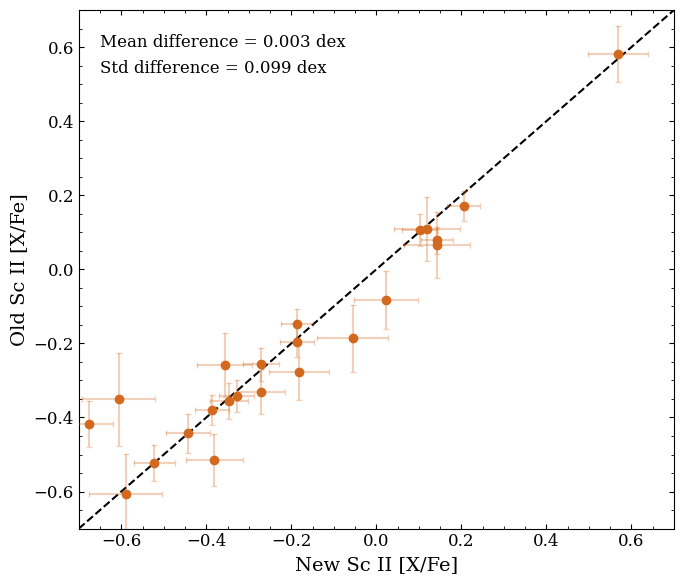

In [65]:
# Loading in the updated Sc II abundances
p113_sc_abunds = p113_data['Sc_II']
p115_sc_abunds = p115_data['Sc_II']
comb_new_sc_abunds = pd.concat([p113_sc_abunds, p115_sc_abunds], ignore_index=True)
comb_new_sc_abunds.sort_values(by='star_id', inplace=True)

# Loading in the old Sc II abundances
comb_old_sc_abunds = pd.read_csv('/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Sc_II_allabunds.csv')
comb_old_sc_abunds.sort_values(by='star_id', inplace=True)

# Combining
t = pd.merge(comb_new_sc_abunds[['star_id', 'bestfit_abund_xfe', 'bestfit_abund_comberr_xfe']], comb_old_sc_abunds[['star_id', 'bestfit_abund_xfe', 'bestfit_abund_comberr_xfe']], on='star_id', suffixes=('_new', '_old'))
t['diff'] = t['bestfit_abund_xfe_new'] - t['bestfit_abund_xfe_old']


# Plotting
plt.figure(figsize=(7, 6))
plt.scatter(t['bestfit_abund_xfe_new'], t['bestfit_abund_xfe_old'], color='chocolate', label='Sc II', zorder=10)
plt.errorbar(t['bestfit_abund_xfe_new'], t['bestfit_abund_xfe_old'], xerr=t['bestfit_abund_comberr_xfe_new'], yerr=t['bestfit_abund_comberr_xfe_old'], fmt='none', ecolor='chocolate', alpha=0.3, zorder=5)
plt.plot([-0.7, 0.7], [-0.7, 0.7], color='black', linestyle='--') # 1:1 line
plt.xlim(-0.7, 0.7)
plt.ylim(-0.7, 0.7)
plt.text(-0.65, 0.6, f"Mean difference = {t['diff'].mean():.3f} dex", fontsize=12)
plt.text(-0.65, 0.53, f"Std difference = {t['diff'].std():.3f} dex", fontsize=12)
plt.xlabel('New Sc II [X/Fe]')
plt.ylabel('Old Sc II [X/Fe]')
plt.tight_layout()
plt.savefig('/data/misfit/benlowe/xshooter/p115/results/abund_comparision/old_vs_new_scII.png', dpi=300, bbox_inches='tight', transparent=False, facecolor='white')

In [60]:
t

,star_id,bestfit_abund_xfe_new,bestfit_abund_comberr_xfe_new,bestfit_abund_xfe_old,bestfit_abund_comberr_xfe_old,diff
0,ra_0103-7050_s163,-0.187066,0.040204,-0.195520,0.041435,8.454518e-03
1,ra_0103-7050_s236,-0.522277,0.048475,-0.522277,0.048475,0.000000e+00
2,ra_0752-5047_s47,0.569091,0.070476,0.580576,0.074916,-1.148580e-02
3,ra_0834-5220_s316,-0.328674,0.041503,-0.342916,0.043332,1.424166e-02
4,ra_1604-2712_s24,-0.055512,0.083888,-0.185999,0.090635,1.304873e-01
5,ra_1604-2712_s292,-0.187187,0.038161,-0.146403,0.038101,-4.078383e-02
6,ra_1624-2150_s278,0.141687,0.037849,0.077999,0.037467,6.368833e-02
7,ra_1633-2814_s130,-0.271414,0.042132,-0.256704,0.043797,-1.470985e-02
8,ra_1633-2814_s284,0.205001,0.039396,0.170902,0.039544,3.409938e-02
9,ra_1639-2632_s419,-0.589638,0.085855,-0.605485,0.106843,1.584715e-02


## [Fe/H] vs [X/Fe] plot

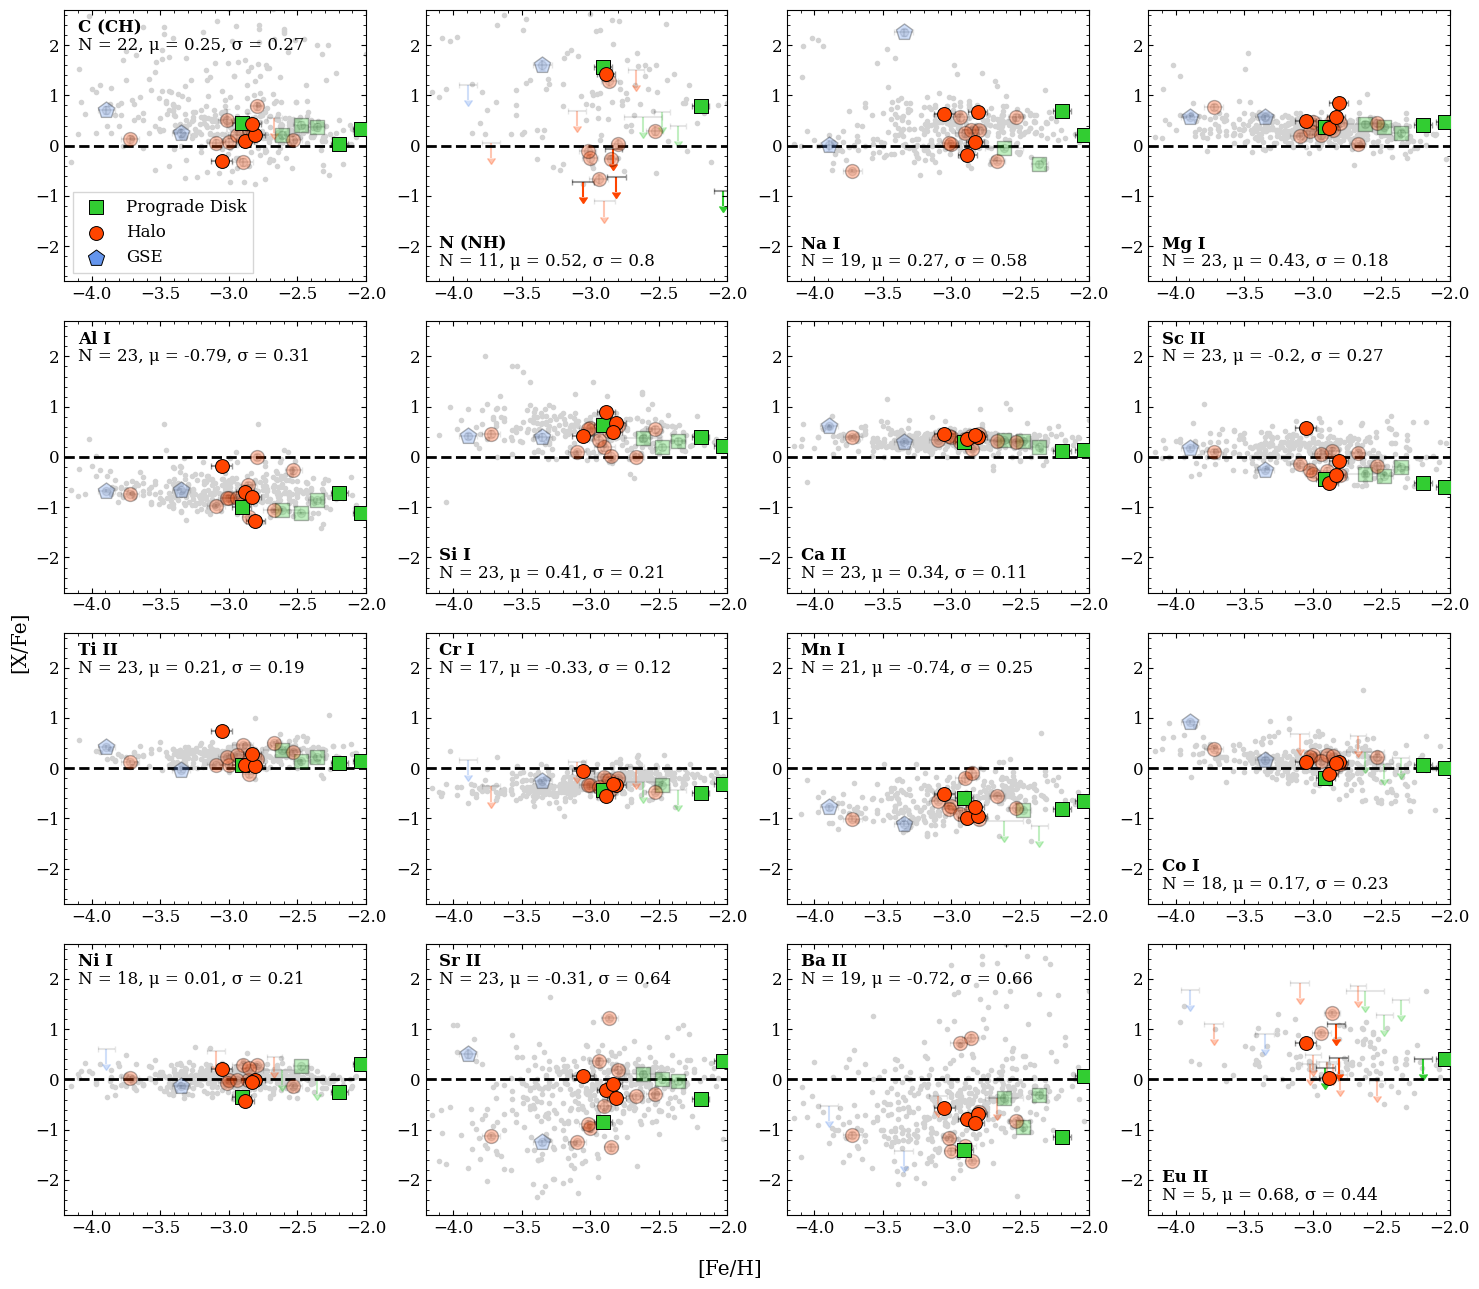

In [4]:
# Storing all abundance dataframes (both observed and literature) into lists
# NOTE: make sure that the order of the elements in el_list matches the order of the abundance dataframes in all_abunds and all_lit_abunds
el_list = ['C (CH)', 'N (NH)', 'Na I', 'Mg I', 'Al I', 'Si I', 'Ca II', 'Sc II',
           'Ti II', 'Cr I', 'Mn I', 'Co I', 'Ni I', 'Sr II', 'Ba II', 'Eu II']
# all_abunds = [c_I_abunds, n_I_abunds, na_I_abunds, mg_I_abunds, al_I_abunds, si_I_abunds, ca_II_abunds, sc_II_abunds,
#             ti_II_abunds, cr_I_abunds, mn_I_abunds, co_I_abunds, ni_I_abunds, sr_II_abunds, ba_II_abunds, eu_II_abunds]
all_p113_abunds = [p113_data['C_I'], p113_data['N_I'], p113_data['Na_I'], p113_data['Mg_I'], p113_data['Al_I'], p113_data['Si_I'], p113_data['Ca_II'], p113_data['Sc_II'],
                  p113_data['Ti_II'], p113_data['Cr_I'], p113_data['Mn_I'], p113_data['Co_I'], p113_data['Ni_I'], 
                  p113_data['Sr_II'], p113_data['Ba_II'], p113_data['Eu_II']]
all_p115_abunds = [p115_data['C_I'], p115_data['N_I'], p115_data['Na_I'], p115_data['Mg_I'], p115_data['Al_I'], p115_data['Si_I'], p115_data['Ca_II'], p115_data['Sc_II'],
                  p115_data['Ti_II'], p115_data['Cr_I'], p115_data['Mn_I'], p115_data['Co_I'], p115_data['Ni_I'], 
                  p115_data['Sr_II'], p115_data['Ba_II'], p115_data['Eu_II']]

all_lit_abunds = [cI_lit_abund, nI_lit_abund, naI_lit_abund, mgI_lit_abund, alI_lit_abund, siI_lit_abund, caI_lit_abund,
                  scII_lit_abund, tiII_lit_abund, crI_lit_abund, mnI_lit_abund, coI_lit_abund, niI_lit_abund, 
                  srII_lit_abund, baII_lit_abund, euII_lit_abund]
# all_feh = pd.read_csv('/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter9/stellar_params.csv')


fig, axs = plt.subplots(4, 4, figsize=[15,13], tight_layout=True)
fig.subplots_adjust(wspace=0.25)
fig.supxlabel('[Fe/H]')
fig.supylabel('[X/Fe]')


for ax, el in zip(axs.flat, el_list):

    # Getting index of element
    el_index = el_list.index(el)
    
    # Getting the abundance data for the element
    # P113 data
    abund_p113_df = all_p113_abunds[el_index]
    
    abund_p113_detect = abund_p113_df[abund_p113_df['detection'] == 'Y']
    abund_p113_detect_prodisk = abund_p113_detect[abund_p113_detect['orbit'] == 'pro_disk']
    abund_p113_detect_halo = abund_p113_detect[abund_p113_detect['orbit'] == 'halo']
    abund_p113_detect_gse = abund_p113_detect[abund_p113_detect['orbit'] == 'gse']
    
    abund_p113_nondetect = abund_p113_df[abund_p113_df['detection'] == 'N']
    abund_p113_nondetect_prodisk = abund_p113_nondetect[abund_p113_nondetect['orbit'] == 'pro_disk']
    abund_p113_nondetect_halo = abund_p113_nondetect[abund_p113_nondetect['orbit'] == 'halo']
    abund_p113_nondetect_gse = abund_p113_nondetect[abund_p113_nondetect['orbit'] == 'gse']
    
    # P115 data
    abund_p115_df = all_p115_abunds[el_index]
    
    # If element is C, apply evolutionary corrections
    if el == 'C (CH)':
        abund_p115_df['bestfit_abund_xfe'] = abund_p115_df['bestfit_abund_xfe'] + abund_p115_df['cfe_corr']
    
    abund_p115_detect = abund_p115_df[abund_p115_df['detection'] == 'Y']
    abund_p115_detect_prodisk = abund_p115_detect[abund_p115_detect['orbit'] == 'pro_disk']
    abund_p115_detect_halo = abund_p115_detect[abund_p115_detect['orbit'] == 'halo']
    abund_p115_detect_gse = abund_p115_detect[abund_p115_detect['orbit'] == 'gse']
    
    abund_p115_nondetect = abund_p115_df[abund_p115_df['detection'] == 'N']
    abund_p115_nondetect_prodisk = abund_p115_nondetect[abund_p115_nondetect['orbit'] == 'pro_disk']
    abund_p115_nondetect_halo = abund_p115_nondetect[abund_p115_nondetect['orbit'] == 'halo']
    abund_p115_nondetect_gse = abund_p115_nondetect[abund_p115_nondetect['orbit'] == 'gse']
    
    
    # Getting the literature data for the element
    lit_abund_df = all_lit_abunds[el_index]
    
    
    # ---PLOTTING--- #
    # Plotting literature data
    ax.scatter(lit_abund_df['feh'], lit_abund_df['abund'], c="lightgrey", marker='.', zorder=1)
    
    
    # P113 data
    alpha_p113 = 0.3
    alpha_p113_err = 0.1
    # alpha_p113 = 1
    # alpha_p113_err = 0.4
    
    # Plotting observed data (detections)
    ax.scatter(abund_p113_detect_prodisk['feh'], abund_p113_detect_prodisk['bestfit_abund_xfe'], color='limegreen', 
               marker='s', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=alpha_p113)
    ax.errorbar(abund_p113_detect_prodisk['feh'], abund_p113_detect_prodisk['bestfit_abund_xfe'], xerr=abund_p113_detect_prodisk['feh_err'],
               yerr=abund_p113_detect_prodisk['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=1, alpha=alpha_p113_err)
    ax.scatter(abund_p113_detect_halo['feh'], abund_p113_detect_halo['bestfit_abund_xfe'], color='orangered', 
               marker='o', s=100, edgecolor='black', zorder=10, linewidths=1, alpha=alpha_p113)
    ax.errorbar(abund_p113_detect_halo['feh'], abund_p113_detect_halo['bestfit_abund_xfe'], xerr=abund_p113_detect_halo['feh_err'],
               yerr=abund_p113_detect_halo['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=1, alpha=alpha_p113_err)
    ax.scatter(abund_p113_detect_gse['feh'], abund_p113_detect_gse['bestfit_abund_xfe'], color='cornflowerblue', 
               marker='p', s=150, edgecolor='black', zorder=10, linewidths=1, alpha=alpha_p113)
    ax.errorbar(abund_p113_detect_gse['feh'], abund_p113_detect_gse['bestfit_abund_xfe'], xerr=abund_p113_detect_gse['feh_err'],
               yerr=abund_p113_detect_gse['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=1, alpha=alpha_p113_err)
    
    # Plotting observed data (non-detections)
    xerr = 0.1
    ul_ysize = 0.3

    ax.errorbar(abund_p113_nondetect_prodisk['feh'], abund_p113_nondetect_prodisk['upper_limit_xfe'], yerr=ul_ysize, 
                uplims=True, fmt='none', capsize=0, zorder=1, color='limegreen', alpha=alpha_p113)
    ax.errorbar(abund_p113_nondetect_prodisk['feh'], abund_p113_nondetect_prodisk['upper_limit_xfe'], 
                xerr=abund_p113_nondetect_prodisk['feh_err'], fmt='none', color='black', zorder=1, alpha=alpha_p113_err)
    ax.errorbar(abund_p113_nondetect_halo['feh'], abund_p113_nondetect_halo['upper_limit_xfe'], yerr=ul_ysize, 
                uplims=True, fmt='none', capsize=0, zorder=1, color='orangered', alpha=alpha_p113)
    ax.errorbar(abund_p113_nondetect_halo['feh'], abund_p113_nondetect_halo['upper_limit_xfe'], 
                xerr=abund_p113_nondetect_halo['feh_err'], fmt='none', color='black', zorder=1, alpha=alpha_p113_err)
    ax.errorbar(abund_p113_nondetect_gse['feh'], abund_p113_nondetect_gse['upper_limit_xfe'], yerr=ul_ysize, 
                uplims=True, fmt='none', capsize=0, zorder=1, color='cornflowerblue', alpha=alpha_p113)
    ax.errorbar(abund_p113_nondetect_gse['feh'], abund_p113_nondetect_gse['upper_limit_xfe'], 
                xerr=abund_p113_nondetect_gse['feh_err'], fmt='none', color='black', zorder=1, alpha=alpha_p113_err)
    
    
    # P115 data
    alpha_p115 = 1
    alpha_p115_err = 0.4
    
    # Plotting observed data (detections)
    ax.scatter(abund_p115_detect_prodisk['feh'], abund_p115_detect_prodisk['bestfit_abund_xfe'], color='limegreen', 
               marker='s', s=100, edgecolor='black', zorder=10, linewidths=0.7, alpha=alpha_p115, label='Prograde Disk')
    ax.errorbar(abund_p115_detect_prodisk['feh'], abund_p115_detect_prodisk['bestfit_abund_xfe'], xerr=abund_p115_detect_prodisk['feh_err'],
               yerr=abund_p115_detect_prodisk['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=1, alpha=alpha_p115_err)
    ax.scatter(abund_p115_detect_halo['feh'], abund_p115_detect_halo['bestfit_abund_xfe'], color='orangered', 
               marker='o', s=100, edgecolor='black', zorder=10, linewidths=0.7, alpha=alpha_p115, label='Halo')
    ax.errorbar(abund_p115_detect_halo['feh'], abund_p115_detect_halo['bestfit_abund_xfe'], xerr=abund_p115_detect_halo['feh_err'],
               yerr=abund_p115_detect_halo['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=1, alpha=alpha_p115_err)
    ax.scatter(abund_p115_detect_gse['feh'], abund_p115_detect_gse['bestfit_abund_xfe'], color='cornflowerblue', 
               marker='p', s=150, edgecolor='black', zorder=10, linewidths=0.7, alpha=alpha_p115, label='GSE')
    ax.errorbar(abund_p115_detect_gse['feh'], abund_p115_detect_gse['bestfit_abund_xfe'], xerr=abund_p115_detect_gse['feh_err'],
               yerr=abund_p115_detect_gse['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=1, alpha=alpha_p115_err)
    
    # Plotting observed data (non-detections)
    xerr = 0.1
    ul_ysize = 0.3
    
    ax.errorbar(abund_p115_nondetect_prodisk['feh'], abund_p115_nondetect_prodisk['upper_limit_xfe'], yerr=ul_ysize, 
                uplims=True, fmt='none', capsize=0, zorder=1, color='limegreen', alpha=alpha_p115)
    ax.errorbar(abund_p115_nondetect_prodisk['feh'], abund_p115_nondetect_prodisk['upper_limit_xfe'], 
                xerr=abund_p115_nondetect_prodisk['feh_err'], fmt='none', color='black', zorder=1, alpha=alpha_p115_err)
    ax.errorbar(abund_p115_nondetect_halo['feh'], abund_p115_nondetect_halo['upper_limit_xfe'], yerr=ul_ysize, 
                uplims=True, fmt='none', capsize=0, zorder=1, color='orangered', alpha=alpha_p115)
    ax.errorbar(abund_p115_nondetect_halo['feh'], abund_p115_nondetect_halo['upper_limit_xfe'], 
                xerr=abund_p115_nondetect_halo['feh_err'], fmt='none', color='black', zorder=1, alpha=alpha_p115_err)
    ax.errorbar(abund_p115_nondetect_gse['feh'], abund_p115_nondetect_gse['upper_limit_xfe'], yerr=ul_ysize, 
                uplims=True, fmt='none', capsize=0, zorder=1, color='cornflowerblue', alpha=alpha_p115)
    ax.errorbar(abund_p115_nondetect_gse['feh'], abund_p115_nondetect_gse['upper_limit_xfe'], 
                xerr=abund_p115_nondetect_gse['feh_err'], fmt='none', color='black', zorder=1, alpha=alpha_p115_err)


    ax.axhline(y=0, color='black', linestyle='--', linewidth=2, zorder=2)
    
    abund_comb_detect = pd.concat([abund_p113_detect, abund_p115_detect])
    if el == 'N (NH)' or el == 'Na I' or el == 'Mg I' or el == 'Si I' or el == 'Ca II' or el == 'Co I' or el == 'Eu II':
        ax.text(-4.1, -2.05, el, fontsize=12, fontweight='bold')
        ax.text(-4.1, -2.4, f"N = {len(abund_comb_detect)}, μ = {round(np.mean(abund_comb_detect['bestfit_abund_xfe']), 2)}, σ = {round(np.std(abund_comb_detect['bestfit_abund_xfe']), 2)}", fontsize=12)
    else:
        ax.text(-4.1, 2.25, el, fontsize=12, fontweight='bold')
        ax.text(-4.1, 1.9, f"N = {len(abund_comb_detect)}, μ = {round(np.mean(abund_comb_detect['bestfit_abund_xfe']), 2)}, σ = {round(np.std(abund_comb_detect['bestfit_abund_xfe']), 2)}", fontsize=12)

    
    ax.set_xlim(-4.2, -2.0)
    ax.set_ylim(-2.7, 2.7)
    
    # Putting the legend in the first subplot
    if el_index == 0:
        ax.legend(fancybox=False, loc='lower left')
    

plt.tight_layout()
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/fe_xfe_updated_v5.pdf", dpi=300, transparent=False, facecolor="white")
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/fe_xfe_updated_v5.png", dpi=300, transparent=False, facecolor="white")



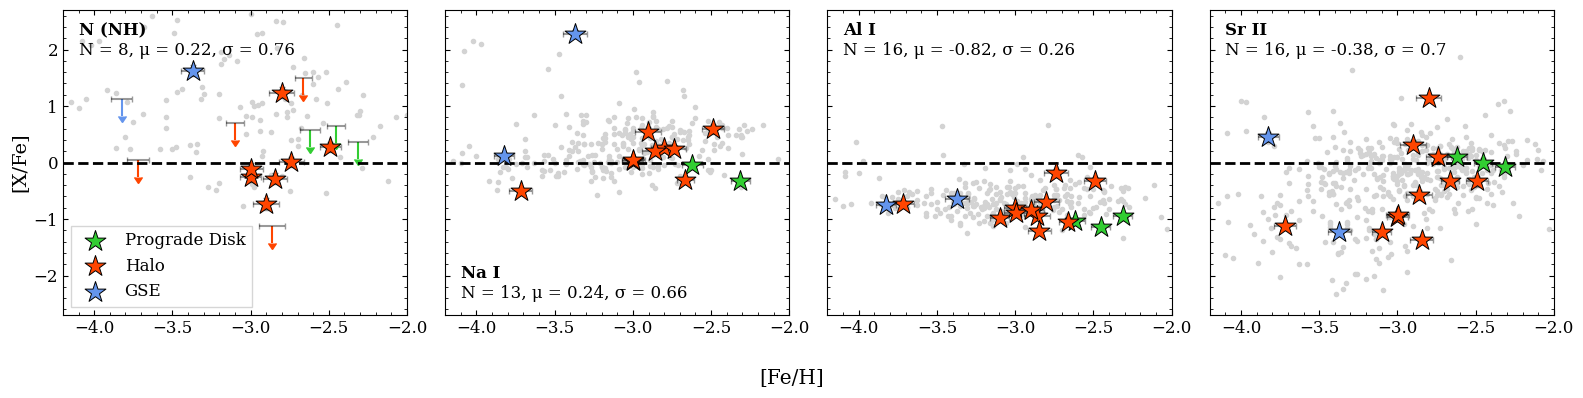

In [39]:
# Storing all abundance dataframes (both observed and literature) into lists
# NOTE: make sure that the order of the elements in el_list matches the order of the abundance dataframes in all_abunds and all_lit_abunds
el_list = ['N (NH)', 'Na I', 'Al I', 'Sr II']
all_abunds = [n_I_abunds, na_I_abunds, al_I_abunds, sr_II_abunds]
all_lit_abunds = [nI_lit_abund, naI_lit_abund, alI_lit_abund, srII_lit_abund]
all_feh = pd.read_csv('/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter/stellar_params.csv')


fig, axs = plt.subplots(1, 4, figsize=[16,4], tight_layout=True, sharey=True)
# fig.subplots_adjust(wspace=0.25)
fig.supxlabel('[Fe/H]')


for ax, el in zip(axs.flat, el_list):

    # Getting index of element
    el_index = el_list.index(el)
    
    # Getting the abundance data for the element
    abund_df = all_abunds[el_index]
    
    abund_detect = abund_df[abund_df['detection'] == 'Y']
    abund_detect_prodisk = abund_detect[abund_detect['orbit'] == 'pro_disk']
    abund_detect_halo = abund_detect[abund_detect['orbit'] == 'halo']
    abund_detect_gse = abund_detect[abund_detect['orbit'] == 'gse']
    
    abund_nondetect = abund_df[abund_df['detection'] == 'N']
    abund_nondetect_prodisk = abund_nondetect[abund_nondetect['orbit'] == 'pro_disk']
    abund_nondetect_halo = abund_nondetect[abund_nondetect['orbit'] == 'halo']
    abund_nondetect_gse = abund_nondetect[abund_nondetect['orbit'] == 'gse']
    
    # Getting the literature data for the element
    lit_abund_df = all_lit_abunds[el_index]
    
    
    # ---PLOTTING--- #
    # Plotting literature data
    ax.scatter(lit_abund_df['feh'], lit_abund_df['abund'], c="lightgrey", marker='.', zorder=1)
    
    # Plotting observed data (detections)
    ax.scatter(abund_detect_prodisk['feh'], abund_detect_prodisk['bestfit_abund_xfe'], color='limegreen', label='Prograde Disk', 
               marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
    ax.errorbar(abund_detect_prodisk['feh'], abund_detect_prodisk['bestfit_abund_xfe'], xerr=abund_detect_prodisk['feh_err'],
               yerr=abund_detect_prodisk['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=1, alpha=0.4)
    ax.scatter(abund_detect_halo['feh'], abund_detect_halo['bestfit_abund_xfe'], color='orangered', label='Halo', 
               marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
    ax.errorbar(abund_detect_halo['feh'], abund_detect_halo['bestfit_abund_xfe'], xerr=abund_detect_halo['feh_err'],
               yerr=abund_detect_halo['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=1, alpha=0.4)
    ax.scatter(abund_detect_gse['feh'], abund_detect_gse['bestfit_abund_xfe'], color='cornflowerblue', label='GSE', 
               marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
    ax.errorbar(abund_detect_gse['feh'], abund_detect_gse['bestfit_abund_xfe'], xerr=abund_detect_gse['feh_err'],
               yerr=abund_detect_gse['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=1, alpha=0.4)
    
    # Plotting observed data (non-detections)
    xerr = 0.1
    ul_ysize = 0.3

    # ax.scatter(abund_nondetect_prodisk['feh'] - 0.05, abund_nondetect_prodisk['upper_limit_xfe'] - 0.05, color='limegreen', zorder=5, 
    #            marker='${↧}$', s=250, linewidths=0.1, edgecolor='black')
    ax.errorbar(abund_nondetect_prodisk['feh'], abund_nondetect_prodisk['upper_limit_xfe'], yerr=ul_ysize, 
                uplims=True, fmt='none', capsize=0, zorder=1, color='limegreen')
    ax.errorbar(abund_nondetect_prodisk['feh'], abund_nondetect_prodisk['upper_limit_xfe'], 
                xerr=abund_nondetect_prodisk['feh_err'], fmt='none', color='black', zorder=1, alpha=0.4)
    # ax.scatter(abund_nondetect_halo['feh'] - 0.05, abund_nondetect_halo['upper_limit_xfe'] - 0.05, color='orangered', zorder=5, 
    #            marker='${↧}$', s=250, linewidths=0.1, edgecolor='black')
    ax.errorbar(abund_nondetect_halo['feh'], abund_nondetect_halo['upper_limit_xfe'], yerr=ul_ysize, 
                uplims=True, fmt='none', capsize=0, zorder=1, color='orangered')
    ax.errorbar(abund_nondetect_halo['feh'], abund_nondetect_halo['upper_limit_xfe'], 
                xerr=abund_nondetect_halo['feh_err'], fmt='none', color='black', zorder=1, alpha=0.4)
    # ax.scatter(abund_nondetect_gse['feh'] - 0.05, abund_nondetect_gse['upper_limit_xfe'] - 0.05, color='cornflowerblue', zorder=5, 
    #            marker='${↧}$', s=250, linewidths=0.1, edgecolor='black')
    ax.errorbar(abund_nondetect_gse['feh'], abund_nondetect_gse['upper_limit_xfe'], yerr=ul_ysize, 
                uplims=True, fmt='none', capsize=0, zorder=1, color='cornflowerblue')
    ax.errorbar(abund_nondetect_gse['feh'], abund_nondetect_gse['upper_limit_xfe'], 
                xerr=abund_nondetect_gse['feh_err'], fmt='none', color='black', zorder=1, alpha=0.4)
    
    

    ax.axhline(y=0, color='black', linestyle='--', linewidth=2, zorder=2)
    
    if el == 'Na I' or el == 'Mg I' or el == 'Si I' or el == 'Ca II' or el == 'Co I' or el == 'Eu II':
        ax.text(-4.1, -2.05, el, fontsize=12, fontweight='bold')
        ax.text(-4.1, -2.4, f"N = {len(abund_detect)}, μ = {round(np.mean(abund_detect['bestfit_abund_xfe']), 2)}, σ = {round(np.std(abund_detect['bestfit_abund_xfe']), 2)}", fontsize=12)
    else:
        ax.text(-4.1, 2.25, el, fontsize=12, fontweight='bold')
        ax.text(-4.1, 1.9, f"N = {len(abund_detect)}, μ = {round(np.mean(abund_detect['bestfit_abund_xfe']), 2)}, σ = {round(np.std(abund_detect['bestfit_abund_xfe']), 2)}", fontsize=12)

    
    ax.set_xlim(-4.2, -2.0)
    ax.set_ylim(-2.7, 2.7)
    
    # # Putting the legend in the first subplot
    if el_index == 0:
        ax.legend(fancybox=False, loc='lower left')
        ax.set_ylabel('[X/Fe]')
    

plt.tight_layout()
plt.savefig("/data/misfit/benlowe/xshooter/p113/results/abund_comparision/fe_xfe_reduced.pdf", dpi=300, transparent=False, facecolor="white")
plt.savefig("/data/misfit/benlowe/xshooter/p113/results/abund_comparision/fe_xfe_reduced.png", dpi=300, transparent=False, facecolor="white")



Making [Al/Fe] vs [Sc/Fe] plot 

In [5]:
# Loading in the P113 data for Al and Sc
p113_al = p113_data['Al_I']
p113_sc = p113_data['Sc_II']

p113_al_prodisk = p113_al[p113_al['orbit'] == 'pro_disk']
p113_al_halo = p113_al[p113_al['orbit'] == 'halo']
p113_al_gse = p113_al[p113_al['orbit'] == 'gse']
p113_sc_prodisk = p113_sc[p113_sc['orbit'] == 'pro_disk']
p113_sc_halo = p113_sc[p113_sc['orbit'] == 'halo']
p113_sc_gse = p113_sc[p113_sc['orbit'] == 'gse']


# Loading in the P115 data for Al and Sc
p115_al = p115_data['Al_I']
p115_sc = p115_data['Sc_II']

p115_al_prodisk = p115_al[p115_al['orbit'] == 'pro_disk']
p115_al_halo = p115_al[p115_al['orbit'] == 'halo']
p115_al_gse = p115_al[p115_al['orbit'] == 'gse']
p115_sc_prodisk = p115_sc[p115_sc['orbit'] == 'pro_disk']
p115_sc_halo = p115_sc[p115_sc['orbit'] == 'halo']
p115_sc_gse = p115_sc[p115_sc['orbit'] == 'gse']


# Combining the P113 and P115 data for Al and Sc
comb_al_prodisk = pd.concat([p113_al_prodisk, p115_al_prodisk])
comb_al_halo = pd.concat([p113_al_halo, p115_al_halo])
comb_al_gse = pd.concat([p113_al_gse, p115_al_gse])
comb_sc_prodisk = pd.concat([p113_sc_prodisk, p115_sc_prodisk])
comb_sc_halo = pd.concat([p113_sc_halo, p115_sc_halo])
comb_sc_gse = pd.concat([p113_sc_gse, p115_sc_gse])


# Loading in the literature data for Al and Sc
alI_lit = alI_lit_abund
scII_lit = scII_lit_abund
comb_lit = pd.merge(alI_lit, scII_lit, on=['star_id', 'feh'], how='outer', suffixes=('_al', '_sc'))

In [60]:
comb_lit.dropna(inplace=True)
comb_lit

,star_id,feh,abund_al,abund_sc
10,b'53327-2044-515',-4.09,-0.16,-0.07
11,b'53327-2044-515',-4.00,-0.19,0.32
13,b'54142-2667-094',-2.96,-0.72,0.30
14,b'BD +03 740',-2.70,-0.83,0.37
15,b'BD +17 3248',-2.17,-0.63,0.69
...,...,...,...,...
491,b'SMSS J202659.41-031149.2',-2.94,-0.54,0.41
498,b'SMSS J212113.63-005132.2',-2.75,-0.40,0.02
501,b'SMSS J220514.10-013407.6',-2.07,-0.96,0.29
502,b'SMSS J220535.05-004403.6',-3.10,-0.67,0.34


In [7]:
# Fitting polynomials to the data for Al and Sc in each orbit
p_progradedisk = np.polyfit(comb_al_prodisk['bestfit_abund_xfe'], comb_sc_prodisk['bestfit_abund_xfe'], 1)
fit_progradedisk = np.poly1d(p_progradedisk)
xline_progradedisk = np.linspace(-1.4, 0.1, 100)
yline_progradedisk = fit_progradedisk(xline_progradedisk)
res_progradedisk = comb_sc_prodisk['bestfit_abund_xfe'] - fit_progradedisk(comb_al_prodisk['bestfit_abund_xfe'])
std_progradedisk = np.std(res_progradedisk)

p_halo = np.polyfit(comb_al_halo['bestfit_abund_xfe'], comb_sc_halo['bestfit_abund_xfe'], 1)
fit_halo = np.poly1d(p_halo)
xline_halo = np.linspace(-1.4, 0.1, 100)
yline_halo = fit_halo(xline_halo)
res_halo = comb_sc_halo['bestfit_abund_xfe'] - fit_halo(comb_al_halo['bestfit_abund_xfe'])
std_halo = np.std(res_halo)

p_gse = np.polyfit(comb_al_gse['bestfit_abund_xfe'], comb_sc_gse['bestfit_abund_xfe'], 1)
fit_gse = np.poly1d(p_gse)
xline_gse = np.linspace(-1.4, 0.1, 100)
yline_gse = fit_gse(xline_gse)
res_gse = comb_sc_gse['bestfit_abund_xfe'] - fit_gse(comb_al_gse['bestfit_abund_xfe'])
std_gse = np.std(res_gse)

# Fitting a polynomial to the literature data for Al and Sc
p_lit = np.polyfit(comb_lit['abund_al'], comb_lit['abund_sc'], 1)
fit_lit = np.poly1d(p_lit)
xline_lit = np.linspace(-1.4, 0.1, 100)
yline_lit = fit_lit(xline_lit)
res_lit = comb_lit['abund_sc'] - fit_lit(comb_lit['abund_al'])
std_lit = np.std(res_lit)

 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  5 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value


LinAlgError: SVD did not converge in Linear Least Squares

In [51]:
print(std_halo)
print(std_progradedisk)

0.3082596867388235
0.15691967061601986


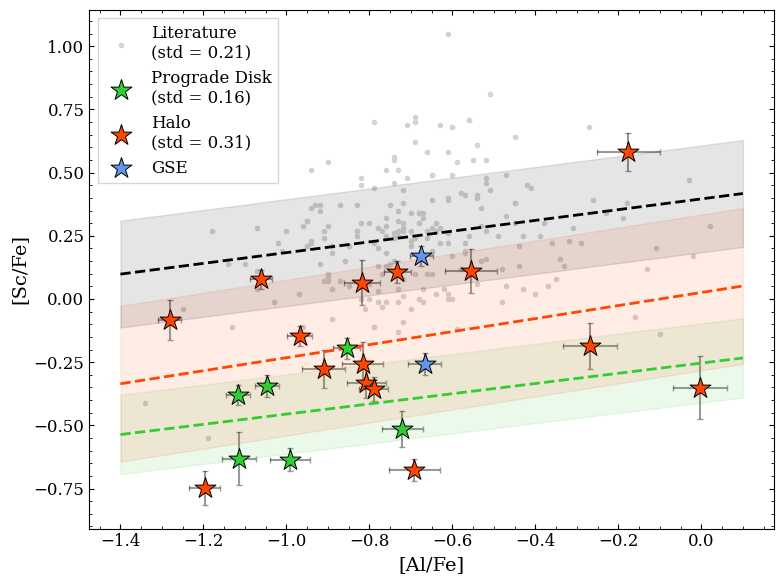

In [80]:
plt.figure(figsize=[8,6])
plt.scatter(comb_lit['abund_al'], comb_lit['abund_sc'], color='lightgrey', marker='.', zorder=1, label=f'Literature\n(std = {str(round(std_lit, 2))})') # 

# Plotting the P113 data
plt.scatter(p113_al_prodisk['bestfit_abund_xfe'], p113_sc_prodisk['bestfit_abund_xfe'], color='limegreen', label=f'Prograde Disk\n(std = {str(round(std_progradedisk, 2))})', # 
           marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(p113_al_prodisk['bestfit_abund_xfe'], p113_sc_prodisk['bestfit_abund_xfe'], xerr=p113_al_prodisk['bestfit_abund_comberr_xfe'], yerr=p113_sc_prodisk['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=1, alpha=0.4)
plt.scatter(p113_al_halo['bestfit_abund_xfe'], p113_sc_halo['bestfit_abund_xfe'], color='orangered', label=f'Halo\n(std = {str(round(std_halo, 2))})', # Halo
           marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(p113_al_halo['bestfit_abund_xfe'], p113_sc_halo['bestfit_abund_xfe'], xerr=p113_al_halo['bestfit_abund_comberr_xfe'], yerr=p113_sc_halo['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=1, alpha=0.4)
plt.scatter(p113_al_gse['bestfit_abund_xfe'], p113_sc_gse['bestfit_abund_xfe'], color='cornflowerblue', label='GSE', 
           marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(p113_al_gse['bestfit_abund_xfe'], p113_sc_gse['bestfit_abund_xfe'], xerr=p113_al_gse['bestfit_abund_comberr_xfe'], yerr=p113_sc_gse['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=1, alpha=0.4)


# Plotting the P115 data
plt.scatter(p115_al_prodisk['bestfit_abund_xfe'], p115_sc_prodisk['bestfit_abund_xfe'], color='limegreen', 
           marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(p115_al_prodisk['bestfit_abund_xfe'], p115_sc_prodisk['bestfit_abund_xfe'], xerr=p115_al_prodisk['bestfit_abund_comberr_xfe'], yerr=p115_sc_prodisk['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=1, alpha=0.4)
plt.scatter(p115_al_halo['bestfit_abund_xfe'], p115_sc_halo['bestfit_abund_xfe'], color='orangered', 
           marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(p115_al_halo['bestfit_abund_xfe'], p115_sc_halo['bestfit_abund_xfe'], xerr=p115_al_halo['bestfit_abund_comberr_xfe'], yerr=p115_sc_halo['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=1, alpha=0.4)
plt.scatter(p115_al_gse['bestfit_abund_xfe'], p115_sc_gse['bestfit_abund_xfe'], color='cornflowerblue', 
           marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(p115_al_gse['bestfit_abund_xfe'], p115_sc_gse['bestfit_abund_xfe'], xerr=p115_al_gse['bestfit_abund_comberr_xfe'], yerr=p115_sc_gse['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=1, alpha=0.4) 


# Plotting the fitted lines
plt.plot(xline_progradedisk, yline_progradedisk, color='limegreen', linestyle='--', linewidth=2)
plt.fill_between(xline_progradedisk, 
                     yline_progradedisk - std_progradedisk, 
                     yline_progradedisk + std_progradedisk, 
                     color='limegreen', 
                     alpha=0.1)

plt.plot(xline_halo, yline_halo, color='orangered', linestyle='--', linewidth=2)
plt.fill_between(xline_halo, 
                     yline_halo - std_halo, 
                     yline_halo + std_halo, 
                     color='orangered', 
                     alpha=0.1)

plt.plot(xline_lit, yline_lit, color='black', linestyle='--', linewidth=2)
plt.fill_between(xline_lit, 
                     yline_lit - std_lit, 
                     yline_lit + std_lit, 
                     color='black', 
                     alpha=0.1)
                     

plt.legend(fancybox=False, loc='upper left')
plt.xlabel('[Al/Fe]')
plt.ylabel('[Sc/Fe]')
plt.tight_layout()
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/star_abunds/al_sc_plot_4.png", dpi=300, transparent=False, facecolor="white")

## Looking at individual element scatter

### N-enhanced stars

In [8]:
# Doing this for our stars
print("The following are N-enhanced:")
prodisk_list = []
halo_list = []
gse_list = []
all_list = []

for entry in c_I_abunds.iterrows():
    if entry[1]['detection'] == 'Y':
        star_id = entry[1]['star_id']
        nfe_entry = n_I_abunds[n_I_abunds['star_id'] == star_id]
        orb = entry[1]['orbit']
        if nfe_entry['detection'].values[0] == 'Y':
            
            # Getting raw [C/Fe] value by subtracting off the C correction
            cfe_vals = entry[1]['bestfit_abund_xfe']
            cfe_corr = entry[1]['cfe_corr']
            cfe_vals -= cfe_corr
            
            cfe_errs = entry[1]['bestfit_abund_comberr_xfe']
            nfe_vals = n_I_abunds[n_I_abunds['star_id'] == star_id]['bestfit_abund_xfe'].values[0]
            nfe_errs = n_I_abunds[n_I_abunds['star_id'] == star_id]['bestfit_abund_comberr_xfe'].values[0]
            feh_vals = entry[1]['feh']
            
            cn_vals = cfe_vals - nfe_vals
            cn_errs = np.sqrt(cfe_errs**2 + nfe_errs**2)
            
            if orb == 'pro_disk':
                prodisk_dict = {'star_id': star_id, 'detection': 'Y', 'cfe': cfe_vals, 'cfe_err': cfe_errs, 'nfe': nfe_vals, 'nfe_err': nfe_errs, 
                                'cn': cn_vals, 'cn_err': cn_errs, 'feh': feh_vals}
                prodisk_list.append(prodisk_dict)
            elif orb == 'halo':
                halo_dict = {'star_id': star_id, 'detection': 'Y', 'cfe': cfe_vals, 'cfe_err': cfe_errs, 'nfe': nfe_vals, 'nfe_err': nfe_errs, 
                                'cn': cn_vals, 'cn_err': cn_errs, 'feh': feh_vals}
                halo_list.append(halo_dict)
            elif orb == 'gse':
                gse_dict = {'star_id': star_id, 'detection': 'Y', 'cfe': cfe_vals, 'cfe_err': cfe_errs, 'nfe': nfe_vals, 'nfe_err': nfe_errs, 
                                'cn': cn_vals, 'cn_err': cn_errs, 'feh': feh_vals}
                gse_list.append(gse_dict)
            
            all_list.append({'star_id': star_id, 'detection': 'Y', 'cfe': cfe_vals, 'cfe_err': cfe_errs, 'nfe': nfe_vals, 'nfe_err': nfe_errs, 
                                'cn': cn_vals, 'cn_err': cn_errs, 'feh': feh_vals})
            
            if nfe_vals > 0.5 and cn_vals < -0.7:
                print(f"{star_id} ([N/Fe] = {nfe_vals:.2f} and [C/N] = {cn_vals:.2f})")

        if nfe_entry['detection'].values[0] == 'N':
            
            # Getting raw [C/Fe] value by subtracting off the C correction
            cfe_vals = entry[1]['bestfit_abund_xfe']
            cfe_corr = entry[1]['cfe_corr']
            cfe_vals -= cfe_corr
            
            cfe_errs = entry[1]['bestfit_abund_comberr_xfe']
            nfe_vals = n_I_abunds[n_I_abunds['star_id'] == star_id]['upper_limit_xfe'].values[0]
            nfe_errs = np.nan
            feh_vals = entry[1]['feh']
            
            cn_vals = cfe_vals - nfe_vals
            cn_errs = np.nan
            
            if orb == 'pro_disk':
                prodisk_dict = {'star_id': star_id, 'detection': 'N', 'cfe': cfe_vals, 'cfe_err': cfe_errs, 'nfe': nfe_vals, 'nfe_err': nfe_errs, 
                                'cn': cn_vals, 'cn_err': cn_errs, 'feh': feh_vals}
                prodisk_list.append(prodisk_dict)
            elif orb == 'halo':
                halo_dict = {'star_id': star_id, 'detection': 'N', 'cfe': cfe_vals, 'cfe_err': cfe_errs, 'nfe': nfe_vals, 'nfe_err': nfe_errs, 
                                'cn': cn_vals, 'cn_err': cn_errs, 'feh': feh_vals}
                halo_list.append(halo_dict)
            elif orb == 'gse':
                gse_dict = {'star_id': star_id, 'detection': 'N', 'cfe': cfe_vals, 'cfe_err': cfe_errs, 'nfe': nfe_vals, 'nfe_err': nfe_errs, 
                                'cn': cn_vals, 'cn_err': cn_errs, 'feh': feh_vals}
                gse_list.append(gse_dict)
            
            all_list.append({'star_id': star_id, 'detection': 'N', 'cfe': cfe_vals, 'cfe_err': cfe_errs, 'nfe': nfe_vals, 'nfe_err': nfe_errs, 
                                'cn': cn_vals, 'cn_err': cn_errs, 'feh': feh_vals})

                
                
prodisk_df = pd.DataFrame(prodisk_list)
halo_df = pd.DataFrame(halo_list)
gse_df = pd.DataFrame(gse_list)
all_df = pd.DataFrame(all_list)

# Separating the non-detections from the detections
prodisk_detect_df = prodisk_df[prodisk_df['detection'] == 'Y']
gse_detect_df = gse_df[gse_df['detection'] == 'Y']
halo_detect_df = halo_df[halo_df['detection'] == 'Y']

prodisk_nondetect_df = prodisk_df[prodisk_df['detection'] == 'N']
gse_nondetect_df = gse_df[gse_df['detection'] == 'N']
halo_nondetect_df = halo_df[halo_df['detection'] == 'N']

# Doing this for literature stars
nfe_lit_abund = nI_lit_abund['abund'].to_numpy()
cfe_lit_abund = cI_lit_abund['abund'].to_numpy()
cn_lit_abund = cfe_lit_abund - nfe_lit_abund

The following are N-enhanced:
ra_1633-2814_s130 ([N/Fe] = 1.60 and [C/N] = -1.37)
ra_1656-1433_s143 ([N/Fe] = 1.28 and [C/N] = -1.32)


In [83]:
gse_nondetect_df

,star_id,detection,cfe,nfe,nfe_err,cn,cn_err,feh
1,ra_1633-2814_s284,N,0.645599,1.11,NaN,-0.464401,NaN,-3.824624


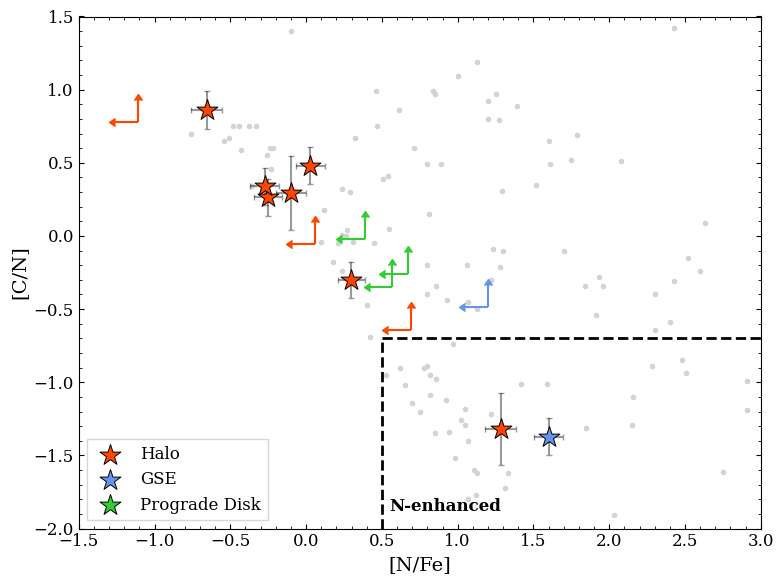

In [16]:
plt.figure(figsize=[8,6])
# plt.scatter(prodisk_df['nfe'], prodisk_df['cn'], color='limegreen', label='Prograde Disk', 
#             marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
# plt.errorbar(prodisk_df['nfe'], prodisk_df['cn'], xerr=prodisk_df['nfe_err'],
#              yerr=prodisk_df['cn_err'], fmt='o', color='black', zorder=9, alpha=0.4)
plt.scatter(halo_detect_df['nfe'], halo_detect_df['cn'], color='orangered', label='Halo', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(halo_detect_df['nfe'], halo_detect_df['cn'], xerr=halo_detect_df['nfe_err'],
             yerr=halo_detect_df['cn_err'], fmt='o', color='black', zorder=9, alpha=0.4)
plt.scatter(gse_detect_df['nfe'], gse_detect_df['cn'], color='cornflowerblue', label='GSE', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(gse_detect_df['nfe'], gse_detect_df['cn'], xerr=gse_detect_df['nfe_err'],
             yerr=gse_detect_df['cn_err'], fmt='o', color='black', zorder=9, alpha=0.4)
plt.scatter(nfe_lit_abund, cn_lit_abund, color='lightgrey', marker='.', zorder=1)
plt.hlines(y=-0.7, xmin=0.5, xmax=10, color='black', linestyle='--', linewidth=2)
plt.vlines(x=0.5, ymax = -0.7, ymin=-2, color='black', linestyle='--', linewidth=2)

# We have no prograde disk stars with detection (but need it for legend) so plotting point outside limits
plt.scatter(100, 100, color='limegreen', label='Prograde Disk', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)


# For upper-limits in [N/Fe] and lower-limits in [C/N]: plot left-facing arrow for [N/Fe] upper-limit, and up-facing arrow for [C/N] lower-limit
ul_ysize = 0.15
ul_xsize = 0.15

plt.errorbar(halo_nondetect_df['nfe'], halo_nondetect_df['cn'], xerr=ul_xsize, yerr=ul_ysize,
            xuplims=True, lolims=True, fmt='none', capsize=0, zorder=1, color='orangered')
plt.errorbar(prodisk_nondetect_df['nfe'], prodisk_nondetect_df['cn'], xerr=ul_xsize, yerr=ul_ysize,
            xuplims=True, lolims=True, fmt='none', capsize=0, zorder=1, color='limegreen')
plt.errorbar(gse_nondetect_df['nfe'], gse_nondetect_df['cn'], xerr=ul_xsize, yerr=ul_ysize,
            xuplims=True, lolims=True, fmt='none', capsize=0, zorder=1, color='cornflowerblue')

# plt.errorbar(prodisk_nondetect_df['nfe'], prodisk_nondetect_df['cn'], yerr=ul_ysize, xerr=ul_xsize,
#             uplims=True, lolims=True, fmt='none', capsize=3.5, zorder=1, color='limegreen')


# plt.scatter(halo_nondetect_df['nfe'], halo_nondetect_df['cn'], color='black', zorder=50, marker='.')
# plt.scatter(halo_nondetect_df['nfe'], halo_nondetect_df['cn'], color='orangered', zorder=5, 
#             marker='${↥}$', s=250, linewidths=0.1, edgecolor='black')
# plt.scatter(halo_nondetect_df['nfe'], halo_nondetect_df['cn'], color='orangered', zorder=7, 
#             marker='${↤}$', s=250, linewidths=0.1, edgecolor='black')
# plt.scatter(prodisk_nondetect_df['nfe'], prodisk_nondetect_df['cn'], color='black', zorder=50, marker='.')
# plt.scatter(prodisk_nondetect_df['nfe'], prodisk_nondetect_df['cn'], color='limegreen', zorder=5, 
#             marker='${↥}$', s=250, linewidths=0.1, edgecolor='black')
# plt.scatter(prodisk_nondetect_df['nfe'], prodisk_nondetect_df['cn'], color='limegreen', zorder=7, 
#             marker='${↤}$', s=250, linewidths=0.1, edgecolor='black')


# rectangle = plt.Rectangle((0.5, -0.7), 4, -2, facecolor='grey', alpha=0.1, zorder=-10)
# plt.gca().add_patch(rectangle)
plt.text(0.55, -1.85, 'N-enhanced', fontsize=12, color='black', ha='left', va='center', weight='bold')
plt.xlabel('[N/Fe]')
plt.ylabel('[C/N]')
plt.xlim(-1.5, 3)
plt.ylim(-2, 1.5)
plt.legend(fancybox=False)

plt.tight_layout()
plt.savefig("/data/misfit/benlowe/xshooter/p113/results/star_abunds/c_n_enhanced_v8.pdf", dpi=300, transparent=False, facecolor="white")
plt.savefig("/data/misfit/benlowe/xshooter/p113/results/star_abunds/c_n_enhanced_v8.png", dpi=300, transparent=False, facecolor="white")

In [16]:
all_df

,star_id,detection,cfe,nfe,nfe_err,cn,cn_err,feh,orbit
0,ra_0103-7050_s163,N,0.299635,0.360000,NaN,-0.060365,NaN,-2.312521,pro_disk
1,ra_0834-5220_s316,N,0.226344,0.570000,NaN,-0.343656,NaN,-2.618883,pro_disk
2,ra_1604-2712_s24,Y,-0.036311,0.268889,0.088583,-0.305199,0.118688,-2.489450,halo
3,ra_1604-2712_s292,N,0.070963,0.700000,NaN,-0.629037,NaN,-3.099768,halo
4,ra_1633-2814_s130,Y,0.249415,1.623911,0.096506,-1.374496,0.127117,-3.371030,gse
5,ra_1633-2814_s284,N,0.645599,1.120000,NaN,-0.474401,NaN,-3.824624,gse
6,ra_1648-0653_s38,N,0.396465,0.650000,NaN,-0.253535,NaN,-2.453756,pro_disk
7,ra_1656-1433_s143,Y,-0.097541,1.237497,0.103388,-1.335038,0.242582,-2.801119,halo
8,ra_1658-2454_s22,N,-0.366324,-1.130000,NaN,0.763676,NaN,-2.861141,halo
9,ra_1659-2154_s114,N,-0.010988,0.050000,NaN,-0.060988,NaN,-3.718210,halo


In [9]:
# Making table for paper
cn_tab = all_df[['star_id', 'cn', 'cn_err', 'nfe', 'nfe_err', 'detection']]

dict_list = []
for star in cn_tab.iterrows():
    
    detect = star[1]['detection']
    
    if detect == 'Y':
        cn_val = f"${star[1]['cn']:.2f} \pm {star[1]['cn_err']:.2f}$"
        nfe_val = f"${star[1]['nfe']:.2f} \pm {star[1]['nfe_err']:.2f}$"
    else:
        cn_val = f"$>{star[1]['cn']:.2f}$"
        nfe_val = f"$<{star[1]['nfe']:.2f}$"
    

    cn_dict = {'Star': star[1]['star_id'], '\XFe{N}': nfe_val, '\XY{C}{N}': cn_val}
    dict_list.append(cn_dict)
    
cn_final_tab = pd.DataFrame(dict_list)
cn_final_tab.sort_values(by='Star', inplace=True)

print(cn_final_tab.to_latex(index=False))


\begin{tabular}{lll}
\toprule
Star & \XFe{N} & \XY{C}{N} \\
\midrule
ra_0103-7050_s163 & $<0.39$ & $>-0.02$ \\
ra_0834-5220_s316 & $<0.57$ & $>-0.35$ \\
ra_1604-2712_s24 & $0.30 \pm 0.09$ & $-0.30 \pm 0.12$ \\
ra_1604-2712_s292 & $<0.69$ & $>-0.65$ \\
ra_1633-2814_s130 & $1.60 \pm 0.10$ & $-1.37 \pm 0.13$ \\
ra_1633-2814_s284 & $<1.20$ & $>-0.49$ \\
ra_1648-0653_s38 & $<0.67$ & $>-0.26$ \\
ra_1656-1433_s143 & $1.28 \pm 0.10$ & $-1.32 \pm 0.24$ \\
ra_1658-2454_s22 & $<-1.11$ & $>0.78$ \\
ra_1659-2154_s114 & $<0.06$ & $>-0.06$ \\
ra_1709-2130_s102 & $-0.25 \pm 0.09$ & $0.26 \pm 0.13$ \\
ra_1752-4300_s214 & $0.03 \pm 0.10$ & $0.48 \pm 0.13$ \\
ra_1752-4300_s269 & $-0.27 \pm 0.09$ & $0.34 \pm 0.13$ \\
ra_1752-4300_s6 & $-0.10 \pm 0.10$ & $0.29 \pm 0.25$ \\
ra_1853-3255_s45 & $-0.66 \pm 0.10$ & $0.86 \pm 0.13$ \\
\bottomrule
\end{tabular}



Making [C/Fe]_uncorr vs [N/Fe]

In [28]:
n_I_abunds[['star_id', 'bestfit_abund_xfe', 'bestfit_abund_comberr_xfe', 'detection', 'orbit']].sort_values(by='bestfit_abund_xfe', ascending=True)


,star_id,bestfit_abund_xfe,bestfit_abund_comberr_xfe,detection,orbit
6,ra_0103-7050_s163,-4.360622,0.060883,N,pro_disk
147,ra_1658-2454_s22,-4.278509,0.064921,N,halo
55,ra_1604-2712_s292,-3.390874,0.172515,N,halo
70,ra_1624-2150_s278,-3.024753,0.540493,N,halo
101,ra_1633-2814_s284,-2.981360,0.071619,N,gse
241,ra_1853-3255_s45,-0.740543,0.104853,Y,halo
209,ra_1752-4300_s269,-0.285215,0.094373,Y,halo
178,ra_1709-2130_s102,-0.251396,0.093066,Y,halo
22,ra_0834-5220_s316,-0.214311,0.077891,N,pro_disk
225,ra_1752-4300_s6,-0.111981,0.097109,Y,halo


Text(0, 0.5, '[N/Fe]')

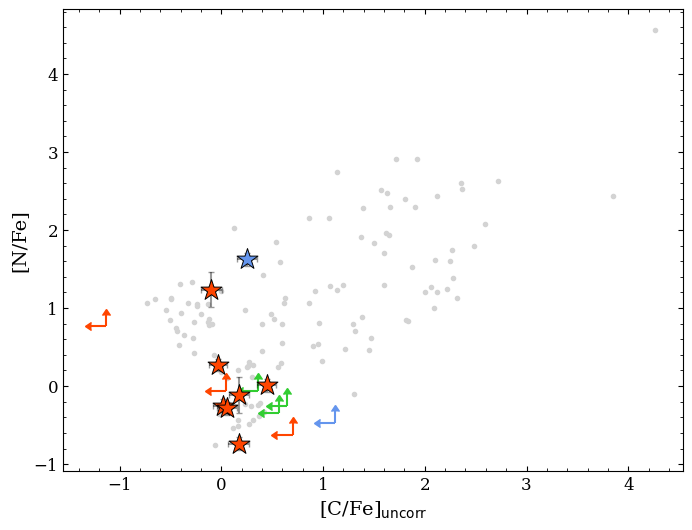

In [23]:
plt.figure(figsize=[8,6])
plt.scatter(halo_detect_df['cfe'], halo_detect_df['nfe'], color='orangered', label='Halo', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(halo_detect_df['cfe'], halo_detect_df['nfe'], xerr=halo_detect_df['nfe_err'],
             yerr=halo_detect_df['cfe_err'], fmt='o', color='black', zorder=9, alpha=0.4)
plt.scatter(gse_detect_df['cfe'], gse_detect_df['nfe'], color='cornflowerblue', label='GSE', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(gse_detect_df['cfe'], gse_detect_df['nfe'], xerr=gse_detect_df['nfe_err'],
             yerr=gse_detect_df['cfe_err'], fmt='o', color='black', zorder=9, alpha=0.4)
plt.scatter(cfe_lit_abund, nfe_lit_abund, color='lightgrey', marker='.', zorder=1)

# We have no prograde disk stars with detection (but need it for legend) so plotting point outside limits
# plt.scatter(100, 100, color='limegreen', label='Prograde Disk', 
#             marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)


# For upper-limits in [N/Fe] and lower-limits in [C/N]: plot left-facing arrow for [N/Fe] upper-limit, and up-facing arrow for [C/N] lower-limit
ul_ysize = 0.15
ul_xsize = 0.15

plt.errorbar(halo_nondetect_df['nfe'], halo_nondetect_df['cn'], xerr=ul_xsize, yerr=ul_ysize,
            xuplims=True, lolims=True, fmt='none', capsize=0, zorder=1, color='orangered')
plt.errorbar(prodisk_nondetect_df['nfe'], prodisk_nondetect_df['cn'], xerr=ul_xsize, yerr=ul_ysize,
            xuplims=True, lolims=True, fmt='none', capsize=0, zorder=1, color='limegreen')
plt.errorbar(gse_nondetect_df['nfe'], gse_nondetect_df['cn'], xerr=ul_xsize, yerr=ul_ysize,
            xuplims=True, lolims=True, fmt='none', capsize=0, zorder=1, color='cornflowerblue')

plt.xlabel(r'[C/Fe]$_{\rm uncorr}$')
plt.ylabel('[N/Fe]')

In [23]:
c_I_abunds.keys()

Index(['star_id', 'teff', 'logg', 'vmic', 'vsini', 'feh', 'feh_err', 'el',
       'detection', 'upper_limit_xfe', 'upper_limit_xh', 'bestfit_abund_xfe',
       'bestfit_abund_xh', 'bestfit_abund_comberr_xfe',
       'bestfit_abund_comberr_xh', 'bestfit_abund_tefferr_xfe',
       'bestfit_abund_tefferr_xh', 'bestfit_abund_loggerr_xfe',
       'bestfit_abund_loggerr_xh', 'bestfit_abund_vmicerr_xfe',
       'bestfit_abund_vmicerr_xh', 'Jp', 'Jtot', 'Jz', 'Jr', 'zmax', 'orbit',
       'cfe_corr'],
      dtype='object')

In [17]:
# Separating the detections from the non-detections for both C and N
# For C
c_detect = c_I_abunds[c_I_abunds['detection'] == 'Y']
c_detect_prodisk = c_detect[c_detect['orbit'] == 'pro_disk']
c_detect_halo = c_detect[c_detect['orbit'] == 'halo']
c_detect_gse = c_detect[c_detect['orbit'] == 'gse']

c_nondetect = c_I_abunds[c_I_abunds['detection'] == 'N']
c_nondetect_prodisk = c_nondetect[c_nondetect['orbit'] == 'pro_disk']
c_nondetect_halo = c_nondetect[c_nondetect['orbit'] == 'halo']
c_nondetect_gse = c_nondetect[c_nondetect['orbit'] == 'gse']

# For N
n_detect = n_I_abunds[n_I_abunds['detection'] == 'Y']
n_detect_prodisk = n_detect[n_detect['orbit'] == 'pro_disk']
n_detect_halo = n_detect[n_detect['orbit'] == 'halo']
n_detect_gse = n_detect[n_detect['orbit'] == 'gse']

n_nondetect = n_I_abunds[n_I_abunds['detection'] == 'N']
n_nondetect_prodisk = n_nondetect[n_nondetect['orbit'] == 'pro_disk']
n_nondetect_halo = n_nondetect[n_nondetect['orbit'] == 'halo']
n_nondetect_gse = n_nondetect[n_nondetect['orbit'] == 'gse']

In [18]:
cfe_nfe_list = []
for star in c_I_abunds['star_id'].to_numpy():

    # Getting the C and N abundances for the star
    star_c = c_I_abunds[c_I_abunds['star_id'] == star]
    star_c_detection = star_c['detection'].values[0]
    
    star_n = n_I_abunds[n_I_abunds['star_id'] == star]
    star_n_detection = star_n['detection'].values[0]
    
    if star_c_detection == 'Y' and star_n_detection == 'Y':
        cfe_vals = star_c['bestfit_abund_xfe'].values[0]
        cfe_corr = star_c['cfe_corr'].values[0]
        cfe_vals -= cfe_corr  # Getting raw [C/Fe] value by subtracting off the C correction
        cfe_errs = star_c['bestfit_abund_comberr_xfe'].values[0]
        nfe_vals = star_n['bestfit_abund_xfe'].values[0]
        nfe_errs = star_n['bestfit_abund_comberr_xfe'].values[0]
        detect = 'both'
        orbit = star_c['orbit'].values[0]
        
    if star_c_detection == 'Y' and star_n_detection == 'N':
        cfe_vals = star_c['bestfit_abund_xfe'].values[0]
        cfe_corr = star_c['cfe_corr'].values[0]
        cfe_vals -= cfe_corr  # Getting raw [C/Fe] value by subtracting off the C correction
        cfe_errs = star_c['bestfit_abund_comberr_xfe'].values[0]
        nfe_vals = star_n['upper_limit_xfe'].values[0]
        nfe_errs = np.nan
        detect = 'carbon'
        orbit = star_c['orbit'].values[0]
        
    if star_c_detection == 'N' and star_n_detection == 'Y':
        cfe_vals = star_c['upper_limit_xfe'].values[0]
        cfe_errs = np.nan
        nfe_vals = star_n['bestfit_abund_xfe'].values[0]
        nfe_errs = star_n['bestfit_abund_comberr_xfe'].values[0]
        detect = 'nitrongen'
        orbit = star_n['orbit'].values[0]
        
    if star_c_detection == 'N' and star_n_detection == 'N':
        cfe_vals = star_c['upper_limit_xfe'].values[0]
        cfe_errs = np.nan
        nfe_vals = star_n['upper_limit_xfe'].values[0]
        nfe_errs = np.nan
        detect = 'neither'
        orbit = star_c['orbit'].values[0]
        
    # Storing the values in a dictionary
    star_dict = {'star_id': star, 'cfe': cfe_vals, 'cfe_err': cfe_errs, 'nfe': nfe_vals, 'nfe_err': nfe_errs, 'detection': detect, 'orbit': orbit}
    cfe_nfe_list.append(star_dict)
    
cfe_nfe_df = pd.DataFrame(cfe_nfe_list)

# Separating into the different detections
cfe_nfe_both = cfe_nfe_df[cfe_nfe_df['detection'] == 'both']
cfe_nfe_carbon = cfe_nfe_df[cfe_nfe_df['detection'] == 'carbon']
cfe_nfe_nitrogen = cfe_nfe_df[cfe_nfe_df['detection'] == 'nitrongen']
cfe_nfe_neither = cfe_nfe_df[cfe_nfe_df['detection'] == 'neither']

# Separating into the different orbits
cfe_nfe_both_prodisk = cfe_nfe_both[cfe_nfe_both['orbit'] == 'pro_disk']
cfe_nfe_both_halo = cfe_nfe_both[cfe_nfe_both['orbit'] == 'halo']
cfe_nfe_both_gse = cfe_nfe_both[cfe_nfe_both['orbit'] == 'gse']

cfe_nfe_carbon_prodisk = cfe_nfe_carbon[cfe_nfe_carbon['orbit'] == 'pro_disk']
cfe_nfe_carbon_halo = cfe_nfe_carbon[cfe_nfe_carbon['orbit'] == 'halo']
cfe_nfe_carbon_gse = cfe_nfe_carbon[cfe_nfe_carbon['orbit'] == 'gse']

cfe_nfe_nitrogen_prodisk = cfe_nfe_nitrogen[cfe_nfe_nitrogen['orbit'] == 'pro_disk']
cfe_nfe_nitrogen_halo = cfe_nfe_nitrogen[cfe_nfe_nitrogen['orbit'] == 'halo']
cfe_nfe_nitrogen_gse = cfe_nfe_nitrogen[cfe_nfe_nitrogen['orbit'] == 'gse']

cfe_nfe_neither_prodisk = cfe_nfe_neither[cfe_nfe_neither['orbit'] == 'pro_disk']
cfe_nfe_neither_halo = cfe_nfe_neither[cfe_nfe_neither['orbit'] == 'halo']
cfe_nfe_neither_gse = cfe_nfe_neither[cfe_nfe_neither['orbit'] == 'gse']


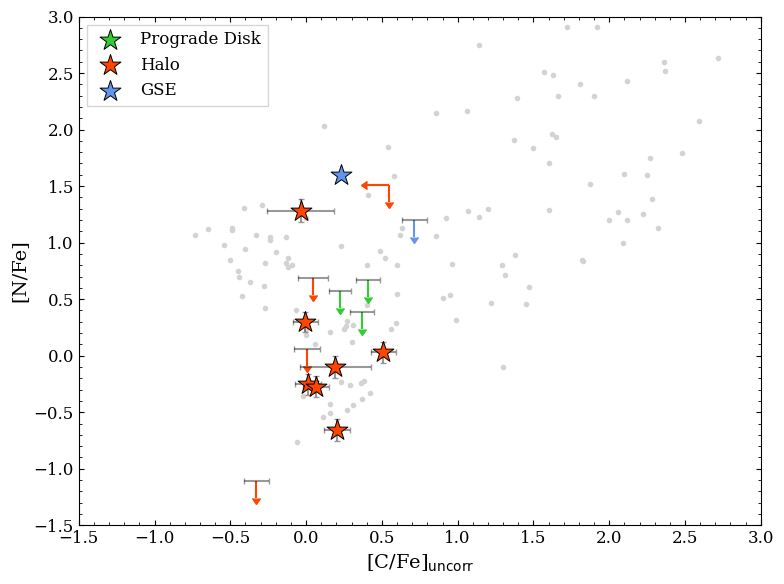

In [19]:
plt.figure(figsize=[8,6])

plt.scatter(cfe_lit_abund, nfe_lit_abund, color='lightgrey', marker='.', zorder=1)

ul_ysize = 0.15
ul_xsize = 0.15

# Plotting the stars with both C and N detections
plt.scatter(cfe_nfe_both_prodisk['cfe'], cfe_nfe_both_prodisk['nfe'], color='limegreen', label='Prograde Disk',
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(cfe_nfe_both_prodisk['cfe'], cfe_nfe_both_prodisk['nfe'], xerr=cfe_nfe_both_prodisk['cfe_err'],
             yerr=cfe_nfe_both_prodisk['nfe_err'], fmt='o', color='black', zorder=9, alpha=0.4)
plt.scatter(cfe_nfe_both_halo['cfe'], cfe_nfe_both_halo['nfe'], color='orangered', label='Halo', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(cfe_nfe_both_halo['cfe'], cfe_nfe_both_halo['nfe'], xerr=cfe_nfe_both_halo['cfe_err'],
             yerr=cfe_nfe_both_halo['nfe_err'], fmt='o', color='black', zorder=9, alpha=0.4)
plt.scatter(cfe_nfe_both_gse['cfe'], cfe_nfe_both_gse['nfe'], color='cornflowerblue', label='GSE', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)

# Plotting the stars with only C detections
plt.errorbar(cfe_nfe_carbon_prodisk['cfe'], cfe_nfe_carbon_prodisk['nfe'], yerr=ul_ysize, 
            uplims=True, fmt='none', capsize=0, zorder=1, color='limegreen')
plt.errorbar(cfe_nfe_carbon_prodisk['cfe'], cfe_nfe_carbon_prodisk['nfe'], 
            xerr=cfe_nfe_carbon_prodisk['cfe_err'], fmt='none', color='black', zorder=1, alpha=0.4)
plt.errorbar(cfe_nfe_carbon_halo['cfe'], cfe_nfe_carbon_halo['nfe'], yerr=ul_ysize, 
            uplims=True, fmt='none', capsize=0, zorder=1, color='orangered')
plt.errorbar(cfe_nfe_carbon_halo['cfe'], cfe_nfe_carbon_halo['nfe'], 
            xerr=cfe_nfe_carbon_halo['cfe_err'], fmt='none', color='black', zorder=1, alpha=0.4)
plt.errorbar(cfe_nfe_carbon_gse['cfe'], cfe_nfe_carbon_gse['nfe'], yerr=ul_ysize, 
            uplims=True, fmt='none', capsize=0, zorder=1, color='cornflowerblue')
plt.errorbar(cfe_nfe_carbon_gse['cfe'], cfe_nfe_carbon_gse['nfe'], 
            xerr=cfe_nfe_carbon_gse['cfe_err'], fmt='none', color='black', zorder=1, alpha=0.4)

# Plotting the stars with only N detections
plt.errorbar(cfe_nfe_nitrogen_prodisk['cfe'], cfe_nfe_nitrogen_prodisk['nfe'], xerr=ul_xsize, 
            xuplims=True, fmt='none', capsize=0, zorder=1, color='limegreen')
plt.errorbar(cfe_nfe_nitrogen_prodisk['cfe'], cfe_nfe_nitrogen_prodisk['nfe'], 
            yerr=cfe_nfe_nitrogen_prodisk['nfe_err'], fmt='none', color='black', zorder=1, alpha=0.4)
plt.errorbar(cfe_nfe_nitrogen_halo['cfe'], cfe_nfe_nitrogen_halo['nfe'], xerr=ul_xsize, 
            xuplims=True, fmt='none', capsize=0, zorder=1, color='orangered')
plt.errorbar(cfe_nfe_nitrogen_halo['cfe'], cfe_nfe_nitrogen_halo['nfe'], 
            yerr=cfe_nfe_nitrogen_halo['nfe_err'], fmt='none', color='black', zorder=1, alpha=0.4)
plt.errorbar(cfe_nfe_nitrogen_gse['cfe'], cfe_nfe_nitrogen_gse['nfe'], xerr=ul_xsize, 
            xuplims=True, fmt='none', capsize=0, zorder=1, color='cornflowerblue')

# Plotting the stars with neither C nor N detections
plt.errorbar(cfe_nfe_neither_prodisk['cfe'], cfe_nfe_neither_prodisk['nfe'], xerr=ul_xsize, yerr=ul_ysize,
            xuplims=True, uplims=True, fmt='none', capsize=0, zorder=1, color='limegreen')
plt.errorbar(cfe_nfe_neither_prodisk['cfe'], cfe_nfe_neither_prodisk['nfe'], 
            fmt='none', color='black', zorder=1, alpha=0.4)
plt.errorbar(cfe_nfe_neither_halo['cfe'], cfe_nfe_neither_halo['nfe'], xerr=ul_xsize, yerr=ul_ysize,
            xuplims=True, uplims=True, fmt='none', capsize=0, zorder=1, color='orangered')
plt.errorbar(cfe_nfe_neither_halo['cfe'], cfe_nfe_neither_halo['nfe'], 
            fmt='none', color='black', zorder=1, alpha=0.4)
plt.errorbar(cfe_nfe_neither_gse['cfe'], cfe_nfe_neither_gse['nfe'], xerr=ul_xsize, yerr=ul_ysize,
            xuplims=True, uplims=True, fmt='none', capsize=0, zorder=1, color='cornflowerblue')
plt.errorbar(cfe_nfe_neither_gse['cfe'], cfe_nfe_neither_gse['nfe'], fmt='none', color='black', zorder=1, alpha=0.4)

plt.xlabel(r'[C/Fe]$_{\rm uncorr}$')
plt.ylabel('[N/Fe]')
plt.xlim(-1.5, 3)
plt.ylim(-1.5, 3)
plt.legend(fancybox=False)
plt.tight_layout()

plt.savefig("/data/misfit/benlowe/xshooter/p113/results/star_abunds/cfe_vs_nfe_abund_v2.pdf", dpi=300, transparent=False, facecolor="white")
plt.savefig("/data/misfit/benlowe/xshooter/p113/results/star_abunds/cfe_vs_nfe_abund_v2.png", dpi=300, transparent=False, facecolor="white")

### r-process stars

In [7]:
# Doing this for our stars
print("The following are r-II:")
prodisk_list = []
halo_list = []
gse_list = []
all_list = []
for entry in ba_II_abunds.iterrows():
    if entry[1]['detection'] == 'Y':
        star_id = entry[1]['star_id']
        eu_II_entry = eu_II_abunds[eu_II_abunds['star_id'] == star_id]
        orb = entry[1]['orbit']
        feh_vals = entry[1]['feh']
        feh_errs = entry[1]['feh_err']

        if eu_II_entry['detection'].values[0] == 'Y':
            ba_vals = entry[1]['bestfit_abund_xfe']
            ba_errs = entry[1]['bestfit_abund_comberr_xfe']
            eu_vals = eu_II_abunds[eu_II_abunds['star_id'] == star_id]['bestfit_abund_xfe'].values[0]
            eu_errs = eu_II_abunds[eu_II_abunds['star_id'] == star_id]['bestfit_abund_comberr_xfe'].values[0]
            
            baeu_vals = ba_vals - eu_vals
            baeu_errs = np.sqrt(ba_errs**2 + eu_errs**2)
            
            if orb == 'pro_disk':
                prodisk_dict = {'star_id': star_id, 'eufe': eu_vals, 'eufe_err': eu_errs, 'bafe': ba_vals, 'bafe_err': ba_errs,
                                'baeu': baeu_vals, 'baeu_err': baeu_errs, 'feh': feh_vals, 'feh_err': feh_errs, 'ul': 'N'}
                prodisk_list.append(prodisk_dict)
            elif orb == 'halo':
                halo_dict = {'star_id': star_id, 'eufe': eu_vals, 'eufe_err': eu_errs, 'bafe': ba_vals, 'bafe_err': ba_errs,
                                'baeu': baeu_vals, 'baeu_err': baeu_errs, 'feh': feh_vals, 'feh_err': feh_errs, 'ul': 'N'}
                halo_list.append(halo_dict)
            elif orb == 'gse':
                gse_dict = {'star_id': star_id, 'eufe': eu_vals, 'eufe_err': eu_errs, 'bafe': ba_vals, 'bafe_err': ba_errs,
                                'baeu': baeu_vals, 'baeu_err': baeu_errs, 'feh': feh_vals, 'feh_err': feh_errs, 'ul': 'N'}
                gse_list.append(gse_dict)
                
            all_list.append({'star_id': star_id, 'eufe': eu_vals, 'eufe_err': eu_errs, 'bafe': ba_vals, 'bafe_err': ba_errs,
                                'baeu': baeu_vals, 'baeu_err': baeu_errs, 'feh': feh_vals, 'feh_err': feh_errs, 'ul': 'N'})


            
            if eu_vals > 1.0 and baeu_vals < 0:
                print(f"{star_id} ([Eu/Fe] = {eu_vals:.2f} ± {eu_errs:.2f} and [Ba/Eu] = {baeu_vals:.2f} ± {baeu_errs:.2f})")
                
        else:
            eu_ul = eu_II_abunds[eu_II_abunds['star_id'] == star_id]['upper_limit_xfe'].values[0]
            
            if orb == 'pro_disk':
                prodisk_dict = {'star_id': star_id, 'eufe_ul': eu_ul, 'feh': feh_vals, 'feh_err': feh_errs, 'ul': 'Y'}
                prodisk_list.append(prodisk_dict)
            elif orb == 'halo':
                halo_dict = {'star_id': star_id, 'eufe_ul': eu_ul, 'feh': feh_vals, 'feh_err': feh_errs, 'ul': 'Y'}
                halo_list.append(halo_dict)
            elif orb == 'gse':
                gse_dict = {'star_id': star_id, 'eufe_ul': eu_ul, 'feh': feh_vals, 'feh_err': feh_errs, 'ul': 'Y'}
                gse_list.append(gse_dict)
                
        


            
                
prodisk_df = pd.DataFrame(prodisk_list)
halo_df = pd.DataFrame(halo_list)
gse_df = pd.DataFrame(gse_list)
                
print()
print("The following are r-I:")
for entry in ba_II_abunds.iterrows():
    if entry[1]['detection'] == 'Y':
        star_id = entry[1]['star_id']
        eu_II_entry = eu_II_abunds[eu_II_abunds['star_id'] == star_id]
        if eu_II_entry['detection'].values[0] == 'Y':
            ba_vals = entry[1]['bestfit_abund_xfe']
            ba_errs = entry[1]['bestfit_abund_comberr_xfe']
            eu_vals = eu_II_abunds[eu_II_abunds['star_id'] == star_id]['bestfit_abund_xfe'].values[0]
            eu_errs = eu_II_abunds[eu_II_abunds['star_id'] == star_id]['bestfit_abund_comberr_xfe'].values[0]
            
            baeu_vals = ba_vals - eu_vals
            baeu_errs = np.sqrt(ba_errs**2 + eu_errs**2)
            
            if eu_vals >= 0.3 and eu_vals <= 1.0 and baeu_vals < 0:
                print(f"{star_id} ([Eu/Fe] = {eu_vals:.2f} ± {eu_errs:.2f} and [Ba/Eu] = {baeu_vals:.2f} ± {baeu_errs:.2f})")
        # cfe_vals = entry[1]['bestfit_abund_xfe']
        # nfe_vals = n_I_abunds[n_I_abunds['star_id'] == star_id]['bestfit_abund_xfe'].values[0]
        
        # cn_vals = cfe_vals - nfe_vals
        
        # if nfe_vals > 0.5 and cn_vals < -0.7:
        #     print(f"{star_id} ([N/Fe] = {nfe_vals:.2f} and [C/N] = {cn_vals:.2f})")
        
        
# Doing this for literature stars
euII_list_stars = euII_lit_abund['star_id'].to_numpy()

bafe_lit_abund = baII_lit_abund[baII_lit_abund['star_id'].isin(euII_list_stars)]['abund'].to_numpy()
eufe_lit_abund = euII_lit_abund['abund'].to_numpy()
baeu_lit_abund = bafe_lit_abund - eufe_lit_abund

The following are r-II:
ra_1656-1433_s143 ([Eu/Fe] = 1.32 ± 0.03 and [Ba/Eu] = -0.49 ± 0.08)

The following are r-I:
ra_1853-3255_s45 ([Eu/Fe] = 0.92 ± 0.04 and [Ba/Eu] = -0.18 ± 0.05)


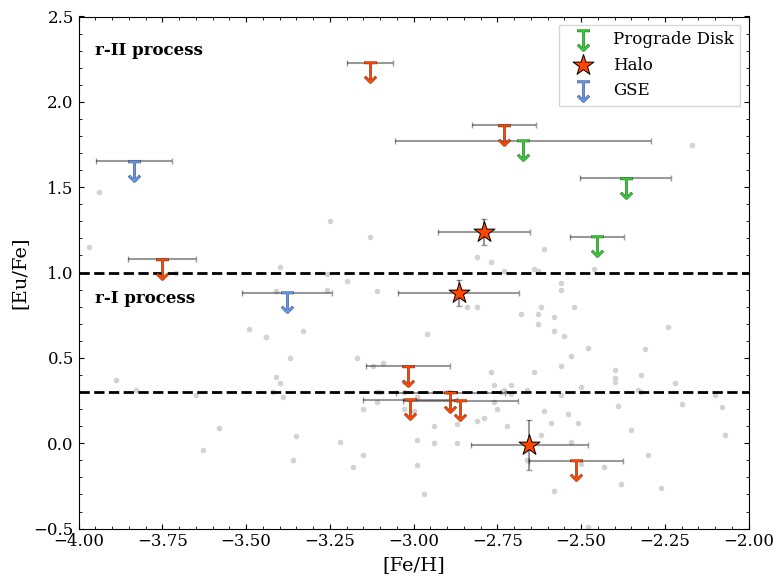

In [ ]:
plt.figure(figsize=(8, 6))

for pro_entry in prodisk_df.iterrows():
    if pro_entry[1]['ul'] == 'Y':
        leg_pro = plt.scatter(pro_entry[1]['feh'] - 0.05, pro_entry[1]['eufe_ul'] - 0.055, color='limegreen', marker='${↧}$', s=250, 
                    linewidths=0.2, edgecolor='black', label='Prograde Disk', zorder=3)
        plt.errorbar(pro_entry[1]['feh'] - 0.05, pro_entry[1]['eufe_ul'], 
            xerr=pro_entry[1]['feh_err'], fmt='none', color='black', zorder=2, alpha=0.4)    
    else:
        plt.scatter(pro_entry[1]['feh'], pro_entry[1]['eufe'], color='limegreen', label='Prograde Disk', 
                    marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
        plt.errorbar(pro_entry[1]['feh'], pro_entry[1]['eufe'], xerr=pro_entry[1]['feh_err'],
                     yerr=pro_entry[1]['eufe_err'], fmt='o', color='black', zorder=9, alpha=0.4)
  
  
for halo_entry in halo_df.iterrows():
    if halo_entry[1]['ul'] == 'Y':
        plt.scatter(halo_entry[1]['feh'] - 0.05, halo_entry[1]['eufe_ul'] - 0.055, color='orangered', marker='${↧}$', s=250, 
                    linewidths=0.2, edgecolor='black', label='Halo', zorder=3)
        plt.errorbar(halo_entry[1]['feh'] - 0.05, halo_entry[1]['eufe_ul'], 
            xerr=halo_entry[1]['feh_err'], fmt='none', color='black', zorder=2, alpha=0.4)    
    else:
        leg_hal = plt.scatter(halo_entry[1]['feh'], halo_entry[1]['eufe'], color='orangered', label='Halo', 
                    marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
        plt.errorbar(halo_entry[1]['feh'], halo_entry[1]['eufe'], xerr=halo_entry[1]['feh_err'],
                     yerr=halo_entry[1]['eufe_err'], fmt='o', color='black', zorder=9, alpha=0.4)
        
        
for gse_entry in gse_df.iterrows():
    if gse_entry[1]['ul'] == 'Y':
        leg_gse = plt.scatter(gse_entry[1]['feh'] - 0.05, gse_entry[1]['eufe_ul'] - 0.055, color='cornflowerblue', marker='${↧}$', s=250, 
                    linewidths=0.2, edgecolor='black', label='GSE', zorder=3)
        plt.errorbar(gse_entry[1]['feh'] - 0.05, gse_entry[1]['eufe_ul'], 
            xerr=gse_entry[1]['feh_err'], fmt='none', color='black', zorder=2, alpha=0.4)    
    else:
        plt.scatter(gse_entry[1]['feh'], gse_entry[1]['eufe'], color='cornflowerblue', label='GSE', 
                    marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
        plt.errorbar(gse_entry[1]['feh'], gse_entry[1]['eufe'], xerr=gse_entry[1]['feh_err'],
                     yerr=gse_entry[1]['eufe_err'], fmt='o', color='black', zorder=9, alpha=0.4)     
# plt.scatter(halo_df['feh'], halo_df['eufe'], color='orangered', label='Halo', 
#             marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
# plt.errorbar(halo_df['feh'], halo_df['eufe'], xerr=halo_df['feh_err'],
#              yerr=halo_df['eufe_err'], fmt='o', color='black', zorder=9, alpha=0.4)
plt.scatter(euII_lit_abund['feh'], euII_lit_abund['abund'], color='lightgrey', marker='.', zorder=1)

plt.hlines(y=0.3, xmin=-4, xmax=-1.0, color='black', linestyle='--', linewidth=2)
plt.hlines(y=1, xmin=-4, xmax=-1.0, color='black', linestyle='--', linewidth=2)

plt.text(-3.95, 0.85, 'r-I process', fontsize=12, color='black', ha='left', va='center', weight='bold')
plt.text(-3.95, 2.3, 'r-II process', fontsize=12, color='black', ha='left', va='center', weight='bold')

plt.legend(fancybox=False, handles = [leg_pro, leg_hal, leg_gse])
plt.xlim(-4, -2.0)
plt.ylim(-0.5, 2.5)
plt.xlabel('[Fe/H]')
plt.ylabel('[Eu/Fe]')

plt.tight_layout()
plt.savefig("/data/misfit/benlowe/xshooter/p113/results/star_abunds/eu_rprocess_v2.pdf", dpi=300, transparent=False, facecolor="white")
plt.savefig("/data/misfit/benlowe/xshooter/p113/results/star_abunds/eu_rprocess_v2.png", dpi=300, transparent=False, facecolor="white")

Plotting [Ba/H] vs [Sr/Ba]

In [ ]:
ba_II_abunds[ba_II_abunds['star_id'] == 'ra_1658-2454_s22']

,star_id,teff,logg,vmic,vsini,feh,feh_err,el,detection,upper_limit_xfe,...,bestfit_abund_loggerr_xfe,bestfit_abund_loggerr_xh,bestfit_abund_vmicerr_xfe,bestfit_abund_vmicerr_xh,Jp,Jtot,Jz,Jr,zmax,orbit


In [8]:
prodisk_list = []
halo_list = []
gse_list = []
all_list = []

for entry in sr_II_abunds.iterrows():
    if entry[1]['detection'] == 'Y':
        star_id = entry[1]['star_id']
        bafe_entry = ba_II_abunds[ba_II_abunds['star_id'] == star_id]
        orb = entry[1]['orbit']
        if bafe_entry['detection'].values[0] == 'Y':
            sr_vals = entry[1]['bestfit_abund_xfe']
            sr_errs = entry[1]['bestfit_abund_comberr_xfe']
            ba_vals = ba_II_abunds[ba_II_abunds['star_id'] == star_id]['bestfit_abund_xfe'].values[0]
            ba_xh_vals = ba_II_abunds[ba_II_abunds['star_id'] == star_id]['bestfit_abund_xh'].values[0]
            ba_errs = ba_II_abunds[ba_II_abunds['star_id'] == star_id]['bestfit_abund_comberr_xfe'].values[0]
            ba_xh_errs = ba_II_abunds[ba_II_abunds['star_id'] == star_id]['bestfit_abund_comberr_xh'].values[0]
            feh_vals = entry[1]['feh']
            feh_errs = entry[1]['feh_err']
            
            srba_vals = sr_vals - ba_vals
            srba_errs = np.sqrt(sr_errs**2 + ba_errs**2)
            
            eufe_entry = eu_II_abunds[eu_II_abunds['star_id'] == star_id]
            if bafe_entry['detection'].values[0] == 'Y':
                eu_vals = eu_II_abunds[eu_II_abunds['star_id'] == star_id]['bestfit_abund_xfe'].values[0]
                eu_errs = eu_II_abunds[eu_II_abunds['star_id'] == star_id]['bestfit_abund_comberr_xfe'].values[0]
                baeu_vals = ba_vals - eu_vals
                baeu_errs = np.sqrt(sr_errs**2 + eu_errs**2)
                
                print(star_id)
                print(baeu_vals, baeu_errs)
            
            all_dict = {'star_id': star_id, 'detection': 'Y', 'srfe': sr_vals, 'bafe': ba_vals, 'srfe_err': sr_errs,
                                'bafe_err': ba_errs, 'srba': srba_vals, 'srba_err': srba_errs, 'feh': feh_vals, 'feh_err': feh_errs,
                                'bah': ba_xh_vals, 'bah_err': ba_xh_errs}
            all_list.append(all_dict)
            
            if orb == 'pro_disk':
                prodisk_dict = {'star_id': star_id, 'detection': 'Y',  'srfe': sr_vals, 'bafe': ba_vals, 'srfe_err': sr_errs,
                                'bafe_err': ba_errs, 'srba': srba_vals, 'srba_err': srba_errs, 'feh': feh_vals, 'feh_err': feh_errs,
                                'bah': ba_xh_vals, 'bah_err': ba_xh_errs}
                prodisk_list.append(prodisk_dict)
            elif orb == 'halo':
                halo_dict = {'star_id': star_id, 'detection': 'Y',  'srfe': sr_vals, 'bafe': ba_vals, 'srfe_err': sr_errs,
                                'bafe_err': ba_errs, 'srba': srba_vals, 'srba_err': srba_errs, 'feh': feh_vals, 'feh_err': feh_errs,
                                'bah': ba_xh_vals, 'bah_err': ba_xh_errs}
                halo_list.append(halo_dict)
            elif orb == 'gse':
                gse_dict = {'star_id': star_id, 'detection': 'Y',  'srfe': sr_vals, 'bafe': ba_vals, 'srfe_err': sr_errs,
                                'bafe_err': ba_errs, 'srba': srba_vals, 'srba_err': srba_errs, 'feh': feh_vals, 'feh_err': feh_errs,
                                'bah': ba_xh_vals, 'bah_err': ba_xh_errs}
                gse_list.append(gse_dict)      
                
        elif bafe_entry['detection'].values[0] == 'N':
            sr_vals = entry[1]['bestfit_abund_xfe']
            sr_errs = entry[1]['bestfit_abund_comberr_xfe']
            ba_vals = ba_II_abunds[ba_II_abunds['star_id'] == star_id]['upper_limit_xfe'].values[0]
            ba_xh_vals = ba_II_abunds[ba_II_abunds['star_id'] == star_id]['upper_limit_xh'].values[0]
            ba_errs = np.nan
            ba_xh_errs = np.nan
            feh_vals = entry[1]['feh']
            feh_errs = entry[1]['feh_err']
            
            srba_vals = sr_vals - ba_vals
            srba_errs = np.nan
            
            eufe_entry = eu_II_abunds[eu_II_abunds['star_id'] == star_id]
            
            all_dict = {'star_id': star_id, 'detection': 'N', 'srfe': sr_vals, 'bafe': ba_vals, 'srfe_err': sr_errs,
                                'bafe_err': ba_errs, 'srba': srba_vals, 'srba_err': srba_errs, 'feh': feh_vals, 'feh_err': feh_errs,
                                'bah': ba_xh_vals, 'bah_err': ba_xh_errs}
            all_list.append(all_dict)
            
            if orb == 'pro_disk':
                prodisk_dict = {'star_id': star_id, 'detection': 'N', 'srfe': sr_vals, 'bafe': ba_vals, 'srfe_err': sr_errs,
                                'bafe_err': ba_errs, 'srba': srba_vals, 'srba_err': srba_errs, 'feh': feh_vals, 'feh_err': feh_errs,
                                'bah': ba_xh_vals, 'bah_err': ba_xh_errs}
                prodisk_list.append(prodisk_dict)
            elif orb == 'halo':
                halo_dict = {'star_id': star_id, 'detection': 'N', 'srfe': sr_vals, 'bafe': ba_vals, 'srfe_err': sr_errs,
                                'bafe_err': ba_errs, 'srba': srba_vals, 'srba_err': srba_errs, 'feh': feh_vals, 'feh_err': feh_errs,
                                'bah': ba_xh_vals, 'bah_err': ba_xh_errs}
                halo_list.append(halo_dict)
            elif orb == 'gse':
                gse_dict = {'star_id': star_id, 'detection': 'N', 'srfe': sr_vals, 'bafe': ba_vals, 'srfe_err': sr_errs,
                                'bafe_err': ba_errs, 'srba': srba_vals, 'srba_err': srba_errs, 'feh': feh_vals, 'feh_err': feh_errs,
                                'bah': ba_xh_vals, 'bah_err': ba_xh_errs}
                gse_list.append(gse_dict)      

                
prodisk_df = pd.DataFrame(prodisk_list)
halo_df = pd.DataFrame(halo_list)
gse_df = pd.DataFrame(gse_list)
all_df = pd.DataFrame(all_list)

# Separating the non-detections from the detections
prodisk_detect_df = prodisk_df[prodisk_df['detection'] == 'Y']
gse_detect_df = gse_df[gse_df['detection'] == 'Y']
halo_detect_df = halo_df[halo_df['detection'] == 'Y']

prodisk_nondetect_df = prodisk_df[prodisk_df['detection'] == 'N']
gse_nondetect_df = gse_df[gse_df['detection'] == 'N']
halo_nondetect_df = halo_df[halo_df['detection'] == 'N']


# Doing this for literature stars
srfe_lit_abund = srII_lit_abund['abund'].to_numpy()
bafe_lit_abund = baII_lit_abund['abund'].to_numpy()
bah_lit_abund = baII_lit_abund['abund_xh'].to_numpy()
srba_lit_abund = srfe_lit_abund - bafe_lit_abund

ra_0103-7050_s163
-0.9613192987092622 0.1113933869806802
ra_0834-5220_s316
2.3130415607279753 0.07615082674251411
ra_1604-2712_s24
2.912133610370418 0.8739424325485757
ra_1648-0653_s38
-1.6060358780583242 1.5057469366824092
ra_1656-1433_s143
-0.4904084019053243 0.04800493658272009
ra_1658-2454_s22
2.2299796700447434 0.10845616703326573
ra_1659-2154_s114
-1.7817399209652376 0.058322658802958546
ra_1709-2130_s102
-1.5342206645138665 1.2136129810353575
ra_1752-4300_s214
-0.5661414056436436 0.5765477919423332
ra_1752-4300_s269
1.940583183925319 1.7795155009240404
ra_1752-4300_s6
-0.9790399256330431 0.15101981049018537
ra_1853-3255_s45
-0.184052607230616 0.08236417102096437


In [16]:
all_df

,star_id,detection,srfe,bafe,srfe_err,bafe_err,srba,srba_err,feh,feh_err,bah,bah_err
0,ra_0103-7050_s163,Y,-0.023527,-0.315226,0.065605,0.060650,0.291698,0.089345,-2.359003,0.060794,-2.673533,0.060650
1,ra_0834-5220_s316,Y,0.104221,-0.373662,0.065485,0.118631,0.477883,0.135505,-2.616194,0.137417,-2.989086,0.118631
2,ra_1604-2712_s24,Y,-0.280932,-0.836141,0.094694,0.042585,0.555209,0.103829,-2.530153,0.060214,-3.366295,0.042585
3,ra_1604-2712_s292,N,-1.235506,-0.334684,0.040143,NaN,-0.900823,NaN,-3.095019,0.066494,-3.430750,NaN
4,ra_1624-2150_s278,N,-0.332300,-0.378058,0.051143,NaN,0.045758,NaN,-2.667603,0.058084,-3.045237,NaN
5,ra_1633-2814_s130,N,-1.254223,-1.419452,0.046118,NaN,0.165229,NaN,-3.349203,0.068693,-4.770016,NaN
6,ra_1633-2814_s284,N,0.514093,-0.522366,0.088810,NaN,1.036459,NaN,-3.893474,0.064712,-4.436362,NaN
7,ra_1648-0653_s38,Y,0.017544,-0.937188,0.083177,0.123030,0.954732,0.148508,-2.475968,0.059728,-3.413303,0.123030
8,ra_1656-1433_s143,Y,1.218352,0.831879,0.034274,0.075456,0.386473,0.082875,-2.858919,0.060508,-2.027039,0.075456
9,ra_1658-2454_s22,Y,-0.526760,-1.324868,0.096168,0.026682,0.798108,0.099801,-2.897767,0.076858,-4.222635,0.026682


In [25]:
t = all_df[['star_id', 'srba', 'srba_err']]
t

,star_id,srba,srba_err
0,ra_0103-7050_s163,0.291698,0.089345
1,ra_0834-5220_s316,0.477883,0.135505
2,ra_1604-2712_s24,0.555209,0.103829
3,ra_1604-2712_s292,-0.900823,NaN
4,ra_1624-2150_s278,0.045758,NaN
5,ra_1633-2814_s130,0.165229,NaN
6,ra_1633-2814_s284,1.036459,NaN
7,ra_1648-0653_s38,0.954732,0.148508
8,ra_1656-1433_s143,0.386473,0.082875
9,ra_1658-2454_s22,0.798108,0.099801


In [26]:
display(eu_II_abunds[eu_II_abunds['detection'] == 'Y'][['star_id', 'bestfit_abund_xfe', 'bestfit_abund_comberr_xfe']])
display(ba_II_abunds[ba_II_abunds['star_id'].isin(['ra_1656-1433_s143', 'ra_1853-3255_s45'])][['star_id', 'bestfit_abund_xfe', 'bestfit_abund_comberr_xfe']])

,star_id,bestfit_abund_xfe,bestfit_abund_comberr_xfe
135,ra_1656-1433_s143,1.285041,0.033337
247,ra_1853-3255_s45,0.889801,0.041383


,star_id,bestfit_abund_xfe,bestfit_abund_comberr_xfe
131,ra_1656-1433_s143,0.777277,0.071037
240,ra_1853-3255_s45,0.701088,0.018033


In [31]:
ra1656 = 0.78 - 1.29 
ra1656_err = np.sqrt(0.03**2 + 0.07**2)
print(ra1656, ra1656_err)

ra1858 = 0.70 - 0.89 
ra1858_err = np.sqrt(0.02**2 + 0.04**2)
print(ra1858, ra1858_err)

-0.51 0.07615773105863909
-0.19000000000000006 0.044721359549995794


In [26]:
# Making table for paper
srba_tab = all_df[['star_id', 'detection', 'bah', 'bah_err', 'srba', 'srba_err']]

dict_list = []
for star in srba_tab.iterrows():
    
    detect = star[1]['detection']
    
    if detect == 'Y':
        srba_val = f"${star[1]['srba']:.2f} \pm {star[1]['srba_err']:.2f}$"
        bah_val = f"${star[1]['bah']:.2f} \pm {star[1]['bah_err']:.2f}$"
    else:
        srba_val = f"$>{star[1]['srba']:.2f}$"
        bah_val = f"$<{star[1]['bah']:.2f}$"

    srba_dict = {'Star': star[1]['star_id'], '[Ba/H]': bah_val, '[Sr/Ba]': srba_val}
    dict_list.append(srba_dict)
    
srba_final_tab = pd.DataFrame(dict_list)
srba_final_tab.sort_values(by='Star', inplace=True)

print(srba_final_tab.to_latex(index=False))




\begin{tabular}{lll}
\toprule
Star & [Ba/H] & [Sr/Ba] \\
\midrule
ra_0103-7050_s163 & $-2.67 \pm 0.06$ & $0.29 \pm 0.09$ \\
ra_0834-5220_s316 & $-2.99 \pm 0.12$ & $0.48 \pm 0.14$ \\
ra_1604-2712_s24 & $-3.37 \pm 0.04$ & $0.56 \pm 0.10$ \\
ra_1604-2712_s292 & $<-3.43$ & $>-0.90$ \\
ra_1624-2150_s278 & $<-3.05$ & $>0.05$ \\
ra_1633-2814_s130 & $<-4.77$ & $>0.17$ \\
ra_1633-2814_s284 & $<-4.44$ & $>1.04$ \\
ra_1648-0653_s38 & $-3.41 \pm 0.12$ & $0.95 \pm 0.15$ \\
ra_1656-1433_s143 & $-2.03 \pm 0.08$ & $0.39 \pm 0.08$ \\
ra_1658-2454_s22 & $-4.22 \pm 0.03$ & $0.80 \pm 0.10$ \\
ra_1659-2154_s114 & $-4.83 \pm 0.07$ & $-0.01 \pm 0.08$ \\
ra_1709-2130_s102 & $-4.43 \pm 0.07$ & $0.47 \pm 0.10$ \\
ra_1752-4300_s214 & $-3.45 \pm 0.04$ & $0.85 \pm 0.09$ \\
ra_1752-4300_s269 & $-4.48 \pm 0.04$ & $0.27 \pm 0.08$ \\
ra_1752-4300_s6 & $-4.18 \pm 0.04$ & $0.27 \pm 0.09$ \\
ra_1853-3255_s45 & $-2.20 \pm 0.02$ & $-0.38 \pm 0.07$ \\
\bottomrule
\end{tabular}



In [ ]:
print(np.nanmean(srba_lit_abund))
print(np.nanstd(srba_lit_abund))

print(np.nanmean(all_df['srba']))
print(np.nanstd(all_df['srba']))

0.11266958212206869
0.5951734095879577
0.40365343452286245
0.38143929138569777


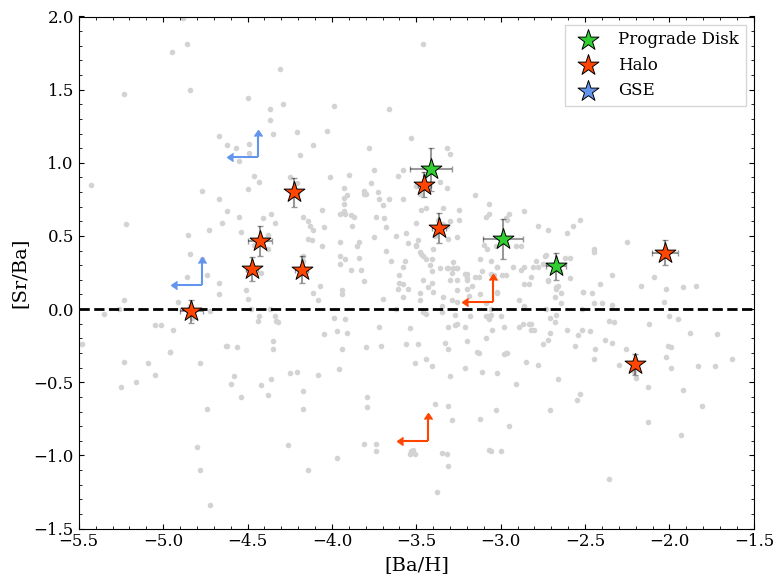

In [24]:
plt.figure(figsize=(8, 6))

# Plotting the detections and literature stars
plt.scatter(bah_lit_abund, srba_lit_abund, c="lightgrey", marker='.', zorder=1)
plt.scatter(prodisk_detect_df['bah'], prodisk_detect_df['srba'], color='limegreen', label='Prograde Disk', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(prodisk_detect_df['bah'], prodisk_detect_df['srba'], xerr=prodisk_detect_df['bah_err'],
             yerr=prodisk_detect_df['srba_err'], fmt='o', color='black', zorder=9, alpha=0.4)
plt.scatter(halo_detect_df['bah'], halo_detect_df['srba'], color='orangered', label='Halo', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(halo_detect_df['bah'], halo_detect_df['srba'], xerr=halo_detect_df['bah_err'],
             yerr=halo_detect_df['srba_err'], fmt='o', color='black', zorder=9, alpha=0.4)
# plt.scatter(gse_df['feh'], gse_df['srba'], color='cornflowerblue', label='GSE', 
#             marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
# plt.errorbar(gse_df['feh'], gse_df['srba'], xerr=gse_df['feh_err'],
#              yerr=gse_df['srba_err'], fmt='o', color='black', zorder=9, alpha=0.4)

# We have no GSE stars with detection (but need it for legend) so plotting point outside limits
plt.scatter(100, 100, color='cornflowerblue', label='GSE', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)



# Plotting those with upper-limits in [Ba/H] and lower-limits in [Sr/Ba]: plot left-facing arrow for [Ba/H] upper-limit, and up-facing arrow for [Sr/Ba] lower-limit
ul_ysize = 0.15
ul_xsize = 0.15

plt.errorbar(halo_nondetect_df['bah'], halo_nondetect_df['srba'], xerr=ul_xsize, yerr=ul_ysize,
            xuplims=True, lolims=True, fmt='none', capsize=0, zorder=1, color='orangered')
plt.errorbar(prodisk_nondetect_df['bah'], prodisk_nondetect_df['srba'], xerr=ul_xsize, yerr=ul_ysize,
            xuplims=True, lolims=True, fmt='none', capsize=0, zorder=1, color='limegreen')
plt.errorbar(gse_nondetect_df['bah'], gse_nondetect_df['srba'], xerr=ul_xsize, yerr=ul_ysize,
            xuplims=True, lolims=True, fmt='none', capsize=0, zorder=1, color='cornflowerblue')


plt.axhline(y=0, color='black', linestyle='--', linewidth=2, zorder=2)
plt.xlim(-5.5, -1.5)
plt.ylim(-1.5, 2.0)

plt.legend(fancybox=False)
plt.xlabel('[Ba/H]')
plt.ylabel('[Sr/Ba]')
plt.tight_layout()

plt.savefig("/data/misfit/benlowe/xshooter/p113/results/star_abunds/srba_plot_v5.pdf", dpi=300, transparent=False, facecolor="white")
plt.savefig("/data/misfit/benlowe/xshooter/p113/results/star_abunds/srba_plot_v5.png", dpi=300, transparent=False, facecolor="white")


### α-enhanced stars

In [22]:
# Doing this for our stars
prodisk_list = []
halo_list = []
gse_list = []
all_list = []

for entry in mg_I_abunds.iterrows():
    star_id = entry[1]['star_id']
    orb = entry[1]['orbit']
    si_I_entry = si_I_abunds[si_I_abunds['star_id'] == star_id]
    ca_II_entry = ca_II_abunds[ca_II_abunds['star_id'] == star_id]
    ti_II_entry = ti_II_abunds[ti_II_abunds['star_id'] == star_id]
    
    mg_vals = entry[1]['bestfit_abund_xfe']
    mg_errs = entry[1]['bestfit_abund_comberr_xfe']
    si_vals = si_I_entry['bestfit_abund_xfe'].values[0]
    si_errs = si_I_entry['bestfit_abund_comberr_xfe'].values[0]
    ca_vals = ca_II_entry['bestfit_abund_xfe'].values[0]
    ca_errs = ca_II_entry['bestfit_abund_comberr_xfe'].values[0]
    ti_vals = ti_II_entry['bestfit_abund_xfe'].values[0]
    ti_errs = ti_II_entry['bestfit_abund_comberr_xfe'].values[0]
    
    
    # alpha_vals = np.average([mg_vals, si_vals, ca_vals, ti_vals])
    # alpha_errs = 1/4 * np.sqrt(mg_errs**2 + si_errs**2 + ca_errs**2 + ti_errs**2)
    
    # Calculating weighted average
    alpha_arr = np.array([mg_vals, si_vals, ca_vals, ti_vals])
    alpha_weights = 1 / np.array([mg_errs, si_errs, ca_errs, ti_errs])**2
    
    # Weighted mean
    alpha_vals = np.sum(alpha_weights * alpha_arr) / np.sum(alpha_weights)

    # Uncertainty of weighted mean
    alpha_errs = np.sqrt(1 / np.sum(alpha_weights))
    
    feh_vals = entry[1]['feh']
    feh_errs = entry[1]['feh_err']
    
    all_dict = {'star_id': star_id, 'alpha': alpha_vals, 'alpha_err': alpha_errs,
                'feh': feh_vals, 'feh_err': feh_errs, 'mg': mg_vals, 'mg_err': mg_errs,
                'si': si_vals, 'si_err': si_errs, 'ca': ca_vals, 'ca_err': ca_errs, 'ti': ti_vals, 'ti_err': ti_errs}
    all_list.append(all_dict)
    
    if orb == 'pro_disk':
        prodisk_dict = {'star_id': star_id, 'alpha': alpha_vals, 'alpha_err': alpha_errs,
                        'feh': feh_vals, 'feh_err': feh_errs}
        prodisk_list.append(prodisk_dict)
    elif orb == 'halo':
        halo_dict = {'star_id': star_id, 'alpha': alpha_vals, 'alpha_err': alpha_errs,
                        'feh': feh_vals, 'feh_err': feh_errs}
        halo_list.append(halo_dict)
    elif orb == 'gse':
        gse_dict = {'star_id': star_id, 'alpha': alpha_vals, 'alpha_err': alpha_errs,
                        'feh': feh_vals, 'feh_err': feh_errs}
        gse_list.append(gse_dict)
    
    print(f"{star_id} ([α/Fe] = {alpha_vals:.2f} ± {alpha_errs:.2f})")
    # if eu_II_entry['detection'].values[0] == 'Y':
    #     ba_vals = entry[1]['bestfit_abund_xfe']
    #     eu_vals = eu_II_abunds[eu_II_abunds['star_id'] == star_id]['bestfit_abund_xfe'].values[0]
        
    #     baeu_vals = ba_vals - eu_vals
    #     if eu_vals >= 0.3 and eu_vals <= 1.0 and baeu_vals < 0:
    #         print(f"{star_id} ([Eu/Fe] = {eu_vals:.2f} and [Ba/Eu] = {baeu_vals:.2f})")

prodisk_df = pd.DataFrame(prodisk_list)
halo_df = pd.DataFrame(halo_list)
gse_df = pd.DataFrame(gse_list)
all_df = pd.DataFrame(all_list)

# Doing this for literature stars
mgI_list_stars = mgI_lit_abund['star_id'].to_numpy()
siI_list_stars = siI_lit_abund['star_id'].to_numpy()
caI_list_stars = caI_lit_abund['star_id'].to_numpy()
tiII_list_stars = tiII_lit_abund['star_id'].to_numpy()
alpha_lit_abund = []
for star in mgI_list_stars:
    if star in siI_list_stars and star in caI_list_stars and star in tiII_list_stars:
        mg_val = mgI_lit_abund[mgI_lit_abund['star_id'] == star]['abund'].values[0]
        si_val = siI_lit_abund[siI_lit_abund['star_id'] == star]['abund'].values[0]
        ca_val = caI_lit_abund[caI_lit_abund['star_id'] == star]['abund'].values[0]
        ti_val = tiII_lit_abund[tiII_lit_abund['star_id'] == star]['abund'].values[0]
        feh_val = mgI_lit_abund[mgI_lit_abund['star_id'] == star]['feh'].values[0]
        
        alpha_val = np.average([mg_val, si_val, ca_val, ti_val])
        alpha_lit_abund.append({'star_id': star, 'alpha': alpha_val, 'feh': feh_val})
        
alpha_lit_abund_df = pd.DataFrame(alpha_lit_abund)

ra_0103-7050_s163 ([α/Fe] = 0.23 ± 0.02)
ra_0834-5220_s316 ([α/Fe] = 0.36 ± 0.02)
ra_1604-2712_s24 ([α/Fe] = 0.32 ± 0.02)
ra_1604-2712_s292 ([α/Fe] = 0.24 ± 0.02)
ra_1624-2150_s278 ([α/Fe] = 0.26 ± 0.01)
ra_1633-2814_s130 ([α/Fe] = 0.32 ± 0.02)
ra_1633-2814_s284 ([α/Fe] = 0.56 ± 0.02)
ra_1648-0653_s38 ([α/Fe] = 0.28 ± 0.02)
ra_1656-1433_s143 ([α/Fe] = 0.39 ± 0.02)
ra_1658-2454_s22 ([α/Fe] = 0.38 ± 0.02)
ra_1659-2154_s114 ([α/Fe] = 0.36 ± 0.02)
ra_1709-2130_s102 ([α/Fe] = 0.37 ± 0.02)
ra_1752-4300_s214 ([α/Fe] = 0.42 ± 0.02)
ra_1752-4300_s269 ([α/Fe] = 0.15 ± 0.02)
ra_1752-4300_s6 ([α/Fe] = 0.36 ± 0.02)
ra_1853-3255_s45 ([α/Fe] = 0.28 ± 0.02)


In [23]:
print(prodisk_df['alpha'].mean(), prodisk_df['alpha'].std())
print(halo_df['alpha'].mean(), halo_df['alpha'].std())
print(gse_df['alpha'].mean(), gse_df['alpha'].std())

0.2920824418511221 0.06851579810193913
0.3204312154753493 0.08039051417780288
0.4368669316665228 0.167499740772177


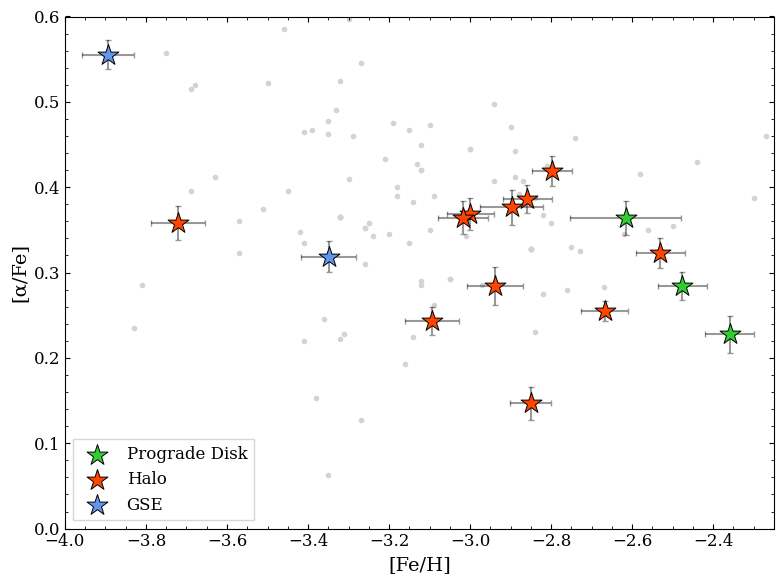

In [26]:
plt.figure(figsize=(8, 6))
plt.scatter(prodisk_df['feh'], prodisk_df['alpha'], color='limegreen', label='Prograde Disk', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(prodisk_df['feh'], prodisk_df['alpha'], xerr=prodisk_df['feh_err'],
             yerr=prodisk_df['alpha_err'], fmt='o', color='black', zorder=9, alpha=0.4)
plt.scatter(halo_df['feh'], halo_df['alpha'], color='orangered', label='Halo', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(halo_df['feh'], halo_df['alpha'], xerr=halo_df['feh_err'],
             yerr=halo_df['alpha_err'], fmt='o', color='black', zorder=9, alpha=0.4)
plt.scatter(gse_df['feh'], gse_df['alpha'], color='cornflowerblue', label='GSE', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(gse_df['feh'], gse_df['alpha'], xerr=gse_df['feh_err'],
             yerr=gse_df['alpha_err'], fmt='o', color='black', zorder=9, alpha=0.4)
plt.scatter(alpha_lit_abund_df['feh'], alpha_lit_abund_df['alpha'], color='lightgrey', marker='.', zorder=1)
# plt.axhline(y=0.15, color='black', linestyle='--', linewidth=2)
# plt.axhline(y=0.4, color='black', linestyle='--', linewidth=2)
# # plt.axvline(x=0.3, ymax=0.955, color='black', linestyle='--', linewidth=2)
# # plt.axvline(x=1.0, ymax=0.955, color='black', linestyle='--', linewidth=2)

# # rectangle = plt.Rectangle((-4.0, 0.15), 1.8, -0.15, facecolor='grey', alpha=0.1, zorder=-10)
# # plt.gca().add_patch(rectangle)
# plt.text(-3.97, 0.13, 'α-poor', fontsize=12, color='black', ha='left', va='center', weight='bold')

# # rectangle = plt.Rectangle((-4.0, 0.4), 1.8, -0.25, facecolor='grey', alpha=0.1, zorder=-10)
# # plt.gca().add_patch(rectangle)
# plt.text(-3.97, 0.38, 'α-normal', fontsize=12, color='black', ha='left', va='center', weight='bold')

# # rectangle = plt.Rectangle((-4.0, 0.4), 1.8, 0.2, facecolor='grey', alpha=0.2, zorder=-10)
# # plt.gca().add_patch(rectangle)
# plt.text(-3.97, 0.58, 'α-rich', fontsize=12, color='black', ha='left', va='center', weight='bold')

plt.xlabel('[Fe/H]')
plt.ylabel('[α/Fe]')
plt.legend(fancybox=False, loc='lower left')

plt.xlim(-4, -2.25)
plt.ylim(0, 0.6)

plt.tight_layout()
plt.savefig("/data/misfit/benlowe/xshooter/p113/results/star_abunds/alpha_enhanced_v8.pdf", dpi=300, transparent=False, facecolor="white")
plt.savefig("/data/misfit/benlowe/xshooter/p113/results/star_abunds/alpha_enhanced_v8.png", dpi=300, transparent=False, facecolor="white")

In [11]:
# Making table for paper
alpha_tab = all_df[['star_id', 'feh', 'feh_err', 'alpha', 'alpha_err']]

dict_list = []
for star in alpha_tab.iterrows():
    
    alpha_val = f"${star[1]['alpha']:.2f} \pm {star[1]['alpha_err']:.2f}$"
    feh_val = f"${star[1]['feh']:.2f} \pm {star[1]['feh_err']:.2f}$"

    alpha_dict = {'Star': star[1]['star_id'], '[Fe/H]': feh_val, '[Alpha/Fe]': alpha_val}
    dict_list.append(alpha_dict)
    
alpha_final_tab = pd.DataFrame(dict_list)
alpha_final_tab.sort_values(by='Star', inplace=True)

print(alpha_final_tab.to_latex(index=False))


\begin{tabular}{lll}
\toprule
Star & [Fe/H] & [Alpha/Fe] \\
\midrule
ra_0103-7050_s163 & $-2.36 \pm 0.06$ & $0.23 \pm 0.02$ \\
ra_0834-5220_s316 & $-2.62 \pm 0.14$ & $0.36 \pm 0.02$ \\
ra_1604-2712_s24 & $-2.53 \pm 0.06$ & $0.32 \pm 0.02$ \\
ra_1604-2712_s292 & $-3.10 \pm 0.07$ & $0.24 \pm 0.02$ \\
ra_1624-2150_s278 & $-2.67 \pm 0.06$ & $0.26 \pm 0.01$ \\
ra_1633-2814_s130 & $-3.35 \pm 0.07$ & $0.32 \pm 0.02$ \\
ra_1633-2814_s284 & $-3.89 \pm 0.06$ & $0.56 \pm 0.02$ \\
ra_1648-0653_s38 & $-2.48 \pm 0.06$ & $0.28 \pm 0.02$ \\
ra_1656-1433_s143 & $-2.86 \pm 0.06$ & $0.39 \pm 0.02$ \\
ra_1658-2454_s22 & $-2.90 \pm 0.08$ & $0.38 \pm 0.02$ \\
ra_1659-2154_s114 & $-3.72 \pm 0.07$ & $0.36 \pm 0.02$ \\
ra_1709-2130_s102 & $-3.00 \pm 0.06$ & $0.37 \pm 0.02$ \\
ra_1752-4300_s214 & $-2.80 \pm 0.05$ & $0.42 \pm 0.02$ \\
ra_1752-4300_s269 & $-2.85 \pm 0.05$ & $0.15 \pm 0.02$ \\
ra_1752-4300_s6 & $-3.02 \pm 0.06$ & $0.36 \pm 0.02$ \\
ra_1853-3255_s45 & $-2.94 \pm 0.07$ & $0.28 \pm 0.02$ \\
\bottomru

### C-enhanced stars

In [27]:
prodisk_list = []
halo_list = []
gse_list = []

prodisk_ul_list = []
halo_ul_list = []
gse_ul_list = []

c_corrs_df = pd.read_csv('/data/misfit/benlowe/xshooter/p113/C_evolve_corrections/cfe_corrections.csv')

for entry in c_I_abunds.iterrows():
    orb = entry[1]['orbit']
    if entry[1]['detection'] == 'Y':
        star_id = entry[1]['star_id']
        feh_vals = entry[1]['feh']
        feh_errs = entry[1]['feh_err']
        
        c_vals = entry[1]['bestfit_abund_xfe']
        c_errs = entry[1]['bestfit_abund_comberr_xfe']
        
        c_corr = c_corrs_df[c_corrs_df['star_id'] == star_id]['cfe_corr'].values[0]
        c_orig = c_vals - c_corr
        
        if orb == 'pro_disk':
            prodisk_dict = {'star_id': star_id, 'cfe': c_vals, 'cfe_err': c_errs, 'cfe_uncorr': c_orig,
                            'feh': feh_vals, 'feh_err': feh_errs}
            prodisk_list.append(prodisk_dict)
        elif orb == 'halo':
            halo_dict = {'star_id': star_id, 'cfe': c_vals, 'cfe_err': c_errs, 'cfe_uncorr': c_orig,
                            'feh': feh_vals, 'feh_err': feh_errs}
            halo_list.append(halo_dict)
        elif orb == 'gse':
            gse_dict = {'star_id': star_id, 'cfe': c_vals, 'cfe_err': c_errs, 'cfe_uncorr': c_orig,
                            'feh': feh_vals, 'feh_err': feh_errs}
            gse_list.append(gse_dict)
            
    elif entry[1]['detection'] == 'N':
        star_id = entry[1]['star_id']
        feh_vals = entry[1]['feh']
        feh_errs = entry[1]['feh_err']
        
        c_vals = entry[1]['upper_limit_xfe']
        # c_errs = entry[1]['upper_limit_tefferr_xfe']
        
        if orb == 'pro_disk':
            prodisk_ul_dict = {'star_id': star_id, 'cfe_ul': c_vals,
                               'feh': feh_vals, 'feh_err': feh_errs}
            prodisk_ul_list.append(prodisk_ul_dict)
        elif orb == 'halo':
            halo_ul_dict = {'star_id': star_id, 'cfe_ul': c_vals,
                            'feh': feh_vals, 'feh_err': feh_errs}
            halo_ul_list.append(halo_ul_dict)
        elif orb == 'gse':
            gse_ul_dict = {'star_id': star_id, 'cfe_ul': c_vals,
                           'feh': feh_vals, 'feh_err': feh_errs}
            gse_ul_list.append(gse_ul_dict)
            
prodisk_df = pd.DataFrame(prodisk_list)
halo_df = pd.DataFrame(halo_list)
gse_df = pd.DataFrame(gse_list)

prodisk_ul_df = pd.DataFrame(prodisk_ul_list)
halo_ul_df = pd.DataFrame(halo_ul_list)
gse_ul_df = pd.DataFrame(gse_ul_list)


# Doing this for literature stars
cfe_lit_abund = cI_lit_abund['abund'].to_numpy()
feh_lit_abund = cI_lit_abund['feh'].to_numpy()

In [ ]:
halo_df

,star_id,cfe,cfe_err,feh,feh_err
0,ra_1604-2712_s24,0.013734,0.227440,-2.466047,0.140045
1,ra_1656-1433_s143,0.358195,0.229868,-2.789339,0.136585
2,ra_1658-2454_s22,-0.345457,0.231005,-2.839827,0.163973
3,ra_1659-2154_s114,0.128789,0.229228,-3.700563,0.101061
4,ra_1709-2130_s102,0.062062,0.230291,-2.967078,0.125340
5,ra_1752-4300_s214,0.781197,0.223999,-2.654234,0.173620
6,ra_1752-4300_s269,0.323914,0.233364,-2.810264,0.170590
7,ra_1752-4300_s6,0.562016,0.235134,-2.960823,0.140897
8,ra_1853-3255_s45,0.164000,0.226076,-2.865494,0.180771


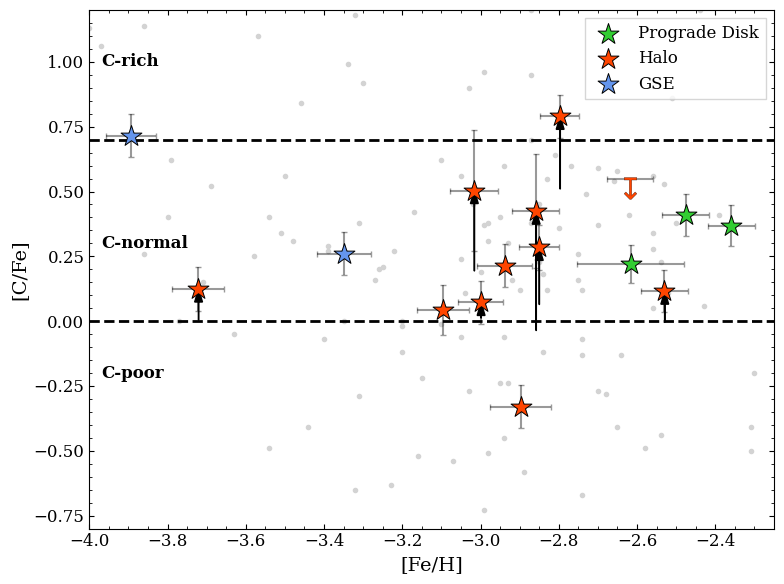

In [28]:
plt.figure(figsize=(8, 6))

# Plotting the data points
plt.scatter(prodisk_df['feh'], prodisk_df['cfe'], color='limegreen', label='Prograde Disk', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(prodisk_df['feh'], prodisk_df['cfe'], xerr=prodisk_df['feh_err'],
             yerr=prodisk_df['cfe_err'], fmt='o', color='black', zorder=9, alpha=0.4)
plt.scatter(halo_df['feh'], halo_df['cfe'], color='orangered', label='Halo', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(halo_df['feh'], halo_df['cfe'], xerr=halo_df['feh_err'],
             yerr=halo_df['cfe_err'], fmt='o', color='black', zorder=9, alpha=0.4)
plt.scatter(gse_df['feh'], gse_df['cfe'], color='cornflowerblue', label='GSE', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(gse_df['feh'], gse_df['cfe'], xerr=gse_df['feh_err'],
             yerr=gse_df['cfe_err'], fmt='o', color='black', zorder=9, alpha=0.4)
plt.scatter(feh_lit_abund, cfe_lit_abund, color='lightgrey', marker='.', zorder=1)
plt.axhline(y=0, color='black', linestyle='--', linewidth=2)
plt.axhline(y=0.7, color='black', linestyle='--', linewidth=2)

# Plotting the un-corrected data as arrows
for xi, yi1, yi2 in zip(halo_df['feh'], halo_df['cfe'], halo_df['cfe_uncorr']):
    dy = yi2 - yi1
    
    # If correction is too small, then won't plot
    if abs(dy) < 0.05:
        continue
    else:
        # Arrow position slightly off from marker, so applying 0.001 offset
        plt.arrow(xi+0.001, yi1 - abs(dy), 0, abs(dy), head_width=0.02, head_length=0.05, length_includes_head=True, color='black')


for xi, yi1, yi2 in zip(gse_df['feh'], gse_df['cfe'], gse_df['cfe_uncorr']):
    dy = yi2 - yi1
    
    # If correction is too small, then won't plot
    if abs(dy) < 0.05:
        continue
    else:
        # Arrow position slightly off from marker, so applying 0.001 offset
        plt.arrow(xi+0.001, yi1 - abs(dy), 0, abs(dy), head_width=0.02, head_length=0.05, length_includes_head=True, color='black')


# Plotting the upper-limits
# plt.scatter(prodisk_ul_df['feh'] - 0.05, prodisk_ul_df['cfe_ul'] - 0.035, color='limegreen', zorder=5, 
#             marker='${↧}$', s=250, linewidths=0.2, edgecolor='black')
# plt.errorbar(prodisk_ul_df['feh'] - 0.05, prodisk_ul_df['cfe_ul'], 
#             xerr=prodisk_ul_df['feh_err'], fmt='none', color='black', zorder=1, alpha=0.4)
plt.scatter(halo_ul_df['feh'] + 0.05, halo_ul_df['cfe_ul'] - 0.035, color='orangered', zorder=5, 
            marker='${↧}$', s=250, linewidths=0.2, edgecolor='black')
plt.errorbar(halo_ul_df['feh'] + 0.05, halo_ul_df['cfe_ul'], 
            xerr=halo_ul_df['feh_err'], fmt='none', color='black', zorder=1, alpha=0.4)
# plt.scatter(gse_ul_df['feh'] + 0.15, gse_ul_df['cfe_ul'] - 0.05, color='cornflowerblue', zorder=5, 
#             marker='${↧}$', s=250, linewidths=0.2, edgecolor='black')
# plt.errorbar(gse_ul_df['feh'] + 0.15, gse_ul_df['cfe_ul'] + 0.12, 
#             xerr=gse_ul_df['feh_err'], fmt='none', color='black', zorder=1, alpha=0.4)




# plt.axvline(x=0.3, ymax=0.955, color='black', linestyle='--', linewidth=2)
# plt.axvline(x=1.0, ymax=0.955, color='black', linestyle='--', linewidth=2)

# rectangle = plt.Rectangle((-4.0, 0.15), 1.8, -0.15, facecolor='grey', alpha=0.1, zorder=-10)
# plt.gca().add_patch(rectangle)
plt.text(-3.97, -0.2, 'C-poor', fontsize=12, color='black', ha='left', va='center', weight='bold')

# rectangle = plt.Rectangle((-4.0, 0.7), 1.8, -0.7, facecolor='grey', alpha=0.1, zorder=-10)
# plt.gca().add_patch(rectangle)
plt.text(-3.97, 0.3, 'C-normal', fontsize=12, color='black', ha='left', va='center', weight='bold')

# rectangle = plt.Rectangle((-4.0, 0.7), 1.8, 0.5, facecolor='grey', alpha=0.2, zorder=-10)
# plt.gca().add_patch(rectangle)
plt.text(-3.97, 1.0, 'C-rich', fontsize=12, color='black', ha='left', va='center', weight='bold')

plt.xlabel('[Fe/H]')
plt.ylabel('[C/Fe]')
plt.legend(fancybox=False)

plt.xlim(-4, -2.25)
plt.ylim(-0.8, 1.2)

plt.tight_layout()
plt.savefig("/data/misfit/benlowe/xshooter/p113/results/star_abunds/c_enhanced_v8.pdf", dpi=300, transparent=False, facecolor="white")
plt.savefig("/data/misfit/benlowe/xshooter/p113/results/star_abunds/c_enhanced_v8.png", dpi=300, transparent=False, facecolor="white")

## Metallicity comparision between 2dF+AAOmega and X-Shooter

### P113 data

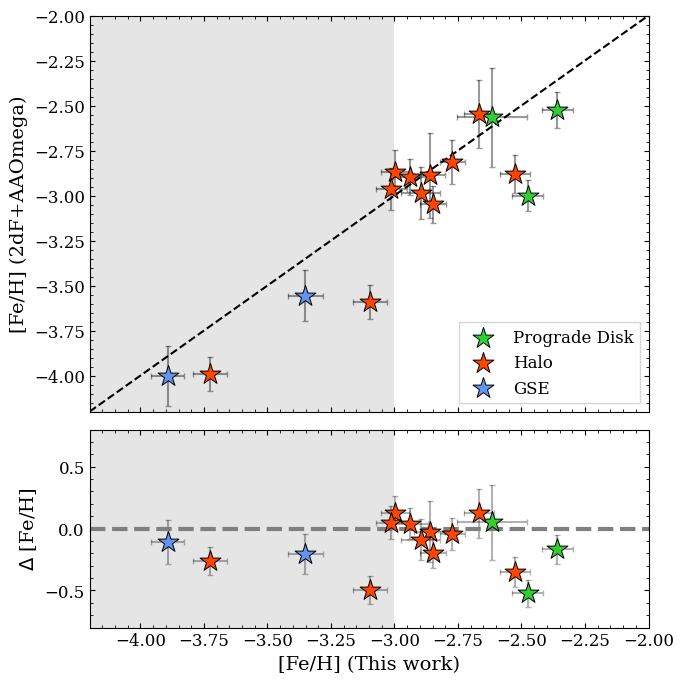

In [8]:
# Loading in the data
# X-Shooter data
xshooter_new_data= pd.read_csv('/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter9/stellar_params.csv').sort_values(by='star_id')
xshooter_new_feh = xshooter_new_data['Fe_it1'].to_numpy()
xshooter_new_feh_err = xshooter_new_data['Fe_comberr'].to_numpy()

# AAT data
aat_data= pd.read_csv('/data/misfit/benlowe/xshooter/p113/stellar_params/emp_params_FINAL.csv').sort_values(by='star_id')
aat_feh = aat_data['z'].to_numpy()
aat_feh_err = aat_data['randz_std'].to_numpy()

# Merging the data together, then separating based on orbit type
feh_comb_df = pd.merge(xshooter_new_data[['star_id', 'Fe_it1', 'Fe_comberr']], aat_data[['star_id', 'z', 'randz_std', 'orbit']], on='star_id', how='inner')

feh_prodisk_df = feh_comb_df[feh_comb_df['orbit'] == 'pro_disk']
feh_halo_df = feh_comb_df[feh_comb_df['orbit'] == 'halo']
feh_gse_df = feh_comb_df[feh_comb_df['orbit'] == 'gse']


# Plotting
fig = plt.figure(figsize=[7,7])
gs = fig.add_gridspec(2, 1, wspace=0.1, hspace=0.03, width_ratios=[1], height_ratios=[2, 1])
(ax1), (ax2) = gs.subplots(sharex='col')

# Main plot
ax1.scatter(feh_prodisk_df['Fe_it1'], feh_prodisk_df['z'], color='limegreen', label='Prograde Disk', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
ax1.errorbar(feh_prodisk_df['Fe_it1'], feh_prodisk_df['z'], xerr=feh_prodisk_df['Fe_comberr'],
                yerr=feh_prodisk_df['randz_std'], fmt='o', color='black', zorder=9, alpha=0.4)
ax1.scatter(feh_halo_df['Fe_it1'], feh_halo_df['z'], color='orangered', label='Halo', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
ax1.errorbar(feh_halo_df['Fe_it1'], feh_halo_df['z'], xerr=feh_halo_df['Fe_comberr'],
                yerr=feh_halo_df['randz_std'], fmt='o', color='black', zorder=9, alpha=0.4)
ax1.scatter(feh_gse_df['Fe_it1'], feh_gse_df['z'], color='cornflowerblue', label='GSE', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
ax1.errorbar(feh_gse_df['Fe_it1'], feh_gse_df['z'], xerr=feh_gse_df['Fe_comberr'],
                yerr=feh_gse_df['randz_std'], fmt='o', color='black', zorder=9, alpha=0.4)
ax1.plot([-4.2, -2.0], [-4.2, -2.0], color='black', linestyle='--')

rectangle = plt.Rectangle((-4.2, -4.2), 1.2, 2.5, facecolor='grey', alpha=0.2, zorder=-10)
ax1.add_patch(rectangle)
ax1.set_xlim(-4.2, -2.0)
ax1.set_ylim(-4.2, -2.0)
ax1.set_ylabel('[Fe/H] (2dF+AAOmega)')
ax1.legend(fancybox=False)


# Difference plot
ax2.scatter(feh_prodisk_df['Fe_it1'], feh_prodisk_df['z'] - feh_prodisk_df['Fe_it1'], color='limegreen', marker='*', s=250, edgecolor='black', 
            zorder=10, linewidths=0.7)
ax2.errorbar(feh_prodisk_df['Fe_it1'], feh_prodisk_df['z'] - feh_prodisk_df['Fe_it1'], 
             xerr=feh_prodisk_df['Fe_comberr'], yerr=np.sqrt(feh_prodisk_df['Fe_comberr']**2 + feh_prodisk_df['randz_std']**2), 
             fmt='o', color='black', alpha=0.3, zorder=1)
ax2.scatter(feh_halo_df['Fe_it1'], feh_halo_df['z'] - feh_halo_df['Fe_it1'], color='orangered', marker='*', s=250, edgecolor='black', zorder=10, 
            linewidths=0.7)
ax2.errorbar(feh_halo_df['Fe_it1'], feh_halo_df['z'] - feh_halo_df['Fe_it1'], 
             xerr=feh_halo_df['Fe_comberr'], yerr=np.sqrt(feh_halo_df['Fe_comberr']**2 + feh_halo_df['randz_std']**2), fmt='o', color='black', alpha=0.3, zorder=1)
ax2.scatter(feh_gse_df['Fe_it1'], feh_gse_df['z'] - feh_gse_df['Fe_it1'], color='cornflowerblue', marker='*', s=250, edgecolor='black', 
            zorder=10, linewidths=0.7)
ax2.errorbar(feh_gse_df['Fe_it1'], feh_gse_df['z'] - feh_gse_df['Fe_it1'], 
             xerr=feh_gse_df['Fe_comberr'], yerr=np.sqrt(feh_gse_df['Fe_comberr']**2 + feh_gse_df['randz_std']**2), fmt='o', color='black', alpha=0.3, zorder=1)

# ax2.scatter(xshooter_new_feh, aat_feh-xshooter_new_feh, color='darkred', zorder=10)
# ax2.errorbar(xshooter_new_feh, aat_feh-xshooter_new_feh, yerr=np.sqrt(xshooter_new_feh_err**2 + aat_feh_err**2), 
#              xerr=xshooter_new_feh_err, fmt='o', color='black', alpha=0.3, zorder=1)


rectangle = plt.Rectangle((-4.2, -2), 1.2, 5, facecolor='grey', alpha=0.2, zorder=-10)
ax2.add_patch(rectangle)
ax2.axhline(0, color='grey', linestyle='--', linewidth=3)
ax2.set_xlabel("[Fe/H] (This work)")
ax2.set_ylabel("$\Delta$ [Fe/H]")
ax2.set_xlim(-4.2, -2.0)
ax2.set_ylim(bottom=-0.8, top=0.8)

gs.tight_layout(fig)

# plt.savefig("/data/misfit/benlowe/xshooter/p113/results/aat_comparision/aat_xshooter_feh_v8.pdf", dpi=300, transparent=False, facecolor="white")
# plt.savefig("/data/misfit/benlowe/xshooter/p113/results/aat_comparision/aat_xshooter_feh_v8.png", dpi=300, transparent=False, facecolor="white")



In [16]:
# Calculating means and stds of the differences between AAT and X-Shooter (neglecting kinematic classifications)
feh_diffs = feh_comb_df['z'] - feh_comb_df['Fe_it1']
print(feh_diffs.mean(), feh_diffs.std())


-0.13049126973514757 0.20214137761884832


### P115 data

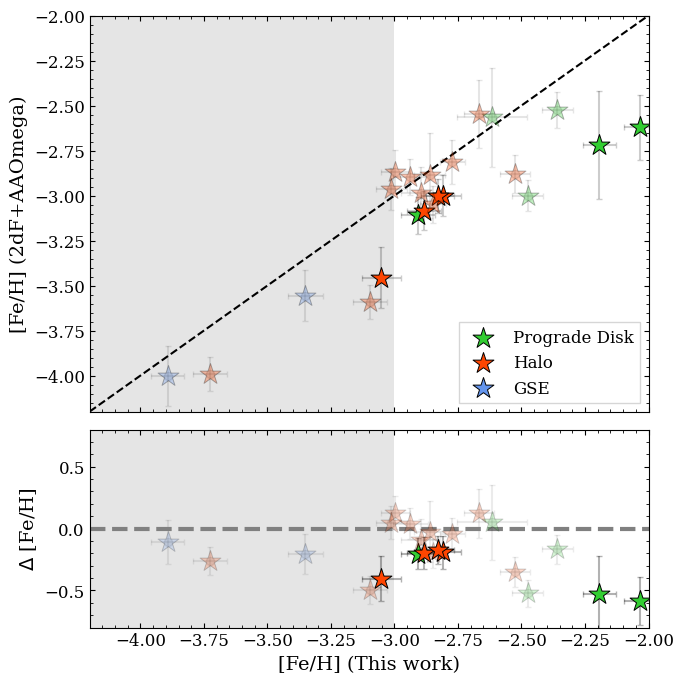

In [6]:
# Loading in the data
# X-Shooter data
xshooter_p115_data= pd.read_csv('/data/misfit/benlowe/xshooter/p115/korg_data/abunds_v2/final_iter9/stellar_params.csv').sort_values(by='star_id')
xshooter_p115_feh = xshooter_p115_data['Fe_it1'].to_numpy()
xshooter_p115_feh_err = xshooter_p115_data['Fe_comberr'].to_numpy()

xshooter_p113_data= pd.read_csv('/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter9/stellar_params.csv').sort_values(by='star_id')
xshooter_p113_feh = xshooter_p113_data['Fe_it1'].to_numpy()
xshooter_p113_feh_err = xshooter_p113_data['Fe_comberr'].to_numpy()

# AAT data
aat_p115_data= pd.read_csv('/data/misfit/benlowe/xshooter/p115/stellar_params/emp_params_FINAL.csv').sort_values(by='star_id')
aat_p115_feh = aat_data['z'].to_numpy()
aat_p115_feh_err = aat_data['randz_std'].to_numpy()

aat_p113_data= pd.read_csv('/data/misfit/benlowe/xshooter/p113/stellar_params/emp_params_FINAL.csv').sort_values(by='star_id')
aat_p113_feh = aat_data['z'].to_numpy()
aat_p113_feh_err = aat_data['randz_std'].to_numpy()

# Merging the data together, then separating based on orbit type
feh_comb_p115_df = pd.merge(xshooter_p115_data[['star_id', 'Fe_it1', 'Fe_comberr']], aat_p115_data[['star_id', 'z', 'randz_std', 'orbit']], on='star_id', how='inner')
feh_comb_p113_df = pd.merge(xshooter_p113_data[['star_id', 'Fe_it1', 'Fe_comberr']], aat_p113_data[['star_id', 'z', 'randz_std', 'orbit']], on='star_id', how='inner')


feh_prodisk_df = feh_comb_p115_df[feh_comb_p115_df['orbit'] == 'pro_disk']
feh_halo_df = feh_comb_p115_df[feh_comb_p115_df['orbit'] == 'halo']
feh_gse_df = feh_comb_p115_df[feh_comb_p115_df['orbit'] == 'gse']

feh_p113_prodisk_df = feh_comb_p113_df[feh_comb_p113_df['orbit'] == 'pro_disk']
feh_p113_halo_df = feh_comb_p113_df[feh_comb_p113_df['orbit'] == 'halo']
feh_p113_gse_df = feh_comb_p113_df[feh_comb_p113_df['orbit'] == 'gse']


# Plotting
fig = plt.figure(figsize=[7,7])
gs = fig.add_gridspec(2, 1, wspace=0.1, hspace=0.03, width_ratios=[1], height_ratios=[2, 1])
(ax1), (ax2) = gs.subplots(sharex='col')

# Main plot
ax1.scatter(feh_prodisk_df['Fe_it1'], feh_prodisk_df['z'], color='limegreen', label='Prograde Disk', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
ax1.errorbar(feh_prodisk_df['Fe_it1'], feh_prodisk_df['z'], xerr=feh_prodisk_df['Fe_comberr'],
                yerr=feh_prodisk_df['randz_std'], fmt='o', color='black', zorder=9, alpha=0.2)
ax1.scatter(feh_p113_prodisk_df['Fe_it1'], feh_p113_prodisk_df['z'], color='limegreen', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7, alpha=0.3)
ax1.errorbar(feh_p113_prodisk_df['Fe_it1'], feh_p113_prodisk_df['z'], xerr=feh_p113_prodisk_df['Fe_comberr'],
                yerr=feh_p113_prodisk_df['randz_std'], fmt='o', color='black', zorder=9, alpha=0.1)


ax1.scatter(feh_halo_df['Fe_it1'], feh_halo_df['z'], color='orangered', label='Halo', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
ax1.errorbar(feh_halo_df['Fe_it1'], feh_halo_df['z'], xerr=feh_halo_df['Fe_comberr'],
                yerr=feh_halo_df['randz_std'], fmt='o', color='black', zorder=9, alpha=0.2)
ax1.scatter(feh_p113_halo_df['Fe_it1'], feh_p113_halo_df['z'], color='orangered', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7, alpha=0.3)
ax1.errorbar(feh_p113_halo_df['Fe_it1'], feh_p113_halo_df['z'], xerr=feh_p113_halo_df['Fe_comberr'],
                yerr=feh_p113_halo_df['randz_std'], fmt='o', color='black', zorder=9, alpha=0.1)

ax1.scatter(feh_gse_df['Fe_it1'], feh_gse_df['z'], color='cornflowerblue', label='GSE', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7)
ax1.errorbar(feh_gse_df['Fe_it1'], feh_gse_df['z'], xerr=feh_gse_df['Fe_comberr'],
                yerr=feh_gse_df['randz_std'], fmt='o', color='black', zorder=9, alpha=0.2)
ax1.scatter(feh_p113_gse_df['Fe_it1'], feh_p113_gse_df['z'], color='cornflowerblue', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7, alpha=0.3)
ax1.errorbar(feh_p113_gse_df['Fe_it1'], feh_p113_gse_df['z'], xerr=feh_p113_gse_df['Fe_comberr'],
                yerr=feh_p113_gse_df['randz_std'], fmt='o', color='black', zorder=9, alpha=0.1)

ax1.plot([-4.2, -2.0], [-4.2, -2.0], color='black', linestyle='--')

rectangle = plt.Rectangle((-4.2, -4.2), 1.2, 2.5, facecolor='grey', alpha=0.2, zorder=-10)
ax1.add_patch(rectangle)
ax1.set_xlim(-4.2, -2.0)
ax1.set_ylim(-4.2, -2.0)
ax1.set_ylabel('[Fe/H] (2dF+AAOmega)')
ax1.legend(fancybox=False)


# Difference plot
ax2.scatter(feh_prodisk_df['Fe_it1'], feh_prodisk_df['z'] - feh_prodisk_df['Fe_it1'], color='limegreen', marker='*', s=250, edgecolor='black', 
            zorder=10, linewidths=0.7)
ax2.errorbar(feh_prodisk_df['Fe_it1'], feh_prodisk_df['z'] - feh_prodisk_df['Fe_it1'], 
             xerr=feh_prodisk_df['Fe_comberr'], yerr=np.sqrt(feh_prodisk_df['Fe_comberr']**2 + feh_prodisk_df['randz_std']**2), 
             fmt='o', color='black', alpha=0.3, zorder=1)
ax2.scatter(feh_p113_prodisk_df['Fe_it1'], feh_p113_prodisk_df['z'] - feh_p113_prodisk_df['Fe_it1'], color='limegreen', 
            marker='*', s=250, edgecolor='black', zorder=15, linewidths=0.7, alpha=0.2)
ax2.errorbar(feh_p113_prodisk_df['Fe_it1'], feh_p113_prodisk_df['z'] - feh_p113_prodisk_df['Fe_it1'], 
             xerr=feh_p113_prodisk_df['Fe_comberr'], yerr=np.sqrt(feh_p113_prodisk_df['Fe_comberr']**2 + feh_p113_prodisk_df['randz_std']**2), 
             fmt='o', color='black', alpha=0.08, zorder=5)

ax2.scatter(feh_halo_df['Fe_it1'], feh_halo_df['z'] - feh_halo_df['Fe_it1'], color='orangered', marker='*', s=250, edgecolor='black', zorder=15, 
            linewidths=0.7)
ax2.errorbar(feh_halo_df['Fe_it1'], feh_halo_df['z'] - feh_halo_df['Fe_it1'], 
             xerr=feh_halo_df['Fe_comberr'], yerr=np.sqrt(feh_halo_df['Fe_comberr']**2 + feh_halo_df['randz_std']**2), fmt='o', color='black', alpha=0.3, zorder=5)
ax2.scatter(feh_p113_halo_df['Fe_it1'], feh_p113_halo_df['z'] - feh_p113_halo_df['Fe_it1'], color='orangered', 
            marker='*', s=250, edgecolor='black', zorder=10, linewidths=0.7, alpha=0.2)
ax2.errorbar(feh_p113_halo_df['Fe_it1'], feh_p113_halo_df['z'] - feh_p113_halo_df['Fe_it1'], 
             xerr=feh_p113_halo_df['Fe_comberr'], yerr=np.sqrt(feh_p113_halo_df['Fe_comberr']**2 + feh_p113_halo_df['randz_std']**2), fmt='o', color='black', alpha=0.08, zorder=1)

ax2.scatter(feh_gse_df['Fe_it1'], feh_gse_df['z'] - feh_gse_df['Fe_it1'], color='cornflowerblue', marker='*', s=250, edgecolor='black', 
            zorder=15, linewidths=0.7)
ax2.errorbar(feh_gse_df['Fe_it1'], feh_gse_df['z'] - feh_gse_df['Fe_it1'], 
             xerr=feh_gse_df['Fe_comberr'], yerr=np.sqrt(feh_gse_df['Fe_comberr']**2 + feh_gse_df['randz_std']**2), fmt='o', color='black', alpha=0.3, zorder=5)
ax2.scatter(feh_p113_gse_df['Fe_it1'], feh_p113_gse_df['z'] - feh_p113_gse_df['Fe_it1'], color='cornflowerblue', marker='*', s=250, edgecolor='black', 
            zorder=10, linewidths=0.7, alpha=0.2)
ax2.errorbar(feh_p113_gse_df['Fe_it1'], feh_p113_gse_df['z'] - feh_p113_gse_df['Fe_it1'], 
             xerr=feh_p113_gse_df['Fe_comberr'], yerr=np.sqrt(feh_p113_gse_df['Fe_comberr']**2 + feh_p113_gse_df['randz_std']**2), fmt='o', color='black', alpha=0.08, zorder=1)

# ax2.scatter(xshooter_new_feh, aat_feh-xshooter_new_feh, color='darkred', zorder=10)
# ax2.errorbar(xshooter_new_feh, aat_feh-xshooter_new_feh, yerr=np.sqrt(xshooter_new_feh_err**2 + aat_feh_err**2), 
#              xerr=xshooter_new_feh_err, fmt='o', color='black', alpha=0.3, zorder=1)


rectangle = plt.Rectangle((-4.2, -2), 1.2, 5, facecolor='grey', alpha=0.2, zorder=-10)
ax2.add_patch(rectangle)
ax2.axhline(0, color='grey', linestyle='--', linewidth=3)
ax2.set_xlabel("[Fe/H] (This work)")
ax2.set_ylabel("$\Delta$ [Fe/H]")
ax2.set_xlim(-4.2, -2.0)
ax2.set_ylim(bottom=-0.8, top=0.8)

gs.tight_layout(fig)

# plt.savefig("/data/misfit/benlowe/xshooter/p115/results/aat_comparision/aat_xshooter_feh_v2.pdf", dpi=300, transparent=False, facecolor="white")
# plt.savefig("/data/misfit/benlowe/xshooter/p115/results/aat_comparision/aat_xshooter_feh_v2.png", dpi=300, transparent=False, facecolor="white")



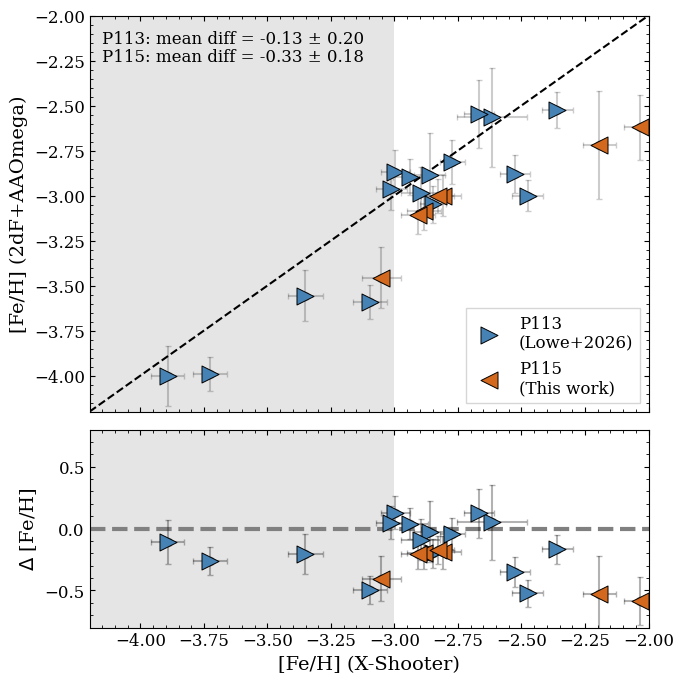

In [37]:
# Plotting
fig = plt.figure(figsize=[7,7])
gs = fig.add_gridspec(2, 1, wspace=0.1, hspace=0.03, width_ratios=[1], height_ratios=[2, 1])
(ax1), (ax2) = gs.subplots(sharex='col')

# Main plot
ax1.scatter(feh_comb_p113_df['Fe_it1'], feh_comb_p113_df['z'], color='steelblue', label='P113\n(Lowe+2026)',
            marker='>', s=150, edgecolor='black', zorder=15, linewidths=0.7)
ax1.errorbar(feh_comb_p113_df['Fe_it1'], feh_comb_p113_df['z'], xerr=feh_comb_p113_df['Fe_comberr'],
                yerr=feh_comb_p113_df['randz_std'], fmt='o', color='black', zorder=9, alpha=0.2)
ax1.scatter(feh_comb_p115_df['Fe_it1'], feh_comb_p115_df['z'], color='chocolate', label='P115\n(This work)', 
            marker='<', s=150, edgecolor='black', zorder=15, linewidths=0.7)
ax1.errorbar(feh_comb_p115_df['Fe_it1'], feh_comb_p115_df['z'], xerr=feh_comb_p115_df['Fe_comberr'],
                yerr=feh_comb_p115_df['randz_std'], fmt='o', color='black', zorder=9, alpha=0.2)

ax1.plot([-4.2, -2.0], [-4.2, -2.0], color='black', linestyle='--')

rectangle = plt.Rectangle((-4.2, -4.2), 1.2, 2.5, facecolor='grey', alpha=0.2, zorder=-10)
ax1.add_patch(rectangle)
ax1.set_xlim(-4.2, -2.0)
ax1.set_ylim(-4.2, -2.0)
ax1.set_ylabel('[Fe/H] (2dF+AAOmega)')
ax1.legend(fancybox=False)

ax1.text(-4.15, -2.15, "P113: mean diff = {:.2f} ± {:.2f}".format((feh_comb_p113_df['z'] - feh_comb_p113_df['Fe_it1']).mean(), (feh_comb_p113_df['z'] - feh_comb_p113_df['Fe_it1']).std()), color='black')
ax1.text(-4.15, -2.25, "P115: mean diff = {:.2f} ± {:.2f}".format((feh_comb_p115_df['z'] - feh_comb_p115_df['Fe_it1']).mean(), (feh_comb_p115_df['z'] - feh_comb_p115_df['Fe_it1']).std()), color='black')

# Difference plot
ax2.scatter(feh_comb_p113_df['Fe_it1'], feh_comb_p113_df['z'] - feh_comb_p113_df['Fe_it1'], color='steelblue', 
            marker='>', s=150, edgecolor='black', zorder=15, linewidths=0.7)
ax2.errorbar(feh_comb_p113_df['Fe_it1'], feh_comb_p113_df['z'] - feh_comb_p113_df['Fe_it1'], 
             xerr=feh_comb_p113_df['Fe_comberr'], yerr=np.sqrt(feh_comb_p113_df['Fe_comberr']**2 + feh_comb_p113_df['randz_std']**2), 
             fmt='o', color='black', alpha=0.3, zorder=5)

ax2.scatter(feh_comb_p115_df['Fe_it1'], feh_comb_p115_df['z'] - feh_comb_p115_df['Fe_it1'], color='chocolate', marker='<', s=150, 
            edgecolor='black', zorder=15, linewidths=0.7)
ax2.errorbar(feh_comb_p115_df['Fe_it1'], feh_comb_p115_df['z'] - feh_comb_p115_df['Fe_it1'], 
             xerr=feh_comb_p115_df['Fe_comberr'], yerr=np.sqrt(feh_comb_p115_df['Fe_comberr']**2 + feh_comb_p115_df['randz_std']**2), 
             fmt='o', color='black', alpha=0.3, zorder=1)
# ax2.scatter(xshooter_new_feh, aat_feh-xshooter_new_feh, color='darkred', zorder=10)
# ax2.errorbar(xshooter_new_feh, aat_feh-xshooter_new_feh, yerr=np.sqrt(xshooter_new_feh_err**2 + aat_feh_err**2), 
#              xerr=xshooter_new_feh_err, fmt='o', color='black', alpha=0.3, zorder=1)


rectangle = plt.Rectangle((-4.2, -2), 1.2, 5, facecolor='grey', alpha=0.2, zorder=-10)
ax2.add_patch(rectangle)
ax2.axhline(0, color='grey', linestyle='--', linewidth=3)
ax2.set_xlabel("[Fe/H] (X-Shooter)")
ax2.set_ylabel("$\Delta$ [Fe/H]")
ax2.set_xlim(-4.2, -2.0)
ax2.set_ylim(bottom=-0.8, top=0.8)

gs.tight_layout(fig)

plt.savefig("/data/misfit/benlowe/xshooter/p115/results/aat_comparision/aat_xshooter_feh_v3.pdf", dpi=300, transparent=False, facecolor="white")
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/aat_comparision/aat_xshooter_feh_v3.png", dpi=300, transparent=False, facecolor="white")



In [29]:
# Calculating means and stds of the differences between AAT and X-Shooter (neglecting kinematic classifications)
feh_diffs = feh_comb_p115_df['z'] - feh_comb_p115_df['Fe_it1']
print(feh_diffs.mean(), feh_diffs.std())
print()

feh_diffs_p113 = feh_comb_p113_df['z'] - feh_comb_p113_df['Fe_it1']
print(feh_diffs_p113.mean(), feh_diffs_p113.std())

-0.3262003816564429 0.1761625319792394

-0.13049126973514757 0.20214137761884832


## Looking at abundances for each star

### P113 data

In [11]:
el_list = ['C', 'N', 'Na', 'Mg', 'Al', 'Si', 'Ca', 'Sc',
           'Ti', 'Cr', 'Mn', 'Co', 'Ni', 'Sr', 'Ba', 'Eu']

# Separating the upper-limits for each element
bad_na_stars = ['ra_1604-2712_s292', 'ra_1648-0653_s38', 'ra_1752-4300_s269'] # These stars have interstellar Na contamination, so we remove them

stars = stars_data['star_id'].to_numpy()

# Taking the mean if the literature  (in order with above el_list)
mean_lit_abunds = [cI_lit_abund['abund'].mean(), nI_lit_abund['abund'].mean(), naI_lit_abund['abund'].mean(),
                    mgI_lit_abund['abund'].mean(), alI_lit_abund['abund'].mean(), siI_lit_abund['abund'].mean(),
                    caI_lit_abund['abund'].mean(), scII_lit_abund['abund'].mean(), tiII_lit_abund['abund'].mean(),
                    crI_lit_abund['abund'].mean(), mnI_lit_abund['abund'].mean(), coI_lit_abund['abund'].mean(),
                    niI_lit_abund['abund'].mean(), srII_lit_abund['abund'].mean(), baII_lit_abund['abund'].mean(),
                    euII_lit_abund['abund'].mean()]
std_lit_abunds = [cI_lit_abund['abund'].std(), nI_lit_abund['abund'].std(), naI_lit_abund['abund'].std(),
                    mgI_lit_abund['abund'].std(), alI_lit_abund['abund'].std(), siI_lit_abund['abund'].std(),
                    caI_lit_abund['abund'].std(), scII_lit_abund['abund'].std(), tiII_lit_abund['abund'].std(),
                    crI_lit_abund['abund'].std(), mnI_lit_abund['abund'].std(), coI_lit_abund['abund'].std(),
                    niI_lit_abund['abund'].std(), srII_lit_abund['abund'].std(), baII_lit_abund['abund'].std(),
                    euII_lit_abund['abund'].std()]

# Loading in the rounded stellar parameters
params_rounded = pd.read_csv('/data/misfit/benlowe/xshooter/p113/stellar_params/star_params_rd.csv')

fig, axs = plt.subplots(8, 2, figsize=[9, 13], tight_layout=True, sharex=True, sharey=True, gridspec_kw={'wspace': 0, 'hspace': 0})
fig.subplots_adjust(wspace=0.25)
# fig.supxlabel('[Fe/H]')
fig.supylabel('[X/Fe]')


for ax, star in zip(axs.flat, stars):
    
    # Plotting the mean abundances from the literature
    ax.plot(el_list, mean_lit_abunds, color='black', zorder=-1, marker='.')
    ax.fill_between(el_list, np.array(mean_lit_abunds) - np.array(std_lit_abunds), 
                    np.array(mean_lit_abunds) + np.array(std_lit_abunds), color='grey', alpha=0.2, zorder=-1)


    # Getting the entries for the star
    star_data = stars_upperlimits[stars_upperlimits['star_id'] == star]
    
    # Stellar parameters
    star_teff = params_rounded[params_rounded['star_id'] == star]['teff'].to_numpy()[0]
    star_logg = params_rounded[params_rounded['star_id'] == star]['logg'].to_numpy()[0]
    star_feh = params_rounded[params_rounded['star_id'] == star]['feh'].to_numpy()[0]
    
    # Separating star data by element, then storing into list
    al_I_abund = al_I_abunds[al_I_abunds['star_id'] == star]
    ba_II_abund = ba_II_abunds[ba_II_abunds['star_id'] == star]
    c_I_abund = c_I_abunds[c_I_abunds['star_id'] == star]
    ca_II_abund = ca_II_abunds[ca_II_abunds['star_id'] == star]
    co_I_abund = co_I_abunds[co_I_abunds['star_id'] == star]
    cr_I_abund = cr_I_abunds[cr_I_abunds['star_id'] == star]
    eu_II_abund = eu_II_abunds[eu_II_abunds['star_id'] == star]
    mg_I_abund = mg_I_abunds[mg_I_abunds['star_id'] == star]
    mn_I_abund = mn_I_abunds[mn_I_abunds['star_id'] == star]
    n_I_abund = n_I_abunds[n_I_abunds['star_id'] == star]
    na_I_abund = na_I_abunds[na_I_abunds['star_id'] == star]
    ni_I_abund = ni_I_abunds[ni_I_abunds['star_id'] == star]
    sc_II_abund = sc_II_abunds[sc_II_abunds['star_id'] == star]
    si_I_abund = si_I_abunds[si_I_abunds['star_id'] == star]
    sr_II_abund = sr_II_abunds[sr_II_abunds['star_id'] == star]
    ti_II_abund = ti_II_abunds[ti_II_abunds['star_id'] == star]
    # ba_II_abund = star_data[star_data['el'] == 'Ba_II']
    # c_I_abund = star_data[(star_data['el'] == 'C_I') & (star_data['teff'] < 5300)]
    # ca_II_abund = star_data[star_data['el'] == 'Ca_II']
    # co_I_abund = star_data[star_data['el'] == 'Co_I']
    # cr_I_abund = star_data[star_data['el'] == 'Cr_I']
    # eu_II_abund = star_data[star_data['el'] == 'Eu_II']
    # mg_I_abund = star_data[star_data['el'] == 'Mg_I']
    # mn_I_abund = star_data[star_data['el'] == 'Mn_I']
    # n_I_abund = star_data[(star_data['el'] == 'N_I') & (star_data['teff'] < 5300)]
    # na_I_abund = star_data[(star_data['el'] == 'Na_I') & (~star_data['star_id'].isin(bad_na_stars))]
    # ni_I_abund = star_data[star_data['el'] == 'Ni_I']
    # sc_II_abund = star_data[star_data['el'] == 'Sc_II']
    # si_I_abund = star_data[star_data['el'] == 'Si_I']
    # sr_II_abund = star_data[star_data['el'] == 'Sr_II']
    # ti_II_abund = star_data[star_data['el'] == 'Ti_II']
    
    # # For star ra_1656-1433_s143, change [C/Fe] abundance to first iteration (instead of second iteration)
    # if star == 'ra_1656-1433_s143':
    #     c_I_abunds['bestfit_abund_comberr_xfe'] = c_I_abunds['bestfit_abund_tefferr_xfe']
        
    # if star == 'ra_1752-4300_s6':
    #     c_I_abunds['bestfit_abund_comberr_xfe'] = c_I_abunds['bestfit_abund_tefferr_xfe']
            
    star_abund = [
        c_I_abund, n_I_abund, na_I_abund, mg_I_abund, al_I_abund, si_I_abund,
        ca_II_abund, sc_II_abund, ti_II_abund, cr_I_abund, mn_I_abund,
        co_I_abund, ni_I_abund, sr_II_abund, ba_II_abund, eu_II_abund
    ]
        
    # Plotting each element
    # - If detection is 'Y', plot the abundance with error bars
    # - If detection is 'N', plot the upper limit 
    abunds = [] # This contains both detections and upper limits for the star - for connecting line
    el_names = []
    for i, el_abund in enumerate(star_abund):
        detection = el_abund['detection'].to_numpy()
        
        
        if detection == 'Y':
            el = el_list[i]
            abund_val = el_abund['bestfit_abund_xfe'].to_numpy()
            abund_val_err = el_abund['bestfit_abund_comberr_xfe'].to_numpy()[0]
            
            # If the abundance value is empty, skip to the next element
            if len(abund_val) == 0:
                continue
            else:
                abunds.append(abund_val[0])
                el_names.append(el)
                
            
            # Computing the difference between the abundance value and the mean literature abundance.
            ith_lit_abund = mean_lit_abunds[i]
            ith_lit_std = std_lit_abunds[i]
            obs_lit_diff = abs(abund_val[0] - ith_lit_abund)
            
            # Seeing if the abundance value is within 2 sigma of the literature value
            lower_bound = ith_lit_abund - 2 * ith_lit_std
            upper_bound = ith_lit_abund + 2 * ith_lit_std

            if lower_bound <= abund_val <= upper_bound:
                abund_color = 'blue'
            else:
                abund_color = 'red'
                        
            # if obs_lit_diff > 0.5:
            #     abund_color = 'red'
            # else:
            #     abund_color = 'blue'
            
            ax.scatter(el, abund_val, color=abund_color, marker='*', s=150, edgecolor='none', zorder=3)
            ax.errorbar(x=el, y=abund_val, yerr=abund_val_err, color=abund_color, alpha=1, zorder=1, linestyle='')
            
        elif detection == 'N':
            
            el = el_list[i]
            abund_ul = el_abund['upper_limit_xfe'].to_numpy()
            abund_val = el_abund['bestfit_abund_xfe'].to_numpy()
            
            # If the abundance value is empty, skip to the next element
            if len(abund_val) == 0:
                continue
            else:
                abunds.append(abund_ul[0])
                el_names.append(el)      
            
            # If the upper limit is greater than 2sigma from the literature value, plot it in red
            ith_lit_abund = mean_lit_abunds[i]
            ith_lit_std = std_lit_abunds[i]
            obs_lit_diff = abs(abund_ul[0] - ith_lit_abund)
            lower_bound = ith_lit_abund - 2 * ith_lit_std
            upper_bound = ith_lit_abund + 2 * ith_lit_std
            
            if abund_ul < lower_bound:
                abund_color = 'red'
            else:
                abund_color = 'black'
            
            # ax.scatter(el, abund_ul, color=abund_color, zorder=5, 
            # marker='${↧}$', s=150, linewidths=0.1, edgecolor='black')
            
            ul_ysize = 0.4
            ax.errorbar(el, abund_ul, yerr=ul_ysize, uplims=True, fmt='none', capsize=0, zorder=1, color=abund_color)

            
    
    # Pllotting horizontal lines
    ax.axhline(y=0, color='grey', linestyle='--', linewidth=1, zorder=0)
    ax.axhline(y=-1, color='grey', linestyle=':', linewidth=1, zorder=0, alpha=0.8)
    ax.axhline(y=1, color='grey', linestyle=':', linewidth=1, zorder=0, alpha=0.8)

    if star == 'ra_1633-2814_s130':
        ax.text(s = f"{star} [{star_teff}, {star_logg}, {star_feh}]", y = -2, x = el_list[0], fontsize=12, color='black')
    else:
        ax.text(s = f"{star} [{star_teff}, {star_logg}, {star_feh}]", y = 2, x = el_list[0], fontsize=12, color='black')

    # Plotting the connecting line between the abundances
    # ax.plot(el_names, abunds, linestyle='-', color='black', alpha=0.5)
    
    
    ax.set_ylim(-2.7, 2.7)
    ax.xaxis.set_minor_locator(plt.NullLocator())
        
    # display(na_I_abunds)
    
    
# plt.savefig("/data/misfit/benlowe/xshooter/p113/results/star_abunds/abunds_trend_v15.pdf", dpi=300, transparent=False, facecolor="white")
# plt.savefig("/data/misfit/benlowe/xshooter/p113/results/star_abunds/abunds_trend_v15.png", dpi=300, transparent=False, facecolor="white")

NameError: name 'stars_data' is not defined

### P115 data

In [27]:
c_I_abunds[['star_id', 'detection', 'bestfit_abund_xfe', 'cfe_corr']]

,star_id,detection,bestfit_abund_xfe,cfe_corr
0,ra_0103-7050_s236,Y,-0.657859,0.76
1,ra_0752-5047_s47,Y,-0.311717,0.00
2,ra_1639-2632_s419,Y,0.323371,0.01
3,ra_1648-2642_s91,Y,0.186928,0.03
4,ra_1659-2154_s261,Y,0.022261,0.01
5,ra_1659-2154_s347,Y,0.431171,0.01
6,ra_1752-4300_s155,Y,-0.063120,0.51


/tmp/ipykernel_3078078/3480712786.py:110: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  el_abund['bestfit_abund_xfe'] = el_abund['bestfit_abund_xfe'] + el_abund['cfe_corr']
/tmp/ipykernel_3078078/3480712786.py:105: DeprecationWarning: The truth value of an empty array is ambiguous. Returning False, but in future this will result in an error. Use `array.size > 0` to check that an array is not empty.
  if detection == 'Y':
/tmp/ipykernel_3078078/3480712786.py:147: DeprecationWarning: The truth value of an empty array is ambiguous. Returning False, but in future this will result in an error. Use `array.size > 0` to check that an array is not empty.
  elif detection == 'N':


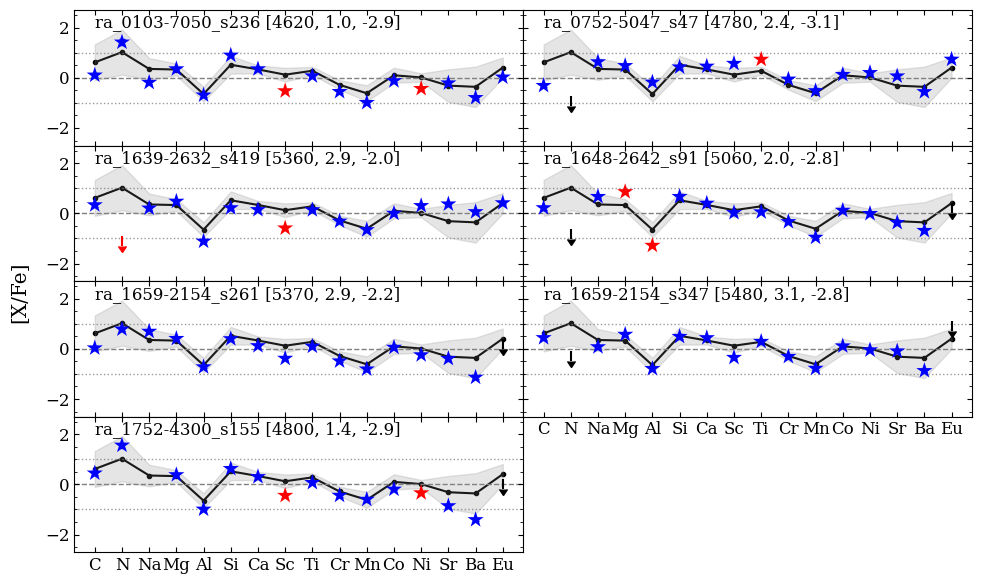

In [32]:
el_list = ['C', 'N', 'Na', 'Mg', 'Al', 'Si', 'Ca', 'Sc',
           'Ti', 'Cr', 'Mn', 'Co', 'Ni', 'Sr', 'Ba', 'Eu']

# Separating the upper-limits for each element
bad_na_stars = ['ra_1752-4300_s155'] # These stars have interstellar Na contamination, so we remove them

stars = stars_data['star_id'].to_numpy()

# Taking the mean if the literature  (in order with above el_list)
mean_lit_abunds = [cI_lit_abund['abund'].mean(), nI_lit_abund['abund'].mean(), naI_lit_abund['abund'].mean(),
                    mgI_lit_abund['abund'].mean(), alI_lit_abund['abund'].mean(), siI_lit_abund['abund'].mean(),
                    caI_lit_abund['abund'].mean(), scII_lit_abund['abund'].mean(), tiII_lit_abund['abund'].mean(),
                    crI_lit_abund['abund'].mean(), mnI_lit_abund['abund'].mean(), coI_lit_abund['abund'].mean(),
                    niI_lit_abund['abund'].mean(), srII_lit_abund['abund'].mean(), baII_lit_abund['abund'].mean(),
                    euII_lit_abund['abund'].mean()]
std_lit_abunds = [cI_lit_abund['abund'].std(), nI_lit_abund['abund'].std(), naI_lit_abund['abund'].std(),
                    mgI_lit_abund['abund'].std(), alI_lit_abund['abund'].std(), siI_lit_abund['abund'].std(),
                    caI_lit_abund['abund'].std(), scII_lit_abund['abund'].std(), tiII_lit_abund['abund'].std(),
                    crI_lit_abund['abund'].std(), mnI_lit_abund['abund'].std(), coI_lit_abund['abund'].std(),
                    niI_lit_abund['abund'].std(), srII_lit_abund['abund'].std(), baII_lit_abund['abund'].std(),
                    euII_lit_abund['abund'].std()]

# Loading in the rounded stellar parameters
params_rounded = pd.read_csv('/data/misfit/benlowe/xshooter/p115/stellar_params/star_params_rd.csv')

fig, axs = plt.subplots(4, 2, figsize=[10, 6], tight_layout=True, sharex=True, sharey=True, gridspec_kw={'wspace': 0, 'hspace': 0})
fig.subplots_adjust(wspace=0.25)
# fig.supxlabel('[Fe/H]')
fig.supylabel('[X/Fe]')

axs[3, 1].axis('off')
axs[2, 1].tick_params(labelbottom=True)

for ax, star in zip(axs.flat, stars):
    
    # Plotting the mean abundances from the literature
    ax.plot(el_list, mean_lit_abunds, color='black', zorder=-1, marker='.')
    ax.fill_between(el_list, np.array(mean_lit_abunds) - np.array(std_lit_abunds), 
                    np.array(mean_lit_abunds) + np.array(std_lit_abunds), color='grey', alpha=0.2, zorder=-1)


    # Getting the entries for the star
    star_data = stars_upperlimits[stars_upperlimits['star_id'] == star]
    
    # Stellar parameters
    star_teff = params_rounded[params_rounded['star_id'] == star]['teff'].to_numpy()[0]
    star_logg = params_rounded[params_rounded['star_id'] == star]['logg'].to_numpy()[0]
    star_feh = params_rounded[params_rounded['star_id'] == star]['feh'].to_numpy()[0]
    
    # Separating star data by element, then storing into list
    al_I_abund = al_I_abunds[al_I_abunds['star_id'] == star]
    ba_II_abund = ba_II_abunds[ba_II_abunds['star_id'] == star]
    c_I_abund = c_I_abunds[c_I_abunds['star_id'] == star]
    ca_II_abund = ca_II_abunds[ca_II_abunds['star_id'] == star]
    co_I_abund = co_I_abunds[co_I_abunds['star_id'] == star]
    cr_I_abund = cr_I_abunds[cr_I_abunds['star_id'] == star]
    eu_II_abund = eu_II_abunds[eu_II_abunds['star_id'] == star]
    mg_I_abund = mg_I_abunds[mg_I_abunds['star_id'] == star]
    mn_I_abund = mn_I_abunds[mn_I_abunds['star_id'] == star]
    n_I_abund = n_I_abunds[n_I_abunds['star_id'] == star]
    na_I_abund = na_I_abunds[na_I_abunds['star_id'] == star]
    ni_I_abund = ni_I_abunds[ni_I_abunds['star_id'] == star]
    sc_II_abund = sc_II_abunds[sc_II_abunds['star_id'] == star]
    si_I_abund = si_I_abunds[si_I_abunds['star_id'] == star]
    sr_II_abund = sr_II_abunds[sr_II_abunds['star_id'] == star]
    ti_II_abund = ti_II_abunds[ti_II_abunds['star_id'] == star]
    # ba_II_abund = star_data[star_data['el'] == 'Ba_II']
    # c_I_abund = star_data[(star_data['el'] == 'C_I') & (star_data['teff'] < 5300)]
    # ca_II_abund = star_data[star_data['el'] == 'Ca_II']
    # co_I_abund = star_data[star_data['el'] == 'Co_I']
    # cr_I_abund = star_data[star_data['el'] == 'Cr_I']
    # eu_II_abund = star_data[star_data['el'] == 'Eu_II']
    # mg_I_abund = star_data[star_data['el'] == 'Mg_I']
    # mn_I_abund = star_data[star_data['el'] == 'Mn_I']
    # n_I_abund = star_data[(star_data['el'] == 'N_I') & (star_data['teff'] < 5300)]
    # na_I_abund = star_data[(star_data['el'] == 'Na_I') & (~star_data['star_id'].isin(bad_na_stars))]
    # ni_I_abund = star_data[star_data['el'] == 'Ni_I']
    # sc_II_abund = star_data[star_data['el'] == 'Sc_II']
    # si_I_abund = star_data[star_data['el'] == 'Si_I']
    # sr_II_abund = star_data[star_data['el'] == 'Sr_II']
    # ti_II_abund = star_data[star_data['el'] == 'Ti_II']
    
    # # For star ra_1656-1433_s143, change [C/Fe] abundance to first iteration (instead of second iteration)
    # if star == 'ra_1656-1433_s143':
    #     c_I_abunds['bestfit_abund_comberr_xfe'] = c_I_abunds['bestfit_abund_tefferr_xfe']
        
    # if star == 'ra_1752-4300_s6':
    #     c_I_abunds['bestfit_abund_comberr_xfe'] = c_I_abunds['bestfit_abund_tefferr_xfe']
            
    star_abund = [
        c_I_abund, n_I_abund, na_I_abund, mg_I_abund, al_I_abund, si_I_abund,
        ca_II_abund, sc_II_abund, ti_II_abund, cr_I_abund, mn_I_abund,
        co_I_abund, ni_I_abund, sr_II_abund, ba_II_abund, eu_II_abund
    ]
        
    # Plotting each element
    # - If detection is 'Y', plot the abundance with error bars
    # - If detection is 'N', plot the upper limit 
    abunds = [] # This contains both detections and upper limits for the star - for connecting line
    el_names = []
    for i, el_abund in enumerate(star_abund):
        detection = el_abund['detection'].to_numpy()
        
        
        if detection == 'Y':
            el = el_list[i]
            
            # For C, apply evolutionary corrections
            if el == 'C':
                el_abund['bestfit_abund_xfe'] = el_abund['bestfit_abund_xfe'] + el_abund['cfe_corr']
    
            abund_val = el_abund['bestfit_abund_xfe'].to_numpy()
            abund_val_err = el_abund['bestfit_abund_comberr_xfe'].to_numpy()[0]
            

            
            # If the abundance value is empty, skip to the next element
            if len(abund_val) == 0:
                continue
            else:
                abunds.append(abund_val[0])
                el_names.append(el)
                
            
            # Computing the difference between the abundance value and the mean literature abundance.
            ith_lit_abund = mean_lit_abunds[i]
            ith_lit_std = std_lit_abunds[i]
            obs_lit_diff = abs(abund_val[0] - ith_lit_abund)
            
            # Seeing if the abundance value is within 2 sigma of the literature value
            lower_bound = ith_lit_abund - 2 * ith_lit_std
            upper_bound = ith_lit_abund + 2 * ith_lit_std

            if lower_bound <= abund_val <= upper_bound:
                abund_color = 'blue'
            else:
                abund_color = 'red'
                        
            # if obs_lit_diff > 0.5:
            #     abund_color = 'red'
            # else:
            #     abund_color = 'blue'
            
            ax.scatter(el, abund_val, color=abund_color, marker='*', s=150, edgecolor='none', zorder=3)
            ax.errorbar(x=el, y=abund_val, yerr=abund_val_err, color=abund_color, alpha=1, zorder=1, linestyle='')
            
        elif detection == 'N':
            
            el = el_list[i]
            abund_ul = el_abund['upper_limit_xfe'].to_numpy()
            abund_val = el_abund['bestfit_abund_xfe'].to_numpy()
            
            # If the abundance value is empty, skip to the next element
            if len(abund_val) == 0:
                continue
            else:
                abunds.append(abund_ul[0])
                el_names.append(el)      
            
            # If the upper limit is greater than 2sigma from the literature value, plot it in red
            ith_lit_abund = mean_lit_abunds[i]
            ith_lit_std = std_lit_abunds[i]
            obs_lit_diff = abs(abund_ul[0] - ith_lit_abund)
            lower_bound = ith_lit_abund - 2 * ith_lit_std
            upper_bound = ith_lit_abund + 2 * ith_lit_std
            
            if abund_ul < lower_bound:
                abund_color = 'red'
            else:
                abund_color = 'black'
            
            # ax.scatter(el, abund_ul, color=abund_color, zorder=5, 
            # marker='${↧}$', s=150, linewidths=0.1, edgecolor='black')
            
            ul_ysize = 0.4
            ax.errorbar(el, abund_ul, yerr=ul_ysize, uplims=True, fmt='none', capsize=0, zorder=1, color=abund_color)

            
    
    # Pllotting horizontal lines
    ax.axhline(y=0, color='grey', linestyle='--', linewidth=1, zorder=0)
    ax.axhline(y=-1, color='grey', linestyle=':', linewidth=1, zorder=0, alpha=0.8)
    ax.axhline(y=1, color='grey', linestyle=':', linewidth=1, zorder=0, alpha=0.8)

    if star == 'ra_1633-2814_s130':
        ax.text(s = f"{star} [{star_teff}, {star_logg}, {star_feh}]", y = -2, x = el_list[0], fontsize=12, color='black')
    else:
        ax.text(s = f"{star} [{star_teff}, {star_logg}, {star_feh}]", y = 2, x = el_list[0], fontsize=12, color='black')

    # Plotting the connecting line between the abundances
    # ax.plot(el_names, abunds, linestyle='-', color='black', alpha=0.5)
    
    
    ax.set_ylim(-2.7, 2.7)
    ax.xaxis.set_minor_locator(plt.NullLocator())
        
    # display(na_I_abunds)
    
    
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/star_abunds/abunds_trend_v4.pdf", dpi=300, transparent=False, facecolor="white")
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/star_abunds/abunds_trend_v4.png", dpi=300, transparent=False, facecolor="white")

### Doing this for our Na-enhnaced star alongside SMSS J215805.81-651327.2

In [23]:
c_I_abunds

,star_id,teff,logg,vmic,vsini,feh,feh_err,el,detection,upper_limit_xfe,...,bestfit_abund_loggerr_xh,bestfit_abund_vmicerr_xfe,bestfit_abund_vmicerr_xh,Jp,Jtot,Jz,Jr,zmax,orbit,cfe_corr
0,ra_0103-7050_s163,6298.806689,4.492229,1.253413,0,-2.312521,0.061832,C_I,Y,-0.42,...,0.109074,0.007559,0.007559,1191.012215,1.198272e+03,88.491505,9.754294e+01,2.132239,pro_disk,0.00
1,ra_0834-5220_s316,5959.304567,4.286104,1.246679,0,-2.618883,0.064612,C_I,Y,-0.36,...,0.092737,0.005411,0.005411,938.289662,1.009217e+03,48.475280,3.684863e+02,1.824720,pro_disk,0.00
2,ra_1604-2712_s24,5002.684528,1.891750,2.007753,0,-2.489450,0.068957,C_I,Y,-1.90,...,0.095780,0.001954,0.001954,-508.586881,6.654891e+02,370.549358,2.165831e+02,5.618895,halo,0.11
3,ra_1604-2712_s292,5783.249268,3.404600,1.544869,0,-3.099768,0.060054,C_I,Y,-0.05,...,0.136163,0.022711,0.022711,910.872110,1.042933e+03,456.517828,2.227385e+02,7.025378,halo,0.00
4,ra_1624-2150_s278,6381.865006,3.973617,1.490113,0,-2.663590,0.055211,C_I,N,0.55,...,0.257093,0.026518,0.026518,849.634492,9.919699e+02,159.863856,4.863836e+02,4.521274,halo,0.00
5,ra_1633-2814_s130,4997.869004,1.849800,2.037393,0,-3.371030,0.075858,C_I,Y,-0.63,...,0.105935,0.003114,0.003114,70.811434,5.069482e+02,298.849114,4.033255e+02,3.683933,gse,0.02
6,ra_1633-2814_s284,5261.142090,2.447800,1.806730,0,-3.824624,0.065967,C_I,Y,0.06,...,0.115642,0.003023,0.003023,63.985259,6.933085e+02,421.780111,5.465199e+02,7.992632,gse,0.01
7,ra_1648-0653_s38,6039.830368,3.646778,1.533073,0,-2.453756,0.058073,C_I,Y,-0.27,...,0.116874,0.009177,0.009177,1295.837964,1.297820e+03,71.690885,4.189520e-01,1.470769,pro_disk,0.00
8,ra_1656-1433_s143,4791.462397,1.406800,2.214264,0,-2.801119,0.081093,C_I,Y,-1.71,...,2.688479,3.221127,3.221127,194.053140,5.428655e+02,499.728841,8.554198e+01,4.361530,halo,0.53
9,ra_1658-2454_s22,4852.253676,2.164886,1.673293,0,-2.861141,0.082434,C_I,Y,-2.02,...,0.095661,0.000717,0.000717,165.986919,3.408191e+02,222.753531,1.974508e+02,3.276006,halo,0.01


In [12]:
c_I_abund[c_I_abund['star_id'] == 'ra_1633-2814_s130']

,star_id,teff,logg,vmic,vsini,feh,feh_err,el,detection,upper_limit_xfe,...,bestfit_abund_loggerr_xh,bestfit_abund_vmicerr_xfe,bestfit_abund_vmicerr_xh,Jp,Jtot,Jz,Jr,zmax,orbit,cfe_corr


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


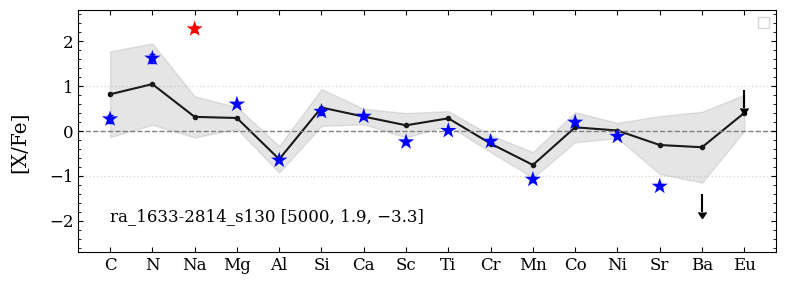

In [ ]:
# mean_lit_abunds = [cI_lit_abund['abund'].mean(), nI_lit_abund['abund'].mean(), naI_lit_abund['abund'].mean(),
#                     mgI_lit_abund['abund'].mean(), alI_lit_abund['abund'].mean(), siI_lit_abund['abund'].mean(),
#                     caI_lit_abund['abund'].mean(), scII_lit_abund['abund'].mean(), tiII_lit_abund['abund'].mean(),
#                     crI_lit_abund['abund'].mean(), mnI_lit_abund['abund'].mean(), coI_lit_abund['abund'].mean(),
#                     niI_lit_abund['abund'].mean(), srII_lit_abund['abund'].mean(), baII_lit_abund['abund'].mean(),
#                     euII_lit_abund['abund'].mean()]

smss_j2158 = [0.38, np.nan, 1.75, 0.42, -1.0, 0.90, 0.48, -0.19, 0.39, -0.46, -0.75, 0.33, -0.13, -0.56, -0.97, 0.39]
lmc_star = [0.63, 1.70, 1.25, 0.43, -0.10, 0.17, 0.30, 0.22, 0.50, -0.33, -0.84, 0.32, -0.1, -0.59, -0.7, 0.15]

fig, axs = plt.subplots(1, 1, figsize=[8, 3], tight_layout=True, sharex=True, sharey=True, gridspec_kw={'wspace': 0, 'hspace': 0})
fig.subplots_adjust(wspace=0.25)
# fig.supxlabel('[Fe/H]')
fig.supylabel('[X/Fe]')

    # mg_I_abund, 
    # al_I_abund, 
    # si_I_abund,
    # ca_II_abund, 
    # sc_II_abund, 
    # ti_II_abund, 
    # cr_I_abund, 
    # mn_I_abund,
    # co_I_abund, 
    # ni_I_abund, 
    # sr_II_abund, 
    # ba_II_abund, 
    # eu_II_abund

na_star_abund = [
    c_I_abunds[c_I_abunds['star_id'] == 'ra_1633-2814_s130'], 
    n_I_abunds[n_I_abunds['star_id'] == 'ra_1633-2814_s130'], 
    na_I_abunds[na_I_abunds['star_id'] == 'ra_1633-2814_s130'], 
    mg_I_abunds[mg_I_abunds['star_id'] == 'ra_1633-2814_s130'], 
    al_I_abunds[al_I_abunds['star_id'] == 'ra_1633-2814_s130'], 
    si_I_abunds[si_I_abunds['star_id'] == 'ra_1633-2814_s130'],
    ca_II_abunds[ca_II_abunds['star_id'] == 'ra_1633-2814_s130'], 
    sc_II_abunds[sc_II_abunds['star_id'] == 'ra_1633-2814_s130'], 
    ti_II_abunds[ti_II_abunds['star_id'] == 'ra_1633-2814_s130'], 
    cr_I_abunds[cr_I_abunds['star_id'] == 'ra_1633-2814_s130'], 
    mn_I_abunds[mn_I_abunds['star_id'] == 'ra_1633-2814_s130'],
    co_I_abunds[co_I_abunds['star_id'] == 'ra_1633-2814_s130'], 
    ni_I_abunds[ni_I_abunds['star_id'] == 'ra_1633-2814_s130'], 
    sr_II_abunds[sr_II_abunds['star_id'] == 'ra_1633-2814_s130'], 
    ba_II_abunds[ba_II_abunds['star_id'] == 'ra_1633-2814_s130'], 
    eu_II_abunds[eu_II_abunds['star_id'] == 'ra_1633-2814_s130']
]
 
 
star = 'ra_1633-2814_s130'
    
# Plotting the mean abundances from the literature
axs.plot(el_list, mean_lit_abunds, color='black', zorder=-1, marker='.')
axs.fill_between(el_list, np.array(mean_lit_abunds) - np.array(std_lit_abunds), 
                np.array(mean_lit_abunds) + np.array(std_lit_abunds), color='grey', alpha=0.2, zorder=-1)
# axs.scatter(el_list, smss_j2158, color='purple', marker='*', s=150, zorder=3, edgecolor='black', alpha=0.6,
#             label='SMSS J215805.81–651327.2\n[4783, 1.55, -3.41]')
# axs.scatter(el_list, lmc_star, color='darkorange', marker='*', s=150, zorder=3, edgecolor='black', alpha=0.6,
#             label='SMSS 497519424\n[4500, 1.11, -3.13]')


# Getting the entries for the star
star_data = stars_upperlimits[stars_upperlimits['star_id'] == star]

# Stellar parameters
star_teff = params_rounded[params_rounded['star_id'] == star]['teff'].to_numpy()[0]
star_logg = params_rounded[params_rounded['star_id'] == star]['logg'].to_numpy()[0]
star_feh = params_rounded[params_rounded['star_id'] == star]['feh'].to_numpy()[0]

# Separating star data by element, then storing into list
al_I_abund = al_I_abunds[al_I_abunds['star_id'] == star]
ba_II_abund = ba_II_abunds[ba_II_abunds['star_id'] == star]
c_I_abund = c_I_abunds[c_I_abunds['star_id'] == star]
ca_II_abund = ca_II_abunds[ca_II_abunds['star_id'] == star]
co_I_abund = co_I_abunds[co_I_abunds['star_id'] == star]
cr_I_abund = cr_I_abunds[cr_I_abunds['star_id'] == star]
eu_II_abund = eu_II_abunds[eu_II_abunds['star_id'] == star]
mg_I_abund = mg_I_abunds[mg_I_abunds['star_id'] == star]
mn_I_abund = mn_I_abunds[mn_I_abunds['star_id'] == star]
n_I_abund = n_I_abunds[n_I_abunds['star_id'] == star]
na_I_abund = na_I_abunds[na_I_abunds['star_id'] == star]
ni_I_abund = ni_I_abunds[ni_I_abunds['star_id'] == star]
sc_II_abund = sc_II_abunds[sc_II_abunds['star_id'] == star]
si_I_abund = si_I_abunds[si_I_abunds['star_id'] == star]
sr_II_abund = sr_II_abunds[sr_II_abunds['star_id'] == star]
ti_II_abund = ti_II_abunds[ti_II_abunds['star_id'] == star]
# ba_II_abund = star_data[star_data['el'] == 'Ba_II']
# c_I_abund = star_data[(star_data['el'] == 'C_I') & (star_data['teff'] < 5300)]
# ca_II_abund = star_data[star_data['el'] == 'Ca_II']
# co_I_abund = star_data[star_data['el'] == 'Co_I']
# cr_I_abund = star_data[star_data['el'] == 'Cr_I']
# eu_II_abund = star_data[star_data['el'] == 'Eu_II']
# mg_I_abund = star_data[star_data['el'] == 'Mg_I']
# mn_I_abund = star_data[star_data['el'] == 'Mn_I']
# n_I_abund = star_data[(star_data['el'] == 'N_I') & (star_data['teff'] < 5300)]
# na_I_abund = star_data[(star_data['el'] == 'Na_I') & (~star_data['star_id'].isin(bad_na_stars))]
# ni_I_abund = star_data[star_data['el'] == 'Ni_I']
# sc_II_abund = star_data[star_data['el'] == 'Sc_II']
# si_I_abund = star_data[star_data['el'] == 'Si_I']
# sr_II_abund = star_data[star_data['el'] == 'Sr_II']
# ti_II_abund = star_data[star_data['el'] == 'Ti_II']

# # For star ra_1656-1433_s143, change [C/Fe] abundance to first iteration (instead of second iteration)
# if star == 'ra_1656-1433_s143':
#     c_I_abunds['bestfit_abund_comberr_xfe'] = c_I_abunds['bestfit_abund_tefferr_xfe']
    
# if star == 'ra_1752-4300_s6':
#     c_I_abunds['bestfit_abund_comberr_xfe'] = c_I_abunds['bestfit_abund_tefferr_xfe']
        
star_abund = [
    c_I_abund, n_I_abund, na_I_abund, mg_I_abund, al_I_abund, si_I_abund,
    ca_II_abund, sc_II_abund, ti_II_abund, cr_I_abund, mn_I_abund,
    co_I_abund, ni_I_abund, sr_II_abund, ba_II_abund, eu_II_abund
]
    
# Plotting each element
# - If detection is 'Y', plot the abundance with error bars
# - If detection is 'N', plot the upper limit 
abunds = [] # This contains both detections and upper limits for the star - for connecting line
el_names = []
for i, el_abund in enumerate(star_abund):
    detection = el_abund['detection'].to_numpy()
    
    
    if detection == 'Y':
        el = el_list[i]
        abund_val = el_abund['bestfit_abund_xfe'].to_numpy()
        abund_val_err = el_abund['bestfit_abund_comberr_xfe'].to_numpy()[0]
        
        # If the abundance value is empty, skip to the next element
        if len(abund_val) == 0:
            continue
        else:
            abunds.append(abund_val[0])
            el_names.append(el)
            
        
        # Computing the difference between the abundance value and the mean literature abundance.
        ith_lit_abund = mean_lit_abunds[i]
        ith_lit_std = std_lit_abunds[i]
        obs_lit_diff = abs(abund_val[0] - ith_lit_abund)
        
        # Seeing if the abundance value is within 2 sigma of the literature value
        lower_bound = ith_lit_abund - 2 * ith_lit_std
        upper_bound = ith_lit_abund + 2 * ith_lit_std

        if lower_bound <= abund_val <= upper_bound:
            abund_color = 'blue'
        else:
            abund_color = 'red'
                    
        # if obs_lit_diff > 0.5:
        #     abund_color = 'red'
        # else:
        #     abund_color = 'blue'
        
        axs.scatter(el, abund_val, color=abund_color, marker='*', s=150, edgecolor='none', zorder=3)
        axs.errorbar(x=el, y=abund_val, yerr=abund_val_err, color=abund_color, alpha=1, zorder=1, linestyle='')
        
    elif detection == 'N':
        
        el = el_list[i]
        abund_ul = el_abund['upper_limit_xfe'].to_numpy()
        abund_val = el_abund['bestfit_abund_xfe'].to_numpy()
        
        # If the abundance value is empty, skip to the next element
        if len(abund_val) == 0:
            continue
        else:
            abunds.append(abund_ul[0])
            el_names.append(el)      
        
        # If the upper limit is greater than 2sigma from the literature value, plot it in red
        ith_lit_abund = mean_lit_abunds[i]
        ith_lit_std = std_lit_abunds[i]
        obs_lit_diff = abs(abund_ul[0] - ith_lit_abund)
        lower_bound = ith_lit_abund - 2 * ith_lit_std
        upper_bound = ith_lit_abund + 2 * ith_lit_std
        
        if abund_ul < lower_bound:
            abund_color = 'red'
        else:
            abund_color = 'black'
            
        
        # ax.scatter(el, abund_ul, color=abund_color, zorder=5, 
        # marker='${↧}$', s=150, linewidths=0.1, edgecolor='black')
        
        ul_ysize = 0.4
        axs.errorbar(el, abund_ul, yerr=ul_ysize, uplims=True, fmt='none', capsize=0, zorder=1, color=abund_color)

        

# Pllotting horizontal lines
axs.axhline(y=0, color='grey', linestyle='--', linewidth=1, zorder=0)
axs.axhline(y=-1, color='grey', linestyle=':', linewidth=1, zorder=0, alpha=0.3)
axs.axhline(y=1, color='grey', linestyle=':', linewidth=1, zorder=0, alpha=0.3)

if star == 'ra_1633-2814_s130':
    axs.text(s = f"{star} [{star_teff}, {star_logg}, {star_feh}]", y = -2, x = el_list[0], fontsize=12, color='black')
else:
    axs.text(s = f"{star} [{star_teff}, {star_logg}, {star_feh}]", y = 2, x = el_list[0], fontsize=12, color='black')

# Plotting the connecting line between the abundances
# ax.plot(el_names, abunds, linestyle='-', color='black', alpha=0.5)


axs.set_ylim(-2.7, 2.7)
axs.xaxis.set_minor_locator(plt.NullLocator())

plt.legend(fancybox=False, loc='upper right', fontsize=10)
# display(na_I_abunds)

plt.savefig("/data/misfit/benlowe/xshooter/p113/results/star_abunds/abunds_trend_ra1633.pdf", dpi=300, transparent=False, facecolor="white")
plt.savefig("/data/misfit/benlowe/xshooter/p113/results/star_abunds/abunds_trend_ra1633.png", dpi=300, transparent=False, facecolor="white")

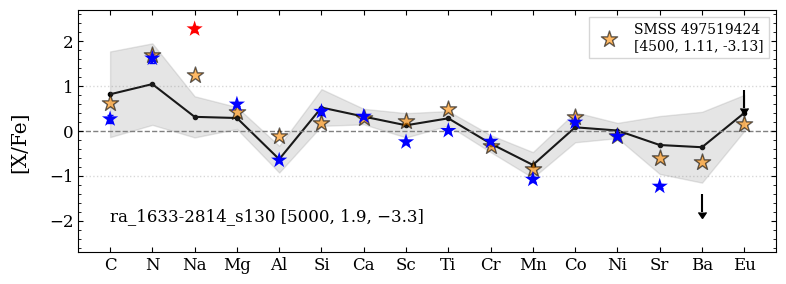

In [ ]:
# mean_lit_abunds = [cI_lit_abund['abund'].mean(), nI_lit_abund['abund'].mean(), naI_lit_abund['abund'].mean(),
#                     mgI_lit_abund['abund'].mean(), alI_lit_abund['abund'].mean(), siI_lit_abund['abund'].mean(),
#                     caI_lit_abund['abund'].mean(), scII_lit_abund['abund'].mean(), tiII_lit_abund['abund'].mean(),
#                     crI_lit_abund['abund'].mean(), mnI_lit_abund['abund'].mean(), coI_lit_abund['abund'].mean(),
#                     niI_lit_abund['abund'].mean(), srII_lit_abund['abund'].mean(), baII_lit_abund['abund'].mean(),
#                     euII_lit_abund['abund'].mean()]

lmc_star = [0.63, 1.70, 1.25, 0.43, -0.10, 0.17, 0.30, 0.22, 0.50, -0.33, -0.84, 0.32, -0.1, -0.59, -0.7, 0.15]
# lmc_star_errs = []

fig, axs = plt.subplots(1, 1, figsize=[8, 3], tight_layout=True, sharex=True, sharey=True, gridspec_kw={'wspace': 0, 'hspace': 0})
fig.subplots_adjust(wspace=0.25)
# fig.supxlabel('[Fe/H]')
fig.supylabel('[X/Fe]')

    # mg_I_abund, 
    # al_I_abund, 
    # si_I_abund,
    # ca_II_abund, 
    # sc_II_abund, 
    # ti_II_abund, 
    # cr_I_abund, 
    # mn_I_abund,
    # co_I_abund, 
    # ni_I_abund, 
    # sr_II_abund, 
    # ba_II_abund, 
    # eu_II_abund

na_star_abund = [
    c_I_abunds[c_I_abunds['star_id'] == 'ra_1633-2814_s130'], 
    n_I_abunds[n_I_abunds['star_id'] == 'ra_1633-2814_s130'], 
    na_I_abunds[na_I_abunds['star_id'] == 'ra_1633-2814_s130'], 
    mg_I_abunds[mg_I_abunds['star_id'] == 'ra_1633-2814_s130'], 
    al_I_abunds[al_I_abunds['star_id'] == 'ra_1633-2814_s130'], 
    si_I_abunds[si_I_abunds['star_id'] == 'ra_1633-2814_s130'],
    ca_II_abunds[ca_II_abunds['star_id'] == 'ra_1633-2814_s130'], 
    sc_II_abunds[sc_II_abunds['star_id'] == 'ra_1633-2814_s130'], 
    ti_II_abunds[ti_II_abunds['star_id'] == 'ra_1633-2814_s130'], 
    cr_I_abunds[cr_I_abunds['star_id'] == 'ra_1633-2814_s130'], 
    mn_I_abunds[mn_I_abunds['star_id'] == 'ra_1633-2814_s130'],
    co_I_abunds[co_I_abunds['star_id'] == 'ra_1633-2814_s130'], 
    ni_I_abunds[ni_I_abunds['star_id'] == 'ra_1633-2814_s130'], 
    sr_II_abunds[sr_II_abunds['star_id'] == 'ra_1633-2814_s130'], 
    ba_II_abunds[ba_II_abunds['star_id'] == 'ra_1633-2814_s130'], 
    eu_II_abunds[eu_II_abunds['star_id'] == 'ra_1633-2814_s130']
]
 
 
star = 'ra_1633-2814_s130'
    
# Plotting the mean abundances from the literature
axs.plot(el_list, mean_lit_abunds, color='black', zorder=-1, marker='.')
axs.fill_between(el_list, np.array(mean_lit_abunds) - np.array(std_lit_abunds), 
                np.array(mean_lit_abunds) + np.array(std_lit_abunds), color='grey', alpha=0.2, zorder=-1)
axs.scatter(el_list, lmc_star, color='darkorange', marker='*', s=150, zorder=3, edgecolor='black', alpha=0.6,
            label='SMSS 497519424\n[4500, 1.11, -3.13]')

# Getting the entries for the star
star_data = stars_upperlimits[stars_upperlimits['star_id'] == star]

# Stellar parameters
star_teff = params_rounded[params_rounded['star_id'] == star]['teff'].to_numpy()[0]
star_logg = params_rounded[params_rounded['star_id'] == star]['logg'].to_numpy()[0]
star_feh = params_rounded[params_rounded['star_id'] == star]['feh'].to_numpy()[0]

# Separating star data by element, then storing into list
al_I_abund = al_I_abunds[al_I_abunds['star_id'] == star]
ba_II_abund = ba_II_abunds[ba_II_abunds['star_id'] == star]
c_I_abund = c_I_abunds[c_I_abunds['star_id'] == star]
ca_II_abund = ca_II_abunds[ca_II_abunds['star_id'] == star]
co_I_abund = co_I_abunds[co_I_abunds['star_id'] == star]
cr_I_abund = cr_I_abunds[cr_I_abunds['star_id'] == star]
eu_II_abund = eu_II_abunds[eu_II_abunds['star_id'] == star]
mg_I_abund = mg_I_abunds[mg_I_abunds['star_id'] == star]
mn_I_abund = mn_I_abunds[mn_I_abunds['star_id'] == star]
n_I_abund = n_I_abunds[n_I_abunds['star_id'] == star]
na_I_abund = na_I_abunds[na_I_abunds['star_id'] == star]
ni_I_abund = ni_I_abunds[ni_I_abunds['star_id'] == star]
sc_II_abund = sc_II_abunds[sc_II_abunds['star_id'] == star]
si_I_abund = si_I_abunds[si_I_abunds['star_id'] == star]
sr_II_abund = sr_II_abunds[sr_II_abunds['star_id'] == star]
ti_II_abund = ti_II_abunds[ti_II_abunds['star_id'] == star]
# ba_II_abund = star_data[star_data['el'] == 'Ba_II']
# c_I_abund = star_data[(star_data['el'] == 'C_I') & (star_data['teff'] < 5300)]
# ca_II_abund = star_data[star_data['el'] == 'Ca_II']
# co_I_abund = star_data[star_data['el'] == 'Co_I']
# cr_I_abund = star_data[star_data['el'] == 'Cr_I']
# eu_II_abund = star_data[star_data['el'] == 'Eu_II']
# mg_I_abund = star_data[star_data['el'] == 'Mg_I']
# mn_I_abund = star_data[star_data['el'] == 'Mn_I']
# n_I_abund = star_data[(star_data['el'] == 'N_I') & (star_data['teff'] < 5300)]
# na_I_abund = star_data[(star_data['el'] == 'Na_I') & (~star_data['star_id'].isin(bad_na_stars))]
# ni_I_abund = star_data[star_data['el'] == 'Ni_I']
# sc_II_abund = star_data[star_data['el'] == 'Sc_II']
# si_I_abund = star_data[star_data['el'] == 'Si_I']
# sr_II_abund = star_data[star_data['el'] == 'Sr_II']
# ti_II_abund = star_data[star_data['el'] == 'Ti_II']

# # For star ra_1656-1433_s143, change [C/Fe] abundance to first iteration (instead of second iteration)
# if star == 'ra_1656-1433_s143':
#     c_I_abunds['bestfit_abund_comberr_xfe'] = c_I_abunds['bestfit_abund_tefferr_xfe']
    
# if star == 'ra_1752-4300_s6':
#     c_I_abunds['bestfit_abund_comberr_xfe'] = c_I_abunds['bestfit_abund_tefferr_xfe']
        
star_abund = [
    c_I_abund, n_I_abund, na_I_abund, mg_I_abund, al_I_abund, si_I_abund,
    ca_II_abund, sc_II_abund, ti_II_abund, cr_I_abund, mn_I_abund,
    co_I_abund, ni_I_abund, sr_II_abund, ba_II_abund, eu_II_abund
]
    
# Plotting each element
# - If detection is 'Y', plot the abundance with error bars
# - If detection is 'N', plot the upper limit 
abunds = [] # This contains both detections and upper limits for the star - for connecting line
el_names = []
for i, el_abund in enumerate(star_abund):
    detection = el_abund['detection'].to_numpy()
    
    
    if detection == 'Y':
        el = el_list[i]
        abund_val = el_abund['bestfit_abund_xfe'].to_numpy()
        abund_val_err = el_abund['bestfit_abund_comberr_xfe'].to_numpy()[0]
        
        # If the abundance value is empty, skip to the next element
        if len(abund_val) == 0:
            continue
        else:
            abunds.append(abund_val[0])
            el_names.append(el)
            
        
        # Computing the difference between the abundance value and the mean literature abundance.
        ith_lit_abund = mean_lit_abunds[i]
        ith_lit_std = std_lit_abunds[i]
        obs_lit_diff = abs(abund_val[0] - ith_lit_abund)
        
        # Seeing if the abundance value is within 2 sigma of the literature value
        lower_bound = ith_lit_abund - 2 * ith_lit_std
        upper_bound = ith_lit_abund + 2 * ith_lit_std

        if lower_bound <= abund_val <= upper_bound:
            abund_color = 'blue'
        else:
            abund_color = 'red'
                    
        # if obs_lit_diff > 0.5:
        #     abund_color = 'red'
        # else:
        #     abund_color = 'blue'
        
        axs.scatter(el, abund_val, color=abund_color, marker='*', s=150, edgecolor='none', zorder=3)
        axs.errorbar(x=el, y=abund_val, yerr=abund_val_err, color=abund_color, alpha=1, zorder=1, linestyle='')
        
    elif detection == 'N':
        
        el = el_list[i]
        abund_ul = el_abund['upper_limit_xfe'].to_numpy()
        abund_val = el_abund['bestfit_abund_xfe'].to_numpy()
        
        # If the abundance value is empty, skip to the next element
        if len(abund_val) == 0:
            continue
        else:
            abunds.append(abund_ul[0])
            el_names.append(el)      
        
        # If the upper limit is greater than 2sigma from the literature value, plot it in red
        ith_lit_abund = mean_lit_abunds[i]
        ith_lit_std = std_lit_abunds[i]
        obs_lit_diff = abs(abund_ul[0] - ith_lit_abund)
        lower_bound = ith_lit_abund - 2 * ith_lit_std
        upper_bound = ith_lit_abund + 2 * ith_lit_std
        
        if abund_ul < lower_bound:
            abund_color = 'red'
        else:
            abund_color = 'black'
        
        # ax.scatter(el, abund_ul, color=abund_color, zorder=5, 
        # marker='${↧}$', s=150, linewidths=0.1, edgecolor='black')
        
        ul_ysize = 0.4
        axs.errorbar(el, abund_ul, yerr=ul_ysize, uplims=True, fmt='none', capsize=0, zorder=1, color=abund_color)

        

# Pllotting horizontal lines
axs.axhline(y=0, color='grey', linestyle='--', linewidth=1, zorder=0)
axs.axhline(y=-1, color='grey', linestyle=':', linewidth=1, zorder=0, alpha=0.3)
axs.axhline(y=1, color='grey', linestyle=':', linewidth=1, zorder=0, alpha=0.3)

if star == 'ra_1633-2814_s130':
    axs.text(s = f"{star} [{star_teff}, {star_logg}, {star_feh}]", y = -2, x = el_list[0], fontsize=12, color='black')
else:
    axs.text(s = f"{star} [{star_teff}, {star_logg}, {star_feh}]", y = 2, x = el_list[0], fontsize=12, color='black')

# Plotting the connecting line between the abundances
# ax.plot(el_names, abunds, linestyle='-', color='black', alpha=0.5)


axs.set_ylim(-2.7, 2.7)
axs.xaxis.set_minor_locator(plt.NullLocator())

plt.legend(fancybox=False, loc='upper right', fontsize=10)
# display(na_I_abunds)

plt.savefig("/data/misfit/benlowe/xshooter/p113/results/star_abunds/abunds_trend_na_enhanced_lmc.pdf", dpi=300, transparent=False, facecolor="white")
plt.savefig("/data/misfit/benlowe/xshooter/p113/results/star_abunds/abunds_trend_na_enhanced_lmc.png", dpi=300, transparent=False, facecolor="white")

## Looking at [C/Fe] vs [N/Fe]

# Making plots (FOR PAPER III)

In [3]:
# Loading in the P113 and P115 data for all elements
al_abunds_df = pd.read_csv("/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Al_I_allabunds.csv")
ba_abunds_df = pd.read_csv("/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Ba_II_allabunds.csv")
c_abunds_df = pd.read_csv("/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/C_I_allabunds.csv")
ca_abunds_df = pd.read_csv("/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Ca_II_allabunds.csv")
co_abunds_df = pd.read_csv("/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Co_I_allabunds.csv")
cr_abunds_df = pd.read_csv("/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Cr_I_allabunds.csv")
eu_abunds_df = pd.read_csv("/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Eu_II_allabunds.csv")
mg_abunds_df = pd.read_csv("/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Mg_I_allabunds.csv")
mn_abunds_df = pd.read_csv("/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Mn_I_allabunds.csv")
n_abunds_df = pd.read_csv("/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/N_I_allabunds.csv")
na_abunds_df = pd.read_csv("/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Na_I_allabunds.csv")
ni_abunds_df = pd.read_csv("/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Ni_I_allabunds.csv")
sc_abunds_df = pd.read_csv("/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Sc_II_allabunds.csv")
si_abunds_df = pd.read_csv("/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Si_I_allabunds.csv")
sr_abunds_df = pd.read_csv("/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Sr_II_allabunds.csv")
ti_abunds_df = pd.read_csv("/data/misfit/benlowe/xshooter/p115/korg_data/all_abunds/Ti_II_allabunds.csv")

## [Fe/H] vs [X/Fe] plot

/tmp/ipykernel_3343407/3578015462.py:45: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  abund_p115_df['bestfit_abund_xfe'] = abund_p115_df['bestfit_abund_xfe'] + abund_p115_df['cfe_corr']


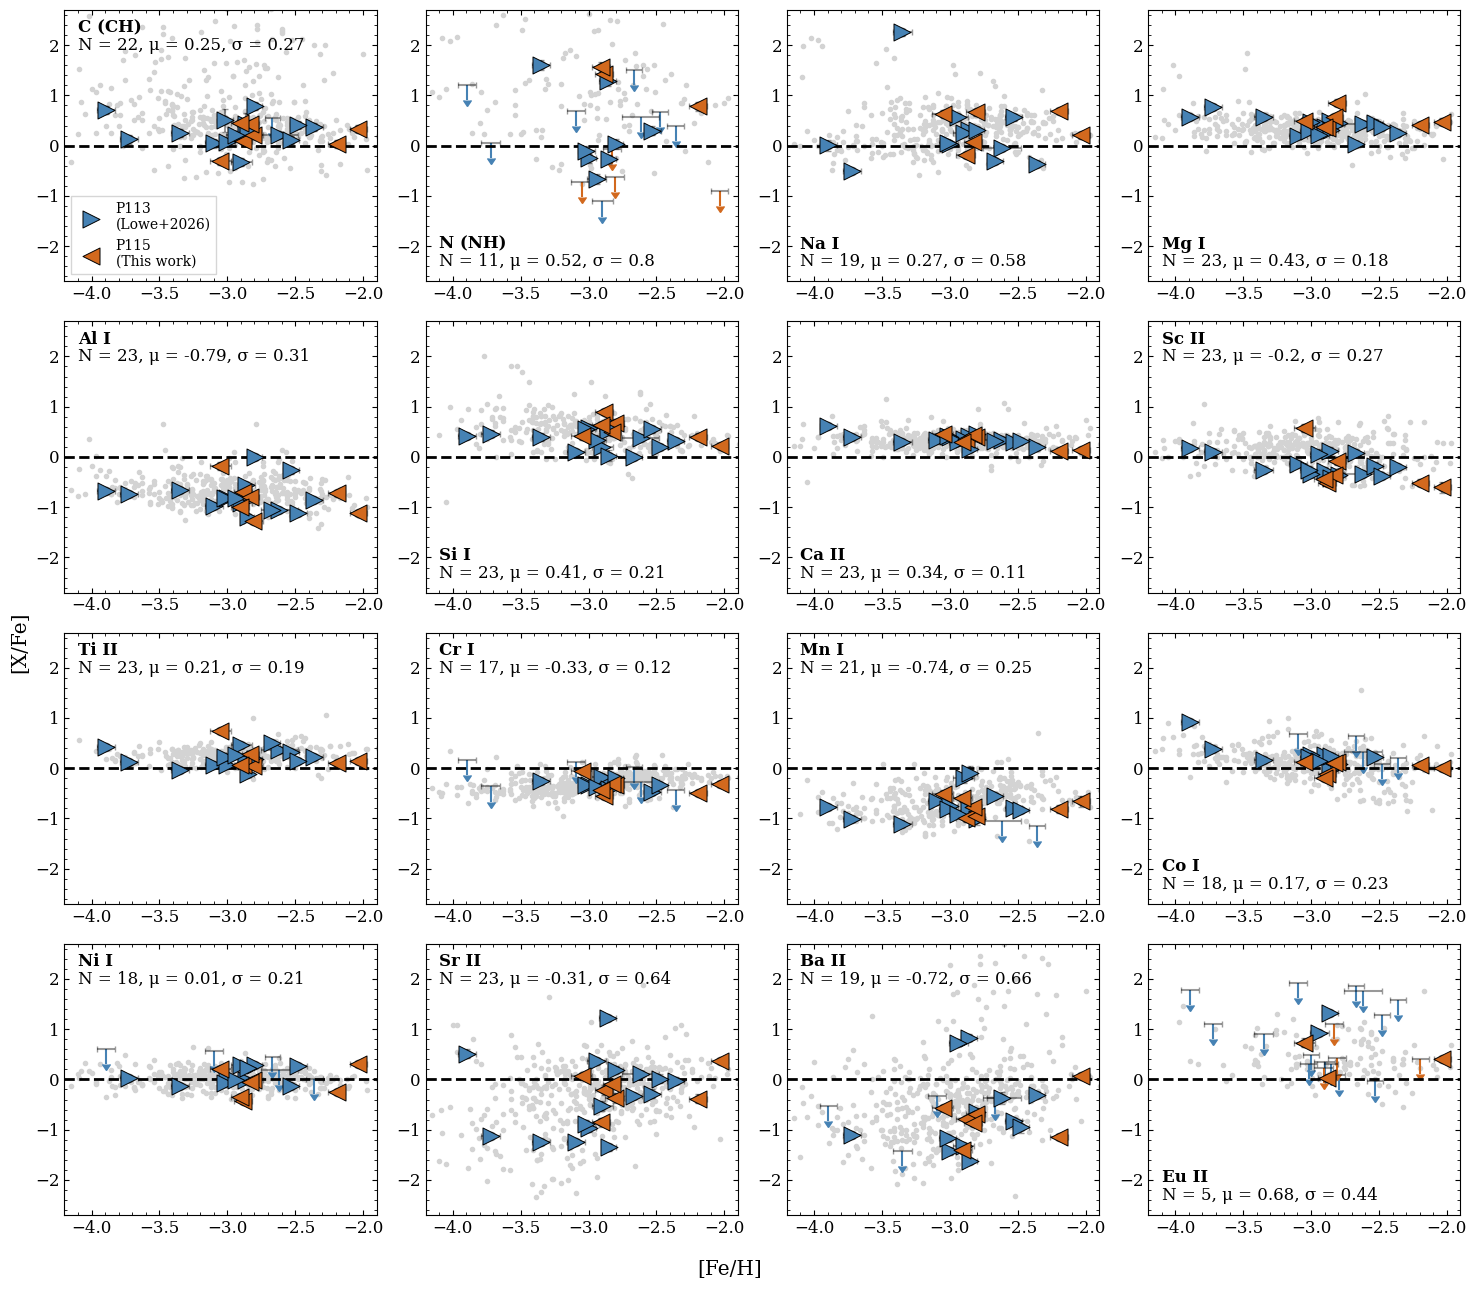

In [14]:
# Storing all abundance dataframes (both observed and literature) into lists
# NOTE: make sure that the order of the elements in el_list matches the order of the abundance dataframes in all_abunds and all_lit_abunds
el_list = ['C (CH)', 'N (NH)', 'Na I', 'Mg I', 'Al I', 'Si I', 'Ca II', 'Sc II',
           'Ti II', 'Cr I', 'Mn I', 'Co I', 'Ni I', 'Sr II', 'Ba II', 'Eu II']
# all_abunds = [c_I_abunds, n_I_abunds, na_I_abunds, mg_I_abunds, al_I_abunds, si_I_abunds, ca_II_abunds, sc_II_abunds,
#             ti_II_abunds, cr_I_abunds, mn_I_abunds, co_I_abunds, ni_I_abunds, sr_II_abunds, ba_II_abunds, eu_II_abunds]
all_p113_abunds = [c_abunds_df[c_abunds_df['p#'] == 'p113'], n_abunds_df[n_abunds_df['p#'] == 'p113'], na_abunds_df[na_abunds_df['p#'] == 'p113'], mg_abunds_df[mg_abunds_df['p#'] == 'p113'], 
                   al_abunds_df[al_abunds_df['p#'] == 'p113'], si_abunds_df[si_abunds_df['p#'] == 'p113'], ca_abunds_df[ca_abunds_df['p#'] == 'p113'], sc_abunds_df[sc_abunds_df['p#'] == 'p113'],
                   ti_abunds_df[ti_abunds_df['p#'] == 'p113'], cr_abunds_df[cr_abunds_df['p#'] == 'p113'], mn_abunds_df[mn_abunds_df['p#'] == 'p113'], co_abunds_df[co_abunds_df['p#'] == 'p113'], 
                   ni_abunds_df[ni_abunds_df['p#'] == 'p113'], sr_abunds_df[sr_abunds_df['p#'] == 'p113'], ba_abunds_df[ba_abunds_df['p#'] == 'p113'], eu_abunds_df[eu_abunds_df['p#'] == 'p113']]
all_p115_abunds = [c_abunds_df[c_abunds_df['p#'] == 'p115'], n_abunds_df[n_abunds_df['p#'] == 'p115'], na_abunds_df[na_abunds_df['p#'] == 'p115'], mg_abunds_df[mg_abunds_df['p#'] == 'p115'], 
                   al_abunds_df[al_abunds_df['p#'] == 'p115'], si_abunds_df[si_abunds_df['p#'] == 'p115'], ca_abunds_df[ca_abunds_df['p#'] == 'p115'], sc_abunds_df[sc_abunds_df['p#'] == 'p115'],
                   ti_abunds_df[ti_abunds_df['p#'] == 'p115'], cr_abunds_df[cr_abunds_df['p#'] == 'p115'], mn_abunds_df[mn_abunds_df['p#'] == 'p115'], co_abunds_df[co_abunds_df['p#'] == 'p115'], 
                   ni_abunds_df[ni_abunds_df['p#'] == 'p115'], sr_abunds_df[sr_abunds_df['p#'] == 'p115'], ba_abunds_df[ba_abunds_df['p#'] == 'p115'], eu_abunds_df[eu_abunds_df['p#'] == 'p115']]

all_lit_abunds = [cI_lit_abund, nI_lit_abund, naI_lit_abund, mgI_lit_abund, alI_lit_abund, siI_lit_abund, caI_lit_abund,
                  scII_lit_abund, tiII_lit_abund, crI_lit_abund, mnI_lit_abund, coI_lit_abund, niI_lit_abund, 
                  srII_lit_abund, baII_lit_abund, euII_lit_abund]
# all_feh = pd.read_csv('/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter9/stellar_params.csv')


fig, axs = plt.subplots(4, 4, figsize=[15,13], tight_layout=True)
fig.subplots_adjust(wspace=0.25)
fig.supxlabel('[Fe/H]')
fig.supylabel('[X/Fe]')


for ax, el in zip(axs.flat, el_list):

    # Getting index of element
    el_index = el_list.index(el)
    
    # Getting the abundance data for the element
    # P113 data
    abund_p113_df = all_p113_abunds[el_index]
    
    abund_p113_detect = abund_p113_df[abund_p113_df['detection'] == 'Y']    
    abund_p113_nondetect = abund_p113_df[abund_p113_df['detection'] == 'N']
    
    # P115 data
    abund_p115_df = all_p115_abunds[el_index]
    
    # For P115 data, C abundances are raw, so need to apply corrections
    if el == 'C (CH)':
        abund_p115_df['bestfit_abund_xfe'] = abund_p115_df['bestfit_abund_xfe'] + abund_p115_df['cfe_corr']
    
    abund_p115_detect = abund_p115_df[abund_p115_df['detection'] == 'Y']    
    abund_p115_nondetect = abund_p115_df[abund_p115_df['detection'] == 'N']    
    
    # Getting the literature data for the element
    lit_abund_df = all_lit_abunds[el_index]
    
    
    # ---PLOTTING--- #
    # Plotting literature data
    ax.scatter(lit_abund_df['feh'], lit_abund_df['abund'], c="lightgrey", marker='.', zorder=1)
    
    
    # Plotting the X-Shooter data
    
    # Plotting observed data (detections)
    ax.scatter(abund_p113_detect['feh'], abund_p113_detect['bestfit_abund_xfe'], color='steelblue', label='P113\n(Lowe+2026)', 
                marker='>', s=150, edgecolor='black', zorder=10, linewidths=0.7)
    ax.errorbar(abund_p113_detect['feh'], abund_p113_detect['bestfit_abund_xfe'], xerr=abund_p113_detect['feh_err'],
                yerr=abund_p113_detect['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=9, alpha=0.4)
    ax.scatter(abund_p115_detect['feh'], abund_p115_detect['bestfit_abund_xfe'], color='chocolate', label='P115\n(This work)', 
                marker='<', s=150, edgecolor='black', zorder=10, linewidths=0.7)
    ax.errorbar(abund_p115_detect['feh'], abund_p115_detect['bestfit_abund_xfe'], xerr=abund_p115_detect['feh_err'],
                yerr=abund_p115_detect['bestfit_abund_comberr_xfe'], fmt='o', color='black', zorder=9, alpha=0.4)
    
    # Plotting observed data (non-detections)
    xerr = 0.1
    ul_ysize = 0.3

    ax.errorbar(abund_p113_nondetect['feh'], abund_p113_nondetect['upper_limit_xfe'], yerr=ul_ysize, uplims=True, fmt='none', capsize=0, zorder=1, color='steelblue')
    ax.errorbar(abund_p113_nondetect['feh'], abund_p113_nondetect['upper_limit_xfe'], xerr=abund_p113_nondetect['feh_err'], color='black', zorder=9, alpha=0.4, fmt='none')

    ax.errorbar(abund_p115_nondetect['feh'], abund_p115_nondetect['upper_limit_xfe'], yerr=ul_ysize, uplims=True, fmt='none', capsize=0, zorder=1, color='chocolate')
    ax.errorbar(abund_p115_nondetect['feh'], abund_p115_nondetect['upper_limit_xfe'], xerr=abund_p115_nondetect['feh_err'], color='black', zorder=9, alpha=0.4, fmt='none')
    

    ax.axhline(y=0, color='black', linestyle='--', linewidth=2, zorder=2)
    
    abund_comb_detect = pd.concat([abund_p113_detect, abund_p115_detect])
    if el == 'N (NH)' or el == 'Na I' or el == 'Mg I' or el == 'Si I' or el == 'Ca II' or el == 'Co I' or el == 'Eu II':
        ax.text(-4.1, -2.05, el, fontsize=12, fontweight='bold')
        ax.text(-4.1, -2.4, f"N = {len(abund_comb_detect)}, μ = {round(np.mean(abund_comb_detect['bestfit_abund_xfe']), 2)}, σ = {round(np.std(abund_comb_detect['bestfit_abund_xfe']), 2)}", fontsize=12)
    else:
        ax.text(-4.1, 2.25, el, fontsize=12, fontweight='bold')
        ax.text(-4.1, 1.9, f"N = {len(abund_comb_detect)}, μ = {round(np.mean(abund_comb_detect['bestfit_abund_xfe']), 2)}, σ = {round(np.std(abund_comb_detect['bestfit_abund_xfe']), 2)}", fontsize=12)

    
    ax.set_xlim(-4.2, -1.9)
    ax.set_ylim(-2.7, 2.7)
    
    # Putting the legend in the first subplot
    if el_index == 0:
        ax.legend(fancybox=False, loc='lower left', fontsize='small')
    

plt.tight_layout()
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/fe_xfe_updated_v6.pdf", dpi=300, transparent=False, facecolor="white")
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/abund_comparision/fe_xfe_updated_v6.png", dpi=300, transparent=False, facecolor="white")



## Looking at individual element scatter

### N-enhanced 

In [4]:
# Doing this for our stars
print("The following are N-enhanced:")
p113_list = []
p115_list = []
all_list = []

for entry in c_abunds_df.iterrows():
    if entry[1]['detection'] == 'Y':
        star_id = entry[1]['star_id']
        nfe_entry = n_abunds_df[n_abunds_df['star_id'] == star_id]
        p = entry[1]['p#']
        if nfe_entry['detection'].values[0] == 'Y':
            
            # Getting raw [C/Fe] value (don't need to apply corrections)
            cfe_vals = entry[1]['bestfit_abund_xfe']
            cfe_corrs = entry[1]['cfe_corr'] # Corrections
            cfe_vals_corr = entry[1]['bestfit_abund_xfe'] + entry[1]['cfe_corr'] # Corrected [C/Fe] value
            
            cfe_errs = entry[1]['bestfit_abund_comberr_xfe']
            nfe_vals = n_abunds_df[n_abunds_df['star_id'] == star_id]['bestfit_abund_xfe'].values[0]
            nfe_errs = n_abunds_df[n_abunds_df['star_id'] == star_id]['bestfit_abund_comberr_xfe'].values[0]
            feh_vals = entry[1]['feh']
            
            cn_vals = cfe_vals - nfe_vals
            cn_errs = np.sqrt(cfe_errs**2 + nfe_errs**2)
            
            if p == 'p113':
                p113_dict = {'star_id': star_id, 'detection': 'Y', 'cfe': cfe_vals, 'cfe_corrected': cfe_vals_corr, 'cfe_corrs': cfe_corrs, 'cfe_err': cfe_errs, 'nfe': nfe_vals, 'nfe_err': nfe_errs, 
                                'cn': cn_vals, 'cn_err': cn_errs, 'feh': feh_vals}
                p113_list.append(p113_dict)
            elif p == 'p115':
                p115_dict = {'star_id': star_id, 'detection': 'Y', 'cfe': cfe_vals, 'cfe_corrected': cfe_vals_corr, 'cfe_corrs': cfe_corrs, 'cfe_err': cfe_errs, 'nfe': nfe_vals, 'nfe_err': nfe_errs, 
                                'cn': cn_vals, 'cn_err': cn_errs, 'feh': feh_vals}
                p115_list.append(p115_dict)
            
            all_list.append({'star_id': star_id, 'detection': 'Y', 'cfe': cfe_vals, 'cfe_corrected': cfe_vals_corr, 'cfe_corrs': cfe_corrs, 'cfe_err': cfe_errs, 'nfe': nfe_vals, 'nfe_err': nfe_errs, 
                                'cn': cn_vals, 'cn_err': cn_errs, 'feh': feh_vals})
            
            if nfe_vals > 0.5 and cn_vals < -0.7:
                print(f"{star_id} ([N/Fe] = {nfe_vals:.2f} and [C/N] = {cn_vals:.2f})")

        if nfe_entry['detection'].values[0] == 'N':
            
            # Getting raw [C/Fe] value (don't need to apply corrections)
            cfe_vals = entry[1]['bestfit_abund_xfe']
            
            cfe_errs = entry[1]['bestfit_abund_comberr_xfe']
            nfe_vals = n_abunds_df[n_abunds_df['star_id'] == star_id]['upper_limit_xfe'].values[0]
            nfe_errs = np.nan
            feh_vals = entry[1]['feh']
            
            cn_vals = cfe_vals - nfe_vals
            cn_errs = np.nan
            
            if p == 'p113':
                p113_dict = {'star_id': star_id, 'detection': 'N', 'cfe': cfe_vals, 'cfe_corrected': np.nan, 'cfe_corrs': np.nan, 'cfe_err': cfe_errs, 'nfe': nfe_vals, 'nfe_err': nfe_errs, 
                                'cn': cn_vals, 'cn_err': cn_errs, 'feh': feh_vals}
                p113_list.append(p113_dict)
            elif p == 'p115':
                p115_dict = {'star_id': star_id, 'detection': 'N', 'cfe': cfe_vals, 'cfe_corrected': np.nan, 'cfe_corrs': np.nan, 'cfe_err': cfe_errs, 'nfe': nfe_vals, 'nfe_err': nfe_errs, 
                                'cn': cn_vals, 'cn_err': cn_errs, 'feh': feh_vals}
                p115_list.append(p115_dict)
            
            all_list.append({'star_id': star_id, 'detection': 'N', 'cfe': cfe_vals, 'cfe_corrected': np.nan, 'cfe_corrs': np.nan, 'cfe_err': cfe_errs, 'nfe': nfe_vals, 'nfe_err': nfe_errs, 
                                'cn': cn_vals, 'cn_err': cn_errs, 'feh': feh_vals})

                
                
p113_df = pd.DataFrame(p113_list)
p115_df = pd.DataFrame(p115_list)
all_df = pd.DataFrame(all_list)

# Separating the non-detections from the detections
p113_detect_df = p113_df[p113_df['detection'] == 'Y']
p115_detect_df = p115_df[p115_df['detection'] == 'Y']

p113_nondetect_df = p113_df[p113_df['detection'] == 'N']
p115_nondetect_df = p115_df[p115_df['detection'] == 'N']

# Doing this for literature stars
# nfe_lit_abund = nI_lit_abund['abund'].to_numpy()
# cfe_lit_abund = cI_lit_abund['abund'].to_numpy()
# cn_lit_abund = cfe_lit_abund - nfe_lit_abund
cn_lit_df = pd.DataFrame(columns=['star_id', 'cfe', 'cfe_err', 'nfe', 'nfe_err', 'cn', 'cn_err', 'feh'])
cn_lit_df = pd.merge(cI_lit_abund, nI_lit_abund, on='star_id', suffixes=('_cfe', '_nfe'))
cn_lit_df['abund_cn'] = cn_lit_df['abund_cfe'] - cn_lit_df['abund_nfe']

The following are N-enhanced:
ra_1633-2814_s130 ([N/Fe] = 1.60 and [C/N] = -1.34)
ra_1656-1433_s143 ([N/Fe] = 1.28 and [C/N] = -0.86)
ra_0103-7050_s236 ([N/Fe] = 1.42 and [C/N] = -2.08)
ra_1659-2154_s261 ([N/Fe] = 0.79 and [C/N] = -0.76)
ra_1752-4300_s155 ([N/Fe] = 1.56 and [C/N] = -1.62)


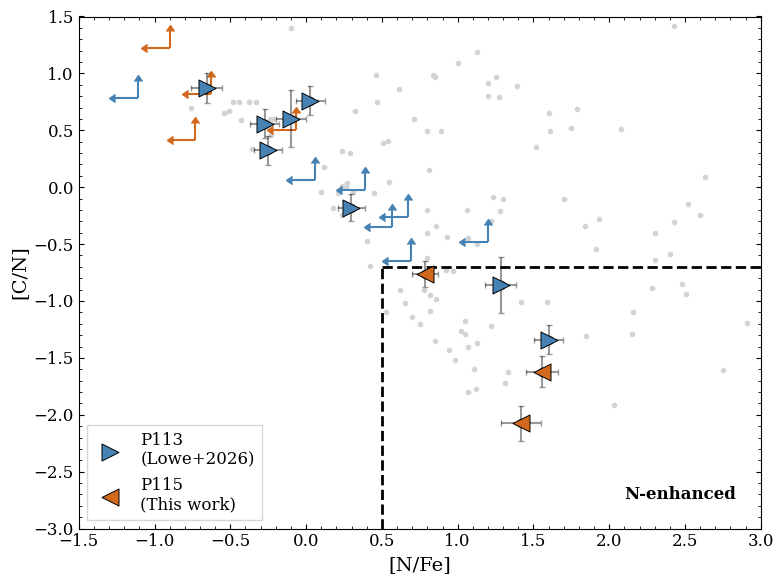

In [ ]:
plt.figure(figsize=[8,6])
plt.scatter(p113_detect_df['nfe'], p113_detect_df['cn'], color='steelblue', label='P113\n(Lowe+2026)', 
            marker='>', s=150, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(p113_detect_df['nfe'], p113_detect_df['cn'], xerr=p113_detect_df['nfe_err'],
             yerr=p113_detect_df['cn_err'], fmt='o', color='black', zorder=9, alpha=0.4)
plt.scatter(p115_detect_df['nfe'], p115_detect_df['cn'], color='chocolate', label='P115\n(This work)', 
            marker='<', s=150, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(p115_detect_df['nfe'], p115_detect_df['cn'], xerr=p115_detect_df['nfe_err'],
             yerr=p115_detect_df['cn_err'], fmt='o', color='black', zorder=9, alpha=0.4)
plt.scatter(cn_lit_df['abund_nfe'], cn_lit_df['abund_cn'], color='lightgrey', marker='.', zorder=1)
plt.hlines(y=-0.7, xmin=0.5, xmax=10, color='black', linestyle='--', linewidth=2)
plt.vlines(x=0.5, ymax = -0.7, ymin=-3, color='black', linestyle='--', linewidth=2)

# For upper-limits in [N/Fe] and lower-limits in [C/N]: plot left-facing arrow for [N/Fe] upper-limit, and up-facing arrow for [C/N] lower-limit
ul_ysize = 0.15
ul_xsize = 0.15

plt.errorbar(p113_nondetect_df['nfe'], p113_nondetect_df['cn'], xerr=ul_xsize, yerr=ul_ysize,
            xuplims=True, lolims=True, fmt='none', capsize=0, zorder=1, color='steelblue')
plt.errorbar(p115_nondetect_df['nfe'], p115_nondetect_df['cn'], xerr=ul_xsize, yerr=ul_ysize,
            xuplims=True, lolims=True, fmt='none', capsize=0, zorder=1, color='chocolate')

# plt.errorbar(prodisk_nondetect_df['nfe'], prodisk_nondetect_df['cn'], yerr=ul_ysize, xerr=ul_xsize,
#             uplims=True, lolims=True, fmt='none', capsize=3.5, zorder=1, color='limegreen')


# plt.scatter(halo_nondetect_df['nfe'], halo_nondetect_df['cn'], color='black', zorder=50, marker='.')
# plt.scatter(halo_nondetect_df['nfe'], halo_nondetect_df['cn'], color='orangered', zorder=5, 
#             marker='${↥}$', s=250, linewidths=0.1, edgecolor='black')
# plt.scatter(halo_nondetect_df['nfe'], halo_nondetect_df['cn'], color='orangered', zorder=7, 
#             marker='${↤}$', s=250, linewidths=0.1, edgecolor='black')
# plt.scatter(prodisk_nondetect_df['nfe'], prodisk_nondetect_df['cn'], color='black', zorder=50, marker='.')
# plt.scatter(prodisk_nondetect_df['nfe'], prodisk_nondetect_df['cn'], color='limegreen', zorder=5, 
#             marker='${↥}$', s=250, linewidths=0.1, edgecolor='black')
# plt.scatter(prodisk_nondetect_df['nfe'], prodisk_nondetect_df['cn'], color='limegreen', zorder=7, 
#             marker='${↤}$', s=250, linewidths=0.1, edgecolor='black')


# rectangle = plt.Rectangle((0.5, -0.7), 4, -2, facecolor='grey', alpha=0.1, zorder=-10)
# plt.gca().add_patch(rectangle)
plt.text(2.1, -2.7, 'N-enhanced', fontsize=12, color='black', ha='left', va='center', weight='bold')
plt.xlabel('[N/Fe]')
plt.ylabel('[C/N]')
plt.xlim(-1.5, 3)
plt.ylim(-3, 1.5)
plt.legend(fancybox=False)

plt.tight_layout()
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/star_abunds/c_n_enhanced_v2.pdf", dpi=300, transparent=False, facecolor="white")
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/star_abunds/c_n_enhanced_v2.png", dpi=300, transparent=False, facecolor="white")

In [13]:
p115_df

,star_id,detection,cfe,cfe_corrected,cfe_corrs,cfe_err,nfe,nfe_err,cn,cn_err,feh
0,ra_0103-7050_s236,Y,-0.657859,0.102141,0.76,0.077155,1.417207,0.131446,-2.075066,0.152417,-2.883631
1,ra_0752-5047_s47,N,-0.311717,NaN,NaN,0.074893,-0.730000,NaN,0.418283,NaN,-3.051738
2,ra_1639-2632_s419,N,0.323371,NaN,NaN,0.071697,-0.900000,NaN,1.223371,NaN,-2.034058
3,ra_1648-2642_s91,N,0.186928,NaN,NaN,0.081391,-0.630000,NaN,0.816928,NaN,-2.808558
4,ra_1659-2154_s261,Y,0.022261,0.032261,0.01,0.073582,0.785090,0.086674,-0.762829,0.113695,-2.194068
5,ra_1659-2154_s347,N,0.431171,NaN,NaN,0.076850,-0.070000,NaN,0.501171,NaN,-2.829687
6,ra_1752-4300_s155,Y,-0.063120,0.446880,0.51,0.080173,1.558061,0.107305,-1.621181,0.133948,-2.907340


In [15]:
# Making table for paper
cn_tab = p115_df[['star_id', 'cn', 'cn_err', 'nfe', 'nfe_err', 'cfe', 'cfe_err', 'detection']]

dict_list = []
for star in cn_tab.iterrows():
    
    detect = star[1]['detection']
    
    cfe_val = f"${star[1]['cfe']:.2f} \pm {star[1]['cfe_err']:.2f}$"
    if detect == 'Y':
        cn_val = f"${star[1]['cn']:.2f} \pm {star[1]['cn_err']:.2f}$"
        nfe_val = f"${star[1]['nfe']:.2f} \pm {star[1]['nfe_err']:.2f}$"
    else:
        cn_val = f"$>{star[1]['cn']:.2f}$"
        nfe_val = f"$<{star[1]['nfe']:.2f}$"    

    cn_dict = {'Star': star[1]['star_id'], '\XFe{C}': cfe_val, '\XFe{N}': nfe_val, '\XY{C}{N}': cn_val}
    dict_list.append(cn_dict)
    
cn_final_tab = pd.DataFrame(dict_list)
cn_final_tab.sort_values(by='Star', inplace=True)

print(cn_final_tab.to_latex(index=False))
display(cn_final_tab)


\begin{tabular}{llll}
\toprule
Star & \XFe{C} & \XFe{N} & \XY{C}{N} \\
\midrule
ra_0103-7050_s236 & $-0.66 \pm 0.08$ & $1.42 \pm 0.13$ & $-2.08 \pm 0.15$ \\
ra_0752-5047_s47 & $-0.31 \pm 0.07$ & $<-0.73$ & $>0.42$ \\
ra_1639-2632_s419 & $0.32 \pm 0.07$ & $<-0.90$ & $>1.22$ \\
ra_1648-2642_s91 & $0.19 \pm 0.08$ & $<-0.63$ & $>0.82$ \\
ra_1659-2154_s261 & $0.02 \pm 0.07$ & $0.79 \pm 0.09$ & $-0.76 \pm 0.11$ \\
ra_1659-2154_s347 & $0.43 \pm 0.08$ & $<-0.07$ & $>0.50$ \\
ra_1752-4300_s155 & $-0.06 \pm 0.08$ & $1.56 \pm 0.11$ & $-1.62 \pm 0.13$ \\
\bottomrule
\end{tabular}



,Star,\XFe{C},\XFe{N},\XY{C}{N}
0,ra_0103-7050_s236,$-0.66 \pm 0.08$,$1.42 \pm 0.13$,$-2.08 \pm 0.15$
1,ra_0752-5047_s47,$-0.31 \pm 0.07$,$<-0.73$,$>0.42$
2,ra_1639-2632_s419,$0.32 \pm 0.07$,$<-0.90$,$>1.22$
3,ra_1648-2642_s91,$0.19 \pm 0.08$,$<-0.63$,$>0.82$
4,ra_1659-2154_s261,$0.02 \pm 0.07$,$0.79 \pm 0.09$,$-0.76 \pm 0.11$
5,ra_1659-2154_s347,$0.43 \pm 0.08$,$<-0.07$,$>0.50$
6,ra_1752-4300_s155,$-0.06 \pm 0.08$,$1.56 \pm 0.11$,$-1.62 \pm 0.13$


### r-process stars

In [4]:
# Doing this for our stars
print("The following are r-II:")
p113_list = []
p115_list = []
all_list = []
for entry in ba_abunds_df.iterrows():
    if entry[1]['detection'] == 'Y':
        star_id = entry[1]['star_id']
        eu_II_entry = eu_abunds_df[eu_abunds_df['star_id'] == star_id]
        p = entry[1]['p#']
        feh_vals = entry[1]['feh']
        feh_errs = entry[1]['feh_err']

        if eu_II_entry['detection'].values[0] == 'Y':
            ba_vals = entry[1]['bestfit_abund_xfe']
            ba_errs = entry[1]['bestfit_abund_comberr_xfe']
            eu_vals = eu_abunds_df[eu_abunds_df['star_id'] == star_id]['bestfit_abund_xfe'].values[0]
            eu_errs = eu_abunds_df[eu_abunds_df['star_id'] == star_id]['bestfit_abund_comberr_xfe'].values[0]
            
            baeu_vals = ba_vals - eu_vals
            baeu_errs = np.sqrt(ba_errs**2 + eu_errs**2)
            
            if p == 'p113':
                p113_dict = {'star_id': star_id, 'eufe': eu_vals, 'eufe_err': eu_errs, 'bafe': ba_vals, 'bafe_err': ba_errs,
                                'baeu': baeu_vals, 'baeu_err': baeu_errs, 'feh': feh_vals, 'feh_err': feh_errs, 'ul': 'Y'}
                p113_list.append(p113_dict)
            elif p == 'p115':
                print(eu_vals)
                p115_dict = {'star_id': star_id, 'eufe': eu_vals, 'eufe_err': eu_errs, 'bafe': ba_vals, 'bafe_err': ba_errs,
                                'baeu': baeu_vals, 'baeu_err': baeu_errs, 'feh': feh_vals, 'feh_err': feh_errs, 'ul': 'Y'}
                p115_list.append(p115_dict)
                
            all_list.append({'star_id': star_id, 'eufe': eu_vals, 'eufe_err': eu_errs, 'bafe': ba_vals, 'bafe_err': ba_errs,
                                'baeu': baeu_vals, 'baeu_err': baeu_errs, 'feh': feh_vals, 'feh_err': feh_errs, 'ul': 'Y'})

            
            if eu_vals > 1.0 and baeu_vals < 0:
                print(f"{star_id} ([Eu/Fe] = {eu_vals:.2f} ± {eu_errs:.2f} and [Ba/Eu] = {baeu_vals:.2f} ± {baeu_errs:.2f})")
                
        else:
            # If no detection in Eu (but detection in Ba), then we have an upper-limit in [Eu/Fe] and a lower-limit in [Ba/Eu]
            ba_vals = entry[1]['bestfit_abund_xfe']
            ba_errs = entry[1]['bestfit_abund_comberr_xfe']
            eu_vals = eu_abunds_df[eu_abunds_df['star_id'] == star_id]['upper_limit_xfe'].values[0]
            eu_errs = np.nan
            
            baeu_vals = ba_vals - eu_vals
            baeu_errs = np.nan
            
            if p == 'p113':
                p113_dict = {'star_id': star_id, 'eufe': eu_vals, 'eufe_err': eu_errs, 'eufe_ul': eu_vals, 'bafe': ba_vals, 'bafe_err': ba_errs,
                                'baeu': baeu_vals, 'baeu_err': baeu_errs, 'feh': feh_vals, 'feh_err': feh_errs, 'ul': 'N'}
                p113_list.append(p113_dict)
            elif p == 'p115':
                p115_dict = {'star_id': star_id, 'eufe': eu_vals, 'eufe_err': eu_errs, 'eufe_ul': eu_vals, 'bafe': ba_vals, 'bafe_err': ba_errs,
                                'baeu': baeu_vals, 'baeu_err': baeu_errs, 'feh': feh_vals, 'feh_err': feh_errs, 'ul': 'N'}
                p115_list.append(p115_dict)
                
                
p113_df = pd.DataFrame(p113_list)
p115_df = pd.DataFrame(p115_list)

# Separating the non-detections from the detections
p113_detect_df = p113_df[p113_df['ul'] == 'Y']
p115_detect_df = p115_df[p115_df['ul'] == 'Y']

p113_nondetect_df = p113_df[p113_df['ul'] == 'N']
p115_nondetect_df = p115_df[p115_df['ul'] == 'N']

                
print()
print("The following are r-I:")
for entry in ba_abunds_df.iterrows():
    if entry[1]['detection'] == 'Y':
        star_id = entry[1]['star_id']
        eu_II_entry = eu_abunds_df[eu_abunds_df['star_id'] == star_id]
        if eu_II_entry['detection'].values[0] == 'Y':
            ba_vals = entry[1]['bestfit_abund_xfe']
            ba_errs = entry[1]['bestfit_abund_comberr_xfe']
            eu_vals = eu_abunds_df[eu_abunds_df['star_id'] == star_id]['bestfit_abund_xfe'].values[0]
            eu_errs = eu_abunds_df[eu_abunds_df['star_id'] == star_id]['bestfit_abund_comberr_xfe'].values[0]
            
            baeu_vals = ba_vals - eu_vals
            baeu_errs = np.sqrt(ba_errs**2 + eu_errs**2)
            
            if eu_vals >= 0.3 and eu_vals <= 1.0 and baeu_vals < 0:
                print(f"{star_id} ([Eu/Fe] = {eu_vals:.2f} ± {eu_errs:.2f} and [Ba/Eu] = {baeu_vals:.2f} ± {baeu_errs:.2f})")
        # cfe_vals = entry[1]['bestfit_abund_xfe']
        # nfe_vals = n_I_abunds[n_I_abunds['star_id'] == star_id]['bestfit_abund_xfe'].values[0]
        
        # cn_vals = cfe_vals - nfe_vals
        
        # if nfe_vals > 0.5 and cn_vals < -0.7:
        #     print(f"{star_id} ([N/Fe] = {nfe_vals:.2f} and [C/N] = {cn_vals:.2f})")
        
        
# Doing this for literature stars
euII_list_stars = euII_lit_abund['star_id'].to_numpy()

bafe_lit_abund = baII_lit_abund[baII_lit_abund['star_id'].isin(euII_list_stars)]['abund'].to_numpy()
eufe_lit_abund = euII_lit_abund['abund'].to_numpy()
baeu_lit_abund = bafe_lit_abund - eufe_lit_abund

The following are r-II:
ra_1656-1433_s143 ([Eu/Fe] = 1.32 ± 0.03 and [Ba/Eu] = -0.49 ± 0.08)
0.0243629771897091
0.7343734550501977
0.4145602589690846

The following are r-I:
ra_1853-3255_s45 ([Eu/Fe] = 0.92 ± 0.04 and [Ba/Eu] = -0.18 ± 0.05)
ra_0752-5047_s47 ([Eu/Fe] = 0.73 ± 0.10 and [Ba/Eu] = -1.29 ± 0.11)
ra_1639-2632_s419 ([Eu/Fe] = 0.41 ± 0.04 and [Ba/Eu] = -0.35 ± 0.07)


In [5]:
p115_detect_df

,star_id,eufe,eufe_err,bafe,bafe_err,baeu,baeu_err,feh,feh_err,ul,eufe_ul
0,ra_0103-7050_s236,0.024363,0.063663,-0.792673,0.043409,-0.817036,0.077054,-2.883631,0.067304,Y,NaN
1,ra_0752-5047_s47,0.734373,0.098497,-0.558267,0.052058,-1.292641,0.111408,-3.051738,0.077258,Y,NaN
2,ra_1639-2632_s419,0.414560,0.036467,0.059664,0.060362,-0.354896,0.070523,-2.034058,0.063943,Y,NaN


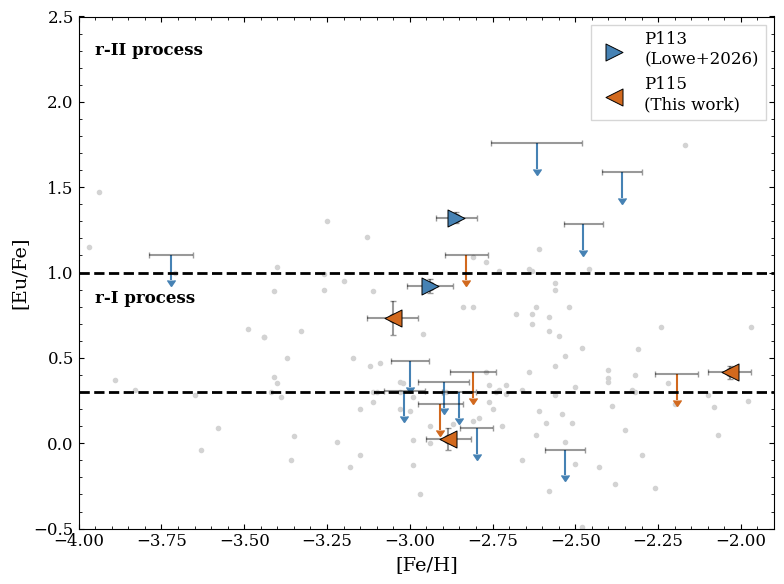

In [6]:
plt.figure(figsize=(8, 6))

# Plotting the detections and literature stars
plt.scatter(euII_lit_abund['feh'], euII_lit_abund['abund'], c="lightgrey", marker='.', zorder=1)
plt.scatter(p113_detect_df['feh'], p113_detect_df['eufe'], color='steelblue', label='P113\n(Lowe+2026)', 
            marker='>', s=150, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(p113_detect_df['feh'], p113_detect_df['eufe'], xerr=p113_detect_df['feh_err'],
             yerr=p113_detect_df['eufe_err'], fmt='o', color='black', zorder=9, alpha=0.4)
plt.scatter(p115_detect_df['feh'], p115_detect_df['eufe'], color='chocolate', label='P115\n(This work)', 
            marker='<', s=150, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(p115_detect_df['feh'], p115_detect_df['eufe'], xerr=p115_detect_df['feh_err'],
             yerr=p115_detect_df['eufe_err'], fmt='o', color='black', zorder=9, alpha=0.4)



# Plotting those with upper-limits in [Eu/Fe] 
ul_ysize = 0.15
ul_xsize = 0.15

plt.errorbar(p113_nondetect_df['feh'], p113_nondetect_df['eufe_ul'], yerr=ul_ysize, uplims=True, fmt='none', capsize=0, zorder=1, color='steelblue')
plt.errorbar(p113_nondetect_df['feh'], p113_nondetect_df['eufe_ul'], xerr=p113_nondetect_df['feh_err'], color='black', zorder=9, alpha=0.4, fmt='none')

plt.errorbar(p115_nondetect_df['feh'], p115_nondetect_df['eufe_ul'], yerr=ul_ysize, uplims=True, fmt='none', capsize=0, zorder=1, color='chocolate')
plt.errorbar(p115_nondetect_df['feh'], p115_nondetect_df['eufe_ul'], xerr=p115_nondetect_df['feh_err'], color='black', zorder=9, alpha=0.4, fmt='none')



# Plotting the lines
plt.hlines(y=0.3, xmin=-4, xmax=-1.0, color='black', linestyle='--', linewidth=2)
plt.hlines(y=1, xmin=-4, xmax=-1.0, color='black', linestyle='--', linewidth=2)
plt.text(-3.95, 0.85, 'r-I process', fontsize=12, color='black', ha='left', va='center', weight='bold')
plt.text(-3.95, 2.3, 'r-II process', fontsize=12, color='black', ha='left', va='center', weight='bold')


plt.xlim(-4, -1.9)
plt.ylim(-0.5, 2.5)

plt.legend(fancybox=False)
plt.xlabel('[Fe/H]')
plt.ylabel('[Eu/Fe]')
plt.tight_layout()

# plt.savefig("/data/misfit/benlowe/xshooter/p115/results/star_abunds/r_process.pdf", dpi=300, transparent=False, facecolor="white")
# plt.savefig("/data/misfit/benlowe/xshooter/p115/results/star_abunds/r_process.png", dpi=300, transparent=False, facecolor="white")

In [7]:
display(p115_df)

# Making table for paper
rprocess_tab = p115_df

dict_list = []
for star in rprocess_tab.iterrows():
    
    detection = star[1]['ul']
    
    # If detection, then report [Eu/Fe] and [Ba/Eu] values with errors. 
    if detection == 'Y':
        eufe_val = f"${star[1]['eufe']:.2f} \pm {star[1]['eufe_err']:.2f}$"
        baeu_val = f"${star[1]['baeu']:.2f} \pm {star[1]['baeu_err']:.2f}$"
        
        r_dict = {'Star': star[1]['star_id'], '\XFe{Eu}': eufe_val, '\XY{Ba}{Eu}': baeu_val}
        dict_list.append(r_dict)
        
    # If no detection in Eu (but detection in Ba), then report upper-limit in [Eu/Fe] and lower-limit in [Ba/Eu]
    else:
        eufe_val = f"$<{star[1]['eufe_ul']:.2f}$"
        baeu_val = f"$>{star[1]['baeu']:.2f}$"
        
        r_dict = {'Star': star[1]['star_id'], '\XFe{Eu}': eufe_val, '\XY{Ba}{Eu}': baeu_val}
        dict_list.append(r_dict)
    
    
#     _val = f"${star[1]['alpha']:.2f} \pm {star[1]['alpha_err']:.2f}$"
#     feh_val = f"${star[1]['feh']:.2f} \pm {star[1]['feh_err']:.2f}$"

#     alpha_dict = {'Star': star[1]['star_id'], '[Fe/H]': feh_val, '[Alpha/Fe]': alpha_val}
#     dict_list.append(alpha_dict)
    
rprocess_final_tab = pd.DataFrame(dict_list)
rprocess_final_tab.sort_values(by='Star', inplace=True)

print(rprocess_final_tab.to_latex(index=False))

,star_id,eufe,eufe_err,bafe,bafe_err,baeu,baeu_err,feh,feh_err,ul,eufe_ul
0,ra_0103-7050_s236,0.024363,0.063663,-0.792673,0.043409,-0.817036,0.077054,-2.883631,0.067304,Y,NaN
1,ra_0752-5047_s47,0.734373,0.098497,-0.558267,0.052058,-1.292641,0.111408,-3.051738,0.077258,Y,NaN
2,ra_1639-2632_s419,0.414560,0.036467,0.059664,0.060362,-0.354896,0.070523,-2.034058,0.063943,Y,NaN
3,ra_1648-2642_s91,0.416812,NaN,-0.688079,0.054762,-1.104891,NaN,-2.808558,0.069077,N,0.416812
4,ra_1659-2154_s261,0.402928,NaN,-1.135344,0.055309,-1.538272,NaN,-2.194068,0.064467,N,0.402928
5,ra_1659-2154_s347,1.103898,NaN,-0.871386,0.061925,-1.975284,NaN,-2.829687,0.065224,N,1.103898
6,ra_1752-4300_s155,0.227420,NaN,-1.410038,0.036432,-1.637458,NaN,-2.907340,0.067832,N,0.227420


\begin{tabular}{lll}
\toprule
Star & \XFe{Eu} & \XY{Ba}{Eu} \\
\midrule
ra_0103-7050_s236 & $0.02 \pm 0.06$ & $-0.82 \pm 0.08$ \\
ra_0752-5047_s47 & $0.73 \pm 0.10$ & $-1.29 \pm 0.11$ \\
ra_1639-2632_s419 & $0.41 \pm 0.04$ & $-0.35 \pm 0.07$ \\
ra_1648-2642_s91 & $<0.42$ & $>-1.10$ \\
ra_1659-2154_s261 & $<0.40$ & $>-1.54$ \\
ra_1659-2154_s347 & $<1.10$ & $>-1.98$ \\
ra_1752-4300_s155 & $<0.23$ & $>-1.64$ \\
\bottomrule
\end{tabular}



In [8]:
p113_list = []
p115_list = []
all_list = []

for entry in sr_abunds_df.iterrows():
    if entry[1]['detection'] == 'Y':
        star_id = entry[1]['star_id']
        bafe_entry = ba_abunds_df[ba_abunds_df['star_id'] == star_id]
        p = entry[1]['p#']
        if bafe_entry['detection'].values[0] == 'Y':
            sr_vals = entry[1]['bestfit_abund_xfe']
            sr_errs = entry[1]['bestfit_abund_comberr_xfe']
            ba_vals = ba_abunds_df[ba_abunds_df['star_id'] == star_id]['bestfit_abund_xfe'].values[0]
            ba_xh_vals = ba_abunds_df[ba_abunds_df['star_id'] == star_id]['bestfit_abund_xh'].values[0]
            ba_errs = ba_abunds_df[ba_abunds_df['star_id'] == star_id]['bestfit_abund_comberr_xfe'].values[0]
            ba_xh_errs = ba_abunds_df[ba_abunds_df['star_id'] == star_id]['bestfit_abund_comberr_xh'].values[0]
            feh_vals = entry[1]['feh']
            feh_errs = entry[1]['feh_err']
            
            srba_vals = sr_vals - ba_vals
            srba_errs = np.sqrt(sr_errs**2 + ba_errs**2)
            
            eufe_entry = eu_abunds_df[eu_abunds_df['star_id'] == star_id]
            if bafe_entry['detection'].values[0] == 'Y':
                eu_vals = eu_abunds_df[eu_abunds_df['star_id'] == star_id]['bestfit_abund_xfe'].values[0]
                eu_errs = eu_abunds_df[eu_abunds_df['star_id'] == star_id]['bestfit_abund_comberr_xfe'].values[0]
                baeu_vals = ba_vals - eu_vals
                baeu_errs = np.sqrt(sr_errs**2 + eu_errs**2)
                
                print(star_id)
                print(baeu_vals, baeu_errs)
            
            all_dict = {'star_id': star_id, 'detection': 'Y', 'srfe': sr_vals, 'bafe': ba_vals, 'srfe_err': sr_errs,
                                'bafe_err': ba_errs, 'srba': srba_vals, 'srba_err': srba_errs, 'feh': feh_vals, 'feh_err': feh_errs,
                                'bah': ba_xh_vals, 'bah_err': ba_xh_errs}
            all_list.append(all_dict)
            
            if p == 'p113':
                p113_dict = {'star_id': star_id, 'detection': 'Y',  'srfe': sr_vals, 'bafe': ba_vals, 'srfe_err': sr_errs,
                                'bafe_err': ba_errs, 'srba': srba_vals, 'srba_err': srba_errs, 'feh': feh_vals, 'feh_err': feh_errs,
                                'bah': ba_xh_vals, 'bah_err': ba_xh_errs}
                p113_list.append(p113_dict)
            elif p == 'p115':
                p115_dict = {'star_id': star_id, 'detection': 'Y',  'srfe': sr_vals, 'bafe': ba_vals, 'srfe_err': sr_errs,
                                'bafe_err': ba_errs, 'srba': srba_vals, 'srba_err': srba_errs, 'feh': feh_vals, 'feh_err': feh_errs,
                                'bah': ba_xh_vals, 'bah_err': ba_xh_errs}
                p115_list.append(p115_dict)
                
        elif bafe_entry['detection'].values[0] == 'N':
            sr_vals = entry[1]['bestfit_abund_xfe']
            sr_errs = entry[1]['bestfit_abund_comberr_xfe']
            ba_vals = ba_abunds_df[ba_abunds_df['star_id'] == star_id]['upper_limit_xfe'].values[0]
            ba_xh_vals = ba_abunds_df[ba_abunds_df['star_id'] == star_id]['upper_limit_xh'].values[0]
            ba_errs = np.nan
            ba_xh_errs = np.nan
            feh_vals = entry[1]['feh']
            feh_errs = entry[1]['feh_err']
            
            srba_vals = sr_vals - ba_vals
            srba_errs = np.nan
            
            eufe_entry = eu_abunds_df[eu_abunds_df['star_id'] == star_id]
            
            all_dict = {'star_id': star_id, 'detection': 'N', 'srfe': sr_vals, 'bafe': ba_vals, 'srfe_err': sr_errs,
                                'bafe_err': ba_errs, 'srba': srba_vals, 'srba_err': srba_errs, 'feh': feh_vals, 'feh_err': feh_errs,
                                'bah': ba_xh_vals, 'bah_err': ba_xh_errs}
            all_list.append(all_dict)
            
            if p == 'p113':
                p113_dict = {'star_id': star_id, 'detection': 'N', 'srfe': sr_vals, 'bafe': ba_vals, 'srfe_err': sr_errs,
                                'bafe_err': ba_errs, 'srba': srba_vals, 'srba_err': srba_errs, 'feh': feh_vals, 'feh_err': feh_errs,
                                'bah': ba_xh_vals, 'bah_err': ba_xh_errs}
                p113_list.append(p113_dict)
            elif p == 'p115':
                p115_dict = {'star_id': star_id, 'detection': 'N', 'srfe': sr_vals, 'bafe': ba_vals, 'srfe_err': sr_errs,
                                'bafe_err': ba_errs, 'srba': srba_vals, 'srba_err': srba_errs, 'feh': feh_vals, 'feh_err': feh_errs,
                                'bah': ba_xh_vals, 'bah_err': ba_xh_errs}
                p115_list.append(p115_dict)

                
p113_df_srba = pd.DataFrame(p113_list)
p115_df_srba = pd.DataFrame(p115_list)
all_df_srba = pd.DataFrame(all_list)

# Separating the non-detections from the detections
p113_detect_df_srba = p113_df_srba[p113_df_srba['detection'] == 'Y']
p115_detect_df_srba = p115_df_srba[p115_df_srba['detection'] == 'Y']

p113_nondetect_df_srba = p113_df_srba[p113_df_srba['detection'] == 'N']
p115_nondetect_df_srba = p115_df_srba[p115_df_srba['detection'] == 'N']


# Doing this for literature stars
srfe_lit_abund = srII_lit_abund['abund'].to_numpy()
bafe_lit_abund = baII_lit_abund['abund'].to_numpy()
bah_lit_abund = baII_lit_abund['abund_xh'].to_numpy()
srba_lit_abund = srfe_lit_abund - bafe_lit_abund

ra_0103-7050_s163
-0.9613192987092622 0.1113933869806802
ra_0834-5220_s316
2.3130415607279753 0.07615082674251411
ra_1604-2712_s24
2.912133610370418 0.8739424325485757
ra_1648-0653_s38
-1.6060358780583242 1.5057469366824092
ra_1656-1433_s143
-0.4904084019053243 0.04800493658272009
ra_1658-2454_s22
2.2299796700447434 0.10845616703326573
ra_1659-2154_s114
-1.7817399209652376 0.058322658802958546
ra_1709-2130_s102
-1.5342206645138665 1.2136129810353575
ra_1752-4300_s214
-0.5661414056436436 0.5765477919423332
ra_1752-4300_s269
1.940583183925319 1.7795155009240404
ra_1752-4300_s6
-0.9790399256330431 0.15101981049018537
ra_1853-3255_s45
-0.184052607230616 0.08236417102096437
ra_0103-7050_s236
-0.8170363958446728 0.11290767490795164
ra_0752-5047_s47
-1.292640634270219 0.11962677399890727
ra_1639-2632_s419
-0.354896416659341 0.05590814278646869
ra_1648-2642_s91
-0.7072006678334112 0.1137576643580832
ra_1659-2154_s261
-1.3831526543539867 0.10146226215087714
ra_1659-2154_s347
2.5014384367190035 

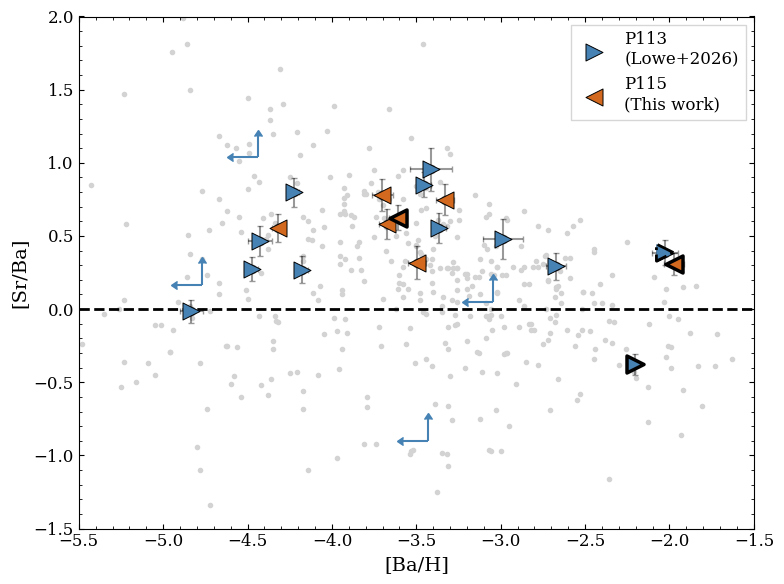

In [24]:
plt.figure(figsize=(8, 6))

# Plotting the detections and literature stars
plt.scatter(bah_lit_abund, srba_lit_abund, c="lightgrey", marker='.', zorder=1)
plt.scatter(p113_detect_df_srba['bah'], p113_detect_df_srba['srba'], color='steelblue', label='P113\n(Lowe+2026)', 
            marker='>', s=150, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(p113_detect_df_srba['bah'], p113_detect_df_srba['srba'], xerr=p113_detect_df_srba['bah_err'],
             yerr=p113_detect_df_srba['srba_err'], fmt='o', color='black', zorder=9, alpha=0.4)
plt.scatter(p115_detect_df_srba['bah'], p115_detect_df_srba['srba'], color='chocolate', label='P115\n(This work)', 
            marker='<', s=150, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(p115_detect_df_srba['bah'], p115_detect_df_srba['srba'], xerr=p115_detect_df_srba['bah_err'],
             yerr=p115_detect_df_srba['srba_err'], fmt='o', color='black', zorder=9, alpha=0.4)

# Marking the stars on the scatter plot that are r-process enhanced
# P115 --> r-I stars: ra_0752-5047_s47 and ra_1639-2632_s419
ra0752_s47 = p115_detect_df_srba[p115_detect_df_srba['star_id'] == 'ra_0752-5047_s47']
plt.scatter(ra0752_s47['bah'], ra0752_s47['srba'], color='chocolate', 
            marker='<', s=150, edgecolor='black', zorder=10, linewidths=2.5)

ra1639_s419 = p115_detect_df_srba[p115_detect_df_srba['star_id'] == 'ra_1639-2632_s419']
plt.scatter(ra1639_s419['bah'], ra1639_s419['srba'], color='chocolate',
            marker='<', s=150, edgecolor='black', zorder=10, linewidths=2.5)

# P113 --> r-I star: ra_1853-3255_s45
# P113 --> r-II star: ra_1656-1433_s143
ra1853_s45 = p113_detect_df_srba[p113_detect_df_srba['star_id'] == 'ra_1853-3255_s45']
plt.scatter(ra1853_s45['bah'], ra1853_s45['srba'], color='steelblue', 
            marker='>', s=150, edgecolor='black', zorder=10, linewidths=2.5)

ra1656_s143 = p113_detect_df_srba[p113_detect_df_srba['star_id'] == 'ra_1656-1433_s143']
plt.scatter(ra1656_s143['bah'], ra1656_s143['srba'], color='steelblue',
            marker='>', s=150, edgecolor='black', zorder=10, linewidths=2.0, linestyles='-.')

# Plotting those with upper-limits in [Ba/H] and lower-limits in [Sr/Ba]: plot left-facing arrow for [Ba/H] upper-limit, and up-facing arrow for [Sr/Ba] lower-limit
ul_ysize = 0.15
ul_xsize = 0.15

plt.errorbar(p113_nondetect_df_srba['bah'], p113_nondetect_df_srba['srba'], xerr=ul_xsize, yerr=ul_ysize,
            xuplims=True, lolims=True, fmt='none', capsize=0, zorder=1, color='steelblue')
plt.errorbar(p115_nondetect_df_srba['bah'], p115_nondetect_df_srba['srba'], xerr=ul_xsize, yerr=ul_ysize,
            xuplims=True, lolims=True, fmt='none', capsize=0, zorder=1, color='chocolate')


plt.axhline(y=0, color='black', linestyle='--', linewidth=2, zorder=2)
plt.xlim(-5.5, -1.5)
plt.ylim(-1.5, 2.0)

plt.legend(fancybox=False)
plt.xlabel('[Ba/H]')
plt.ylabel('[Sr/Ba]')
plt.tight_layout()

plt.savefig("/data/misfit/benlowe/xshooter/p115/results/star_abunds/srba_plot_v2.pdf", dpi=300, transparent=False, facecolor="white")
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/star_abunds/srba_plot_v2.png", dpi=300, transparent=False, facecolor="white")

In [26]:
p115_df_srba

,star_id,detection,srfe,bafe,srfe_err,bafe_err,srba,srba_err,feh,feh_err,bah,bah_err
0,ra_0103-7050_s236,Y,-0.210141,-0.792673,0.093248,0.043409,0.582532,0.102857,-2.883631,0.067304,-3.676304,0.043409
1,ra_0752-5047_s47,Y,0.067052,-0.558267,0.067889,0.052058,0.625319,0.085551,-3.051738,0.077258,-3.610005,0.052058
2,ra_1639-2632_s419,Y,0.367435,0.059664,0.042378,0.060362,0.307771,0.073753,-2.034058,0.063943,-1.974394,0.060362
3,ra_1648-2642_s91,Y,-0.370331,-0.688079,0.097770,0.054762,0.317748,0.112062,-2.808558,0.069077,-3.496637,0.054762
4,ra_1659-2154_s261,Y,-0.387258,-1.135344,0.090235,0.055309,0.748086,0.105836,-2.194068,0.064467,-3.329412,0.055309
5,ra_1659-2154_s347,Y,-0.089189,-0.871386,0.090909,0.061925,0.782197,0.109996,-2.829687,0.065224,-3.701072,0.061925
6,ra_1752-4300_s155,Y,-0.856135,-1.410038,0.088836,0.036432,0.553903,0.096016,-2.907340,0.067832,-4.317378,0.036432


In [25]:
# Making table for paper
srba_tab = p115_df_srba[['star_id', 'detection', 'bah', 'bah_err', 'srba', 'srba_err']]

dict_list = []
for star in srba_tab.iterrows():
    
    detect = star[1]['detection']
    
    if detect == 'Y':
        srba_val = f"${star[1]['srba']:.2f} \pm {star[1]['srba_err']:.2f}$"
        bah_val = f"${star[1]['bah']:.2f} \pm {star[1]['bah_err']:.2f}$"
    else:
        srba_val = f"$>{star[1]['srba']:.2f}$"
        bah_val = f"$<{star[1]['bah']:.2f}$"

    srba_dict = {'Star': star[1]['star_id'], '[Ba/H]': bah_val, '[Sr/Ba]': srba_val}
    dict_list.append(srba_dict)
    
srba_final_tab = pd.DataFrame(dict_list)
srba_final_tab.sort_values(by='Star', inplace=True)

print(srba_final_tab.to_latex(index=False))




\begin{tabular}{lll}
\toprule
Star & [Ba/H] & [Sr/Ba] \\
\midrule
ra_0103-7050_s236 & $-3.68 \pm 0.04$ & $0.58 \pm 0.10$ \\
ra_0752-5047_s47 & $-3.61 \pm 0.05$ & $0.63 \pm 0.09$ \\
ra_1639-2632_s419 & $-1.97 \pm 0.06$ & $0.31 \pm 0.07$ \\
ra_1648-2642_s91 & $-3.50 \pm 0.05$ & $0.32 \pm 0.11$ \\
ra_1659-2154_s261 & $-3.33 \pm 0.06$ & $0.75 \pm 0.11$ \\
ra_1659-2154_s347 & $-3.70 \pm 0.06$ & $0.78 \pm 0.11$ \\
ra_1752-4300_s155 & $-4.32 \pm 0.04$ & $0.55 \pm 0.10$ \\
\bottomrule
\end{tabular}



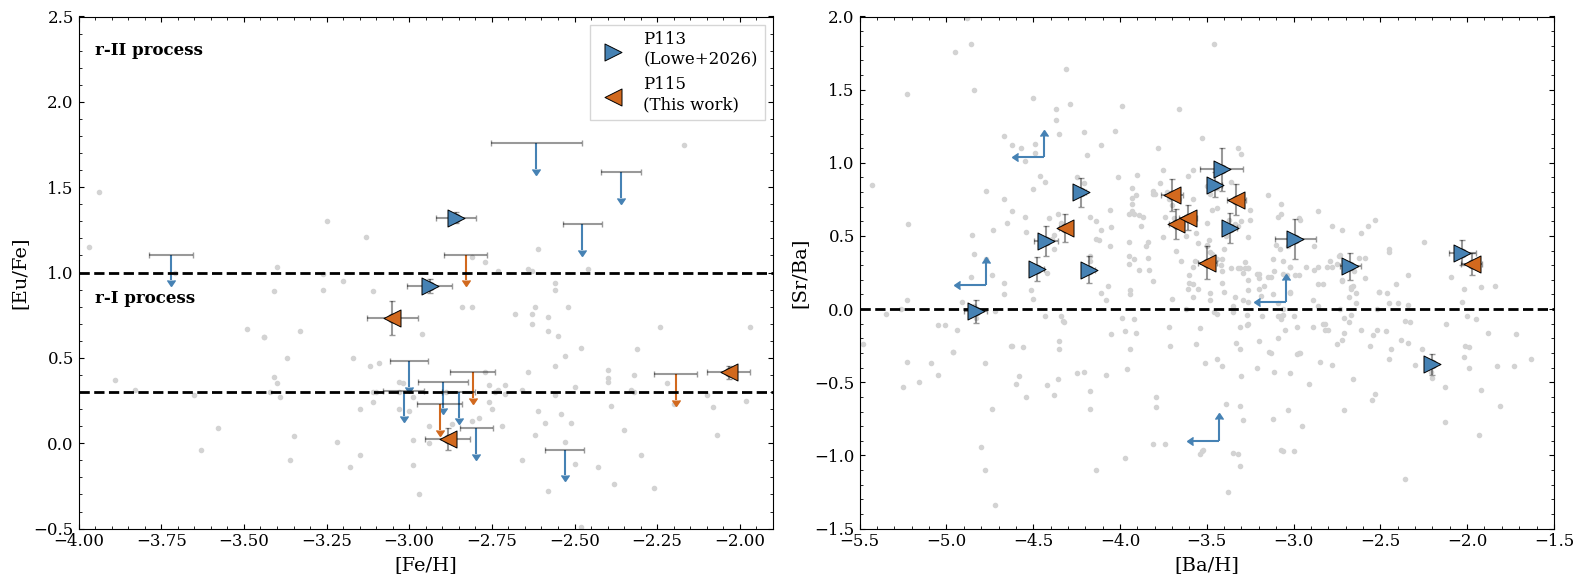

In [31]:
# Creating a subplot with [Fe/H] vs [Eu/Fe] on the left and [Ba/H] vs [Sr/Ba] on the right
fig, axs = plt.subplots(1, 2, figsize=(16, 6), tight_layout=True)


# ---LEFT PANEL: [Fe/H] vs [Eu/Fe]--- #
ax = axs[0]

# Plotting the detections and literature stars
ax.scatter(euII_lit_abund['feh'], euII_lit_abund['abund'], c="lightgrey", marker='.', zorder=1)
ax.scatter(p113_detect_df['feh'], p113_detect_df['eufe'], color='steelblue', label='P113\n(Lowe+2026)', 
            marker='>', s=150, edgecolor='black', zorder=10, linewidths=0.7)
ax.errorbar(p113_detect_df['feh'], p113_detect_df['eufe'], xerr=p113_detect_df['feh_err'],
             yerr=p113_detect_df['eufe_err'], fmt='o', color='black', zorder=9, alpha=0.4)
ax.scatter(p115_detect_df['feh'], p115_detect_df['eufe'], color='chocolate', label='P115\n(This work)', 
            marker='<', s=150, edgecolor='black', zorder=10, linewidths=0.7)
ax.errorbar(p115_detect_df['feh'], p115_detect_df['eufe'], xerr=p115_detect_df['feh_err'],
             yerr=p115_detect_df['eufe_err'], fmt='o', color='black', zorder=9, alpha=0.4)\

# Plotting those with upper-limits in [Eu/Fe] 
ul_ysize = 0.15
ul_xsize = 0.15

ax.errorbar(p113_nondetect_df['feh'], p113_nondetect_df['eufe_ul'], yerr=ul_ysize, uplims=True, fmt='none', capsize=0, zorder=1, color='steelblue')
ax.errorbar(p113_nondetect_df['feh'], p113_nondetect_df['eufe_ul'], xerr=p113_nondetect_df['feh_err'], color='black', zorder=9, alpha=0.4, fmt='none')
ax.errorbar(p115_nondetect_df['feh'], p115_nondetect_df['eufe_ul'], yerr=ul_ysize, uplims=True, fmt='none', capsize=0, zorder=1, color='chocolate')
ax.errorbar(p115_nondetect_df['feh'], p115_nondetect_df['eufe_ul'], xerr=p115_nondetect_df['feh_err'], color='black', zorder=9, alpha=0.4, fmt='none')

# Plotting the lines
ax.hlines(y=0.3, xmin=-4, xmax=-1.0, color='black', linestyle='--', linewidth=2)
ax.hlines(y=1, xmin=-4, xmax=-1.0, color='black', linestyle='--', linewidth=2)
ax.text(-3.95, 0.85, 'r-I process', fontsize=12, color='black', ha='left', va='center', weight='bold')
ax.text(-3.95, 2.3, 'r-II process', fontsize=12, color='black', ha='left', va='center', weight='bold')


ax.set_xlim(-4, -1.9)
ax.set_ylim(-0.5, 2.5)

ax.legend(fancybox=False)
ax.set_xlabel('[Fe/H]')
ax.set_ylabel('[Eu/Fe]')


# ---RIGHT PANEL: [Ba/H] vs [Sr/Ba]--- #
ax = axs[1]

# Plotting the detections and literature stars
ax.scatter(bah_lit_abund, srba_lit_abund, c="lightgrey", marker='.', zorder=1)
ax.scatter(p113_detect_df_srba['bah'], p113_detect_df_srba['srba'], color='steelblue', label='P113\n(Lowe+2026)', 
            marker='>', s=150, edgecolor='black', zorder=10, linewidths=0.7)
ax.errorbar(p113_detect_df_srba['bah'], p113_detect_df_srba['srba'], xerr=p113_detect_df_srba['bah_err'],
             yerr=p113_detect_df_srba['srba_err'], fmt='o', color='black', zorder=9, alpha=0.4)
ax.scatter(p115_detect_df_srba['bah'], p115_detect_df_srba['srba'], color='chocolate', label='P115\n(This work)', 
            marker='<', s=150, edgecolor='black', zorder=10, linewidths=0.7)
ax.errorbar(p115_detect_df_srba['bah'], p115_detect_df_srba['srba'], xerr=p115_detect_df_srba['bah_err'],
             yerr=p115_detect_df_srba['srba_err'], fmt='o', color='black', zorder=9, alpha=0.4)



# Plotting those with upper-limits in [Ba/H] and lower-limits in [Sr/Ba]: plot left-facing arrow for [Ba/H] upper-limit, and up-facing arrow for [Sr/Ba] lower-limit
ul_ysize = 0.15
ul_xsize = 0.15

ax.errorbar(p113_nondetect_df_srba['bah'], p113_nondetect_df_srba['srba'], xerr=ul_xsize, yerr=ul_ysize,
            xuplims=True, lolims=True, fmt='none', capsize=0, zorder=1, color='steelblue')
ax.errorbar(p115_nondetect_df_srba['bah'], p115_nondetect_df_srba['srba'], xerr=ul_xsize, yerr=ul_ysize,
            xuplims=True, lolims=True, fmt='none', capsize=0, zorder=1, color='chocolate')


ax.axhline(y=0, color='black', linestyle='--', linewidth=2, zorder=2)
ax.set_xlim(-5.5, -1.5)
ax.set_ylim(-1.5, 2.0)

ax.set_xlabel('[Ba/H]')
ax.set_ylabel('[Sr/Ba]')

plt.savefig("/data/misfit/benlowe/xshooter/p115/results/star_abunds/r_process_srba_combined.pdf", dpi=300, transparent=False, facecolor="white")
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/star_abunds/r_process_srba_combined.png", dpi=300, transparent=False, facecolor="white")

### Alpha-enhanced stars

In [4]:
# Doing this for our stars
p113_list = []
p115_list = []
all_list = []

for entry in mg_abunds_df.iterrows():
    star_id = entry[1]['star_id']
    p = entry[1]['p#']
    si_I_entry = si_abunds_df[si_abunds_df['star_id'] == star_id]
    ca_II_entry = ca_abunds_df[ca_abunds_df['star_id'] == star_id]
    ti_II_entry = ti_abunds_df[ti_abunds_df['star_id'] == star_id]
    
    mg_vals = entry[1]['bestfit_abund_xfe']
    mg_errs = entry[1]['bestfit_abund_comberr_xfe']
    si_vals = si_I_entry['bestfit_abund_xfe'].values[0]
    si_errs = si_I_entry['bestfit_abund_comberr_xfe'].values[0]
    ca_vals = ca_II_entry['bestfit_abund_xfe'].values[0]
    ca_errs = ca_II_entry['bestfit_abund_comberr_xfe'].values[0]
    ti_vals = ti_II_entry['bestfit_abund_xfe'].values[0]
    ti_errs = ti_II_entry['bestfit_abund_comberr_xfe'].values[0]
    
    
    # alpha_vals = np.average([mg_vals, si_vals, ca_vals, ti_vals])
    # alpha_errs = 1/4 * np.sqrt(mg_errs**2 + si_errs**2 + ca_errs**2 + ti_errs**2)
    
    # Calculating weighted average
    alpha_arr = np.array([mg_vals, si_vals, ca_vals, ti_vals])
    alpha_weights = 1 / np.array([mg_errs, si_errs, ca_errs, ti_errs])**2
    
    # Weighted mean
    alpha_vals = np.sum(alpha_weights * alpha_arr) / np.sum(alpha_weights)

    # Uncertainty of weighted mean
    alpha_errs = np.sqrt(1 / np.sum(alpha_weights))
    
    feh_vals = entry[1]['feh']
    feh_errs = entry[1]['feh_err']
    
    all_dict = {'star_id': star_id, 'alpha': alpha_vals, 'alpha_err': alpha_errs,
                'feh': feh_vals, 'feh_err': feh_errs, 'mg': mg_vals, 'mg_err': mg_errs,
                'si': si_vals, 'si_err': si_errs, 'ca': ca_vals, 'ca_err': ca_errs, 'ti': ti_vals, 'ti_err': ti_errs}
    all_list.append(all_dict)
    
    if p == 'p113':
        p113_dict = {'star_id': star_id, 'alpha': alpha_vals, 'alpha_err': alpha_errs,
                        'feh': feh_vals, 'feh_err': feh_errs}
        p113_list.append(p113_dict)
    elif p == 'p115':
        p115_dict = {'star_id': star_id, 'alpha': alpha_vals, 'alpha_err': alpha_errs,
                        'feh': feh_vals, 'feh_err': feh_errs}
        p115_list.append(p115_dict)
    
    print(f"{star_id} ([α/Fe] = {alpha_vals:.2f} ± {alpha_errs:.2f})")
    # if eu_II_entry['detection'].values[0] == 'Y':
    #     ba_vals = entry[1]['bestfit_abund_xfe']
    #     eu_vals = eu_II_abunds[eu_II_abunds['star_id'] == star_id]['bestfit_abund_xfe'].values[0]
        
    #     baeu_vals = ba_vals - eu_vals
    #     if eu_vals >= 0.3 and eu_vals <= 1.0 and baeu_vals < 0:
    #         print(f"{star_id} ([Eu/Fe] = {eu_vals:.2f} and [Ba/Eu] = {baeu_vals:.2f})")

p113_df = pd.DataFrame(p113_list)
p115_df = pd.DataFrame(p115_list)
all_df = pd.DataFrame(all_list)

# Doing this for literature stars
mgI_list_stars = mgI_lit_abund['star_id'].to_numpy()
siI_list_stars = siI_lit_abund['star_id'].to_numpy()
caI_list_stars = caI_lit_abund['star_id'].to_numpy()
tiII_list_stars = tiII_lit_abund['star_id'].to_numpy()
alpha_lit_abund = []
for star in mgI_list_stars:
    if star in siI_list_stars and star in caI_list_stars and star in tiII_list_stars:
        mg_val = mgI_lit_abund[mgI_lit_abund['star_id'] == star]['abund'].values[0]
        si_val = siI_lit_abund[siI_lit_abund['star_id'] == star]['abund'].values[0]
        ca_val = caI_lit_abund[caI_lit_abund['star_id'] == star]['abund'].values[0]
        ti_val = tiII_lit_abund[tiII_lit_abund['star_id'] == star]['abund'].values[0]
        feh_val = mgI_lit_abund[mgI_lit_abund['star_id'] == star]['feh'].values[0]
        
        alpha_val = np.average([mg_val, si_val, ca_val, ti_val])
        alpha_lit_abund.append({'star_id': star, 'alpha': alpha_val, 'feh': feh_val})
        
alpha_lit_abund_df = pd.DataFrame(alpha_lit_abund)

ra_0103-7050_s163 ([α/Fe] = 0.23 ± 0.02)
ra_0834-5220_s316 ([α/Fe] = 0.36 ± 0.02)
ra_1604-2712_s24 ([α/Fe] = 0.32 ± 0.02)
ra_1604-2712_s292 ([α/Fe] = 0.24 ± 0.02)
ra_1624-2150_s278 ([α/Fe] = 0.26 ± 0.01)
ra_1633-2814_s130 ([α/Fe] = 0.32 ± 0.02)
ra_1633-2814_s284 ([α/Fe] = 0.56 ± 0.02)
ra_1648-0653_s38 ([α/Fe] = 0.28 ± 0.02)
ra_1656-1433_s143 ([α/Fe] = 0.39 ± 0.02)
ra_1658-2454_s22 ([α/Fe] = 0.38 ± 0.02)
ra_1659-2154_s114 ([α/Fe] = 0.36 ± 0.02)
ra_1709-2130_s102 ([α/Fe] = 0.37 ± 0.02)
ra_1752-4300_s214 ([α/Fe] = 0.42 ± 0.02)
ra_1752-4300_s269 ([α/Fe] = 0.15 ± 0.02)
ra_1752-4300_s6 ([α/Fe] = 0.36 ± 0.02)
ra_1853-3255_s45 ([α/Fe] = 0.28 ± 0.02)
ra_0103-7050_s236 ([α/Fe] = 0.35 ± 0.02)
ra_0752-5047_s47 ([α/Fe] = 0.54 ± 0.02)
ra_1639-2632_s419 ([α/Fe] = 0.18 ± 0.02)
ra_1648-2642_s91 ([α/Fe] = 0.40 ± 0.02)
ra_1659-2154_s261 ([α/Fe] = 0.17 ± 0.02)
ra_1659-2154_s347 ([α/Fe] = 0.43 ± 0.02)
ra_1752-4300_s155 ([α/Fe] = 0.31 ± 0.02)


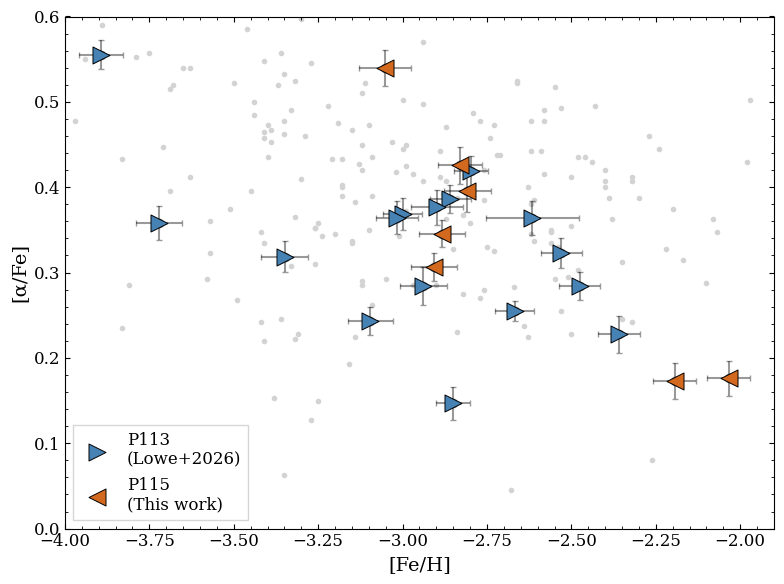

In [7]:
plt.figure(figsize=(8, 6))

plt.scatter(alpha_lit_abund_df['feh'], alpha_lit_abund_df['alpha'], color='lightgrey', marker='.', zorder=1)
plt.scatter(p113_df['feh'], p113_df['alpha'], color='steelblue', label='P113\n(Lowe+2026)', 
            marker='>', s=150, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(p113_df['feh'], p113_df['alpha'], xerr=p113_df['feh_err'],
             yerr=p113_df['alpha_err'], fmt='o', color='black', zorder=9, alpha=0.4)
plt.scatter(p115_df['feh'], p115_df['alpha'], color='chocolate', label='P115\n(This work)', 
            marker='<', s=150, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(p115_df['feh'], p115_df['alpha'], xerr=p115_df['feh_err'],
             yerr=p115_df['alpha_err'], fmt='o', color='black', zorder=9, alpha=0.4)

plt.xlabel('[Fe/H]')
plt.ylabel('[α/Fe]')
plt.legend(fancybox=False, loc='lower left')

plt.xlim(-4, -1.9)
plt.ylim(0, 0.6)

plt.tight_layout()
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/star_abunds/alpha_enhanced_v2.pdf", dpi=300, transparent=False, facecolor="white")
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/star_abunds/alpha_enhanced_v2.png", dpi=300, transparent=False, facecolor="white")

In [5]:
# Making table for paper
alpha_tab = p115_df[['star_id', 'feh', 'feh_err', 'alpha', 'alpha_err']]

dict_list = []
for star in alpha_tab.iterrows():
    
    alpha_val = f"${star[1]['alpha']:.2f} \pm {star[1]['alpha_err']:.2f}$"
    feh_val = f"${star[1]['feh']:.2f} \pm {star[1]['feh_err']:.2f}$"

    alpha_dict = {'Star': star[1]['star_id'], '[Fe/H]': feh_val, '[Alpha/Fe]': alpha_val}
    dict_list.append(alpha_dict)
    
alpha_final_tab = pd.DataFrame(dict_list)
alpha_final_tab.sort_values(by='Star', inplace=True)

print(alpha_final_tab.to_latex(index=False))


\begin{tabular}{lll}
\toprule
Star & [Fe/H] & [Alpha/Fe] \\
\midrule
ra_0103-7050_s236 & $-2.88 \pm 0.07$ & $0.35 \pm 0.02$ \\
ra_0752-5047_s47 & $-3.05 \pm 0.08$ & $0.54 \pm 0.02$ \\
ra_1639-2632_s419 & $-2.03 \pm 0.06$ & $0.18 \pm 0.02$ \\
ra_1648-2642_s91 & $-2.81 \pm 0.07$ & $0.40 \pm 0.02$ \\
ra_1659-2154_s261 & $-2.19 \pm 0.06$ & $0.17 \pm 0.02$ \\
ra_1659-2154_s347 & $-2.83 \pm 0.07$ & $0.43 \pm 0.02$ \\
ra_1752-4300_s155 & $-2.91 \pm 0.07$ & $0.31 \pm 0.02$ \\
\bottomrule
\end{tabular}



In [17]:
len(alpha_rich_lit_df)

28

In [12]:
alpha_rich_lit_df = alpha_lit_abund_df[alpha_lit_abund_df['alpha'] > 0.5]
alpha_rich_lit_df

# For each star, find its elemental abundances
for entry in all_df.iterrows():
    star_id = entry[1]['star_id']
    alpha_vals = entry[1]['alpha']
    print(f"{star_id} - [α/Fe]: {alpha_vals:.2f}")
    
    # Extracting elements
    caI_entry = caI_lit_abund[caI_lit_abund['star_id'] == star_id]
    mgI_entry = mgI_lit_abund[mgI_lit_abund['star_id'] == star_id]
    siI_entry = siI_lit_abund[siI_lit_abund['star_id'] == star_id]
    baII_entry = baII_lit_abund[baII_lit_abund['star_id'] == star_id]
    srII_entry = srII_lit_abund[srII_lit_abund['star_id'] == star_id]
    euII_entry = euII_lit_abund[euII_lit_abund['star_id'] == star_id]
    alI_entry = alI_lit_abund[alI_lit_abund['star_id'] == star_id]
    mnI_entry = mnI_lit_abund[mnI_lit_abund['star_id'] == star_id]
    crI_entry = crI_lit_abund[crI_lit_abund['star_id'] == star_id]
    tiII_entry = tiII_lit_abund[tiII_lit_abund['star_id'] == star_id]
    scII_entry = scII_lit_abund[scII_lit_abund['star_id'] == star_id]
    coI_entry = coI_lit_abund[coI_lit_abund['star_id'] == star_id]
    niI_entry = niI_lit_abund[niI_lit_abund['star_id'] == star_id]
    naI_entry = naI_lit_abund[naI_lit_abund['star_id'] == star_id]
    cI_entry = cI_lit_abund[cI_lit_abund['star_id'] == star_id]
    
    print(caI_entry)
    print(mgI_entry)
    print(siI_entry)
    print(baII_entry)
    print(srII_entry)
    print(euII_entry)
    print(alI_entry)
    print(mnI_entry)
    print(crI_entry)
    print(tiII_entry)
    print(scII_entry)
    print(coI_entry)
    print(niI_entry)
    print(naI_entry)
    print(cI_entry)
    
    if not caI_entry.empty:
        mean_ca = caI_lit_abund['abund'].mean()
        std_ca = caI_lit_abund['abund'].std()
        ca_val = caI_entry['abund'].values[0]
        
        # Computing the difference between the abundance value and the mean literature abundance.
        obs_lit_diff = abs(ca_val - mean_ca)
        
        # Seeing if the abundance value is within 2 sigma of the literature value
        lower_bound = ca_val - 2 * std_ca
        upper_bound = ca_val + 2 * std_ca
        print(f"{star_id} - [Ca/Fe]: {ca_val:.2f}")
        if lower_bound <= mean_ca <= upper_bound:
            print(f"{star_id} - [Ca/Fe] is consistent with literature values.")
        else:
            print(f"{star_id} - [Ca/Fe] is NOT consistent with literature values.")
    if not mgI_entry.empty:
        mean_mg = mgI_lit_abund['abund'].mean()
        std_mg = mgI_lit_abund['abund'].std()
        mg_val = mgI_entry['abund'].values[0]
        
        obs_lit_diff = abs(mg_val - mean_mg)
        
        lower_bound = mg_val - 2 * std_mg
        upper_bound = mg_val + 2 * std_mg
        print(f"{star_id} - [Mg/Fe]: {mg_val:.2f}")
        if lower_bound <= mean_mg <= upper_bound:
            print(f"{star_id} - [Mg/Fe] is consistent with literature values.")
        else:
            print(f"{star_id} - [Mg/Fe] is NOT consistent with literature values.")
    if not siI_entry.empty:
        mean_si = siI_lit_abund['abund'].mean()
        std_si = siI_lit_abund['abund'].std()
        si_val = siI_entry['abund'].values[0]
        
        obs_lit_diff = abs(si_val - mean_si)
        
        lower_bound = si_val - 2 * std_si
        upper_bound = si_val + 2 * std_si
        print(f"{star_id} - [Si/Fe]: {si_val:.2f}")
        if lower_bound <= mean_si <= upper_bound:
            print(f"{star_id} - [Si/Fe] is consistent with literature values.")
        else:
            print(f"{star_id} - [Si/Fe] is NOT consistent with literature values.")
    if not baII_entry.empty:
        mean_ba = baII_lit_abund['abund_xfe'].mean()
        std_ba = baII_lit_abund['abund_xfe'].std()
        ba_val = baII_entry['abund_xfe'].values[0]
        
        obs_lit_diff = abs(ba_val - mean_ba)
        
        lower_bound = ba_val - 2 * std_ba
        upper_bound = ba_val + 2 * std_ba
        print(f"{star_id} - [Ba/Fe]: {ba_val:.2f}")
        if lower_bound <= mean_ba <= upper_bound:
            print(f"{star_id} - [Ba/Fe] is consistent with literature values.")
        else:
            print(f"{star_id} - [Ba/Fe] is NOT consistent with literature values.")
    if not srII_entry.empty:
        mean_sr = srII_lit_abund['abund_xfe'].mean()
        std_sr = srII_lit_abund['abund_xfe'].std()
        sr_val = srII_entry['abund_xfe'].values[0]
        
        obs_lit_diff = abs(sr_val - mean_sr)
        
        lower_bound = sr_val - 2 * std_sr
        upper_bound = sr_val + 2 * std_sr
        print(f"{star_id} - [Sr/Fe]: {sr_val:.2f}")
        if lower_bound <= mean_sr <= upper_bound:
            print(f"{star_id} - [Sr/Fe] is consistent with literature values.")
        else:
            print(f"{star_id} - [Sr/Fe] is NOT consistent with literature values.")
    if not euII_entry.empty:
        mean_eu = euII_lit_abund['abund_xfe'].mean()
        std_eu = euII_lit_abund['abund_xfe'].std()
        eu_val = euII_entry['abund_xfe'].values[0]
        
        obs_lit_diff = abs(eu_val - mean_eu)
        
        lower_bound = eu_val - 2 * std_eu
        upper_bound = eu_val + 2 * std_eu
        print(f"{star_id} - [Eu/Fe]: {eu_val:.2f}")
        if lower_bound <= mean_eu <= upper_bound:
            print(f"{star_id} - [Eu/Fe] is consistent with literature values.")
        else:
            print(f"{star_id} - [Eu/Fe] is NOT consistent with literature values.")
    if not alI_entry.empty:
        mean_al = alI_lit_abund['abund'].mean()
        std_al = alI_lit_abund['abund'].std()
        al_val = alI_entry['abund'].values[0]
        
        obs_lit_diff = abs(al_val - mean_al)
        
        lower_bound = al_val - 2 * std_al
        upper_bound = al_val + 2 * std_al
        print(f"{star_id} - [Al/Fe]: {al_val:.2f}")
        if lower_bound <= mean_al <= upper_bound:
            print(f"{star_id} - [Al/Fe] is consistent with literature values.")
        else:
            print(f"{star_id} - [Al/Fe] is NOT consistent with literature values.")
    if not mnI_entry.empty:
        mean_mn = mnI_lit_abund['abund'].mean()
        std_mn = mnI_lit_abund['abund'].std()
        mn_val = mnI_entry['abund'].values[0]
        
        obs_lit_diff = abs(mn_val - mean_mn)
        
        lower_bound = mn_val - 2 * std_mn
        upper_bound = mn_val + 2 * std_mn
        print(f"{star_id} - [Mn/Fe]: {mn_val:.2f}")
        if lower_bound <= mean_mn <= upper_bound:
            print(f"{star_id} - [Mn/Fe] is consistent with literature values.")
        else:
            print(f"{star_id} - [Mn/Fe] is NOT consistent with literature values.")
    if not crI_entry.empty:
        mean_cr = crI_lit_abund['abund'].mean()
        std_cr = crI_lit_abund['abund'].std()
        cr_val = crI_entry['abund'].values[0]
        
        obs_lit_diff = abs(cr_val - mean_cr)
        
        lower_bound = cr_val - 2 * std_cr
        upper_bound = cr_val + 2 * std_cr
        print(f"{star_id} - [Cr/Fe]: {cr_val:.2f}")
        if lower_bound <= mean_cr <= upper_bound:
            print(f"{star_id} - [Cr/Fe] is consistent with literature values.")
        else:
            print(f"{star_id} - [Cr/Fe] is NOT consistent with literature values.")
    if not tiII_entry.empty:
        mean_ti = tiII_lit_abund['abund'].mean()
        std_ti = tiII_lit_abund['abund'].std()
        ti_val = tiII_entry['abund'].values[0]
        
        obs_lit_diff = abs(ti_val - mean_ti)
        
        lower_bound = ti_val - 2 * std_ti
        upper_bound = ti_val + 2 * std_ti
        print(f"{star_id} - [Ti/Fe]: {ti_val:.2f}")
        if lower_bound <= mean_ti <= upper_bound:
            print(f"{star_id} - [Ti/Fe] is consistent with literature values.")
        else:
            print(f"{star_id} - [Ti/Fe] is NOT consistent with literature values.")
    if not scII_entry.empty:
        mean_sc = scII_lit_abund['abund'].mean()
        std_sc = scII_lit_abund['abund'].std()
        sc_val = scII_entry['abund'].values[0]
        
        obs_lit_diff = abs(sc_val - mean_sc)
        
        lower_bound = sc_val - 2 * std_sc
        upper_bound = sc_val + 2 * std_sc
        print(f"{star_id} - [Sc/Fe]: {sc_val:.2f}")
        if lower_bound <= mean_sc <= upper_bound:
            print(f"{star_id} - [Sc/Fe] is consistent with literature values.")
        else:
            print(f"{star_id} - [Sc/Fe] is NOT consistent with literature values.")
    if not coI_entry.empty:
        mean_co = coI_lit_abund['abund'].mean()
        std_co = coI_lit_abund['abund'].std()
        co_val = coI_entry['abund'].values[0]
        
        obs_lit_diff = abs(co_val - mean_co)
        
        lower_bound = co_val - 2 * std_co
        upper_bound = co_val + 2 * std_co
        print(f"{star_id} - [Co/Fe]: {co_val:.2f}")
        if lower_bound <= mean_co <= upper_bound:
            print(f"{star_id} - [Co/Fe] is consistent with literature values.")
        else:
            print(f"{star_id} - [Co/Fe] is NOT consistent with literature values.")
    if not niI_entry.empty:
        mean_ni = niI_lit_abund['abund'].mean()
        std_ni = niI_lit_abund['abund'].std()
        ni_val = niI_entry['abund'].values[0]
        
        obs_lit_diff = abs(ni_val - mean_ni)
        
        lower_bound = ni_val - 2 * std_ni
        upper_bound = ni_val + 2 * std_ni
        print(f"{star_id} - [Ni/Fe]: {ni_val:.2f}")
        if lower_bound <= mean_ni <= upper_bound:
            print(f"{star_id} - [Ni/Fe] is consistent with literature values.")
        else:
            print(f"{star_id} - [Ni/Fe] is NOT consistent with literature values.")
    if not naI_entry.empty:
        mean_na = naI_lit_abund['abund'].mean()
        std_na = naI_lit_abund['abund'].std()
        na_val = naI_entry['abund'].values[0]
        
        obs_lit_diff = abs(na_val - mean_na)
        
        lower_bound = na_val - 2 * std_na
        upper_bound = na_val + 2 * std_na
        print(f"{star_id} - [Na/Fe]: {na_val:.2f}")
        if lower_bound <= mean_na <= upper_bound:
            print(f"{star_id} - [Na/Fe] is consistent with literature values.")
        else:
            print(f"{star_id} - [Na/Fe] is NOT consistent with literature values.")
    if not cI_entry.empty:
        mean_c = cI_lit_abund['abund'].mean()
        std_c = cI_lit_abund['abund'].std()
        c_val = cI_entry['abund'].values[0]
        
        obs_lit_diff = abs(c_val - mean_c)
        
        lower_bound = c_val - 2 * std_c
        upper_bound = c_val + 2 * std_c
        print(f"{star_id} - [C/Fe]: {c_val:.2f}")
        if lower_bound <= mean_c <= upper_bound:
            print(f"{star_id} - [C/Fe] is consistent with literature values.")
        else:
            print(f"{star_id} - [C/Fe] is NOT consistent with literature values.")
    print()

    

ra_0103-7050_s163 - [α/Fe]: 0.23
Empty DataFrame
Columns: [star_id, feh, abund, abund_err]
Index: []
Empty DataFrame
Columns: [star_id, feh, abund, abund_err]
Index: []
Empty DataFrame
Columns: [star_id, feh, abund, abund_err]
Index: []
Empty DataFrame
Columns: [star_id, feh, abund, abund_err, abund_xh]
Index: []
Empty DataFrame
Columns: [star_id, feh, abund, abund_err]
Index: []
Empty DataFrame
Columns: [star_id, feh, abund, abund_err]
Index: []
Empty DataFrame
Columns: [star_id, feh, abund, abund_err]
Index: []
Empty DataFrame
Columns: [star_id, feh, abund, abund_err]
Index: []
Empty DataFrame
Columns: [star_id, feh, abund, abund_err]
Index: []
Empty DataFrame
Columns: [star_id, feh, abund, abund_err]
Index: []
Empty DataFrame
Columns: [star_id, feh, abund, abund_err]
Index: []
Empty DataFrame
Columns: [star_id, feh, abund, abund_err]
Index: []
Empty DataFrame
Columns: [star_id, feh, abund, abund_err]
Index: []
Empty DataFrame
Columns: [star_id, feh, abund, abund_err]
Index: []
Empty

Checking to see if there's any weird alpha-enhanced stars

In [15]:
alpha_rich_lit_df = alpha_lit_abund_df[alpha_lit_abund_df['alpha'] > 0.5]
alpha_rich_lit_df

# For each star, find its elemental abundances
for entry in alpha_rich_lit_df.iterrows():
    star_id = entry[1]['star_id']
    alpha_vals = entry[1]['alpha']
    print(f"{star_id} - [α/Fe]: {alpha_vals:.2f}")
    
    # Extracting elements
    caI_entry = caI_lit_abund[caI_lit_abund['star_id'] == star_id]
    mgI_entry = mgI_lit_abund[mgI_lit_abund['star_id'] == star_id]
    siI_entry = siI_lit_abund[siI_lit_abund['star_id'] == star_id]
    baII_entry = baII_lit_abund[baII_lit_abund['star_id'] == star_id]
    srII_entry = srII_lit_abund[srII_lit_abund['star_id'] == star_id]
    euII_entry = euII_lit_abund[euII_lit_abund['star_id'] == star_id]
    alI_entry = alI_lit_abund[alI_lit_abund['star_id'] == star_id]
    mnI_entry = mnI_lit_abund[mnI_lit_abund['star_id'] == star_id]
    crI_entry = crI_lit_abund[crI_lit_abund['star_id'] == star_id]
    tiII_entry = tiII_lit_abund[tiII_lit_abund['star_id'] == star_id]
    scII_entry = scII_lit_abund[scII_lit_abund['star_id'] == star_id]
    coI_entry = coI_lit_abund[coI_lit_abund['star_id'] == star_id]
    niI_entry = niI_lit_abund[niI_lit_abund['star_id'] == star_id]
    naI_entry = naI_lit_abund[naI_lit_abund['star_id'] == star_id]
    cI_entry = cI_lit_abund[cI_lit_abund['star_id'] == star_id]
    
    # print(caI_entry)
    # print(mgI_entry)
    # print(siI_entry)
    # print(baII_entry)
    # print(srII_entry)
    # print(euII_entry)
    # print(alI_entry)
    # print(mnI_entry)
    # print(crI_entry)
    # print(tiII_entry)
    # print(scII_entry)
    # print(coI_entry)
    # print(niI_entry)
    # print(naI_entry)
    # print(cI_entry)
    
    if not caI_entry.empty:
        mean_ca = caI_lit_abund['abund'].mean()
        std_ca = caI_lit_abund['abund'].std()
        ca_val = caI_entry['abund'].values[0]
        
        # Computing the difference between the abundance value and the mean literature abundance.
        obs_lit_diff = abs(ca_val - mean_ca)
        
        # Seeing if the abundance value is within 2 sigma of the literature value
        lower_bound = ca_val - 2 * std_ca
        upper_bound = ca_val + 2 * std_ca
        print(f"{star_id} - [Ca/Fe]: {ca_val:.2f}")
        if lower_bound <= mean_ca <= upper_bound:
            print(f"{star_id} - [Ca/Fe] is consistent with literature values.")
        else:
            print(f"{star_id} - [Ca/Fe] is NOT consistent with literature values.")
    if not mgI_entry.empty:
        mean_mg = mgI_lit_abund['abund'].mean()
        std_mg = mgI_lit_abund['abund'].std()
        mg_val = mgI_entry['abund'].values[0]
        
        obs_lit_diff = abs(mg_val - mean_mg)
        
        lower_bound = mg_val - 2 * std_mg
        upper_bound = mg_val + 2 * std_mg
        print(f"{star_id} - [Mg/Fe]: {mg_val:.2f}")
        if lower_bound <= mean_mg <= upper_bound:
            print(f"{star_id} - [Mg/Fe] is consistent with literature values.")
        else:
            print(f"{star_id} - [Mg/Fe] is NOT consistent with literature values.")
    if not siI_entry.empty:
        mean_si = siI_lit_abund['abund'].mean()
        std_si = siI_lit_abund['abund'].std()
        si_val = siI_entry['abund'].values[0]
        
        obs_lit_diff = abs(si_val - mean_si)
        
        lower_bound = si_val - 2 * std_si
        upper_bound = si_val + 2 * std_si
        print(f"{star_id} - [Si/Fe]: {si_val:.2f}")
        if lower_bound <= mean_si <= upper_bound:
            print(f"{star_id} - [Si/Fe] is consistent with literature values.")
        else:
            print(f"{star_id} - [Si/Fe] is NOT consistent with literature values.")
    if not baII_entry.empty:
        mean_ba = baII_lit_abund['abund'].mean()
        std_ba = baII_lit_abund['abund'].std()
        ba_val = baII_entry['abund'].values[0]
        
        obs_lit_diff = abs(ba_val - mean_ba)
        
        lower_bound = ba_val - 2 * std_ba
        upper_bound = ba_val + 2 * std_ba
        print(f"{star_id} - [Ba/Fe]: {ba_val:.2f}")
        if lower_bound <= mean_ba <= upper_bound:
            print(f"{star_id} - [Ba/Fe] is consistent with literature values.")
        else:
            print(f"{star_id} - [Ba/Fe] is NOT consistent with literature values.")
    if not srII_entry.empty:
        mean_sr = srII_lit_abund['abund'].mean()
        std_sr = srII_lit_abund['abund'].std()
        sr_val = srII_entry['abund'].values[0]
        
        obs_lit_diff = abs(sr_val - mean_sr)
        
        lower_bound = sr_val - 2 * std_sr
        upper_bound = sr_val + 2 * std_sr
        print(f"{star_id} - [Sr/Fe]: {sr_val:.2f}")
        if lower_bound <= mean_sr <= upper_bound:
            print(f"{star_id} - [Sr/Fe] is consistent with literature values.")
        else:
            print(f"{star_id} - [Sr/Fe] is NOT consistent with literature values.")
    if not euII_entry.empty:
        mean_eu = euII_lit_abund['abund'].mean()
        std_eu = euII_lit_abund['abund'].std()
        eu_val = euII_entry['abund'].values[0]
        
        obs_lit_diff = abs(eu_val - mean_eu)
        
        lower_bound = eu_val - 2 * std_eu
        upper_bound = eu_val + 2 * std_eu
        print(f"{star_id} - [Eu/Fe]: {eu_val:.2f}")
        if lower_bound <= mean_eu <= upper_bound:
            print(f"{star_id} - [Eu/Fe] is consistent with literature values.")
        else:
            print(f"{star_id} - [Eu/Fe] is NOT consistent with literature values.")
    if not alI_entry.empty:
        mean_al = alI_lit_abund['abund'].mean()
        std_al = alI_lit_abund['abund'].std()
        al_val = alI_entry['abund'].values[0]
        
        obs_lit_diff = abs(al_val - mean_al)
        
        lower_bound = al_val - 2 * std_al
        upper_bound = al_val + 2 * std_al
        print(f"{star_id} - [Al/Fe]: {al_val:.2f}")
        if lower_bound <= mean_al <= upper_bound:
            print(f"{star_id} - [Al/Fe] is consistent with literature values.")
        else:
            print(f"{star_id} - [Al/Fe] is NOT consistent with literature values.")
    if not mnI_entry.empty:
        mean_mn = mnI_lit_abund['abund'].mean()
        std_mn = mnI_lit_abund['abund'].std()
        mn_val = mnI_entry['abund'].values[0]
        
        obs_lit_diff = abs(mn_val - mean_mn)
        
        lower_bound = mn_val - 2 * std_mn
        upper_bound = mn_val + 2 * std_mn
        print(f"{star_id} - [Mn/Fe]: {mn_val:.2f}")
        if lower_bound <= mean_mn <= upper_bound:
            print(f"{star_id} - [Mn/Fe] is consistent with literature values.")
        else:
            print(f"{star_id} - [Mn/Fe] is NOT consistent with literature values.")
    if not crI_entry.empty:
        mean_cr = crI_lit_abund['abund'].mean()
        std_cr = crI_lit_abund['abund'].std()
        cr_val = crI_entry['abund'].values[0]
        
        obs_lit_diff = abs(cr_val - mean_cr)
        
        lower_bound = cr_val - 2 * std_cr
        upper_bound = cr_val + 2 * std_cr
        print(f"{star_id} - [Cr/Fe]: {cr_val:.2f}")
        if lower_bound <= mean_cr <= upper_bound:
            print(f"{star_id} - [Cr/Fe] is consistent with literature values.")
        else:
            print(f"{star_id} - [Cr/Fe] is NOT consistent with literature values.")
    if not tiII_entry.empty:
        mean_ti = tiII_lit_abund['abund'].mean()
        std_ti = tiII_lit_abund['abund'].std()
        ti_val = tiII_entry['abund'].values[0]
        
        obs_lit_diff = abs(ti_val - mean_ti)
        
        lower_bound = ti_val - 2 * std_ti
        upper_bound = ti_val + 2 * std_ti
        print(f"{star_id} - [Ti/Fe]: {ti_val:.2f}")
        if lower_bound <= mean_ti <= upper_bound:
            print(f"{star_id} - [Ti/Fe] is consistent with literature values.")
        else:
            print(f"{star_id} - [Ti/Fe] is NOT consistent with literature values.")
    if not scII_entry.empty:
        mean_sc = scII_lit_abund['abund'].mean()
        std_sc = scII_lit_abund['abund'].std()
        sc_val = scII_entry['abund'].values[0]
        
        obs_lit_diff = abs(sc_val - mean_sc)
        
        lower_bound = sc_val - 2 * std_sc
        upper_bound = sc_val + 2 * std_sc
        print(f"{star_id} - [Sc/Fe]: {sc_val:.2f}")
        if lower_bound <= mean_sc <= upper_bound:
            print(f"{star_id} - [Sc/Fe] is consistent with literature values.")
        else:
            print(f"{star_id} - [Sc/Fe] is NOT consistent with literature values.")
    if not coI_entry.empty:
        mean_co = coI_lit_abund['abund'].mean()
        std_co = coI_lit_abund['abund'].std()
        co_val = coI_entry['abund'].values[0]
        
        obs_lit_diff = abs(co_val - mean_co)
        
        lower_bound = co_val - 2 * std_co
        upper_bound = co_val + 2 * std_co
        print(f"{star_id} - [Co/Fe]: {co_val:.2f}")
        if lower_bound <= mean_co <= upper_bound:
            print(f"{star_id} - [Co/Fe] is consistent with literature values.")
        else:
            print(f"{star_id} - [Co/Fe] is NOT consistent with literature values.")
    if not niI_entry.empty:
        mean_ni = niI_lit_abund['abund'].mean()
        std_ni = niI_lit_abund['abund'].std()
        ni_val = niI_entry['abund'].values[0]
        
        obs_lit_diff = abs(ni_val - mean_ni)
        
        lower_bound = ni_val - 2 * std_ni
        upper_bound = ni_val + 2 * std_ni
        print(f"{star_id} - [Ni/Fe]: {ni_val:.2f}")
        if lower_bound <= mean_ni <= upper_bound:
            print(f"{star_id} - [Ni/Fe] is consistent with literature values.")
        else:
            print(f"{star_id} - [Ni/Fe] is NOT consistent with literature values.")
    if not naI_entry.empty:
        mean_na = naI_lit_abund['abund'].mean()
        std_na = naI_lit_abund['abund'].std()
        na_val = naI_entry['abund'].values[0]
        
        obs_lit_diff = abs(na_val - mean_na)
        
        lower_bound = na_val - 2 * std_na
        upper_bound = na_val + 2 * std_na
        print(f"{star_id} - [Na/Fe]: {na_val:.2f}")
        if lower_bound <= mean_na <= upper_bound:
            print(f"{star_id} - [Na/Fe] is consistent with literature values.")
        else:
            print(f"{star_id} - [Na/Fe] is NOT consistent with literature values.")
    if not cI_entry.empty:
        mean_c = cI_lit_abund['abund'].mean()
        std_c = cI_lit_abund['abund'].std()
        c_val = cI_entry['abund'].values[0]
        
        obs_lit_diff = abs(c_val - mean_c)
        
        lower_bound = c_val - 2 * std_c
        upper_bound = c_val + 2 * std_c
        print(f"{star_id} - [C/Fe]: {c_val:.2f}")
        if lower_bound <= mean_c <= upper_bound:
            print(f"{star_id} - [C/Fe] is consistent with literature values.")
        else:
            print(f"{star_id} - [C/Fe] is NOT consistent with literature values.")
    print()

    

SMSS J003327.36-491037.9 - [α/Fe]: 0.56
SMSS J003327.36-491037.9 - [Ca/Fe]: 0.44
SMSS J003327.36-491037.9 - [Ca/Fe] is consistent with literature values.
SMSS J003327.36-491037.9 - [Mg/Fe]: 0.56
SMSS J003327.36-491037.9 - [Mg/Fe] is consistent with literature values.
SMSS J003327.36-491037.9 - [Si/Fe]: 0.87
SMSS J003327.36-491037.9 - [Si/Fe] is consistent with literature values.
SMSS J003327.36-491037.9 - [Ba/Fe]: -1.06
SMSS J003327.36-491037.9 - [Ba/Fe] is consistent with literature values.
SMSS J003327.36-491037.9 - [Sr/Fe]: -1.58
SMSS J003327.36-491037.9 - [Sr/Fe] is consistent with literature values.
SMSS J003327.36-491037.9 - [Eu/Fe]: -0.10
SMSS J003327.36-491037.9 - [Eu/Fe] is consistent with literature values.
SMSS J003327.36-491037.9 - [Al/Fe]: -0.19
SMSS J003327.36-491037.9 - [Al/Fe] is consistent with literature values.
SMSS J003327.36-491037.9 - [Mn/Fe]: -0.25
SMSS J003327.36-491037.9 - [Mn/Fe] is consistent with literature values.
SMSS J003327.36-491037.9 - [Cr/Fe]: -0.48
S

### C-enhanced stars

In [ ]:
c_abunds_df

,star_id,teff,logg,vmic,vsini,feh,feh_err,el,detection,upper_limit_xfe,...,bestfit_abund_vmicerr_xfe,bestfit_abund_vmicerr_xh,Jp,Jtot,Jz,Jr,zmax,orbit,cfe_corr,p#
0,ra_0103-7050_s163,6298.806689,4.492229,1.253413,0,-2.359003,0.060794,C_I,Y,-0.40,...,0.007595,0.007595,1191.012215,1.198272e+03,88.491505,9.754294e+01,2.132239,pro_disk,0.00,p113
1,ra_0834-5220_s316,5959.304567,4.286104,1.246679,0,-2.616194,0.137417,C_I,Y,-0.36,...,0.005366,0.005366,938.289662,1.009217e+03,48.475280,3.684863e+02,1.824720,pro_disk,0.00,p113
2,ra_1604-2712_s24,5002.684528,1.891750,2.007753,0,-2.530153,0.060214,C_I,Y,-1.86,...,0.001863,0.001863,-508.586881,6.654891e+02,370.549358,2.165831e+02,5.618895,halo,0.12,p113
3,ra_1604-2712_s292,5783.249268,3.404600,1.544869,0,-3.095019,0.066494,C_I,Y,-0.05,...,0.023770,0.023770,910.872110,1.042933e+03,456.517828,2.227385e+02,7.025378,halo,0.00,p113
4,ra_1624-2150_s278,6381.865006,3.973617,1.490113,0,-2.667603,0.058084,C_I,N,0.55,...,0.030463,0.030463,849.634492,9.919699e+02,159.863856,4.863836e+02,4.521274,halo,0.00,p113
5,ra_1633-2814_s130,4997.869004,1.849800,2.037393,0,-3.349203,0.068693,C_I,Y,-0.65,...,0.002967,0.002967,70.811434,5.069482e+02,298.849114,4.033255e+02,3.683933,gse,0.03,p113
6,ra_1633-2814_s284,5261.142090,2.447800,1.806730,0,-3.893474,0.064712,C_I,Y,0.14,...,0.002550,0.002550,63.985259,6.933085e+02,421.780111,5.465199e+02,7.992632,gse,0.00,p113
7,ra_1648-0653_s38,6039.830368,3.646778,1.533073,0,-2.475968,0.059728,C_I,Y,-0.25,...,0.008355,0.008355,1295.837964,1.297820e+03,71.690885,4.189520e-01,1.470769,pro_disk,0.00,p113
8,ra_1656-1433_s143,4791.462397,1.406800,2.214264,0,-2.858919,0.060508,C_I,Y,-1.66,...,3.210786,3.210786,194.053140,5.428655e+02,499.728841,8.554198e+01,4.361530,halo,0.46,p113
9,ra_1658-2454_s22,4852.253676,2.164886,1.673293,0,-2.897767,0.076858,C_I,Y,-2.00,...,0.000538,0.000538,165.986919,3.408191e+02,222.753531,1.974508e+02,3.276006,halo,0.00,p113


In [10]:
caI_entry

,star_id,feh,abund,abund_err


In [8]:
# Doing this for our stars
p113_list = []
p115_list = []
all_list = []

for entry in c_abunds_df.iterrows():
    if entry[1]['detection'] == 'Y':
        star_id = entry[1]['star_id']
        p = entry[1]['p#']
            
        # Getting raw [C/Fe] value (don't need to apply corrections)
        if p == 'p113':
            cfe_vals = entry[1]['bestfit_abund_xfe'] - entry[1]['cfe_corr'] # Uncorrected [C/Fe] value
            cfe_corrs = entry[1]['cfe_corr'] # Corrections
            cfe_vals_corr = entry[1]['bestfit_abund_xfe'] # Corrected [C/Fe] value
        else:
            cfe_vals = entry[1]['bestfit_abund_xfe']
            cfe_corrs = entry[1]['cfe_corr'] # Corrections
            cfe_vals_corr = entry[1]['bestfit_abund_xfe'] + entry[1]['cfe_corr'] # Corrected [C/Fe] value
        
        cfe_errs = entry[1]['bestfit_abund_comberr_xfe']
        nfe_vals = n_abunds_df[n_abunds_df['star_id'] == star_id]['bestfit_abund_xfe'].values[0]
        nfe_errs = n_abunds_df[n_abunds_df['star_id'] == star_id]['bestfit_abund_comberr_xfe'].values[0]
        feh_vals = entry[1]['feh']
        feh_errs = entry[1]['feh_err']
        
        cn_vals = cfe_vals - nfe_vals
        cn_errs = np.sqrt(cfe_errs**2 + nfe_errs**2)
        
        if p == 'p113':
            p113_dict = {'star_id': star_id, 'detection': 'Y', 'cfe': cfe_vals, 'cfe_corrected': cfe_vals_corr, 'cfe_corrs': cfe_corrs, 'cfe_err': cfe_errs, 'feh': feh_vals, 'feh_err': feh_errs}
            p113_list.append(p113_dict)
        elif p == 'p115':
            p115_dict = {'star_id': star_id, 'detection': 'Y', 'cfe': cfe_vals, 'cfe_corrected': cfe_vals_corr, 'cfe_corrs': cfe_corrs, 'cfe_err': cfe_errs, 'feh': feh_vals, 'feh_err': feh_errs}
            p115_list.append(p115_dict)
        
        all_list.append({'star_id': star_id, 'detection': 'Y', 'cfe': cfe_vals, 'cfe_corrected': cfe_vals_corr, 'cfe_corrs': cfe_corrs, 'cfe_err': cfe_errs, 'feh': feh_vals, 'feh_err': feh_errs})
        
    if entry[1]['detection'] == 'N':
        
        # Getting raw [C/Fe] value (don't need to apply corrections)
        cfe_ul = entry[1]['upper_limit_xfe']

        
        cfe_errs = entry[1]['bestfit_abund_comberr_xfe']
        nfe_vals = n_abunds_df[n_abunds_df['star_id'] == star_id]['upper_limit_xfe'].values[0]
        nfe_errs = np.nan
        feh_vals = entry[1]['feh']
        feh_errs = entry[1]['feh_err']
        
        cn_vals = cfe_vals - nfe_vals
        cn_errs = np.nan
        
        if p == 'p113':
            p113_dict = {'star_id': star_id, 'detection': 'N', 'cfe_ul': cfe_ul, 'cfe_err': cfe_errs, 'feh': feh_vals, 'feh_err': feh_errs}
            p113_list.append(p113_dict)
        elif p == 'p115':
            p115_dict = {'star_id': star_id, 'detection': 'N', 'cfe_ul': cfe_ul, 'cfe_err': cfe_errs, 'feh': feh_vals, 'feh_err': feh_errs}
            p115_list.append(p115_dict)
        
        all_list.append({'star_id': star_id, 'detection': 'N', 'cfe_ul': cfe_ul, 'cfe_err': cfe_errs, 'feh': feh_vals, 'feh_err': feh_errs})

                
                
p113_df = pd.DataFrame(p113_list)
p115_df = pd.DataFrame(p115_list)
all_df = pd.DataFrame(all_list)

# Separating the non-detections from the detections
p113_detect_df = p113_df[p113_df['detection'] == 'Y']
p115_detect_df = p115_df[p115_df['detection'] == 'Y']

p113_nondetect_df = p113_df[p113_df['detection'] == 'N']
p115_nondetect_df = p115_df[p115_df['detection'] == 'N']

# Doing this for literature stars
# nfe_lit_abund = nI_lit_abund['abund'].to_numpy()
# cfe_lit_abund = cI_lit_abund['abund'].to_numpy()
# cn_lit_abund = cfe_lit_abund - nfe_lit_abund


In [96]:
entry

(22,
 star_id                      ra_1752-4300_s155
 teff                               4797.406576
 logg                                   1.41365
 vmic                                   2.21434
 vsini                                        0
 feh                                   -2.90734
 feh_err                               0.067832
 el                                         C_I
 detection                                    Y
 upper_limit_xfe                          -1.82
 upper_limit_xh                        -4.72734
 bestfit_abund_xfe                     -0.06312
 bestfit_abund_xh                      -2.97046
 bestfit_abund_comberr_xfe             0.080173
 bestfit_abund_comberr_xh              0.080173
 bestfit_abund_tefferr_xfe             0.216347
 bestfit_abund_tefferr_xh              0.216347
 bestfit_abund_loggerr_xfe              0.10509
 bestfit_abund_loggerr_xh               0.10509
 bestfit_abund_vmicerr_xfe             0.000261
 bestfit_abund_vmicerr_xh          

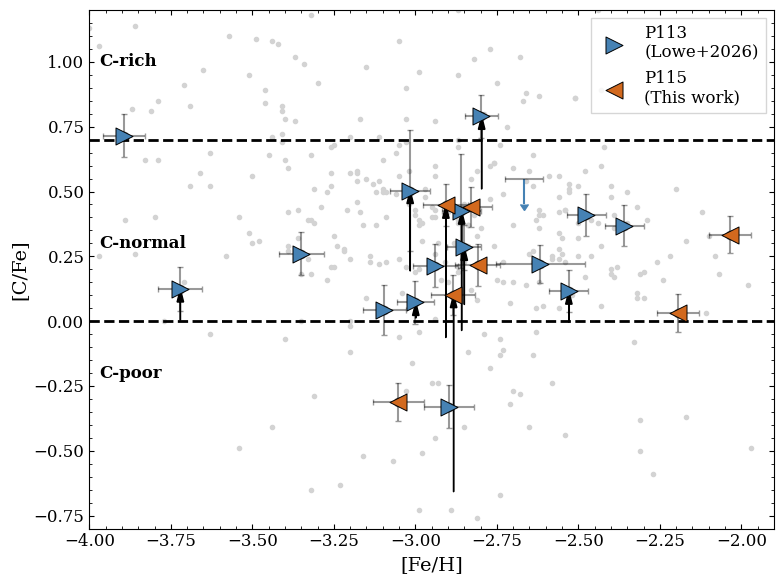

In [9]:
plt.figure(figsize=(8, 6))

# Plotting the data points
plt.scatter(p113_detect_df['feh'], p113_detect_df['cfe_corrected'], color='steelblue', label='P113\n(Lowe+2026)', 
            marker='>', s=150, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(p113_detect_df['feh'], p113_detect_df['cfe_corrected'], xerr=p113_detect_df['feh_err'],
             yerr=p113_detect_df['cfe_err'], fmt='o', color='black', zorder=9, alpha=0.4)
plt.scatter(p115_detect_df['feh'], p115_detect_df['cfe_corrected'], color='chocolate', label='P115\n(This work)', 
            marker='<', s=150, edgecolor='black', zorder=10, linewidths=0.7)
plt.errorbar(p115_detect_df['feh'], p115_detect_df['cfe_corrected'], xerr=p115_detect_df['feh_err'],
             yerr=p115_detect_df['cfe_err'], fmt='o', color='black', zorder=9, alpha=0.4)
plt.scatter(cI_lit_abund['feh'], cI_lit_abund['abund'], color='lightgrey', marker='.', zorder=1)
plt.axhline(y=0, color='black', linestyle='--', linewidth=2)
plt.axhline(y=0.7, color='black', linestyle='--', linewidth=2)


# Plotting the un-corrected data as arrows
for xi, yi1, yi2 in zip(p113_detect_df['feh'], p113_detect_df['cfe_corrected'], p113_detect_df['cfe']):
    dy = yi2 - yi1
    
    # If correction is too small, then won't plot
    if abs(dy) < 0.05:
        continue
    else:
        # Arrow position slightly off from marker, so applying 0.001 offset
        plt.arrow(xi+0.001, yi1 - abs(dy), 0, abs(dy), head_width=0.02, head_length=0.05, length_includes_head=True, color='black')


for xi, yi1, yi2 in zip(p115_detect_df['feh'], p115_detect_df['cfe_corrected'], p115_detect_df['cfe']):
    dy = yi2 - yi1
    
    # If correction is too small, then won't plot
    if abs(dy) < 0.05:
        continue
    else:
        # Arrow position slightly off from marker, so applying 0.001 offset
        plt.arrow(xi+0.001, yi1 - abs(dy), 0, abs(dy), head_width=0.02, head_length=0.05, length_includes_head=True, color='black')


# Plotting upperlimits
plt.errorbar(p113_nondetect_df['feh'], p113_nondetect_df['cfe_ul'], yerr=0.1, uplims=True, fmt='none', capsize=0, zorder=1, color='steelblue')
plt.errorbar(p113_nondetect_df['feh'], p113_nondetect_df['cfe_ul'], xerr=p113_nondetect_df['feh_err'], color='black', zorder=9, alpha=0.4)


plt.text(-3.97, -0.2, 'C-poor', fontsize=12, color='black', ha='left', va='center', weight='bold')
plt.text(-3.97, 0.3, 'C-normal', fontsize=12, color='black', ha='left', va='center', weight='bold')
plt.text(-3.97, 1.0, 'C-rich', fontsize=12, color='black', ha='left', va='center', weight='bold')

plt.xlabel('[Fe/H]')
plt.ylabel('[C/Fe]')
plt.xlim(-4, -1.9)
plt.ylim(-0.8, 1.2)
plt.legend(fancybox=False)
plt.tight_layout()

plt.savefig("/data/misfit/benlowe/xshooter/p115/results/star_abunds/c_enhanced.pdf", dpi=300, transparent=False, facecolor="white")
plt.savefig("/data/misfit/benlowe/xshooter/p115/results/star_abunds/c_enhanced.png", dpi=300, transparent=False, facecolor="white")

In [121]:
p113_nondetect_df['feh_err']

4   NaN
Name: feh_err, dtype: float64